<a href="https://colab.research.google.com/github/uniqueeee777/SML-stability-driven-energy/blob/main/SML02_%E2%80%94_Model_Development_%26_Temporal_CV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chronological Data Partitioning

In [1]:

# ============================================================
# NOTEBOOK 02 — CELL 01
# CHRONOLOGICAL TRAIN–VALIDATION–TEST PARTITIONING
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display
from google.colab import drive

# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

drive.mount("/content/drive")

ROOT = Path(
    "/content/drive/MyDrive/Stability_Driven_Energy"
)

METADATA_DIR = ROOT / "09_experiment_metadata"

assert ROOT.is_dir()
assert METADATA_DIR.is_dir()

# ------------------------------------------------------------
# 2. Locate prepared datasets
# ------------------------------------------------------------

def find_unique_file(root, filename):
    matches = list(root.rglob(filename))

    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected one file named {filename}; "
            f"found {len(matches)}: {matches}"
        )

    return matches[0]


SOURCE_A = find_unique_file(
    ROOT, "candidate_feature_set_A.csv"
)

SOURCE_B = find_unique_file(
    ROOT, "candidate_feature_set_B.csv"
)

assert SOURCE_A.parent == SOURCE_B.parent

OUTPUT_DIR = SOURCE_A.parent / "temporal_partitions"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PROTOCOL_PATH = (
    METADATA_DIR /
    "notebook01_preprocessing_strategy.json"
)

with open(PROTOCOL_PATH, "r", encoding="utf-8") as f:
    protocol = json.load(f)

FEATURE_A = protocol["feature_sets"]["A"]
FEATURE_B = protocol["feature_sets"]["B"]

TARGET = "Appliances"
TIME_COL = "date"

# ------------------------------------------------------------
# 3. Load and verify source integrity
# ------------------------------------------------------------

def sha256_file(file_path):
    digest = hashlib.sha256()

    with open(file_path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


assert sha256_file(SOURCE_A) == (
    protocol["source_data_checksums"]["candidate_A_sha256"]
)

assert sha256_file(SOURCE_B) == (
    protocol["source_data_checksums"]["candidate_B_sha256"]
)

data_A = pd.read_csv(
    SOURCE_A, parse_dates=[TIME_COL]
)

data_B = pd.read_csv(
    SOURCE_B, parse_dates=[TIME_COL]
)

assert data_A.shape == (19735, 27)
assert data_B.shape == (19735, 29)

assert data_A.columns.tolist() == (
    [TIME_COL] + FEATURE_A + [TARGET]
)

assert data_B.columns.tolist() == (
    [TIME_COL] + FEATURE_B + [TARGET]
)

pd.testing.assert_series_equal(
    data_A[TIME_COL],
    data_B[TIME_COL]
)

pd.testing.assert_series_equal(
    data_A[TARGET],
    data_B[TARGET]
)

assert data_A[TIME_COL].is_unique
assert data_A[TIME_COL].is_monotonic_increasing

assert (
    data_A[TIME_COL].diff().dropna()
    == pd.Timedelta(minutes=10)
).all()

assert data_A.notna().all().all()
assert data_B.notna().all().all()

print("=" * 70)
print("NOTEBOOK 02 — CHRONOLOGICAL PARTITIONING")
print("=" * 70)

print("Source integrity: PASS")
print("Dataset A:", data_A.shape)
print("Dataset B:", data_B.shape)

# ------------------------------------------------------------
# 4. Fixed chronological boundaries
# ------------------------------------------------------------

# Decision based on temporal coverage and evaluation
# requirements, NOT on test-set predictive performance.
#
# Training:   Jan 11 – Apr 02, 2016
# Validation: Apr 03 – Apr 30, 2016
# Testing:    May 01 – May 27, 2016

TRAIN_VAL_BOUNDARY = pd.Timestamp(
    "2016-04-03 00:00:00"
)

VAL_TEST_BOUNDARY = pd.Timestamp(
    "2016-05-01 00:00:00"
)

def chronological_partition(data):

    train = data.loc[
        data[TIME_COL] < TRAIN_VAL_BOUNDARY
    ].copy()

    validation = data.loc[
        (data[TIME_COL] >= TRAIN_VAL_BOUNDARY) &
        (data[TIME_COL] < VAL_TEST_BOUNDARY)
    ].copy()

    test = data.loc[
        data[TIME_COL] >= VAL_TEST_BOUNDARY
    ].copy()

    return {
        "train": train.reset_index(drop=True),
        "validation": validation.reset_index(drop=True),
        "test": test.reset_index(drop=True)
    }


split_A = chronological_partition(data_A)
split_B = chronological_partition(data_B)

# ------------------------------------------------------------
# 5. Verify chronological independence
# ------------------------------------------------------------

expected_counts = {
    "train": 11850,
    "validation": 4032,
    "test": 3853
}

for stage in expected_counts:

    assert len(split_A[stage]) == expected_counts[stage]
    assert len(split_B[stage]) == expected_counts[stage]

    pd.testing.assert_series_equal(
        split_A[stage][TIME_COL],
        split_B[stage][TIME_COL]
    )

    pd.testing.assert_series_equal(
        split_A[stage][TARGET],
        split_B[stage][TARGET]
    )

assert (
    split_A["train"][TIME_COL].max()
    < split_A["validation"][TIME_COL].min()
)

assert (
    split_A["validation"][TIME_COL].max()
    < split_A["test"][TIME_COL].min()
)

# Check that boundaries have no missing 10-minute interval
assert (
    split_A["validation"][TIME_COL].min()
    - split_A["train"][TIME_COL].max()
    == pd.Timedelta(minutes=10)
)

assert (
    split_A["test"][TIME_COL].min()
    - split_A["validation"][TIME_COL].max()
    == pd.Timedelta(minutes=10)
)

# Reconstruct original chronological dataset
reconstructed_A = pd.concat(
    [split_A[s] for s in expected_counts],
    ignore_index=True
)

reconstructed_B = pd.concat(
    [split_B[s] for s in expected_counts],
    ignore_index=True
)

pd.testing.assert_frame_equal(
    reconstructed_A,
    data_A.reset_index(drop=True)
)

pd.testing.assert_frame_equal(
    reconstructed_B,
    data_B.reset_index(drop=True)
)

# ------------------------------------------------------------
# 6. Create partition summary
# ------------------------------------------------------------

summary_records = []

for stage in ["train", "validation", "test"]:

    subset = split_A[stage]

    first_time = subset[TIME_COL].iloc[0]
    last_time = subset[TIME_COL].iloc[-1]

    duration_days = (
        (
            last_time - first_time
            + pd.Timedelta(minutes=10)
        ).total_seconds()
        / 86400
    )

    summary_records.append({
        "partition": stage,
        "n_observations": len(subset),
        "percentage": 100 * len(subset) / len(data_A),
        "duration_days": duration_days,
        "start": first_time,
        "end": last_time,
        "n_features_A": len(FEATURE_A),
        "n_features_B": len(FEATURE_B)
    })

split_summary = pd.DataFrame(
    summary_records
)

print("\nA. FINAL CHRONOLOGICAL PARTITION")

display(
    split_summary.round(4)
)

# ------------------------------------------------------------
# 7. Save six partitions
# ------------------------------------------------------------

saved_files = {}

for feature_name, partitions in [
    ("A", split_A),
    ("B", split_B)
]:

    for stage, subset in partitions.items():

        filename = f"{feature_name}_{stage}.csv"
        file_path = OUTPUT_DIR / filename

        subset.to_csv(
            file_path,
            index=False
        )

        saved_files[filename] = {
            "path": str(file_path),
            "rows": len(subset),
            "sha256": sha256_file(file_path)
        }

# ------------------------------------------------------------
# 8. Save locked split metadata
# ------------------------------------------------------------

split_metadata = {
    "project": (
        "Stability-Driven Evaluation of Machine "
        "Learning Models for Appliance Energy Estimation"
    ),

    "notebook": "02_Model_Development",
    "cell": "01_Chronological_Partitioning",

    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "split_method": "Chronological",
    "nominal_ratio": "60/20/20",

    "train_validation_boundary": (
        TRAIN_VAL_BOUNDARY.isoformat()
    ),

    "validation_test_boundary": (
        VAL_TEST_BOUNDARY.isoformat()
    ),

    "counts": expected_counts,

    "feature_sets": {
        "A": FEATURE_A,
        "B": FEATURE_B
    },

    "files": saved_files,

    "design_basis": (
        "Approximately 82 days for model development, "
        "28 complete days for fixed validation, and "
        "approximately 27 days for final testing."
    ),

    "methodological_disclosure": (
        "Full-series descriptive EDA preceded partitioning. "
        "No model fitting, predictive tuning or performance-"
        "based feature selection used the validation or "
        "test observations."
    ),

    "preprocessing_selection_complete": False,
    "hyperparameter_tuning_complete": False,
    "bootstrap_complete": False,
    "test_performance_evaluated": False
}

metadata_path = (
    METADATA_DIR /
    "notebook02_chronological_split.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        split_metadata,
        f,
        indent=4,
        ensure_ascii=False
    )

summary_path = (
    METADATA_DIR /
    "notebook02_chronological_split_summary.csv"
)

split_summary.to_csv(
    summary_path,
    index=False
)

# ------------------------------------------------------------
# 9. Final checkpoint
# ------------------------------------------------------------

assert sum(expected_counts.values()) == 19735
assert len(saved_files) == 6

print("\n" + "=" * 70)
print("CHRONOLOGICAL PARTITION COMPLETED")
print("=" * 70)

print("Temporal overlap: NONE")
print("Missing intervals at boundaries: NONE")
print("Source reconstruction: PASS")
print("Feature and target alignment: PASS")

print("\nSaved files:")
for filename in saved_files:
    print("-", filename)

print("\nSplit metadata:")
print(metadata_path)

print("\nNo model fitted.")
print("No preprocessing candidate selected.")
print("No validation or test performance evaluated.")


Mounted at /content/drive
NOTEBOOK 02 — CHRONOLOGICAL PARTITIONING
Source integrity: PASS
Dataset A: (19735, 27)
Dataset B: (19735, 29)

A. FINAL CHRONOLOGICAL PARTITION


,partition,n_observations,percentage,duration_days,start,end,n_features_A,n_features_B
0,train,11850,60.0456,82.2917,2016-01-11 17:00:00,2016-04-02 23:50:00,25,27
1,validation,4032,20.4307,28.0000,2016-04-03 00:00:00,2016-04-30 23:50:00,25,27
2,test,3853,19.5237,26.7569,2016-05-01 00:00:00,2016-05-27 18:00:00,25,27



CHRONOLOGICAL PARTITION COMPLETED
Temporal overlap: NONE
Missing intervals at boundaries: NONE
Source reconstruction: PASS
Feature and target alignment: PASS

Saved files:
- A_train.csv
- A_validation.csv
- A_test.csv
- B_train.csv
- B_validation.csv
- B_test.csv

Split metadata:
/content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/notebook02_chronological_split.json

No model fitted.
No preprocessing candidate selected.
No validation or test performance evaluated.


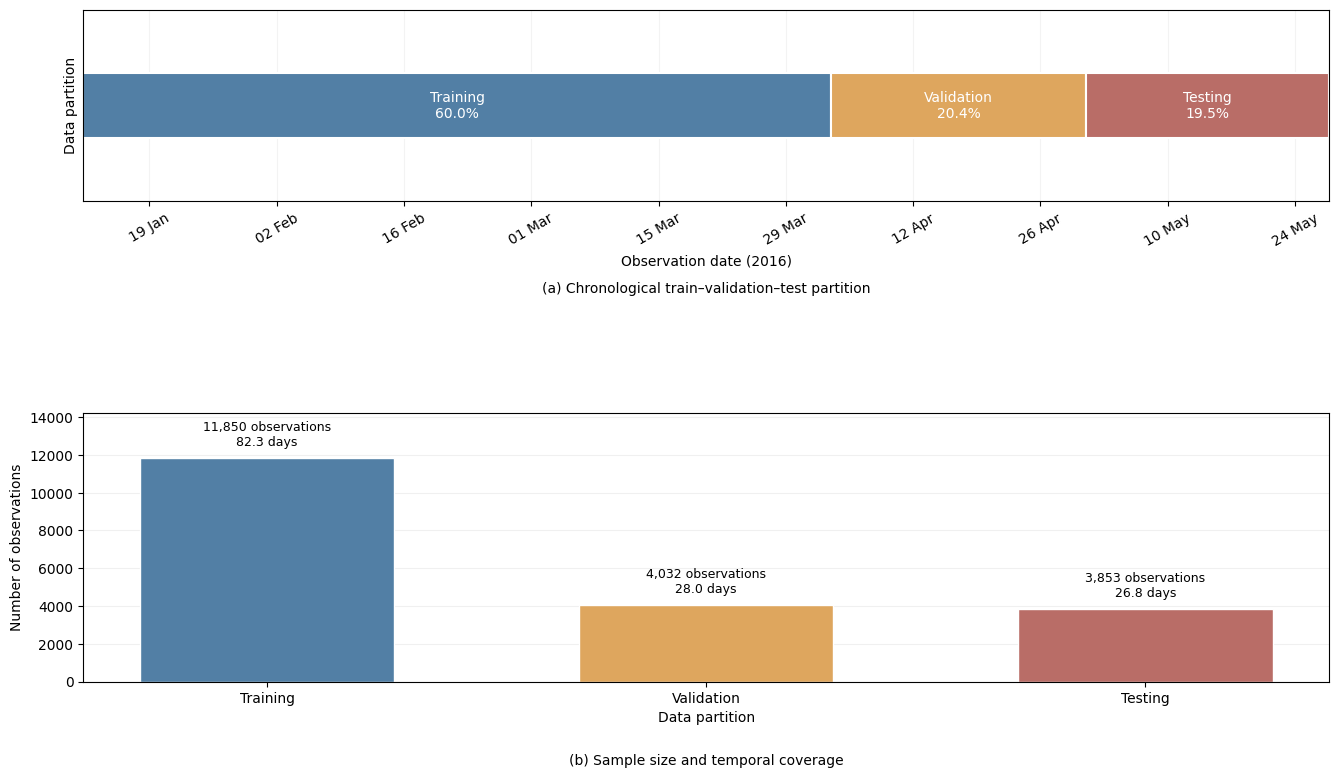

Chronological visualization saved:
/content/drive/MyDrive/Stability_Driven_Energy/02_preprocessed_data/temporal_partitions/02_chronological_partition_visualization.png

No models fitted.
No target values from test inspected.


In [2]:

# ============================================================
# NOTEBOOK 02 — CELL 01B
# CHRONOLOGICAL PARTITION VISUALIZATION
# No target values are inspected.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from matplotlib.patches import Patch

assert len(split_summary) == 3
assert set(split_summary["partition"]) == {
    "train", "validation", "test"
}

plot_df = (
    split_summary
    .set_index("partition")
    .loc[["train", "validation", "test"]]
    .reset_index()
    .copy()
)

palette = {
    "train": "#527FA5",
    "validation": "#DEA65E",
    "test": "#B96D67"
}

labels = {
    "train": "Training",
    "validation": "Validation",
    "test": "Testing"
}

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    gridspec_kw={
        "height_ratios": [1.0, 1.4]
    }
)

# ------------------------------------------------------------
# (a) Chronological time coverage
# ------------------------------------------------------------

ax = axes[0]

for _, row in plot_df.iterrows():

    part = row["partition"]

    start = pd.Timestamp(row["start"])
    end = (
        pd.Timestamp(row["end"])
        + pd.Timedelta(minutes=10)
    )

    left = mdates.date2num(start)
    right = mdates.date2num(end)

    ax.barh(
        y=0,
        width=right - left,
        left=left,
        height=0.48,
        color=palette[part],
        edgecolor="white",
        linewidth=1.5
    )

    midpoint = (left + right) / 2

    ax.text(
        midpoint,
        0,
        (
            f"{labels[part]}\n"
            f"{row['percentage']:.1f}%"
        ),
        ha="center",
        va="center",
        fontsize=10,
        fontweight="medium",
        color="white"
    )

ax.set_ylim(-0.7, 0.7)
ax.set_yticks([])
ax.set_ylabel("Data partition")

ax.set_xlim(
    mdates.date2num(
        pd.Timestamp(plot_df["start"].min())
    ),
    mdates.date2num(
        pd.Timestamp(plot_df["end"].max())
        + pd.Timedelta(minutes=10)
    )
)

ax.xaxis.set_major_locator(
    mdates.WeekdayLocator(interval=2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)

ax.tick_params(
    axis="x",
    labelrotation=30
)

ax.set_xlabel("Observation date (2016)")
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

ax.text(
    0.5,
    -0.42,
    "(a) Chronological train–validation–test partition",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=10
)

# ------------------------------------------------------------
# (b) Observation counts and duration
# ------------------------------------------------------------

ax = axes[1]

x = np.arange(len(plot_df))

bars = ax.bar(
    x,
    plot_df["n_observations"],
    color=[
        palette[p]
        for p in plot_df["partition"]
    ],
    width=0.58,
    edgecolor="white"
)

for bar, (_, row) in zip(
    bars,
    plot_df.iterrows()
):

    height = bar.get_height()

    annotation = (
        f"{int(row['n_observations']):,} observations\n"
        f"{row['duration_days']:.1f} days"
    )

    ax.annotate(
        annotation,
        xy=(
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels(
    [labels[p] for p in plot_df["partition"]]
)

ax.set_xlabel("Data partition")
ax.set_ylabel("Number of observations")

ax.set_ylim(
    0,
    plot_df["n_observations"].max() * 1.20
)

ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)

ax.text(
    0.5,
    -0.27,
    "(b) Sample size and temporal coverage",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=10
)

fig.subplots_adjust(
    left=0.09,
    right=0.98,
    top=0.97,
    bottom=0.13,
    hspace=0.92
)

figure_path = (
    OUTPUT_DIR /
    "02_chronological_partition_visualization.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Chronological visualization saved:")
print(figure_path)

print("\nNo models fitted.")
print("No target values from test inspected.")


# Expanding-Window CV Generator & Visualization

EXPANDING-WINDOW CROSS-VALIDATION
Training observations: 11850
Source integrity: PASS
Timestamp continuity: PASS
Feature Set A/B alignment: PASS

A. EXPANDING-WINDOW FOLD MANIFEST


,fold,train_start,train_end,n_train,train_days,assessment_start,assessment_end,n_assessment,assessment_days,gap_observations
0,1,2016-01-11 17:00:00,2016-03-05 23:50:00,7818,54.292,2016-03-06,2016-03-12 23:50:00,1008,7.0,0
1,2,2016-01-11 17:00:00,2016-03-12 23:50:00,8826,61.292,2016-03-13,2016-03-19 23:50:00,1008,7.0,0
2,3,2016-01-11 17:00:00,2016-03-19 23:50:00,9834,68.292,2016-03-20,2016-03-26 23:50:00,1008,7.0,0
3,4,2016-01-11 17:00:00,2016-03-26 23:50:00,10842,75.292,2016-03-27,2016-04-02 23:50:00,1008,7.0,0



CV INTEGRITY
Expanding training: PASS
Chronological ordering: PASS
Equal assessment windows: PASS
No assessment overlap: PASS
Gap rule: PASS


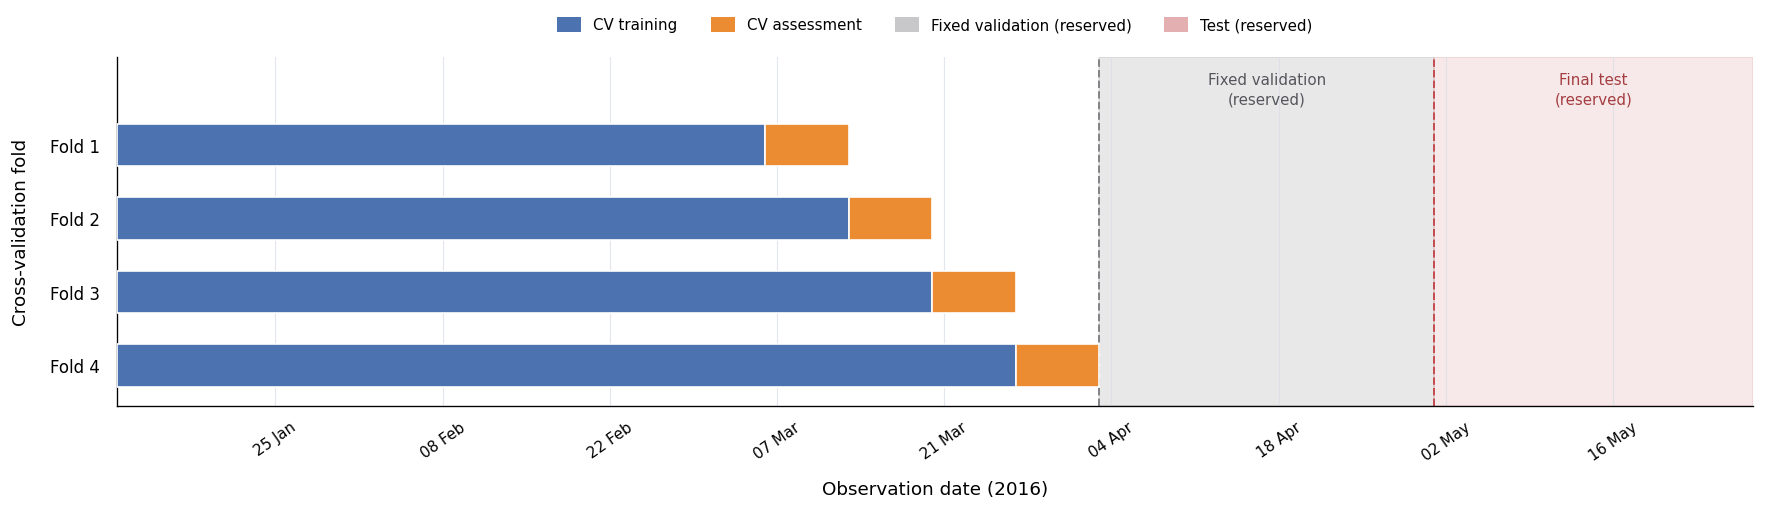


B. VISUALIZATION
Figure layout: Single timeline
Palette: Scientific qualitative
PNG saved: /content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/cv_design/figures/02_expanding_window_cv.png
SVG saved: /content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/cv_design/figures/02_expanding_window_cv.svg

CELL 02 — REVISED VERSION COMPLETED
CV folds: 4
Initial training: 7818
Assessment size per fold: 1008
Gap: 0

Integrity:
Expanding-window ordering: PASS
Training expansion: PASS
Assessment non-overlap: PASS
Reserved validation excluded: PASS
Reserved test excluded: PASS
Saved fold indices verified: PASS

Artifacts:
- /content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/cv_design/cv_fold_manifest.csv
- /content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/cv_design/cv_fold_indices.npz
- /content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/cv_design/figures/02_expanding_window_cv.png
- /content/drive/MyDrive/St

In [3]:

# ================================================================
# NOTEBOOK 02 — CELL 02 (REVISED)
# EXPANDING-WINDOW CV DESIGN, AUDIT & VISUALIZATION
# Stability-Driven Appliance Energy Evaluation
# ================================================================

import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from pathlib import Path
from matplotlib.patches import Patch
from IPython.display import display

# ================================================================
# 1. PROJECT PATHS
# ================================================================

ROOT = Path(
    "/content/drive/MyDrive/Stability_Driven_Energy"
)

META_DIR = ROOT / "09_experiment_metadata"

CV_DIR = META_DIR / "cv_design"
FIG_DIR = CV_DIR / "figures"

CV_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

SPLIT_META_PATH = (
    META_DIR / "notebook02_chronological_split.json"
)

SPLIT_SUMMARY_PATH = (
    META_DIR / "notebook02_chronological_split_summary.csv"
)

assert SPLIT_META_PATH.is_file(), (
    "Run Notebook 02 Cell 01 first."
)
assert SPLIT_SUMMARY_PATH.is_file()

with open(SPLIT_META_PATH, "r", encoding="utf-8") as f:
    split_meta = json.load(f)

A_TRAIN_PATH = Path(
    split_meta["files"]["A_train.csv"]["path"]
)

B_TRAIN_PATH = Path(
    split_meta["files"]["B_train.csv"]["path"]
)

assert A_TRAIN_PATH.is_file()
assert B_TRAIN_PATH.is_file()


def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


for name, path in [
    ("A_train.csv", A_TRAIN_PATH),
    ("B_train.csv", B_TRAIN_PATH)
]:
    assert sha256_file(path) == (
        split_meta["files"][name]["sha256"]
    )

# Only timestamps are read for fold construction.
dates_A = pd.read_csv(
    A_TRAIN_PATH,
    usecols=["date"],
    parse_dates=["date"]
)

dates_B = pd.read_csv(
    B_TRAIN_PATH,
    usecols=["date"],
    parse_dates=["date"]
)

pd.testing.assert_frame_equal(dates_A, dates_B)

timestamps = dates_A["date"]
N_TRAIN = len(timestamps)

assert N_TRAIN == 11850
assert N_TRAIN == split_meta["counts"]["train"]

assert timestamps.is_unique
assert timestamps.is_monotonic_increasing

assert (
    timestamps.diff().dropna()
    == pd.Timedelta(minutes=10)
).all()

print("=" * 70)
print("EXPANDING-WINDOW CROSS-VALIDATION")
print("=" * 70)

print("Training observations:", N_TRAIN)
print("Source integrity: PASS")
print("Timestamp continuity: PASS")
print("Feature Set A/B alignment: PASS")

# ================================================================
# 2. SCIENTIFIC VISUALIZATION PALETTE
# ================================================================

# Qualitative: categorical comparisons
# Sequential: numerical magnitude
# Diverging: numerical differences around a midpoint
#
# Colors selected from the supplied scientific palette
# reference, with hexadecimal values standardized for
# reproducible plotting.

SCIENTIFIC_PALETTE = {
    "qualitative": {
        "blue": "#4C72B0",
        "orange": "#EB8B32",
        "green": "#55A868",
        "red": "#C44E52",
        "purple": "#94529C",
        "brown": "#8C634D",
        "pink": "#EB74A9",
        "gray": "#858489",
        "yellow": "#E2C930",
        "teal": "#249B99"
    },

    "sequential_blue": [
        "#EDF5FB",
        "#C6DCEC",
        "#8EB5D5",
        "#4C72B0",
        "#233D70"
    ],

    "diverging_red_blue": [
        "#C44E52",
        "#E7A0A2",
        "#F5F5F5",
        "#A1B9DB",
        "#4C72B0"
    ]
}

# Persist palette for later notebooks.
PALETTE_PATH = (
    META_DIR / "scientific_visualization_palette.json"
)

with open(PALETTE_PATH, "w", encoding="utf-8") as f:
    json.dump(
        SCIENTIFIC_PALETTE,
        f,
        indent=4
    )

Q = SCIENTIFIC_PALETTE["qualitative"]

CV_COLORS = {
    "training": Q["blue"],
    "assessment": Q["orange"],
    "validation": Q["gray"],
    "test": Q["red"]
}

# Style scoped to this plotting cell.
# Does not change the input data.

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.dpi": 300,
    "figure.dpi": 120
})

# ================================================================
# 3. FIXED EXPANDING-WINDOW DESIGN
# ================================================================

N_FOLDS = 4
ASSESSMENT_DAYS = 7
INTERVAL_MINUTES = 10
GAP_OBSERVATIONS = 0

ASSESSMENT_SIZE = (
    ASSESSMENT_DAYS * 24 * 60
    // INTERVAL_MINUTES
)

STEP_SIZE = ASSESSMENT_SIZE

TRAIN_END_EXCLUSIVE = pd.Timestamp(
    split_meta["train_validation_boundary"]
)

FIRST_ASSESSMENT_START = (
    TRAIN_END_EXCLUSIVE
    - pd.Timedelta(
        days=N_FOLDS * ASSESSMENT_DAYS
    )
)

assert ASSESSMENT_SIZE == 1008
assert FIRST_ASSESSMENT_START == pd.Timestamp(
    "2016-03-06 00:00:00"
)

assert TRAIN_END_EXCLUSIVE == pd.Timestamp(
    "2016-04-03 00:00:00"
)

# ================================================================
# 4. GENERATE FOLD INDICES
# ================================================================

fold_indices = {}
fold_records = []

for k in range(N_FOLDS):

    fold_id = k + 1
    fold_key = f"fold_{fold_id:02d}"

    assessment_start = (
        FIRST_ASSESSMENT_START
        + pd.Timedelta(
            days=k * ASSESSMENT_DAYS
        )
    )

    assessment_end_exclusive = (
        assessment_start
        + pd.Timedelta(days=ASSESSMENT_DAYS)
    )

    train_end_exclusive = (
        assessment_start
        - pd.Timedelta(
            minutes=GAP_OBSERVATIONS * INTERVAL_MINUTES
        )
    )

    train_idx = np.flatnonzero(
        (
            timestamps < train_end_exclusive
        ).to_numpy()
    ).astype(np.int64)

    assessment_idx = np.flatnonzero(
        (
            (timestamps >= assessment_start) &
            (timestamps < assessment_end_exclusive)
        ).to_numpy()
    ).astype(np.int64)

    assert len(train_idx) > 0
    assert len(assessment_idx) == ASSESSMENT_SIZE

    assert train_idx.max() < assessment_idx.min()

    assert np.intersect1d(
        train_idx, assessment_idx
    ).size == 0

    assert np.array_equal(
        train_idx,
        np.arange(len(train_idx))
    )

    assert np.array_equal(
        assessment_idx,
        np.arange(
            assessment_idx[0],
            assessment_idx[-1] + 1
        )
    )

    train_start = timestamps.iloc[train_idx[0]]
    train_end = timestamps.iloc[train_idx[-1]]

    actual_assessment_start = timestamps.iloc[
        assessment_idx[0]
    ]

    assessment_end = timestamps.iloc[
        assessment_idx[-1]
    ]

    assert actual_assessment_start == assessment_start

    assert assessment_end == (
        assessment_end_exclusive
        - pd.Timedelta(minutes=INTERVAL_MINUTES)
    )

    assert (
        actual_assessment_start - train_end
        == pd.Timedelta(
            minutes=(
                GAP_OBSERVATIONS + 1
            ) * INTERVAL_MINUTES
        )
    )

    fold_indices[
        f"{fold_key}_train"
    ] = train_idx

    fold_indices[
        f"{fold_key}_assessment"
    ] = assessment_idx

    fold_records.append({
        "fold": fold_id,
        "train_start": train_start,
        "train_end": train_end,

        "assessment_start": actual_assessment_start,
        "assessment_end": assessment_end,

        "n_train": int(len(train_idx)),
        "n_assessment": int(len(assessment_idx)),

        "train_days": (
            len(train_idx) * INTERVAL_MINUTES / 1440
        ),

        "assessment_days": (
            len(assessment_idx) * INTERVAL_MINUTES / 1440
        ),

        "gap_observations": GAP_OBSERVATIONS,

        "train_first_index": int(train_idx[0]),
        "train_last_index": int(train_idx[-1]),

        "assessment_first_index": int(
            assessment_idx[0]
        ),

        "assessment_last_index": int(
            assessment_idx[-1]
        )
    })

fold_manifest = pd.DataFrame(fold_records)

# ================================================================
# 5. CV INTEGRITY CHECKS
# ================================================================

EXPECTED_TRAIN_SIZES = [
    7818, 8826, 9834, 10842
]

assert (
    fold_manifest["n_train"].tolist()
    == EXPECTED_TRAIN_SIZES
)

assert (
    fold_manifest["n_assessment"] == 1008
).all()

assert (
    fold_manifest["n_train"]
    .diff()
    .dropna()
    .eq(STEP_SIZE)
    .all()
)

# Verify cumulative training.
for k in range(2, N_FOLDS + 1):

    previous_train = fold_indices[
        f"fold_{k-1:02d}_train"
    ]

    current_train = fold_indices[
        f"fold_{k:02d}_train"
    ]

    previous_assessment = fold_indices[
        f"fold_{k-1:02d}_assessment"
    ]

    assert np.array_equal(
        current_train[:len(previous_train)],
        previous_train
    )

    assert np.isin(
        previous_assessment,
        current_train
    ).all()

# Verify unique and consecutive assessment indices.
all_assessment = np.concatenate([
    fold_indices[f"fold_{k:02d}_assessment"]
    for k in range(1, N_FOLDS + 1)
])

assert len(all_assessment) == 4032

assert len(np.unique(all_assessment)) == 4032

assert np.array_equal(
    np.sort(all_assessment),
    np.arange(7818, 11850)
)

assert (
    fold_manifest.iloc[-1]["assessment_end"]
    == timestamps.iloc[-1]
)

assert (
    timestamps.iloc[-1]
    + pd.Timedelta(minutes=INTERVAL_MINUTES)
    == TRAIN_END_EXCLUSIVE
)

print("\nA. EXPANDING-WINDOW FOLD MANIFEST")

display(
    fold_manifest[[
        "fold",
        "train_start",
        "train_end",
        "n_train",
        "train_days",
        "assessment_start",
        "assessment_end",
        "n_assessment",
        "assessment_days",
        "gap_observations"
    ]].round(3)
)

print("\nCV INTEGRITY")
print("Expanding training: PASS")
print("Chronological ordering: PASS")
print("Equal assessment windows: PASS")
print("No assessment overlap: PASS")
print("Gap rule: PASS")

# ================================================================
# 6. RESERVED VALIDATION AND TEST BOUNDARIES
# ================================================================

split_summary = pd.read_csv(
    SPLIT_SUMMARY_PATH,
    parse_dates=["start", "end"]
).set_index("partition")

VALIDATION_START = split_summary.loc[
    "validation", "start"
]

TEST_START = split_summary.loc[
    "test", "start"
]

TEST_END_EXCLUSIVE = (
    split_summary.loc["test", "end"]
    + pd.Timedelta(minutes=INTERVAL_MINUTES)
)

assert VALIDATION_START == TRAIN_END_EXCLUSIVE

assert TEST_START == pd.Timestamp(
    split_meta["validation_test_boundary"]
)

assert (
    VALIDATION_START < TEST_START < TEST_END_EXCLUSIVE
)

# ================================================================
# 7. SINGLE-FIGURE EXPANDING-WINDOW VISUALIZATION
# ================================================================

fig, ax = plt.subplots(
    figsize=(15.5, 5.2)
)

date_num = mdates.date2num

# ------------------------------------------------------------
# 7A. Reserved periods — subtle background shading
# ------------------------------------------------------------

ax.axvspan(
    date_num(VALIDATION_START),
    date_num(TEST_START),
    color=CV_COLORS["validation"],
    alpha=0.18,
    zorder=0
)

ax.axvspan(
    date_num(TEST_START),
    date_num(TEST_END_EXCLUSIVE),
    color=CV_COLORS["test"],
    alpha=0.12,
    zorder=0
)

# ------------------------------------------------------------
# 7B. CV training and assessment bars
# ------------------------------------------------------------

BAR_HEIGHT = 0.58

for i, row in fold_manifest.iterrows():

    train_left = date_num(
        row["train_start"]
    )

    train_right = date_num(
        row["train_end"]
        + pd.Timedelta(minutes=INTERVAL_MINUTES)
    )

    assessment_left = date_num(
        row["assessment_start"]
    )

    assessment_right = date_num(
        row["assessment_end"]
        + pd.Timedelta(minutes=INTERVAL_MINUTES)
    )

    # Expanding training period
    ax.barh(
        y=i,
        width=train_right - train_left,
        left=train_left,
        height=BAR_HEIGHT,
        color=CV_COLORS["training"],
        edgecolor="white",
        linewidth=1.0,
        zorder=3
    )

    # Chronological assessment period
    ax.barh(
        y=i,
        width=assessment_right - assessment_left,
        left=assessment_left,
        height=BAR_HEIGHT,
        color=CV_COLORS["assessment"],
        edgecolor="white",
        linewidth=1.0,
        zorder=4
    )

# ------------------------------------------------------------
# 7C. Partition boundaries
# ------------------------------------------------------------

ax.axvline(
    date_num(VALIDATION_START),
    color=CV_COLORS["validation"],
    linestyle="--",
    linewidth=1.2,
    zorder=2
)

ax.axvline(
    date_num(TEST_START),
    color=CV_COLORS["test"],
    linestyle="--",
    linewidth=1.2,
    zorder=2
)

# ------------------------------------------------------------
# 7D. Reserved-period labels above the fold bars
# ------------------------------------------------------------

validation_midpoint = (
    date_num(VALIDATION_START)
    + date_num(TEST_START)
) / 2

test_midpoint = (
    date_num(TEST_START)
    + date_num(TEST_END_EXCLUSIVE)
) / 2

ax.text(
    validation_midpoint,
    -0.75,
    "Fixed validation\n(reserved)",
    ha="center",
    va="center",
    fontsize=9,
    fontweight="medium",
    color="#55565C",
    linespacing=1.4
)

ax.text(
    test_midpoint,
    -0.75,
    "Final test\n(reserved)",
    ha="center",
    va="center",
    fontsize=9,
    fontweight="medium",
    color="#A43D41",
    linespacing=1.4
)

# ------------------------------------------------------------
# 7E. Axes and tick formatting
# ------------------------------------------------------------

ax.set_yticks(
    np.arange(N_FOLDS)
)

ax.set_yticklabels([
    f"Fold {i}"
    for i in range(1, N_FOLDS + 1)
])

# Extra space above fold 1 for reserved-period labels.
ax.set_ylim(
    N_FOLDS - 0.45,
    -1.20
)

ax.set_xlim(
    date_num(timestamps.iloc[0]),
    date_num(TEST_END_EXCLUSIVE)
)

ax.xaxis.set_major_locator(
    mdates.WeekdayLocator(
        byweekday=mdates.MO,
        interval=2
    )
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)

ax.tick_params(
    axis="x",
    rotation=35,
    labelsize=9,
    length=0,
    pad=8
)

ax.tick_params(
    axis="y",
    labelsize=10,
    length=0,
    pad=10
)

ax.set_xlabel(
    "Observation date (2016)",
    labelpad=10
)

ax.set_ylabel(
    "Cross-validation fold",
    labelpad=12
)

ax.grid(
    axis="x",
    color="#D9DEE7",
    linewidth=0.65,
    alpha=0.75
)

ax.set_axisbelow(True)

# ------------------------------------------------------------
# 7F. Single-row legend — positioned above the axes
# ------------------------------------------------------------

legend_handles = [
    Patch(
        facecolor=CV_COLORS["training"],
        label="CV training"
    ),
    Patch(
        facecolor=CV_COLORS["assessment"],
        label="CV assessment"
    ),
    Patch(
        facecolor=CV_COLORS["validation"],
        alpha=0.45,
        label="Fixed validation (reserved)"
    ),
    Patch(
        facecolor=CV_COLORS["test"],
        alpha=0.45,
        label="Test (reserved)"
    )
]

ax.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.03),
    ncol=4,
    frameon=False,
    fontsize=9,
    columnspacing=2.2,
    handlelength=1.6,
    handleheight=1.1
)

# ------------------------------------------------------------
# 7G. Figure spacing
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.105,
    right=0.985,
    top=0.78,
    bottom=0.22
)

# ------------------------------------------------------------
# 7H. Save high-resolution and vector versions
# ------------------------------------------------------------

FIG_PNG = (
    FIG_DIR / "02_expanding_window_cv.png"
)

FIG_SVG = (
    FIG_DIR / "02_expanding_window_cv.svg"
)

fig.savefig(
    FIG_PNG,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIG_SVG,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("\nB. VISUALIZATION")
print("Figure layout: Single timeline")
print("Palette: Scientific qualitative")
print("PNG saved:", FIG_PNG)
print("SVG saved:", FIG_SVG)

# ================================================================
# 8. SAVE MANIFEST AND FOLD INDICES
# ================================================================

MANIFEST_PATH = (
    CV_DIR / "cv_fold_manifest.csv"
)

INDICES_PATH = (
    CV_DIR / "cv_fold_indices.npz"
)

fold_manifest.to_csv(
    MANIFEST_PATH,
    index=False
)

np.savez_compressed(
    INDICES_PATH,
    **fold_indices
)

# Reload verification
with np.load(INDICES_PATH) as loaded:

    assert set(loaded.files) == set(
        fold_indices.keys()
    )

    for key, expected in fold_indices.items():

        np.testing.assert_array_equal(
            loaded[key],
            expected
        )

# ================================================================
# 9. FUTURE FOLD-LEVEL EVALUATION SCHEMA
# ================================================================

# Schemas only. No model results are created.

METRIC_COLUMNS = [
    "experiment_id",
    "algorithm",
    "model_version",
    "feature_set",
    "target_treatment",
    "fold",

    "n_train",
    "n_assessment",

    "train_rmse_wh",
    "assessment_rmse_wh",
    "train_mae_wh",
    "assessment_mae_wh",

    "train_r2",
    "assessment_r2",

    "rmse_gap_wh",
    "fit_seconds",
    "random_seed",
    "hyperparameters_json"
]

PREDICTION_COLUMNS = [
    "experiment_id",
    "algorithm",
    "model_version",
    "feature_set",
    "target_treatment",
    "fold",
    "sample_index",
    "timestamp",
    "actual_wh",
    "predicted_wh",
    "residual_wh"
]

ITERATION_COLUMNS = [
    "experiment_id",
    "algorithm",
    "model_version",
    "feature_set",
    "target_treatment",
    "fold",
    "iteration",
    "training_metric",
    "assessment_metric",
    "metric_name",
    "metric_scale"
]

SCHEMA = {
    "fold_metrics": METRIC_COLUMNS,
    "assessment_predictions": PREDICTION_COLUMNS,
    "iterative_training_history": ITERATION_COLUMNS,

    "rmse_gap_definition": (
        "assessment_rmse_wh - train_rmse_wh"
    ),

    "selection_metric": (
        "Mean assessment RMSE in original Wh"
    ),

    "history_note": (
        "Native training histories are recorded "
        "when supported by the algorithm. "
        "Comparative evaluation uses Wh."
    ),

    "status": "Schema only; no models fitted"
}

METRIC_SCHEMA_PATH = (
    CV_DIR / "cv_fold_metric_schema.json"
)

with open(
    METRIC_SCHEMA_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        SCHEMA,
        f,
        indent=4
    )

# ================================================================
# 10. SAVE CV DESIGN METADATA
# ================================================================

CV_METADATA = {
    "notebook": "02_Model_Development",
    "cell": "02_Expanding_Window_CV",

    "method": "Chronological expanding-window",

    "training_partition_observations": N_TRAIN,

    "n_folds": N_FOLDS,

    "initial_train_observations": int(
        fold_manifest.iloc[0]["n_train"]
    ),

    "assessment_observations": ASSESSMENT_SIZE,
    "assessment_days": ASSESSMENT_DAYS,

    "step_observations": STEP_SIZE,
    "gap_observations": GAP_OBSERVATIONS,

    "first_assessment_start": (
        FIRST_ASSESSMENT_START.isoformat()
    ),

    "last_assessment_end": (
        fold_manifest.iloc[-1][
            "assessment_end"
        ].isoformat()
    ),

    "same_indices_for_all_algorithms": True,
    "same_indices_for_all_feature_sets": True,

    "indices_relative_to": (
        "A_train.csv and B_train.csv"
    ),

    "preprocessing_fit_scope": (
        "Training subset within each fold"
    ),

    "metric_scale": "Original Wh",
    "selection_metric": "Mean assessment RMSE",

    "visualization_standard": {
        "reference": "Scientific Color Palettes",
        "categorical": "Qualitative palette",
        "numeric": "Sequential palette",
        "centered_numeric": "Diverging palette",
        "main_figure_title": False,
        "single_panel": True,
        "legend_outside_plot": True,
        "palette_file": str(PALETTE_PATH)
    },

    "artifacts": {
        "fold_manifest": str(MANIFEST_PATH),
        "fold_indices": str(INDICES_PATH),
        "figure_png": str(FIG_PNG),
        "figure_svg": str(FIG_SVG),
        "metric_schema": str(METRIC_SCHEMA_PATH)
    },

    "future_diagnostics": {
        "all_algorithms": [
            "Train and assessment RMSE per fold",
            "MAE and R2 per fold",
            "Generalization gap",
            "Assessment predictions and residuals"
        ],

        "boosting_models": [
            "Native iteration histories",
            "Training vs assessment RMSE curves"
        ],

        "other_models": [
            "Model-appropriate learning curves",
            "Model-complexity diagnostic curves"
        ]
    },

    "fixed_validation_used": False,
    "test_used": False,
    "model_training_performed": False
}

CV_META_PATH = (
    CV_DIR / "cv_design_metadata.json"
)

with open(
    CV_META_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        CV_METADATA,
        f,
        indent=4,
        ensure_ascii=False
    )

# ================================================================
# 11. FINAL CHECKPOINT
# ================================================================

print("\n" + "=" * 70)
print("CELL 02 — REVISED VERSION COMPLETED")
print("=" * 70)

print("CV folds:", N_FOLDS)
print("Initial training:", EXPECTED_TRAIN_SIZES[0])
print("Assessment size per fold:", ASSESSMENT_SIZE)
print("Gap:", GAP_OBSERVATIONS)

print("\nIntegrity:")
print("Expanding-window ordering: PASS")
print("Training expansion: PASS")
print("Assessment non-overlap: PASS")
print("Reserved validation excluded: PASS")
print("Reserved test excluded: PASS")
print("Saved fold indices verified: PASS")

print("\nArtifacts:")
print("-", MANIFEST_PATH)
print("-", INDICES_PATH)
print("-", FIG_PNG)
print("-", FIG_SVG)
print("-", PALETTE_PATH)
print("-", METRIC_SCHEMA_PATH)
print("-", CV_META_PATH)

print("\nNo models fitted.")
print("No preprocessing selected.")
print("No hyperparameters tuned.")
print("No validation/test target accessed.")


# Model Implementation Specification

## Audit implementasi dan konfigurasi baseline

Memverifikasi bahwa file fold dan metadata preprocessing sebelumnya tersedia.



Membuat enam estimator default dengan pengaturan reproducibility.



Mencatat versi package dan hyperparameter aktual.



Membuat 24 pipeline blueprints dari 6 algoritma × 4 konfigurasi preprocessing, tanpa memanggil .fit().



Menyimpan konfigurasi dan protokol kurva diagnostik untuk digunakan pada Cell 04 dan tahap Grid Search.

In [4]:

# ================================================================
# NOTEBOOK 02 — CELL 03
# MODEL IMPLEMENTATION & REPRODUCIBILITY AUDIT
# No fitting, no prediction, no hyperparameter tuning
# ================================================================

import json
import sys
import platform
import inspect
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import pandas as pd

from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    BaggingRegressor
)
from sklearn.svm import SVR

try:
    import xgboost as xgb
    import lightgbm as lgb
except ImportError as exc:
    raise ImportError(
        "XGBoost and LightGBM are required. "
        "Install the missing package in Colab first."
    ) from exc

# ================================================================
# 1. PROJECT AND PREVIOUS METADATA
# ================================================================

ROOT = Path(
    "/content/drive/MyDrive/Stability_Driven_Energy"
)

META_DIR = ROOT / "09_experiment_metadata"
CV_DIR = META_DIR / "cv_design"
MODEL_SPEC_DIR = META_DIR / "model_specification"

MODEL_SPEC_DIR.mkdir(parents=True, exist_ok=True)

PREP_PATH = (
    META_DIR / "notebook01_preprocessing_strategy.json"
)

SPLIT_PATH = (
    META_DIR / "notebook02_chronological_split.json"
)

CV_META_PATH = (
    CV_DIR / "cv_design_metadata.json"
)

CV_MANIFEST_PATH = (
    CV_DIR / "cv_fold_manifest.csv"
)

CV_INDICES_PATH = (
    CV_DIR / "cv_fold_indices.npz"
)

for path in [
    PREP_PATH,
    SPLIT_PATH,
    CV_META_PATH,
    CV_MANIFEST_PATH,
    CV_INDICES_PATH
]:
    assert path.is_file(), f"Missing dependency: {path}"


def read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


prep = read_json(PREP_PATH)
split = read_json(SPLIT_PATH)
cv_meta = read_json(CV_META_PATH)

fold_manifest = pd.read_csv(CV_MANIFEST_PATH)

assert len(fold_manifest) == 4
assert cv_meta["n_folds"] == 4
assert cv_meta["gap_observations"] == 0

assert split["counts"]["train"] == 11850
assert split["counts"]["validation"] == 4032
assert split["counts"]["test"] == 3853

FEATURE_SETS = prep["feature_sets"]

FEATURE_A = FEATURE_SETS["A"]
FEATURE_B = FEATURE_SETS["B"]

assert len(FEATURE_A) == 25
assert len(FEATURE_B) == 27

assert set(FEATURE_B) - set(FEATURE_A) == {
    "time_sin", "time_cos"
}

with np.load(CV_INDICES_PATH) as saved_indices:

    assert len(saved_indices.files) == 8

    for fold_id in range(1, 5):

        key_train = f"fold_{fold_id:02d}_train"
        key_assess = f"fold_{fold_id:02d}_assessment"

        train_idx = saved_indices[key_train]
        assess_idx = saved_indices[key_assess]

        assert len(train_idx) == int(
            fold_manifest.iloc[fold_id - 1]["n_train"]
        )

        assert len(assess_idx) == 1008
        assert train_idx.max() < assess_idx.min()

print("=" * 72)
print("CELL 03 — MODEL IMPLEMENTATION SPECIFICATION")
print("=" * 72)

print("Previous experiment artifacts: VALID")
print("Feature sets: A (25), B (27)")
print("CV folds: 4")
print("Training partition: 11850 observations")

# ================================================================
# 2. SOFTWARE ENVIRONMENT AUDIT
# ================================================================

def package_version(package):
    try:
        return version(package)
    except PackageNotFoundError:
        return "NOT INSTALLED"


environment = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "numpy": package_version("numpy"),
    "pandas": package_version("pandas"),
    "scipy": package_version("scipy"),
    "scikit_learn": package_version("scikit-learn"),
    "xgboost": package_version("xgboost"),
    "lightgbm": package_version("lightgbm"),
    "matplotlib": package_version("matplotlib"),
    "colab_runtime": "Google Colab",
    "audit_time_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

print("\nA. SOFTWARE ENVIRONMENT")

display(
    pd.DataFrame(
        [
            {"component": k, "value": v}
            for k, v in environment.items()
        ]
    )
)

# ================================================================
# 3. REPRODUCIBILITY CONTROLS
# ================================================================

SEED = 42

# Single-thread settings reduce variability from
# parallel execution in the baseline audit.
#
# This is a technical control, not hyperparameter tuning.
# It does not guarantee bitwise reproducibility on
# every hardware and package-version combination.

N_JOBS = 1

REPRODUCIBILITY = {
    "random_seed": SEED,
    "n_jobs_for_supported_estimators": N_JOBS,
    "hardware_policy": "CPU",
    "global_random_state_mutated": False,
    "model_random_state_fixed": True,
    "baseline_hyperparameter_tuning": False,
    "parallel_cv_jobs": 1,
    "bootstrap_seed_strategy": (
        "To be specified before Notebook 03"
    )
}

# ================================================================
# 4. INSTANTIATE SIX DEFAULT ESTIMATORS
# ================================================================

# Only random_state and n_jobs are explicitly set
# when supported.
#
# All other constructor parameters are left at their
# defaults in the installed library version.

ESTIMATORS = {
    "Decision Tree": DecisionTreeRegressor(
        random_state=SEED
    ),

    "Random Forest": RandomForestRegressor(
        random_state=SEED,
        n_jobs=N_JOBS
    ),

    "Bagging": BaggingRegressor(
        random_state=SEED,
        n_jobs=N_JOBS
    ),

    "SVR": SVR(),

    "XGBoost": xgb.XGBRegressor(
        random_state=SEED,
        n_jobs=N_JOBS
    ),

    "LightGBM": lgb.LGBMRegressor(
        random_state=SEED,
        n_jobs=N_JOBS
    )
}

assert len(ESTIMATORS) == 6

# Bagging's implicit base estimator must be
# a DecisionTreeRegressor for this library version.
#
# The default estimator=None is checked here.
# Its meaning is documented by scikit-learn.

bagging_params = ESTIMATORS["Bagging"].get_params(
    deep=False
)

bagging_base_key = (
    "estimator"
    if "estimator" in bagging_params
    else "base_estimator"
)

assert bagging_params[bagging_base_key] is None

# SVR is deterministic for the chosen formulation;
# it has no random_state constructor argument.
assert "random_state" not in ESTIMATORS[
    "SVR"
].get_params(deep=False)

# ================================================================
# 5. PARAMETER AND THEORETICAL SPECIFICATION
# ================================================================

MODEL_THEORY = {
    "Decision Tree": {
        "reference": (
            "Breiman et al. (1984), "
            "Classification and Regression Trees"
        ),
        "mechanism": "CART recursive binary partitioning",
        "objective": "Squared-error impurity",
        "main_complexity": "Tree depth and leaf size",
        "scaling": "None",
        "diagnostic_curve": (
            "RMSE against tree complexity"
        )
    },

    "Random Forest": {
        "reference": "Breiman (2001), Random Forests",
        "mechanism": (
            "Bootstrap ensemble of randomized trees"
        ),
        "objective": "Squared-error regression",
        "main_complexity": (
            "Number, depth and random feature restriction"
        ),
        "scaling": "None",
        "diagnostic_curve": (
            "RMSE against ensemble size"
        )
    },

    "Bagging": {
        "reference": "Breiman (1996), Bagging Predictors",
        "mechanism": (
            "Bootstrap aggregation of regression trees"
        ),
        "objective": "Mean squared error within base trees",
        "main_complexity": (
            "Number and complexity of base trees"
        ),
        "scaling": "None",
        "diagnostic_curve": (
            "RMSE against ensemble size"
        )
    },

    "SVR": {
        "reference": (
            "Drucker et al. (1997), "
            "Support Vector Regression Machines"
        ),
        "mechanism": (
            "Kernel regression with epsilon-insensitive loss"
        ),
        "objective": (
            "Regularized epsilon-insensitive loss"
        ),
        "main_complexity": "C, epsilon and gamma",
        "scaling": "StandardScaler",
        "diagnostic_curve": (
            "Learning curve / hyperparameter validation curve"
        )
    },

    "XGBoost": {
        "reference": (
            "Chen and Guestrin (2016), "
            "XGBoost: A Scalable Tree Boosting System"
        ),
        "mechanism": (
            "Regularized sequential gradient-boosted trees"
        ),
        "objective": "Squared-error regression",
        "main_complexity": (
            "Boosting rounds, depth, learning rate, "
            "sampling and regularization"
        ),
        "scaling": "None",
        "diagnostic_curve": (
            "Train and assessment RMSE by boosting round"
        )
    },

    "LightGBM": {
        "reference": (
            "Ke et al. (2017), "
            "LightGBM: A Highly Efficient Gradient "
            "Boosting Decision Tree"
        ),
        "mechanism": (
            "Histogram-based leaf-wise gradient boosting"
        ),
        "objective": "Squared-error regression",
        "main_complexity": (
            "Boosting rounds, leaves, depth, "
            "leaf size and regularization"
        ),
        "scaling": "None",
        "diagnostic_curve": (
            "Train and assessment RMSE by boosting round"
        )
    }
}

HIGHLIGHT_PARAMS = {
    "Decision Tree": [
        "criterion",
        "splitter",
        "max_depth",
        "min_samples_leaf",
        "ccp_alpha"
    ],

    "Random Forest": [
        "n_estimators",
        "criterion",
        "max_features",
        "bootstrap",
        "max_depth",
        "min_samples_leaf"
    ],

    "Bagging": [
        bagging_base_key,
        "n_estimators",
        "max_samples",
        "max_features",
        "bootstrap",
        "bootstrap_features"
    ],

    "SVR": [
        "kernel",
        "C",
        "epsilon",
        "gamma",
        "tol"
    ],

    "XGBoost": [
        "objective",
        "n_estimators",
        "learning_rate",
        "max_depth",
        "min_child_weight",
        "subsample",
        "colsample_bytree",
        "reg_lambda"
    ],

    "LightGBM": [
        "boosting_type",
        "objective",
        "n_estimators",
        "learning_rate",
        "num_leaves",
        "max_depth",
        "min_child_samples",
        "subsample"
    ]
}


def json_safe(value):
    """Convert estimator parameter values for audit JSON."""

    if value is None or isinstance(
        value, (str, int, float, bool)
    ):
        return value

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]

    if isinstance(value, dict):
        return {
            str(k): json_safe(v)
            for k, v in value.items()
        }

    return repr(value)


parameter_audit = {}
audit_records = []

for name, estimator in ESTIMATORS.items():

    params = estimator.get_params(deep=False)

    parameter_audit[name] = {
        key: json_safe(value)
        for key, value in params.items()
    }

    summary = {
        key: json_safe(params.get(key))
        for key in HIGHLIGHT_PARAMS[name]
    }

    audit_records.append({
        "algorithm": name,
        "estimator_class": (
            estimator.__class__.__name__
        ),
        "main_mechanism": (
            MODEL_THEORY[name]["mechanism"]
        ),
        "optimization_objective": (
            MODEL_THEORY[name]["objective"]
        ),
        "scaling": MODEL_THEORY[name]["scaling"],
        "diagnostic_curve": (
            MODEL_THEORY[name]["diagnostic_curve"]
        ),
        "selected_default_parameters": (
            json.dumps(summary, default=str)
        )
    })

implementation_table = pd.DataFrame(
    audit_records
)

print("\nB. ALGORITHM IMPLEMENTATION AUDIT")
display(implementation_table)

print("\nC. ACTUAL DEFAULT PARAMETERS")

for name, estimator in ESTIMATORS.items():

    params = estimator.get_params(deep=False)

    selected = {
        key: params.get(key)
        for key in HIGHLIGHT_PARAMS[name]
    }

    print(f"\n{name}")
    display(
        pd.DataFrame([
            {"parameter": k, "value": repr(v)}
            for k, v in selected.items()
        ])
    )

# ================================================================
# 6. BUILD UNFITTED PREPROCESSING PIPELINES
# ================================================================

# Both feature sets use the same transformation policy.
#
# For SVR: StandardScaler is fitted inside each CV fold.
# For trees: predictors are passed through unchanged.
#
# For log-target candidates:
# log1p is applied during fitting, and inverse expm1
# is applied by predict().
#
# No transformations are fitted in this cell.

def make_pipeline(algorithm):

    estimator = clone(ESTIMATORS[algorithm])

    if algorithm == "SVR":
        preprocessor = StandardScaler()
    else:
        preprocessor = "passthrough"

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])


def make_candidate_model(algorithm, target_treatment):

    pipeline = make_pipeline(algorithm)

    if target_treatment == "raw":
        return pipeline

    if target_treatment == "log1p":
        return TransformedTargetRegressor(
            regressor=pipeline,
            func=np.log1p,
            inverse_func=np.expm1,
            check_inverse=True
        )

    raise ValueError(
        f"Unknown target treatment: {target_treatment}"
    )


CANDIDATES = {
    "A_raw": {"feature_set": "A", "target": "raw"},
    "A_log": {"feature_set": "A", "target": "log1p"},
    "B_raw": {"feature_set": "B", "target": "raw"},
    "B_log": {"feature_set": "B", "target": "log1p"}
}

PIPELINE_BLUEPRINTS = {}
pipeline_records = []

for algorithm in ESTIMATORS:

    for config_name, config in CANDIDATES.items():

        blueprint_id = (
            f"{algorithm.replace(' ', '_')}"
            f"__{config_name}"
        )

        model = make_candidate_model(
            algorithm,
            config["target"]
        )

        # Verify compatibility with scikit-learn cloning.
        cloned_model = clone(model)

        assert not hasattr(
            cloned_model, "n_features_in_"
        )

        # Different parameter prefixes are expected
        # for raw and log-target wrappers.
        prefix = (
            "regressor__model__"
            if config["target"] == "log1p"
            else "model__"
        )

        nested_params = model.get_params(deep=True)

        example_parameter = (
            "C" if algorithm == "SVR"
            else "max_depth"
            if algorithm in [
                "Decision Tree", "Random Forest",
                "XGBoost", "LightGBM"
            ]
            else "n_estimators"
        )

        expected_param_key = (
            prefix + example_parameter
        )

        assert expected_param_key in nested_params, (
            f"Missing parameter path: "
            f"{expected_param_key}"
        )

        PIPELINE_BLUEPRINTS[blueprint_id] = model

        pipeline_records.append({
            "blueprint_id": blueprint_id,
            "algorithm": algorithm,
            "configuration": config_name,
            "feature_set": config["feature_set"],
            "n_features": len(
                FEATURE_SETS[config["feature_set"]]
            ),
            "target_treatment": config["target"],
            "scaler": (
                "StandardScaler"
                if algorithm == "SVR"
                else "None"
            ),
            "estimator_parameter_prefix": prefix,
            "example_parameter_key": expected_param_key,
            "fitted": False
        })

pipeline_table = pd.DataFrame(
    pipeline_records
)

assert len(pipeline_table) == 24
assert len(PIPELINE_BLUEPRINTS) == 24

print("\nD. PREPROCESSING PIPELINE BLUEPRINTS")

display(
    pipeline_table[[
        "algorithm",
        "configuration",
        "n_features",
        "target_treatment",
        "scaler",
        "example_parameter_key"
    ]]
)

# ================================================================
# 7. REGISTER PER-FOLD EXPERIMENTAL DIAGNOSTICS
# ================================================================

# No results yet.
# These rules will be implemented during baseline CV.

DIAGNOSTIC_POLICY = {
    "all_algorithms": {
        "fit_scope": "CV training fold only",
        "assessment_scope": "Next chronological week",
        "evaluation_scale": "Original Wh",
        "metrics": [
            "RMSE", "MAE", "R2"
        ],
        "store_training_metrics": True,
        "store_assessment_metrics": True,
        "store_assessment_predictions": True,
        "store_fold_hyperparameters": True,
        "store_fold_training_time": True,
        "store_fold_seed": True
    },

    "boosting_models": {
        "algorithms": [
            "XGBoost",
            "LightGBM"
        ],
        "native_iteration_history": True,
        "history_scale": (
            "Target training scale; Wh for raw target, "
            "log scale for log1p target"
        ),
        "wh_scale_diagnostic_curve": True,
        "early_stopping_during_screening": False
    },

    "non_boosting_models": {
        "Decision Tree": (
            "Complexity validation curve"
        ),
        "Random Forest": (
            "Ensemble-size diagnostic"
        ),
        "Bagging": (
            "Ensemble-size diagnostic"
        ),
        "SVR": (
            "Training-size learning curve or "
            "hyperparameter validation curve"
        )
    },

    "selection_controls": {
        "same_fold_indices": True,
        "preprocessing_fitted_within_each_fold": True,
        "fixed_validation_for_selection": False,
        "test_for_selection": False,
        "hyperparameter_grid_finalized": False,
        "preprocessing_selection_rule_finalized": False
    }
}

# ================================================================
# 8. SAVE MODEL SPECIFICATION ARTIFACTS
# ================================================================

IMPLEMENTATION_PATH = (
    MODEL_SPEC_DIR / "model_implementation_audit.csv"
)

PARAMETER_PATH = (
    MODEL_SPEC_DIR / "default_estimator_parameters.json"
)

PIPELINE_PATH = (
    MODEL_SPEC_DIR / "pipeline_blueprints.csv"
)

ENVIRONMENT_PATH = (
    MODEL_SPEC_DIR / "software_environment.json"
)

DIAGNOSTIC_PATH = (
    MODEL_SPEC_DIR / "diagnostic_recording_protocol.json"
)

implementation_table.to_csv(
    IMPLEMENTATION_PATH,
    index=False
)

pipeline_table.to_csv(
    PIPELINE_PATH,
    index=False
)

with open(PARAMETER_PATH, "w", encoding="utf-8") as f:
    json.dump(
        parameter_audit,
        f,
        indent=4,
        ensure_ascii=False
    )

with open(ENVIRONMENT_PATH, "w", encoding="utf-8") as f:
    json.dump(
        environment,
        f,
        indent=4
    )

with open(DIAGNOSTIC_PATH, "w", encoding="utf-8") as f:
    json.dump(
        DIAGNOSTIC_POLICY,
        f,
        indent=4
    )

MODEL_METADATA = {
    "notebook": "02_Model_Development",
    "cell": "03_Model_Implementation_Specification",

    "n_algorithms": 6,
    "n_preprocessing_candidates": 4,
    "n_unfitted_blueprints": 24,

    "software_versions": environment,

    "reproducibility": REPRODUCIBILITY,

    "model_theory": MODEL_THEORY,

    "candidate_configurations": CANDIDATES,

    "target_inverse_transform": {
        "raw": "Identity",
        "log1p": "expm1"
    },

    "baseline_definition": (
        "Installed library defaults, except for "
        "documented technical reproducibility controls"
    ),

    "tuning_strategy": "Grid Search",
    "tuning_metric": "RMSE in original Wh",

    "preprocessing_selection_rule_approved": False,
    "hyperparameter_search_spaces_approved": False,

    "cv_fold_manifest": str(CV_MANIFEST_PATH),
    "cv_fold_indices": str(CV_INDICES_PATH),

    "model_fitting_performed": False,

    "artifacts": {
        "implementation_audit": str(
            IMPLEMENTATION_PATH
        ),
        "default_parameters": str(PARAMETER_PATH),
        "pipeline_blueprints": str(PIPELINE_PATH),
        "software_environment": str(
            ENVIRONMENT_PATH
        ),
        "diagnostic_protocol": str(
            DIAGNOSTIC_PATH
        )
    }
}

MODEL_META_PATH = (
    MODEL_SPEC_DIR /
    "model_implementation_specification.json"
)

with open(MODEL_META_PATH, "w", encoding="utf-8") as f:
    json.dump(
        MODEL_METADATA,
        f,
        indent=4,
        ensure_ascii=False
    )

# ================================================================
# 9. FINAL CHECKPOINT
# ================================================================

print("\n" + "=" * 72)
print("CELL 03 — COMPLETED")
print("=" * 72)

print("Algorithms audited:", len(ESTIMATORS))
print("Unfitted blueprints:", len(PIPELINE_BLUEPRINTS))
print("Random seed:", SEED)
print("Estimator parallel jobs:", N_JOBS)

print("\nSaved artifacts:")
print("-", IMPLEMENTATION_PATH)
print("-", PARAMETER_PATH)
print("-", PIPELINE_PATH)
print("-", ENVIRONMENT_PATH)
print("-", DIAGNOSTIC_PATH)
print("-", MODEL_META_PATH)

print("\nNo estimator fitted.")
print("No preprocessing candidate selected.")
print("No Grid Search performed.")
print("No fixed validation/test data accessed.")


CELL 03 — MODEL IMPLEMENTATION SPECIFICATION
Previous experiment artifacts: VALID
Feature sets: A (25), B (27)
CV folds: 4
Training partition: 11850 observations

A. SOFTWARE ENVIRONMENT


,component,value
0,python,3.13.18
1,platform,Linux-6.6.159+-x86_64-with-glibc2.39
2,numpy,2.4.6
3,pandas,2.2.3
4,scipy,1.16.3
5,scikit_learn,1.6.1
6,xgboost,3.4.1
7,lightgbm,4.6.0
8,matplotlib,3.10.0
9,colab_runtime,Google Colab



B. ALGORITHM IMPLEMENTATION AUDIT


,algorithm,estimator_class,main_mechanism,optimization_objective,scaling,diagnostic_curve,selected_default_parameters
0,Decision Tree,DecisionTreeRegressor,CART recursive binary partitioning,Squared-error impurity,None,RMSE against tree complexity,"{""criterion"": ""squared_error"", ""splitter"": ""be..."
1,Random Forest,RandomForestRegressor,Bootstrap ensemble of randomized trees,Squared-error regression,None,RMSE against ensemble size,"{""n_estimators"": 100, ""criterion"": ""squared_er..."
2,Bagging,BaggingRegressor,Bootstrap aggregation of regression trees,Mean squared error within base trees,None,RMSE against ensemble size,"{""estimator"": null, ""n_estimators"": 10, ""max_s..."
3,SVR,SVR,Kernel regression with epsilon-insensitive loss,Regularized epsilon-insensitive loss,StandardScaler,Learning curve / hyperparameter validation curve,"{""kernel"": ""rbf"", ""C"": 1.0, ""epsilon"": 0.1, ""g..."
4,XGBoost,XGBRegressor,Regularized sequential gradient-boosted trees,Squared-error regression,None,Train and assessment RMSE by boosting round,"{""objective"": ""reg:squarederror"", ""n_estimator..."
5,LightGBM,LGBMRegressor,Histogram-based leaf-wise gradient boosting,Squared-error regression,None,Train and assessment RMSE by boosting round,"{""boosting_type"": ""gbdt"", ""objective"": null, ""..."



C. ACTUAL DEFAULT PARAMETERS

Decision Tree


,parameter,value
0,criterion,'squared_error'
1,splitter,'best'
2,max_depth,None
3,min_samples_leaf,1
4,ccp_alpha,0.0


... (9 outputs left out)

,parameter,value
0,boosting_type,'gbdt'
1,objective,None
2,n_estimators,100
3,learning_rate,0.1
4,num_leaves,31
5,max_depth,-1
6,min_child_samples,20
7,subsample,1.0



D. PREPROCESSING PIPELINE BLUEPRINTS


,algorithm,configuration,n_features,target_treatment,scaler,example_parameter_key
0,Decision Tree,A_raw,25,raw,None,model__max_depth
1,Decision Tree,A_log,25,log1p,None,regressor__model__max_depth
2,Decision Tree,B_raw,27,raw,None,model__max_depth
3,Decision Tree,B_log,27,log1p,None,regressor__model__max_depth
4,Random Forest,A_raw,25,raw,None,model__max_depth
5,Random Forest,A_log,25,log1p,None,regressor__model__max_depth
6,Random Forest,B_raw,27,raw,None,model__max_depth
7,Random Forest,B_log,27,log1p,None,regressor__model__max_depth
8,Bagging,A_raw,25,raw,None,model__n_estimators
9,Bagging,A_log,25,log1p,None,regressor__model__n_estimators



CELL 03 — COMPLETED
Algorithms audited: 6
Unfitted blueprints: 24
Random seed: 42
Estimator parallel jobs: 1

Saved artifacts:
- /content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/model_specification/model_implementation_audit.csv
- /content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/model_specification/default_estimator_parameters.json
- /content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/model_specification/pipeline_blueprints.csv
- /content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/model_specification/software_environment.json
- /content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/model_specification/diagnostic_recording_protocol.json
- /content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/model_specification/model_implementation_specification.json

No estimator fitted.
No preprocessing candidate selected.
No Grid Search performed.
No fixed validation/test data accessed.


# Baseline Screening

In [5]:

# ============================================================
# NOTEBOOK 02 — CELL 04A
# BASELINE EXPERIMENT REGISTRATION
# No model fitting
# ============================================================

import json
import hashlib
from pathlib import Path
from importlib.metadata import version
from IPython.display import display
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Stability_Driven_Energy")
META_DIR = ROOT / "09_experiment_metadata"
SPEC_DIR = META_DIR / "model_specification"
CV_DIR = META_DIR / "cv_design"

def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()

prep = load_json(
    META_DIR / "notebook01_preprocessing_strategy.json"
)
split = load_json(
    META_DIR / "notebook02_chronological_split.json"
)
model_spec = load_json(
    SPEC_DIR / "model_implementation_specification.json"
)

CV_INDEX_PATH = CV_DIR / "cv_fold_indices.npz"
CV_MANIFEST_PATH = CV_DIR / "cv_fold_manifest.csv"

assert CV_INDEX_PATH.is_file()
assert CV_MANIFEST_PATH.is_file()

# ------------------------------------------------------------
# 1. Freeze preprocessing selection rule BEFORE scoring
# ------------------------------------------------------------

SELECTION_POLICY = {
    "reference_configuration": "A_raw",
    "comparison_unit": "Original Wh",
    "metric": "Mean four-fold assessment RMSE",

    "relative_change_formula": (
        "100 * (candidate_mean_rmse "
        "/ A_raw_mean_rmse - 1)"
    ),

    "across_algorithm_aggregation": (
        "Median relative RMSE change across six algorithms"
    ),

    "primary_objective": "Minimize median relative change",

    "practical_tolerance_percentage_points": 1.0,

    "tie_break_preference": [
        "A_raw", "B_raw", "A_log", "B_log"
    ],

    "additional_reporting": [
        "Per-algorithm relative changes",
        "Number of algorithms improved",
        "Worst algorithm deterioration",
        "Fold-level RMSE",
        "Standard deviation of fold RMSE"
    ],

    "selection_scope": "Training-only expanding-window CV",
    "fixed_validation_used": False,
    "test_used": False,

    "note": (
        "The 1 percentage-point tolerance is a "
        "pre-specified pragmatic screening rule, "
        "not statistical significance."
    )
}

CONFIGS = {
    "A_raw": {"feature_set": "A", "target": "raw"},
    "A_log": {"feature_set": "A", "target": "log1p"},
    "B_raw": {"feature_set": "B", "target": "raw"},
    "B_log": {"feature_set": "B", "target": "log1p"}
}

ALGORITHMS = [
    "Decision Tree",
    "Random Forest",
    "Bagging",
    "SVR",
    "XGBoost",
    "LightGBM"
]

# ------------------------------------------------------------
# 2. Confirm software versions
# ------------------------------------------------------------

expected_versions = model_spec["software_versions"]

installed_versions = {
    "scikit_learn": version("scikit-learn"),
    "xgboost": version("xgboost"),
    "lightgbm": version("lightgbm")
}

for name, actual in installed_versions.items():
    assert actual == expected_versions[name], (
        f"{name} version changed: "
        f"expected {expected_versions[name]}, got {actual}"
    )

assert model_spec["n_algorithms"] == 6
assert model_spec["n_unfitted_blueprints"] == 24
assert split["counts"]["train"] == 11850

# ------------------------------------------------------------
# 3. Locate model-development directory
# ------------------------------------------------------------

existing_model_dirs = [
    p for p in ROOT.iterdir()
    if p.is_dir()
    and "model" in p.name.lower()
    and "dev" in p.name.lower()
]

if len(existing_model_dirs) == 1:
    MODEL_DEV_DIR = existing_model_dirs[0]
elif len(existing_model_dirs) == 0:
    MODEL_DEV_DIR = ROOT / "03_model_development"
else:
    raise RuntimeError(
        "Multiple model-development directories found: "
        f"{existing_model_dirs}"
    )

MODEL_DEV_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 4. Build reproducible experiment fingerprint
# ------------------------------------------------------------

source_hashes = {
    "A_train": split["files"]["A_train.csv"]["sha256"],
    "B_train": split["files"]["B_train.csv"]["sha256"],
    "cv_indices": sha256_file(CV_INDEX_PATH),
    "cv_manifest": sha256_file(CV_MANIFEST_PATH)
}

REGISTRATION = {
    "experiment_stage": "Default baseline screening",
    "protocol_version": "baseline_01",
    "seed": 42,
    "n_jobs": 1,
    "algorithms": ALGORITHMS,
    "configurations": CONFIGS,
    "n_folds": 4,
    "total_expected_fits": 96,
    "software_versions": installed_versions,
    "source_hashes": source_hashes,
    "selection_policy": SELECTION_POLICY,

    "fitting_rules": {
        "default_hyperparameters": True,
        "monitoring_metric": "RMSE",
        "early_stopping": False,
        "monitoring_changes_training_objective": False,
        "scaling": "StandardScaler for SVR only",
        "target_inverse": "expm1 for log1p candidates",
        "scoring_unit": "Wh",
        "assessment_scope": "Training CV only"
    }
}

canonical = json.dumps(
    REGISTRATION,
    sort_keys=True,
    ensure_ascii=False
)

EXPERIMENT_ID = hashlib.sha256(
    canonical.encode("utf-8")
).hexdigest()[:12]

RUN_DIR = (
    MODEL_DEV_DIR /
    "baseline_screening" /
    EXPERIMENT_ID
)

TASK_DIR = RUN_DIR / "tasks"
REPORT_DIR = RUN_DIR / "reports"

TASK_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

REG_PATH = RUN_DIR / "experiment_registration.json"

with open(REG_PATH, "w", encoding="utf-8") as f:
    json.dump(
        {
            "experiment_id": EXPERIMENT_ID,
            **REGISTRATION
        },
        f,
        indent=4,
        ensure_ascii=False
    )

print("=" * 68)
print("BASELINE EXPERIMENT REGISTERED")
print("=" * 68)

print("Experiment ID:", EXPERIMENT_ID)
print("Expected fits:", 96)
print("Software versions: VERIFIED")
print("Preprocessing selection policy: REGISTERED")
print("Registration:", REG_PATH)

display(
    pd.DataFrame([
        {
            "configuration": key,
            **value
        }
        for key, value in CONFIGS.items()
    ])
)

print("\nNo model training performed.")


BASELINE EXPERIMENT REGISTERED
Experiment ID: 639561d42efc
Expected fits: 96
Software versions: VERIFIED
Preprocessing selection policy: REGISTERED
Registration: /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/baseline_screening/639561d42efc/experiment_registration.json


,configuration,feature_set,target
0,A_raw,A,raw
1,A_log,A,log1p
2,B_raw,B,raw
3,B_log,B,log1p



No model training performed.


## Baseline Training dengan checkpoint per fold

In [6]:

# ============================================================
# NOTEBOOK 02 — CELL 04B
# RESUMABLE DEFAULT BASELINE SCREENING
# 6 models x 4 configurations x 4 temporal folds
# ============================================================

import os
import json
import time
import hashlib
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd

from sklearn import set_config
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    BaggingRegressor
)
from sklearn.svm import SVR
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import xgboost as xgb
import lightgbm as lgb

from IPython.display import display

# ------------------------------------------------------------
# 1. Execution controls
# ------------------------------------------------------------

# First run: pilot
# After successful audit: change to "full".
RUN_MODE = "full"  # "pilot" or "full"

# Keep existing completed jobs.
RESUME_COMPLETED = True

# Stop on first failure, preserving earlier checkpoints.
STOP_ON_ERROR = True

# Diagnostic WH curves are calculated at selected
# boosting rounds, not at every round.
BOOSTING_WH_CHECKPOINTS = [
    1, 5, 10, 20, 40, 60, 80, 100
]

SEED = 42
N_JOBS = 1

# Explicitly use standard sklearn metadata routing.
set_config(enable_metadata_routing=False)

# ------------------------------------------------------------
# 2. Load registered experiment
# ------------------------------------------------------------

ROOT = Path(
    "/content/drive/MyDrive/Stability_Driven_Energy"
)

META_DIR = ROOT / "09_experiment_metadata"
CV_DIR = META_DIR / "cv_design"

def read_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def file_hash(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            digest.update(chunk)
    return digest.hexdigest()

split_meta = read_json(
    META_DIR / "notebook02_chronological_split.json"
)

prep_meta = read_json(
    META_DIR / "notebook01_preprocessing_strategy.json"
)

model_spec = read_json(
    META_DIR /
    "model_specification" /
    "model_implementation_specification.json"
)

# Recover experiment directory without depending
# on any previous Colab variables.
model_dirs = [
    p for p in ROOT.iterdir()
    if p.is_dir()
    and "model" in p.name.lower()
    and "dev" in p.name.lower()
]

assert len(model_dirs) == 1, (
    "Run Cell 04A first and verify MODEL_DEV_DIR."
)

registration_files = list(
    (model_dirs[0] / "baseline_screening")
    .glob("*/experiment_registration.json")
)

assert len(registration_files) >= 1, (
    "No baseline registration. Run Cell 04A first."
)

# Recompute the signature of the active registration
# instead of guessing which folder to use.
active_versions = {
    "scikit_learn": version("scikit-learn"),
    "xgboost": version("xgboost"),
    "lightgbm": version("lightgbm")
}

for k, v in active_versions.items():
    assert v == model_spec["software_versions"][k]

cv_indices_path = CV_DIR / "cv_fold_indices.npz"
cv_manifest_path = CV_DIR / "cv_fold_manifest.csv"

source_hashes = {
    "A_train": split_meta["files"][
        "A_train.csv"
    ]["sha256"],
    "B_train": split_meta["files"][
        "B_train.csv"
    ]["sha256"],
    "cv_indices": file_hash(cv_indices_path),
    "cv_manifest": file_hash(cv_manifest_path)
}

matching_registrations = []

for registration_file in registration_files:
    candidate = read_json(registration_file)

    if (
        candidate["source_hashes"] == source_hashes
        and candidate["software_versions"] == active_versions
        and candidate["seed"] == SEED
        and candidate["n_jobs"] == N_JOBS
    ):
        matching_registrations.append(
            (registration_file, candidate)
        )

assert len(matching_registrations) == 1, (
    "Unable to identify a unique registered experiment. "
    "Check Cell 04A."
)

REG_PATH, REG = matching_registrations[0]
RUN_DIR = REG_PATH.parent

TASK_DIR = RUN_DIR / "tasks"
TASK_DIR.mkdir(parents=True, exist_ok=True)

EXPERIMENT_ID = REG["experiment_id"]
ALGORITHMS = REG["algorithms"]
CONFIGS = REG["configurations"]
FEATURE_SETS = prep_meta["feature_sets"]

assert REG["total_expected_fits"] == 96
assert len(ALGORITHMS) == 6
assert len(CONFIGS) == 4

# ------------------------------------------------------------
# 3. Load ONLY training partitions
# ------------------------------------------------------------

train_data = {}

for feature_set in ["A", "B"]:

    name = f"{feature_set}_train.csv"

    path = Path(
        split_meta["files"][name]["path"]
    )

    assert path.is_file()

    assert file_hash(path) == (
        split_meta["files"][name]["sha256"]
    )

    frame = pd.read_csv(
        path, parse_dates=["date"]
    )

    expected_cols = (
        ["date"]
        + FEATURE_SETS[feature_set]
        + ["Appliances"]
    )

    assert frame.columns.tolist() == expected_cols
    assert len(frame) == 11850
    assert frame["date"].is_monotonic_increasing
    assert frame["date"].is_unique
    assert frame.notna().all().all()

    train_data[feature_set] = frame

pd.testing.assert_series_equal(
    train_data["A"]["date"],
    train_data["B"]["date"]
)

pd.testing.assert_series_equal(
    train_data["A"]["Appliances"],
    train_data["B"]["Appliances"]
)

# ------------------------------------------------------------
# 4. Restore identical temporal fold indices
# ------------------------------------------------------------

with np.load(cv_indices_path) as loaded:
    folds = {
        key: loaded[key].copy()
        for key in loaded.files
    }

fold_manifest = pd.read_csv(
    cv_manifest_path,
    parse_dates=[
        "train_start", "train_end",
        "assessment_start", "assessment_end"
    ]
)

assert len(fold_manifest) == 4
assert len(folds) == 8

for fold_id in range(1, 5):

    tr = folds[f"fold_{fold_id:02d}_train"]
    va = folds[f"fold_{fold_id:02d}_assessment"]

    assert tr.max() < va.min()
    assert len(va) == 1008

# ------------------------------------------------------------
# 5. Model factories — original defaults
# ------------------------------------------------------------

def make_estimator(algorithm):

    if algorithm == "Decision Tree":
        return DecisionTreeRegressor(
            random_state=SEED
        )

    if algorithm == "Random Forest":
        return RandomForestRegressor(
            random_state=SEED,
            n_jobs=N_JOBS
        )

    if algorithm == "Bagging":
        return BaggingRegressor(
            random_state=SEED,
            n_jobs=N_JOBS
        )

    if algorithm == "SVR":
        return SVR()

    if algorithm == "XGBoost":
        return xgb.XGBRegressor(
            random_state=SEED,
            n_jobs=N_JOBS
        )

    if algorithm == "LightGBM":
        return lgb.LGBMRegressor(
            random_state=SEED,
            n_jobs=N_JOBS
        )

    raise ValueError(f"Unknown algorithm: {algorithm}")


def make_model(algorithm, target_mode):

    estimator = make_estimator(algorithm)

    preprocessor = (
        StandardScaler()
        if algorithm == "SVR"
        else "passthrough"
    )

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    if target_mode == "raw":
        return pipe

    if target_mode == "log1p":
        return TransformedTargetRegressor(
            regressor=pipe,
            func=np.log1p,
            inverse_func=np.expm1,
            check_inverse=True
        )

    raise ValueError(target_mode)


def underlying_pipeline(fitted_model):

    if isinstance(
        fitted_model,
        TransformedTargetRegressor
    ):
        return fitted_model.regressor_

    return fitted_model

# ------------------------------------------------------------
# 6. Metric functions
# ------------------------------------------------------------

def evaluate_wh(y_true, y_pred):

    actual = np.asarray(
        y_true, dtype=float
    ).reshape(-1)

    predicted = np.asarray(
        y_pred, dtype=float
    ).reshape(-1)

    assert actual.shape == predicted.shape
    assert np.isfinite(actual).all()
    assert np.isfinite(predicted).all()

    return {
        "rmse": float(
            np.sqrt(mean_squared_error(
                actual, predicted
            ))
        ),
        "mae": float(
            mean_absolute_error(
                actual, predicted
            )
        ),
        "r2": float(
            r2_score(actual, predicted)
        )
    }

# ------------------------------------------------------------
# 7. Atomic checkpoint writers
# ------------------------------------------------------------

def atomic_json(path, payload):

    temporary = path.with_name(
        path.name + ".tmp"
    )

    with open(
        temporary, "w", encoding="utf-8"
    ) as f:
        json.dump(
            payload, f,
            indent=4,
            ensure_ascii=False
        )

    os.replace(temporary, path)


def atomic_csv_gzip(path, frame):

    temporary = path.with_name(
        path.name + ".tmp"
    )

    frame.to_csv(
        temporary,
        index=False,
        compression="gzip"
    )

    os.replace(temporary, path)


def completed_job_is_valid(paths, task_id):

    if not paths["metrics"].is_file():
        return False

    if not paths["predictions"].is_file():
        return False

    meta = read_json(paths["metrics"])

    if meta.get("experiment_id") != EXPERIMENT_ID:
        return False

    if meta.get("task_id") != task_id:
        return False

    if meta.get("status") != "complete":
        return False

    if file_hash(paths["predictions"]) != (
        meta["prediction_file_sha256"]
    ):
        return False

    if meta.get("boosting_history_expected", False):

        for key in ["native_history", "wh_history"]:

            if not paths[key].is_file():
                return False

            if file_hash(paths[key]) != (
                meta[f"{key}_sha256"]
            ):
                return False

    return True

# ------------------------------------------------------------
# 8. Boosting evaluation histories
# ------------------------------------------------------------

def fit_with_monitoring(
    model, algorithm, target_mode,
    X_train, y_train, X_assess, y_assess
):

    # Fit arguments for Pipeline's final model step.
    fit_kwargs = {}

    # Native evaluation must use model target scale.
    if target_mode == "log1p":

        assert np.all(y_train >= 0)
        assert np.all(y_assess >= 0)

        y_train_native = np.log1p(y_train)
        y_assess_native = np.log1p(y_assess)

    else:
        y_train_native = y_train
        y_assess_native = y_assess

    monitoring = {}

    if algorithm in ["XGBoost", "LightGBM"]:

        eval_pairs = [
            (X_train, y_train_native),
            (X_assess, y_assess_native)
        ]

        fit_kwargs["model__eval_set"] = eval_pairs

        if algorithm == "XGBoost":

            # Evaluation metric is monitoring-only.
            # Squared-error training objective unchanged.
            if isinstance(
                model, TransformedTargetRegressor
            ):
                model.regressor.set_params(
                    model__eval_metric="rmse"
                )
            else:
                model.set_params(
                    model__eval_metric="rmse"
                )

            fit_kwargs["model__verbose"] = False

        else:

            monitoring = {}

            fit_kwargs["model__eval_names"] = [
                "training", "assessment"
            ]

            fit_kwargs["model__eval_metric"] = "rmse"

            fit_kwargs["model__callbacks"] = [
                lgb.record_evaluation(monitoring),
                lgb.log_evaluation(period=0)
            ]

    model.fit(
        X_train,
        y_train,
        **fit_kwargs
    )

    if algorithm == "XGBoost":

        fitted_booster = (
            underlying_pipeline(model)
            .named_steps["model"]
        )

        monitoring = fitted_booster.evals_result()

    return model, monitoring


def build_native_history(algorithm, history, task_info):

    if algorithm == "XGBoost":
        train_key = "validation_0"
        assess_key = "validation_1"
    else:
        train_key = "training"
        assess_key = "assessment"

    assert train_key in history
    assert assess_key in history

    train_metrics = history[train_key]
    assess_metrics = history[assess_key]

    assert "rmse" in train_metrics
    assert "rmse" in assess_metrics

    a = np.asarray(
        train_metrics["rmse"], dtype=float
    )

    b = np.asarray(
        assess_metrics["rmse"], dtype=float
    )

    assert len(a) == len(b)
    assert len(a) > 0

    return pd.DataFrame({
        **task_info,
        "iteration": np.arange(
            1, len(a) + 1
        ),
        "training_rmse_native": a,
        "assessment_rmse_native": b,
        "native_metric": "rmse"
    })


def build_wh_iteration_checkpoints(
    fitted, algorithm, target_mode,
    X_train, y_train, X_assess, y_assess,
    task_info
):

    pipe = underlying_pipeline(fitted)

    assert pipe.named_steps["preprocessor"] == (
        "passthrough"
    )

    booster = pipe.named_steps["model"]

    if algorithm == "XGBoost":
        n_rounds = int(
            booster.get_booster().num_boosted_rounds()
        )
    else:
        n_rounds = int(booster.n_estimators_)

    rounds = sorted(set(
        r for r in BOOSTING_WH_CHECKPOINTS
        if 1 <= r <= n_rounds
    ) | {n_rounds})

    records = []

    for r in rounds:

        if algorithm == "XGBoost":

            train_pred = booster.predict(
                X_train,
                iteration_range=(0, r)
            )

            assess_pred = booster.predict(
                X_assess,
                iteration_range=(0, r)
            )

        else:

            train_pred = booster.predict(
                X_train,
                num_iteration=r
            )

            assess_pred = booster.predict(
                X_assess,
                num_iteration=r
            )

        if target_mode == "log1p":
            train_pred = np.expm1(train_pred)
            assess_pred = np.expm1(assess_pred)

        train_metrics = evaluate_wh(
            y_train, train_pred
        )

        assess_metrics = evaluate_wh(
            y_assess, assess_pred
        )

        records.append({
            **task_info,
            "iteration": r,
            "train_rmse_wh": train_metrics["rmse"],
            "assessment_rmse_wh": assess_metrics["rmse"],
            "rmse_gap_wh": (
                assess_metrics["rmse"]
                - train_metrics["rmse"]
            )
        })

    return pd.DataFrame(records)

# ------------------------------------------------------------
# 9. Enumerate all 96 tasks
# ------------------------------------------------------------

all_tasks = []

for algorithm in ALGORITHMS:

    for config_name in CONFIGS:

        for fold_id in range(1, 5):

            all_tasks.append({
                "algorithm": algorithm,
                "configuration": config_name,
                "fold": fold_id
            })

assert len(all_tasks) == 96

if RUN_MODE == "pilot":

    # Six algorithms with A_raw, fold 1.
    # Additional log-target checks for algorithms
    # needing separate target/pipeline handling.
    tasks = [
        task for task in all_tasks
        if (
            task["fold"] == 1
            and (
                task["configuration"] == "A_raw"
                or (
                    task["configuration"] == "B_log"
                    and task["algorithm"] in [
                        "SVR", "XGBoost", "LightGBM"
                    ]
                )
            )
        )
    ]

elif RUN_MODE == "full":
    tasks = all_tasks

else:
    raise ValueError(
        "RUN_MODE must be 'pilot' or 'full'."
    )

print("=" * 72)
print("CELL 04B — RESUMABLE BASELINE SCREENING")
print("=" * 72)

print("Experiment:", EXPERIMENT_ID)
print("Execution mode:", RUN_MODE)
print("Tasks in this run:", len(tasks))
print("Total experiment tasks:", len(all_tasks))
print("Resume completed:", RESUME_COMPLETED)

# ------------------------------------------------------------
# 10. Run fits and checkpoint every completed task
# ------------------------------------------------------------

run_records = []

for position, task in enumerate(tasks, start=1):

    algorithm = task["algorithm"]
    config_name = task["configuration"]
    fold_id = task["fold"]

    config = CONFIGS[config_name]

    feature_set = config["feature_set"]
    target_mode = config["target"]

    slug = (
        algorithm.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    task_id = (
        f"{slug}__{config_name}"
        f"__fold_{fold_id:02d}"
    )

    paths = {
        "metrics": TASK_DIR / f"{task_id}.metrics.json",
        "predictions": TASK_DIR / f"{task_id}.pred.csv.gz",
        "native_history": TASK_DIR / f"{task_id}.native.csv.gz",
        "wh_history": TASK_DIR / f"{task_id}.whcurve.csv.gz"
    }

    if (
        RESUME_COMPLETED
        and completed_job_is_valid(paths, task_id)
    ):

        print(
            f"[{position}/{len(tasks)}] SKIP: {task_id}"
        )

        run_records.append({
            "task_id": task_id,
            "status": "already_complete"
        })

        continue

    print(
        f"\n[{position}/{len(tasks)}] FIT: {task_id}",
        flush=True
    )

    try:

        frame = train_data[feature_set]
        feature_cols = FEATURE_SETS[feature_set]

        train_idx = folds[
            f"fold_{fold_id:02d}_train"
        ]

        assess_idx = folds[
            f"fold_{fold_id:02d}_assessment"
        ]

        X_train = frame.iloc[
            train_idx
        ][feature_cols].copy()

        X_assess = frame.iloc[
            assess_idx
        ][feature_cols].copy()

        y_train = frame.iloc[
            train_idx
        ]["Appliances"].to_numpy(dtype=float)

        y_assess = frame.iloc[
            assess_idx
        ]["Appliances"].to_numpy(dtype=float)

        timestamps_assess = frame.iloc[
            assess_idx
        ]["date"].to_numpy()

        assert len(X_train) == len(train_idx)
        assert len(X_assess) == 1008

        assert np.isfinite(
            X_train.to_numpy(dtype=float)
        ).all()

        assert np.isfinite(
            X_assess.to_numpy(dtype=float)
        ).all()

        model = make_model(
            algorithm,
            target_mode
        )

        task_info = {
            "experiment_id": EXPERIMENT_ID,
            "algorithm": algorithm,
            "configuration": config_name,
            "feature_set": feature_set,
            "target_treatment": target_mode,
            "fold": fold_id
        }

        start = time.perf_counter()

        model, native_monitoring = fit_with_monitoring(
            model,
            algorithm,
            target_mode,
            X_train, y_train,
            X_assess, y_assess
        )

        fit_seconds = (
            time.perf_counter() - start
        )

        train_pred = np.asarray(
            model.predict(X_train),
            dtype=float
        ).reshape(-1)

        assess_pred = np.asarray(
            model.predict(X_assess),
            dtype=float
        ).reshape(-1)

        train_metric = evaluate_wh(
            y_train, train_pred
        )

        assess_metric = evaluate_wh(
            y_assess, assess_pred
        )

        # ----------------------------------------------------
        # Save assessment predictions
        # ----------------------------------------------------

        predictions = pd.DataFrame({
            **task_info,
            "sample_index": assess_idx,
            "timestamp": timestamps_assess,
            "actual_wh": y_assess,
            "predicted_wh": assess_pred,
            "residual_wh": y_assess - assess_pred
        })

        assert len(predictions) == 1008

        atomic_csv_gzip(
            paths["predictions"], predictions
        )

        # ----------------------------------------------------
        # Save boosting histories
        # ----------------------------------------------------

        is_boosting = (
            algorithm in ["XGBoost", "LightGBM"]
        )

        history_hashes = {}

        fitted_pipe = underlying_pipeline(model)
        fitted_estimator = fitted_pipe.named_steps[
            "model"
        ]

        if is_boosting:

            native_hist = build_native_history(
                algorithm,
                native_monitoring,
                task_info
            )

            native_hist["metric_scale"] = (
                "log1p(Appliances)"
                if target_mode == "log1p"
                else "Wh"
            )

            wh_hist = build_wh_iteration_checkpoints(
                model,
                algorithm,
                target_mode,
                X_train, y_train,
                X_assess, y_assess,
                task_info
            )

            atomic_csv_gzip(
                paths["native_history"],
                native_hist
            )

            atomic_csv_gzip(
                paths["wh_history"],
                wh_hist
            )

            history_hashes = {
                "native_history_sha256": file_hash(
                    paths["native_history"]
                ),
                "wh_history_sha256": file_hash(
                    paths["wh_history"]
                )
            }

        # ----------------------------------------------------
        # Save fitted-model metadata (not model pickle)
        # ----------------------------------------------------

        model_details = {}

        if algorithm == "XGBoost":

            booster = fitted_estimator.get_booster()

            model_details = {
                "actual_boosting_rounds": (
                    booster.num_boosted_rounds()
                ),
                "effective_booster_config": (
                    json.loads(
                        booster.save_config()
                    )
                )
            }

        elif algorithm == "LightGBM":

            model_details = {
                "actual_boosting_rounds": int(
                    fitted_estimator.n_estimators_
                ),
                "effective_booster_params": {
                    str(k): (
                        v.item()
                        if isinstance(v, np.generic)
                        else v
                        if isinstance(
                            v, (str, int, float, bool, type(None))
                        )
                        else repr(v)
                    )
                    for k, v in (
                        fitted_estimator.booster_.params.items()
                    )
                }
            }

        # ----------------------------------------------------
        # Commit metrics LAST — completion marker
        # ----------------------------------------------------

        metrics = {
            **task_info,
            "task_id": task_id,
            "status": "complete",

            "n_train": len(y_train),
            "n_assessment": len(y_assess),

            "train_rmse_wh": train_metric["rmse"],
            "assessment_rmse_wh": assess_metric["rmse"],

            "train_mae_wh": train_metric["mae"],
            "assessment_mae_wh": assess_metric["mae"],

            "train_r2": train_metric["r2"],
            "assessment_r2": assess_metric["r2"],

            "rmse_gap_wh": (
                assess_metric["rmse"]
                - train_metric["rmse"]
            ),

            "fit_seconds": float(fit_seconds),

            "random_seed": SEED,
            "n_jobs": N_JOBS,

            "negative_train_predictions": int(
                (train_pred < 0).sum()
            ),
            "negative_assessment_predictions": int(
                (assess_pred < 0).sum()
            ),

            "prediction_file_sha256": file_hash(
                paths["predictions"]
            ),

            "boosting_history_expected": is_boosting,
            **history_hashes,
            **model_details
        }

        atomic_json(
            paths["metrics"],
            metrics
        )

        print(
            f"  Train RMSE: {train_metric['rmse']:.4f} Wh"
        )

        print(
            f"  Assessment RMSE: "
            f"{assess_metric['rmse']:.4f} Wh"
        )

        print(
            f"  Generalization gap: "
            f"{metrics['rmse_gap_wh']:.4f} Wh"
        )

        print(
            f"  Fit duration: {fit_seconds:.2f} s"
        )

        print("  Checkpoint: SAVED", flush=True)

        run_records.append({
            "task_id": task_id,
            "status": "complete",
            "assessment_rmse_wh": assess_metric["rmse"]
        })

        # Free references to fitted objects.
        del model, fitted_estimator, fitted_pipe

    except Exception as exc:

        print(
            f"  ERROR in {task_id}: "
            f"{type(exc).__name__}: {exc}",
            flush=True
        )

        run_records.append({
            "task_id": task_id,
            "status": "failed",
            "error": str(exc)
        })

        if STOP_ON_ERROR:
            raise

# ------------------------------------------------------------
# 11. Persistent progress summary
# ------------------------------------------------------------

completed_metrics = sorted(
    TASK_DIR.glob("*.metrics.json")
)

valid_jobs = 0
all_metric_records = []

for path in completed_metrics:

    task_id = path.name.replace(
        ".metrics.json", ""
    )

    related_paths = {
        "metrics": path,
        "predictions": (
            TASK_DIR / f"{task_id}.pred.csv.gz"
        ),
        "native_history": (
            TASK_DIR / f"{task_id}.native.csv.gz"
        ),
        "wh_history": (
            TASK_DIR / f"{task_id}.whcurve.csv.gz"
        )
    }

    if completed_job_is_valid(
        related_paths, task_id
    ):
        valid_jobs += 1

        record = read_json(path)

        all_metric_records.append({
            "task_id": task_id,
            "algorithm": record["algorithm"],
            "configuration": record["configuration"],
            "fold": record["fold"],
            "n_train": record["n_train"],
            "n_assessment": record["n_assessment"],
            "train_rmse_wh": record["train_rmse_wh"],
            "assessment_rmse_wh": record["assessment_rmse_wh"],
            "train_mae_wh": record["train_mae_wh"],
            "assessment_mae_wh": record["assessment_mae_wh"],
            "train_r2": record["train_r2"],
            "assessment_r2": record["assessment_r2"],
            "rmse_gap_wh": record["rmse_gap_wh"],
            "fit_seconds": record["fit_seconds"]
        })

assert valid_jobs <= 96

progress_df = pd.DataFrame(
    all_metric_records
)

PROGRESS_PATH = (
    RUN_DIR / "baseline_fold_metrics_progress.csv"
)

if not progress_df.empty:

    progress_df = progress_df.sort_values(
        ["algorithm", "configuration", "fold"]
    )

    progress_df.to_csv(
        PROGRESS_PATH,
        index=False
    )

print("\n" + "=" * 72)
print("BASELINE SCREENING — PROGRESS")
print("=" * 72)

print("Experiment ID:", EXPERIMENT_ID)
print("Valid completed fits:", valid_jobs, "/ 96")
print("Remaining fits:", 96 - valid_jobs)
print("Progress report:", PROGRESS_PATH)

if not progress_df.empty:

    display(
        progress_df[[
            "algorithm",
            "configuration",
            "fold",
            "train_rmse_wh",
            "assessment_rmse_wh",
            "rmse_gap_wh",
            "fit_seconds"
        ]].round(4)
    )

if valid_jobs == 96:
    print("\nAll 96 baseline fits completed.")
    print("Ready for preprocessing comparison audit.")
else:
    print("\nExperiment is incomplete or in pilot mode.")
    print("Run again with RUN_MODE='full' to continue.")

print("\nFixed validation and test remain unused.")


CELL 04B — RESUMABLE BASELINE SCREENING
Experiment: 639561d42efc
Execution mode: full
Tasks in this run: 96
Total experiment tasks: 96
Resume completed: True
[1/96] SKIP: decision_tree__A_raw__fold_01
[2/96] SKIP: decision_tree__A_raw__fold_02
[3/96] SKIP: decision_tree__A_raw__fold_03
[4/96] SKIP: decision_tree__A_raw__fold_04
[5/96] SKIP: decision_tree__A_log__fold_01
[6/96] SKIP: decision_tree__A_log__fold_02
[7/96] SKIP: decision_tree__A_log__fold_03
[8/96] SKIP: decision_tree__A_log__fold_04
[9/96] SKIP: decision_tree__B_raw__fold_01
[10/96] SKIP: decision_tree__B_raw__fold_02
[11/96] SKIP: decision_tree__B_raw__fold_03
[12/96] SKIP: decision_tree__B_raw__fold_04
[13/96] SKIP: decision_tree__B_log__fold_01
[14/96] SKIP: decision_tree__B_log__fold_02
[15/96] SKIP: decision_tree__B_log__fold_03
[16/96] SKIP: decision_tree__B_log__fold_04
[17/96] SKIP: random_forest__A_raw__fold_01
[18/96] SKIP: random_forest__A_raw__fold_02
[19/96] SKIP: random_forest__A_raw__fold_03
[20/96] SKIP: r

,algorithm,configuration,fold,train_rmse_wh,assessment_rmse_wh,rmse_gap_wh,fit_seconds
0,Bagging,A_log,1,38.2070,97.0434,58.8364,2.2966
1,Bagging,A_log,2,39.0261,112.4253,73.3992,2.6465
2,Bagging,A_log,3,38.6279,100.1110,61.4830,2.9802
3,Bagging,A_log,4,39.0986,78.3541,39.2556,3.9252
4,Bagging,A_raw,1,31.0347,120.8967,89.8621,2.5269
...,...,...,...,...,...,...,...
91,XGBoost,B_log,4,41.6260,70.6607,29.0347,1.0422
92,XGBoost,B_raw,1,25.3555,116.7053,91.3499,0.7412
93,XGBoost,B_raw,2,26.7026,120.0837,93.3811,1.3651
94,XGBoost,B_raw,3,28.5151,113.2018,84.6867,1.3676



All 96 baseline fits completed.
Ready for preprocessing comparison audit.

Fixed validation and test remain unused.


## Audit preprocessing dan visualisasi baseline

CELL 04C — BASELINE RESULTS AUDIT
Unique completed tasks: 96
Algorithms: 6
Configurations: 4
CV folds: 4
Integrity: PASS

A. MEAN ASSESSMENT RMSE (Wh)


configuration,A_raw,A_log,B_raw,B_log
algorithm,,,,
Decision Tree,164.336,172.061,141.007,153.707
Random Forest,117.414,94.339,98.019,89.232
Bagging,128.313,96.983,103.175,91.406
SVR,96.132,95.918,95.432,94.695
XGBoost,135.021,98.488,114.048,92.569
LightGBM,101.952,92.631,92.565,87.768



B. PREPROCESSING SELECTION


,configuration,median_relative_change_pct,mean_relative_change_pct,improved_models,maximum_relative_change_pct
2,B_log,-18.957,-17.680,6,-1.494
3,B_raw,-14.864,-12.629,6,-0.728
0,A_log,-14.398,-12.632,5,4.701
1,A_raw,0.000,0.000,0,0.000


Eligible configurations: ['B_log']
Selected configuration: B_log


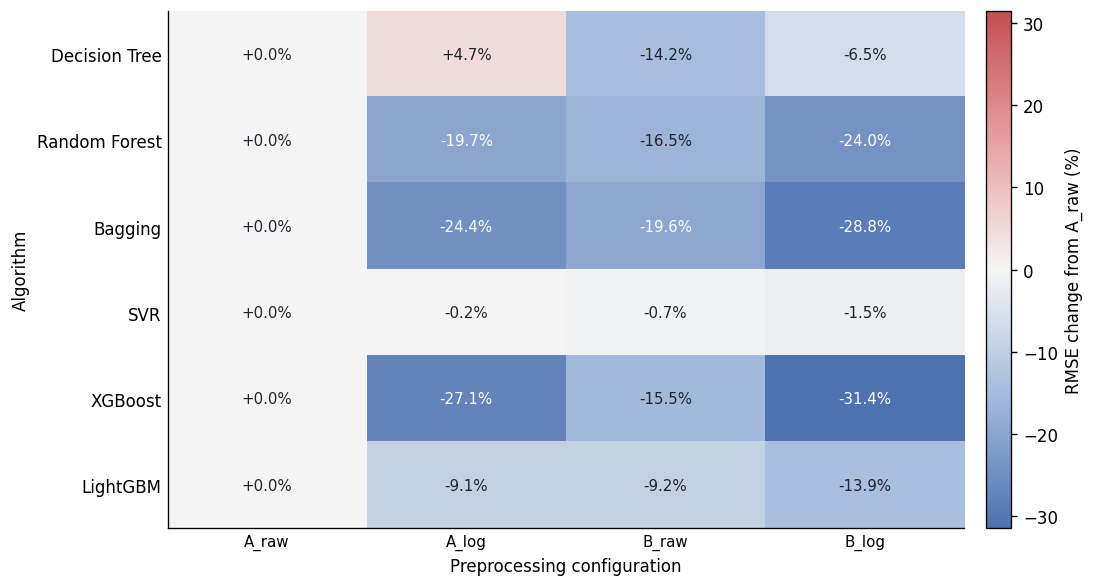

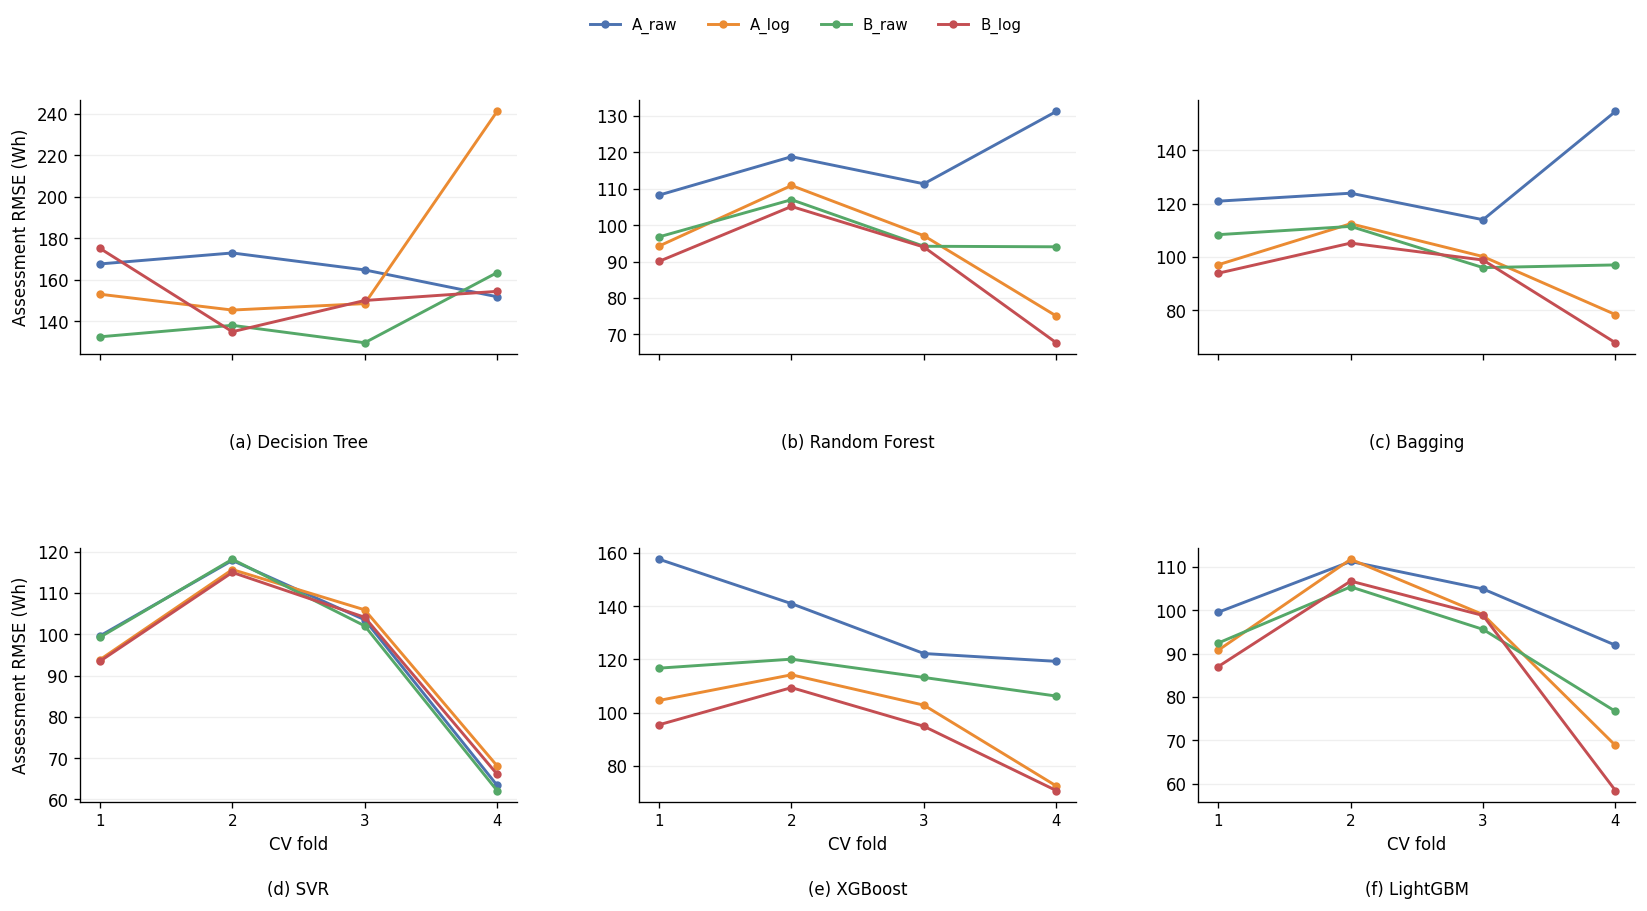

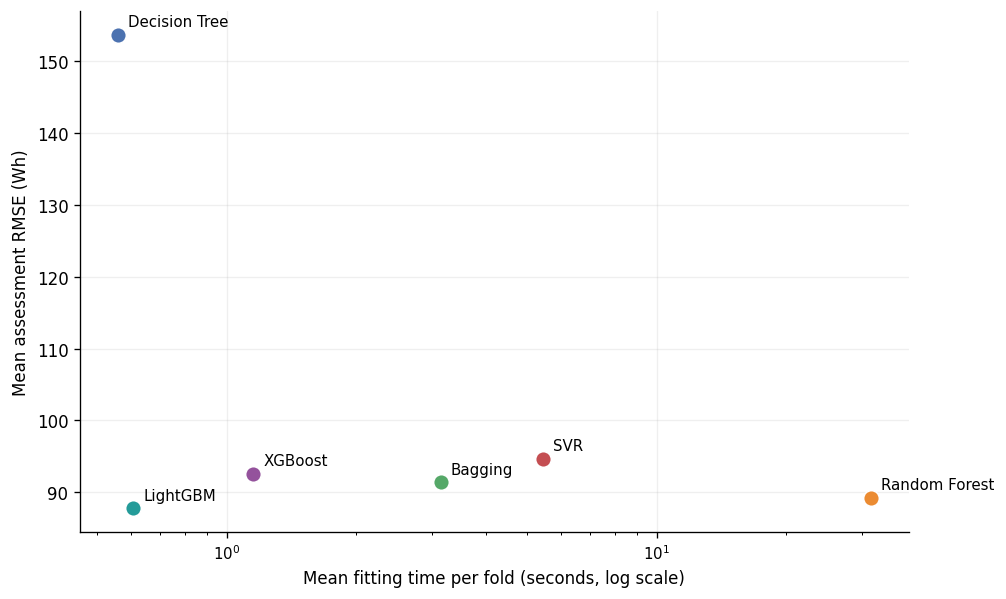


CELL 04C — BASELINE COMPARISON COMPLETED
Completed baseline fits: 96
Selected preprocessing: B_log
Total cumulative fit time: 705.27 seconds

Saved outputs:
- /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/baseline_screening/639561d42efc/reports/baseline_algorithm_configuration_summary.csv
- /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/baseline_screening/639561d42efc/reports/preprocessing_selection_comparison.csv
- /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/baseline_screening/639561d42efc/reports/baseline_preprocessing_selection.json
- /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/baseline_screening/639561d42efc/reports/04c_relative_rmse_heatmap.png
- /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/baseline_screening/639561d42efc/reports/04c_fold_rmse_profiles.png
- /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/baseline_screening/639561d42efc/reports/04c

In [7]:

# ============================================================
# NOTEBOOK 02 — CELL 04C
# BASELINE COMPARISON & PREPROCESSING SELECTION
# No model fitting
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.colors import (
    LinearSegmentedColormap,
    TwoSlopeNorm
)
from IPython.display import display

# ============================================================
# 1. PROJECT PATHS
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/Stability_Driven_Energy"
)

EXPERIMENT_ID = "639561d42efc"

RUN_DIR = (
    ROOT / "03_model_development"
    / "baseline_screening" / EXPERIMENT_ID
)

REPORT_DIR = RUN_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

METRIC_PATH = (
    RUN_DIR / "baseline_fold_metrics_progress.csv"
)

REG_PATH = RUN_DIR / "experiment_registration.json"

CV_DIR = ROOT / "09_experiment_metadata" / "cv_design"

PALETTE_PATH = (
    ROOT / "09_experiment_metadata"
    / "scientific_visualization_palette.json"
)

assert METRIC_PATH.is_file()
assert REG_PATH.is_file()


def read_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def file_hash(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


REG = read_json(REG_PATH)
assert REG["experiment_id"] == EXPERIMENT_ID

POLICY = REG["selection_policy"]

assert POLICY["reference_configuration"] == "A_raw"
assert float(
    POLICY["practical_tolerance_percentage_points"]
) == 1.0

# Verify that temporal CV definitions have not changed.
for key, filename in [
    ("cv_indices", "cv_fold_indices.npz"),
    ("cv_manifest", "cv_fold_manifest.csv")
]:
    assert REG["source_hashes"][key] == file_hash(
        CV_DIR / filename
    )

# ============================================================
# 2. SCIENTIFIC COLOR PALETTE
# ============================================================

if PALETTE_PATH.is_file():

    PALETTE = read_json(PALETTE_PATH)

else:

    PALETTE = {
        "qualitative": {
            "blue": "#4C72B0",
            "orange": "#EB8B32",
            "green": "#55A868",
            "red": "#C44E52",
            "purple": "#94529C",
            "brown": "#8C634D",
            "pink": "#EB74A9",
            "gray": "#858489",
            "yellow": "#E2C930",
            "teal": "#249B99"
        },
        "diverging_red_blue": [
            "#C44E52",
            "#E7A0A2",
            "#F5F5F5",
            "#A1B9DB",
            "#4C72B0"
        ]
    }

    with open(PALETTE_PATH, "w") as f:
        json.dump(PALETTE, f, indent=4)

Q = PALETTE["qualitative"]

CONFIG_COLORS = {
    "A_raw": Q["blue"],
    "A_log": Q["orange"],
    "B_raw": Q["green"],
    "B_log": Q["red"]
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# ============================================================
# 3. COMPLETE BASELINE INTEGRITY AUDIT
# ============================================================

df = pd.read_csv(METRIC_PATH)

ALGORITHMS = REG["algorithms"]
CONFIGS = list(REG["configurations"])

expected = {
    (algorithm, config, fold)
    for algorithm in ALGORITHMS
    for config in CONFIGS
    for fold in range(1, 5)
}

actual = set(zip(
    df["algorithm"],
    df["configuration"],
    df["fold"]
))

assert len(df) == 96
assert actual == expected

assert not df.duplicated([
    "algorithm", "configuration", "fold"
]).any()

assert (df["n_assessment"] == 1008).all()

for column in [
    "train_rmse_wh",
    "assessment_rmse_wh",
    "assessment_mae_wh",
    "assessment_r2",
    "fit_seconds"
]:
    assert np.isfinite(df[column]).all()

assert (df["assessment_rmse_wh"] > 0).all()
assert (df["fit_seconds"] >= 0).all()

print("=" * 70)
print("CELL 04C — BASELINE RESULTS AUDIT")
print("=" * 70)

print("Unique completed tasks:", len(df))
print("Algorithms:", len(ALGORITHMS))
print("Configurations:", len(CONFIGS))
print("CV folds: 4")
print("Integrity: PASS")

# ============================================================
# 4. AGGREGATE FOUR-FOLD RESULTS
# ============================================================

summary = (
    df.groupby(
        ["algorithm", "configuration"],
        as_index=False
    )
    .agg(
        mean_assessment_rmse_wh=(
            "assessment_rmse_wh", "mean"
        ),
        sd_assessment_rmse_wh=(
            "assessment_rmse_wh", "std"
        ),
        mean_train_rmse_wh=(
            "train_rmse_wh", "mean"
        ),
        mean_assessment_mae_wh=(
            "assessment_mae_wh", "mean"
        ),
        mean_assessment_r2=(
            "assessment_r2", "mean"
        ),
        mean_fit_seconds=(
            "fit_seconds", "mean"
        ),
        total_fit_seconds=(
            "fit_seconds", "sum"
        )
    )
)

reference = (
    summary[
        summary["configuration"] == "A_raw"
    ][["algorithm", "mean_assessment_rmse_wh"]]
    .rename(columns={
        "mean_assessment_rmse_wh":
            "reference_rmse_wh"
    })
)

summary = summary.merge(
    reference,
    on="algorithm",
    validate="many_to_one"
)

summary["relative_change_pct"] = 100 * (
    summary["mean_assessment_rmse_wh"]
    / summary["reference_rmse_wh"]
    - 1
)

rmse_matrix = summary.pivot(
    index="algorithm",
    columns="configuration",
    values="mean_assessment_rmse_wh"
).reindex(
    index=ALGORITHMS,
    columns=CONFIGS
)

print("\nA. MEAN ASSESSMENT RMSE (Wh)")
display(rmse_matrix.round(3))

# ============================================================
# 5. PRE-REGISTERED PREPROCESSING SELECTION
# ============================================================

selection_summary = (
    summary.groupby(
        "configuration",
        as_index=False
    )
    .agg(
        median_relative_change_pct=(
            "relative_change_pct", "median"
        ),
        mean_relative_change_pct=(
            "relative_change_pct", "mean"
        ),
        improved_models=(
            "relative_change_pct",
            lambda s: int((s < -1e-10).sum())
        ),
        maximum_relative_change_pct=(
            "relative_change_pct", "max"
        )
    )
)

best_median = (
    selection_summary[
        "median_relative_change_pct"
    ].min()
)

tolerance = float(
    POLICY["practical_tolerance_percentage_points"]
)

eligible = set(
    selection_summary.loc[
        selection_summary[
            "median_relative_change_pct"
        ] <= best_median + tolerance + 1e-10,
        "configuration"
    ]
)

SELECTED = next(
    config
    for config in POLICY["tie_break_preference"]
    if config in eligible
)

assert SELECTED in REG["configurations"]

print("\nB. PREPROCESSING SELECTION")

display(
    selection_summary.sort_values(
        "median_relative_change_pct"
    ).round(3)
)

print("Eligible configurations:", sorted(eligible))
print("Selected configuration:", SELECTED)

# ============================================================
# 6. SAVE COMPARISON AND DECISION
# ============================================================

SUMMARY_PATH = (
    REPORT_DIR /
    "baseline_algorithm_configuration_summary.csv"
)

SELECTION_TABLE_PATH = (
    REPORT_DIR /
    "preprocessing_selection_comparison.csv"
)

SELECTION_PATH = (
    REPORT_DIR /
    "baseline_preprocessing_selection.json"
)

summary.to_csv(
    SUMMARY_PATH, index=False
)

selection_summary.to_csv(
    SELECTION_TABLE_PATH, index=False
)

decision = {
    "experiment_id": EXPERIMENT_ID,
    "selected_configuration": SELECTED,

    "selected_feature_set":
        REG["configurations"][SELECTED]["feature_set"],

    "selected_target_transformation":
        REG["configurations"][SELECTED]["target"],

    "selection_source":
        "Training-only expanding-window CV",

    "selection_rule": POLICY,

    "best_median_relative_change_pct":
        float(best_median),

    "eligible_within_tolerance":
        sorted(eligible),

    "registration_sha256": file_hash(REG_PATH),

    "baseline_metrics_sha256": file_hash(METRIC_PATH),

    "fixed_validation_used": False,
    "test_used": False,
    "tuned_models_used": False,

    "interpretation_note": (
        "Selected using the pre-registered "
        "default-model screening protocol, "
        "not independent test evaluation."
    )
}

if SELECTION_PATH.is_file():

    previous = read_json(SELECTION_PATH)

    assert (
        previous["selected_configuration"]
        == SELECTED
    )

    assert (
        previous["baseline_metrics_sha256"]
        == file_hash(METRIC_PATH)
    )

else:

    with open(
        SELECTION_PATH,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            decision,
            f,
            indent=4,
            ensure_ascii=False
        )

# ============================================================
# 7. FIGURE SAVING HELPER
# ============================================================

def save_figure(fig, filename):

    for extension in ["png", "svg"]:

        fig.savefig(
            REPORT_DIR / f"{filename}.{extension}",
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()
    plt.close(fig)

# ============================================================
# 8. FIGURE 1 — RELATIVE RMSE HEATMAP
# ============================================================

heatmap = summary.pivot(
    index="algorithm",
    columns="configuration",
    values="relative_change_pct"
).reindex(
    index=ALGORITHMS,
    columns=CONFIGS
)

values = heatmap.to_numpy()

limit = max(
    1.0,
    float(np.max(np.abs(values)))
)

# Blue = RMSE improvement; red = deterioration.
cmap = LinearSegmentedColormap.from_list(
    "relative_rmse_diverging",
    list(reversed(
        PALETTE["diverging_red_blue"]
    ))
)

fig, ax = plt.subplots(figsize=(9.2, 5.0))

im = ax.imshow(
    values,
    cmap=cmap,
    norm=TwoSlopeNorm(
        vmin=-limit,
        vcenter=0,
        vmax=limit
    ),
    aspect="auto"
)

ax.set_xticks(
    range(len(CONFIGS)),
    CONFIGS
)

ax.set_yticks(
    range(len(ALGORITHMS)),
    ALGORITHMS
)

for i in range(values.shape[0]):

    for j in range(values.shape[1]):

        value = values[i, j]

        text_color = (
            "white"
            if abs(value) > 0.58 * limit
            else "#20242A"
        )

        ax.text(
            j, i,
            f"{value:+.1f}%",
            ha="center",
            va="center",
            fontsize=9,
            color=text_color
        )

ax.tick_params(length=0)

ax.set_xlabel("Preprocessing configuration")
ax.set_ylabel("Algorithm")

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.035,
    pad=0.025
)

cbar.set_label(
    "RMSE change from A_raw (%)"
)

fig.tight_layout()

save_figure(
    fig,
    "04c_relative_rmse_heatmap"
)

# ============================================================
# 9. FIGURE 2 — FOLD-LEVEL RMSE PROFILES
# ============================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(14.4, 7.6),
    sharex=True
)

for i, (ax, algorithm) in enumerate(
    zip(axes.flat, ALGORITHMS)
):

    for config in CONFIGS:

        subset = df[
            (df["algorithm"] == algorithm)
            & (df["configuration"] == config)
        ].sort_values("fold")

        ax.plot(
            subset["fold"],
            subset["assessment_rmse_wh"],
            marker="o",
            linewidth=1.75,
            markersize=4,
            color=CONFIG_COLORS[config],
            label=config
        )

    ax.set_xticks([1, 2, 3, 4])

    ax.grid(
        axis="y",
        alpha=0.20
    )

    if i % 3 == 0:
        ax.set_ylabel("Assessment RMSE (Wh)")

    if i >= 3:
        ax.set_xlabel("CV fold")

    # Subfigure captions beneath each panel.
    ax.text(
        0.5,
        -0.31,
        f"({chr(97 + i)}) {algorithm}",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=10
    )

handles, labels = (
    axes.flat[0].get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    ncol=4,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    frameon=False
)

fig.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.89,
    bottom=0.12,
    hspace=0.76,
    wspace=0.28
)

save_figure(
    fig,
    "04c_fold_rmse_profiles"
)

# ============================================================
# 10. FIGURE 3 — ACCURACY VS COMPUTATIONAL COST
# ============================================================

selected_summary = summary[
    summary["configuration"] == SELECTED
].copy()

MODEL_COLORS = dict(zip(
    ALGORITHMS,
    [
        Q["blue"],
        Q["orange"],
        Q["green"],
        Q["red"],
        Q["purple"],
        Q["teal"]
    ]
))

fig, ax = plt.subplots(
    figsize=(8.5, 5.1)
)

for _, row in selected_summary.iterrows():

    algorithm = row["algorithm"]

    x = row["mean_fit_seconds"]
    y = row["mean_assessment_rmse_wh"]

    ax.scatter(
        x, y,
        s=88,
        color=MODEL_COLORS[algorithm],
        edgecolor="white",
        linewidth=0.9,
        zorder=3
    )

    ax.annotate(
        algorithm,
        xy=(x, y),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=9
    )

ax.set_xscale("log")

ax.set_xlabel(
    "Mean fitting time per fold (seconds, log scale)"
)

ax.set_ylabel(
    "Mean assessment RMSE (Wh)"
)

ax.grid(alpha=0.20)
ax.set_axisbelow(True)

fig.tight_layout()

save_figure(
    fig,
    "04c_default_accuracy_vs_fit_time"
)

# ============================================================
# 11. FINAL CHECKPOINT
# ============================================================

print("\n" + "=" * 70)
print("CELL 04C — BASELINE COMPARISON COMPLETED")
print("=" * 70)

print("Completed baseline fits:", len(df))
print("Selected preprocessing:", SELECTED)

print(
    "Total cumulative fit time:",
    round(df["fit_seconds"].sum(), 2),
    "seconds"
)

print("\nSaved outputs:")
print("-", SUMMARY_PATH)
print("-", SELECTION_TABLE_PATH)
print("-", SELECTION_PATH)
print("-", REPORT_DIR / "04c_relative_rmse_heatmap.png")
print("-", REPORT_DIR / "04c_fold_rmse_profiles.png")
print("-", REPORT_DIR / "04c_default_accuracy_vs_fit_time.png")

print("\nAll figures also saved as SVG.")
print("No new model fitted.")
print("No fixed validation/test accessed.")


Saved: /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/baseline_screening/639561d42efc/reports/04c_default_accuracy_vs_fit_time.png
Saved: /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/baseline_screening/639561d42efc/reports/04c_default_accuracy_vs_fit_time.svg


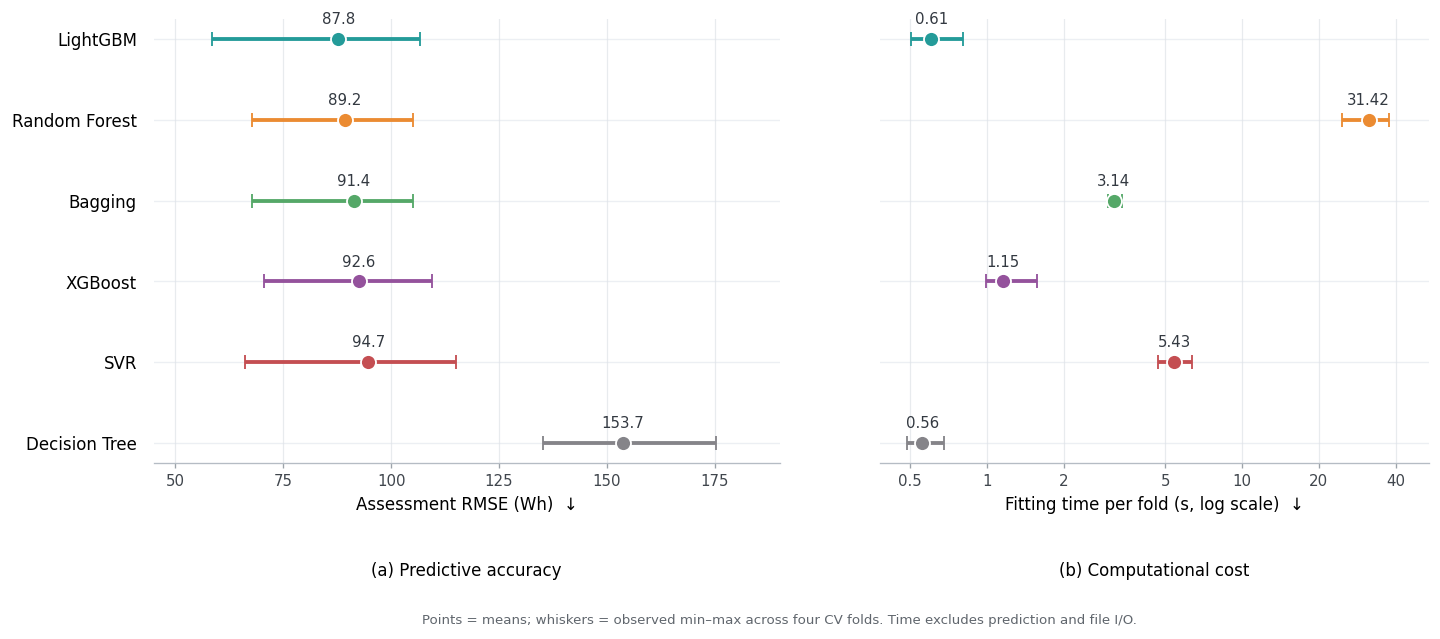


Visualization successfully revised.
Selected preprocessing: B_log
Algorithms: 6
CV folds per algorithm: 4
No model retraining performed.


In [8]:

# ============================================================
# NOTEBOOK 02 — CELL 04D
# REVISED BASELINE ACCURACY–COMPUTATIONAL COST FIGURE
# No model fitting
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from pathlib import Path

# ------------------------------------------------------------
# 1. Project files
# ------------------------------------------------------------

ROOT = Path(
    "/content/drive/MyDrive/Stability_Driven_Energy"
)

EXPERIMENT_ID = "639561d42efc"

RUN_DIR = (
    ROOT / "03_model_development"
    / "baseline_screening" / EXPERIMENT_ID
)

REPORT_DIR = RUN_DIR / "reports"

METRIC_PATH = (
    RUN_DIR / "baseline_fold_metrics_progress.csv"
)

SELECTION_PATH = (
    REPORT_DIR / "baseline_preprocessing_selection.json"
)

PALETTE_PATH = (
    ROOT / "09_experiment_metadata"
    / "scientific_visualization_palette.json"
)

for path in [
    METRIC_PATH,
    SELECTION_PATH,
    PALETTE_PATH
]:
    assert path.is_file(), f"Missing file: {path}"

with open(SELECTION_PATH, encoding="utf-8") as f:
    selection = json.load(f)

with open(PALETTE_PATH, encoding="utf-8") as f:
    palette = json.load(f)

selected_config = selection["selected_configuration"]

assert selected_config == "B_log"

# ------------------------------------------------------------
# 2. Read actual fold-level results
# ------------------------------------------------------------

df = pd.read_csv(METRIC_PATH)

current = df.loc[
    df["configuration"] == selected_config
].copy()

assert len(current) == 24
assert current["algorithm"].nunique() == 6

assert not current.duplicated(
    ["algorithm", "fold"]
).any()

assert current.groupby("algorithm")["fold"].apply(
    lambda x: set(x) == {1, 2, 3, 4}
).all()

assert np.isfinite(
    current[
        ["assessment_rmse_wh", "fit_seconds"]
    ].to_numpy()
).all()

# ------------------------------------------------------------
# 3. Aggregate mean and observed range
# ------------------------------------------------------------

plot_data = (
    current.groupby("algorithm")
    .agg(
        rmse_mean=("assessment_rmse_wh", "mean"),
        rmse_min=("assessment_rmse_wh", "min"),
        rmse_max=("assessment_rmse_wh", "max"),

        time_mean=("fit_seconds", "mean"),
        time_min=("fit_seconds", "min"),
        time_max=("fit_seconds", "max")
    )
    .sort_values("rmse_mean")
    .reset_index()
)

# ------------------------------------------------------------
# 4. Scientific qualitative palette
# ------------------------------------------------------------

Q = palette["qualitative"]

MODEL_COLORS = {
    "Decision Tree": Q["gray"],
    "Random Forest": Q["orange"],
    "Bagging": Q["green"],
    "SVR": Q["red"],
    "XGBoost": Q["purple"],
    "LightGBM": Q["teal"]
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# ------------------------------------------------------------
# 5. Create aligned point-range plots
# ------------------------------------------------------------

fig, (ax_rmse, ax_time) = plt.subplots(
    1, 2,
    figsize=(13.2, 5.7),
    sharey=True,
    gridspec_kw={
        "width_ratios": [1.14, 1],
        "wspace": 0.17
    }
)

for i, row in plot_data.iterrows():

    algorithm = row["algorithm"]
    color = MODEL_COLORS[algorithm]

    # Subtle horizontal reference guides
    for ax in [ax_rmse, ax_time]:
        ax.axhline(
            i,
            color="#ECEFF3",
            linewidth=0.8,
            zorder=0
        )

    # ----------------------------------------
    # (a) Assessment RMSE
    # ----------------------------------------

    ax_rmse.errorbar(
        row["rmse_mean"],
        i,
        xerr=[
            [row["rmse_mean"] - row["rmse_min"]],
            [row["rmse_max"] - row["rmse_mean"]]
        ],
        fmt="o",
        markersize=9,
        capsize=4,
        capthick=1.6,
        elinewidth=2.3,
        color=color,
        markeredgecolor="white",
        markeredgewidth=1.1,
        zorder=4
    )

    ax_rmse.annotate(
        f"{row['rmse_mean']:.1f}",
        xy=(row["rmse_mean"], i),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color="#333941",
        fontweight="medium"
    )

    # ----------------------------------------
    # (b) Fitting time
    # ----------------------------------------

    ax_time.errorbar(
        row["time_mean"],
        i,
        xerr=[
            [row["time_mean"] - row["time_min"]],
            [row["time_max"] - row["time_mean"]]
        ],
        fmt="o",
        markersize=9,
        capsize=4,
        capthick=1.6,
        elinewidth=2.3,
        color=color,
        markeredgecolor="white",
        markeredgewidth=1.1,
        zorder=4
    )

    ax_time.annotate(
        f"{row['time_mean']:.2f}",
        xy=(row["time_mean"], i),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color="#333941",
        fontweight="medium"
    )

# ------------------------------------------------------------
# 6. Axis formatting
# ------------------------------------------------------------

ax_rmse.set_yticks(
    range(len(plot_data))
)

ax_rmse.set_yticklabels(
    plot_data["algorithm"].tolist()
)

ax_rmse.invert_yaxis()

ax_rmse.tick_params(
    axis="y",
    length=0,
    pad=10
)

ax_rmse.set_xlim(45, 190)

ax_rmse.set_xticks([
    50, 75, 100, 125, 150, 175
])

ax_rmse.set_xlabel(
    "Assessment RMSE (Wh)  ↓"
)

# Log axis preserves visibility of both
# fast and computationally expensive models.

ax_time.set_xscale("log")
ax_time.set_xlim(0.38, 54)

ax_time.set_xticks([
    0.5, 1, 2, 5, 10, 20, 40
])

ax_time.set_xticklabels([
    "0.5", "1", "2", "5", "10", "20", "40"
])

ax_time.xaxis.set_minor_locator(
    ticker.NullLocator()
)

ax_time.tick_params(
    axis="y",
    which="both",
    left=False,
    labelleft=False
)

ax_time.set_xlabel(
    "Fitting time per fold (s, log scale)  ↓"
)

for ax in [ax_rmse, ax_time]:

    ax.grid(
        axis="x",
        color="#DFE3E8",
        alpha=0.70,
        linewidth=0.75
    )

    ax.set_axisbelow(True)

    ax.spines["left"].set_visible(False)

    ax.spines["bottom"].set_color(
        "#B5BCC4"
    )

    ax.tick_params(
        axis="x",
        length=3,
        color="#9CA3AA",
        labelcolor="#40464D"
    )

# ------------------------------------------------------------
# 7. Panel captions and notes
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.165,
    right=0.97,
    top=0.93,
    bottom=0.28
)

pos_a = ax_rmse.get_position()
pos_b = ax_time.get_position()

fig.text(
    (pos_a.x0 + pos_a.x1) / 2,
    0.115,
    "(a) Predictive accuracy",
    ha="center",
    fontsize=10
)

fig.text(
    (pos_b.x0 + pos_b.x1) / 2,
    0.115,
    "(b) Computational cost",
    ha="center",
    fontsize=10
)

fig.text(
    0.56,
    0.045,
    (
        "Points = means; whiskers = observed min–max "
        "across four CV folds. "
        "Time excludes prediction and file I/O."
    ),
    ha="center",
    fontsize=8,
    color="#60666D"
)

# ------------------------------------------------------------
# 8. Save revised figure
# ------------------------------------------------------------

OUTPUT_NAME = (
    "04c_default_accuracy_vs_fit_time"
)

for extension in ["png", "svg"]:

    output_path = (
        REPORT_DIR /
        f"{OUTPUT_NAME}.{extension}"
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    print("Saved:", output_path)

plt.show()
plt.close(fig)

print("\nVisualization successfully revised.")
print("Selected preprocessing:", selected_config)
print("Algorithms:", len(plot_data))
print("CV folds per algorithm: 4")
print("No model retraining performed.")


# Freeze Grid Search Specification

In [9]:

# ================================================================
# NOTEBOOK 02 — CELL 05
# HYPERPARAMETER GRID SPECIFICATION & COMPUTATIONAL BUDGET
#
# Selected preprocessing : B_log
# Search method           : Staged exhaustive ParameterGrid
# Validation              : 4 expanding-window CV folds
# Selection metric        : Assessment RMSE (original Wh)
# Model fitting           : NOT performed in this cell
# ================================================================

import json
import hashlib
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    BaggingRegressor
)
from sklearn.svm import SVR

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from IPython.display import display

# ================================================================
# 1. PATHS AND PREVIOUS EXPERIMENT
# ================================================================

ROOT = Path(
    "/content/drive/MyDrive/Stability_Driven_Energy"
)

META_DIR = ROOT / "09_experiment_metadata"

BASELINE_ID = "639561d42efc"

BASELINE_DIR = (
    ROOT / "03_model_development"
    / "baseline_screening" / BASELINE_ID
)

BASELINE_REG_PATH = (
    BASELINE_DIR / "experiment_registration.json"
)

BASELINE_METRIC_PATH = (
    BASELINE_DIR / "baseline_fold_metrics_progress.csv"
)

SELECTION_PATH = (
    BASELINE_DIR / "reports"
    / "baseline_preprocessing_selection.json"
)

MODEL_SPEC_PATH = (
    META_DIR / "model_specification"
    / "model_implementation_specification.json"
)

CV_INDEX_PATH = (
    META_DIR / "cv_design" / "cv_fold_indices.npz"
)

CV_MANIFEST_PATH = (
    META_DIR / "cv_design" / "cv_fold_manifest.csv"
)

PREP_PATH = (
    META_DIR / "notebook01_preprocessing_strategy.json"
)

SPLIT_PATH = (
    META_DIR / "notebook02_chronological_split.json"
)


def read_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def canonical_json(obj):
    return json.dumps(
        obj,
        sort_keys=True,
        separators=(",", ":"),
        ensure_ascii=False
    )


required_files = [
    BASELINE_REG_PATH,
    BASELINE_METRIC_PATH,
    SELECTION_PATH,
    MODEL_SPEC_PATH,
    CV_INDEX_PATH,
    CV_MANIFEST_PATH,
    PREP_PATH,
    SPLIT_PATH
]

for path in required_files:
    assert path.is_file(), f"Missing: {path}"

baseline_reg = read_json(BASELINE_REG_PATH)
selection = read_json(SELECTION_PATH)
model_spec = read_json(MODEL_SPEC_PATH)
prep = read_json(PREP_PATH)
split = read_json(SPLIT_PATH)

# ================================================================
# 2. VERIFY SELECTED PREPROCESSING AND DATA INTEGRITY
# ================================================================

SELECTED = selection["selected_configuration"]

assert SELECTED == "B_log"
assert selection["selected_feature_set"] == "B"

assert (
    selection["selected_target_transformation"]
    == "log1p"
)

assert (
    selection["registration_sha256"]
    == sha256_file(BASELINE_REG_PATH)
)

assert (
    selection["baseline_metrics_sha256"]
    == sha256_file(BASELINE_METRIC_PATH)
)

assert (
    baseline_reg["source_hashes"]["cv_indices"]
    == sha256_file(CV_INDEX_PATH)
)

assert (
    baseline_reg["source_hashes"]["cv_manifest"]
    == sha256_file(CV_MANIFEST_PATH)
)

FEATURE_B = prep["feature_sets"]["B"]

assert len(FEATURE_B) == 27
assert "time_sin" in FEATURE_B
assert "time_cos" in FEATURE_B

assert split["counts"]["train"] == 11850

with np.load(CV_INDEX_PATH) as indices:
    assert len(indices.files) == 8

baseline = pd.read_csv(BASELINE_METRIC_PATH)

assert len(baseline) == 96

selected_baseline = baseline[
    baseline["configuration"] == SELECTED
].copy()

assert len(selected_baseline) == 24

assert (
    selected_baseline.groupby("algorithm")["fold"]
    .nunique()
    .eq(4)
    .all()
)

# ================================================================
# 3. VERIFY SOFTWARE VERSIONS
# ================================================================

CURRENT_VERSIONS = {
    "scikit_learn": version("scikit-learn"),
    "xgboost": version("xgboost"),
    "lightgbm": version("lightgbm")
}

for package, actual in CURRENT_VERSIONS.items():

    expected = model_spec[
        "software_versions"
    ][package]

    assert actual == expected, (
        f"Package version changed: {package}. "
        f"Expected {expected}; found {actual}."
    )

SEED = 42
N_JOBS = 1
N_FOLDS = 4

ALGORITHMS = list(baseline_reg["algorithms"])

assert ALGORITHMS == [
    "Decision Tree",
    "Random Forest",
    "Bagging",
    "SVR",
    "XGBoost",
    "LightGBM"
]

print("=" * 72)
print("CELL 05 — HYPERPARAMETER GRID SPECIFICATION")
print("=" * 72)

print("Selected preprocessing:", SELECTED)
print("Feature count:", len(FEATURE_B))
print("Target transformation: log1p")
print("Metric scale: Wh")
print("CV folds:", N_FOLDS)
print("Software versions: VERIFIED")
print("Baseline integrity: VERIFIED")

# ================================================================
# 4. UNFITTED MODEL FACTORIES
# ================================================================

def make_tuned_estimator(algorithm):

    if algorithm == "Decision Tree":
        return DecisionTreeRegressor(
            random_state=SEED
        )

    if algorithm == "Random Forest":
        return RandomForestRegressor(
            random_state=SEED,
            n_jobs=N_JOBS
        )

    if algorithm == "Bagging":

        # Explicit base estimator is necessary
        # for tuning nested tree complexity.

        base_tree = DecisionTreeRegressor(
            random_state=SEED
        )

        return BaggingRegressor(
            estimator=base_tree,
            random_state=SEED,
            n_jobs=N_JOBS
        )

    if algorithm == "SVR":
        return SVR()

    if algorithm == "XGBoost":
        return XGBRegressor(
            random_state=SEED,
            n_jobs=N_JOBS
        )

    if algorithm == "LightGBM":
        return LGBMRegressor(
            random_state=SEED,
            n_jobs=N_JOBS
        )

    raise ValueError(algorithm)


def make_tuned_blueprint(algorithm):

    estimator = make_tuned_estimator(algorithm)

    preprocessor = (
        StandardScaler()
        if algorithm == "SVR"
        else "passthrough"
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    return TransformedTargetRegressor(
        regressor=pipeline,
        func=np.log1p,
        inverse_func=np.expm1,
        check_inverse=True
    )


PARAM_PREFIX = "regressor__model__"

# ================================================================
# 5. STAGE 1 — STRUCTURE AND CORE PARAMETERS
# ================================================================

# All ranges are frozen before tuning.
# Values are defined in their native sklearn parameter names.

STAGE1_GRIDS = {

    "Decision Tree": {
        "max_depth": [6, 12, 24, None],
        "min_samples_leaf": [1, 5, 20],
        "min_samples_split": [2, 10]
    },

    "Random Forest": {
        "n_estimators": [100],
        "max_depth": [12, None],
        "min_samples_leaf": [1, 5, 20],
        "max_features": [0.5, 1.0]
    },

    "Bagging": {
        "n_estimators": [30],
        "max_samples": [0.7, 1.0],
        "estimator__max_depth": [12, None],
        "estimator__min_samples_leaf": [1, 10]
    },

    "SVR": {
        "C": [0.1, 1.0, 10.0],
        "epsilon": [0.01, 0.1, 0.3],
        "gamma": [0.01, "scale", 0.1]
    },

    "XGBoost": {
        "n_estimators": [150, 500],
        "learning_rate": [0.03, 0.1],
        "max_depth": [3, 6, 9],
        "min_child_weight": [1, 5]
    },

    "LightGBM": {
        "n_estimators": [150, 500],
        "learning_rate": [0.03, 0.1],
        "num_leaves": [15, 31, 63],
        "min_child_samples": [10, 40]
    }
}

# ================================================================
# 6. STAGE 2 — CONDITIONAL EXTENSION RULES
# ================================================================

# Stage 2 begins only AFTER all Stage 1 CV scores
# for the relevant algorithm are complete.
#
# Select the TWO best Stage 1 configurations by
# mean assessment RMSE. Then test these extensions.
#
# Each extension changes only the named parameters.
# Remaining Stage 1 parameters are retained.

STAGE2_RULES = {

    "Random Forest": {
        "top_k_from_stage1": 2,
        "extensions": [
            {"n_estimators": 200},
            {"n_estimators": 350}
        ]
    },

    "Bagging": {
        "top_k_from_stage1": 2,
        "extensions": [
            {"n_estimators": 100},
            {"n_estimators": 200}
        ]
    },

    "XGBoost": {
        "top_k_from_stage1": 2,
        "extensions": [
            {
                "subsample": 0.7,
                "colsample_bytree": 1.0
            },
            {
                "subsample": 1.0,
                "colsample_bytree": 0.7
            },
            {
                "subsample": 0.7,
                "colsample_bytree": 0.7
            }
        ]
    },

    "LightGBM": {
        "top_k_from_stage1": 2,
        "extensions": [
            {
                "subsample": 0.8,
                "subsample_freq": 1,
                "colsample_bytree": 1.0
            },
            {
                "subsample": 1.0,
                "subsample_freq": 0,
                "colsample_bytree": 0.7
            },
            {
                "subsample": 0.8,
                "subsample_freq": 1,
                "colsample_bytree": 0.7
            }
        ]
    }
}

# Validate LightGBM sampling logic.
for extension in STAGE2_RULES["LightGBM"][
    "extensions"
]:

    if extension["subsample"] < 1:
        assert extension["subsample_freq"] > 0

    else:
        assert extension["subsample_freq"] == 0

# ================================================================
# 7. GENERATE AND VALIDATE ALL STAGE 1 CANDIDATES
# ================================================================

stage1_records = []
budget_records = []

EXPECTED_STAGE1 = {
    "Decision Tree": 24,
    "Random Forest": 12,
    "Bagging": 8,
    "SVR": 27,
    "XGBoost": 24,
    "LightGBM": 24
}

EXPECTED_STAGE2 = {
    "Decision Tree": 0,
    "Random Forest": 4,
    "Bagging": 4,
    "SVR": 0,
    "XGBoost": 6,
    "LightGBM": 6
}

for algorithm in ALGORITHMS:

    blueprint = make_tuned_blueprint(algorithm)
    valid_params = blueprint.get_params(deep=True)

    candidates = list(
        ParameterGrid(STAGE1_GRIDS[algorithm])
    )

    assert len(candidates) == (
        EXPECTED_STAGE1[algorithm]
    )

    # Detect repeated parameter combinations.
    signatures = [
        canonical_json(candidate)
        for candidate in candidates
    ]

    assert len(set(signatures)) == len(signatures)

    for candidate_number, params in enumerate(
        candidates, start=1
    ):

        # Convert native keys into nested pipeline keys.
        full_params = {
            PARAM_PREFIX + key: value
            for key, value in params.items()
        }

        # Every parameter must exist in this exact model.
        for key in full_params:
            assert key in valid_params, (
                f"{algorithm}: invalid parameter {key}"
            )

        # Verify parameters can actually be assigned.
        probe = clone(blueprint)
        probe.set_params(**full_params)

        assigned = probe.get_params(deep=True)

        for key, value in full_params.items():
            assert assigned[key] == value

        candidate_signature = canonical_json({
            "algorithm": algorithm,
            "stage": 1,
            "params": params
        })

        short_hash = hashlib.sha256(
            candidate_signature.encode("utf-8")
        ).hexdigest()[:8]

        slug = (
            algorithm.lower()
            .replace(" ", "_")
        )

        candidate_id = (
            f"{slug}_s1_"
            f"{candidate_number:03d}_"
            f"{short_hash}"
        )

        stage1_records.append({
            "candidate_id": candidate_id,
            "algorithm": algorithm,
            "stage": 1,

            "parameters_json": canonical_json(
                params
            ),

            "pipeline_parameters_json":
                canonical_json(full_params),

            "n_cv_folds": N_FOLDS,
            "planned_fits": N_FOLDS
        })

    n_stage1 = len(candidates)

    if algorithm in STAGE2_RULES:

        rule = STAGE2_RULES[algorithm]

        n_stage2 = (
            rule["top_k_from_stage1"]
            * len(rule["extensions"])
        )

        # Validate that Stage 2 parameter paths exist.
        for extension in rule["extensions"]:

            full_extension = {
                PARAM_PREFIX + key: value
                for key, value in extension.items()
            }

            probe = clone(blueprint)

            for key in full_extension:
                assert key in valid_params

            probe.set_params(**full_extension)

    else:
        n_stage2 = 0

    assert n_stage2 == EXPECTED_STAGE2[algorithm]

    budget_records.append({
        "algorithm": algorithm,
        "stage1_configurations": n_stage1,
        "stage2_new_configurations": n_stage2,
        "total_configurations": (
            n_stage1 + n_stage2
        ),
        "stage1_cv_fits": n_stage1 * N_FOLDS,
        "stage2_cv_fits": n_stage2 * N_FOLDS,
        "total_cv_fits": (
            (n_stage1 + n_stage2) * N_FOLDS
        )
    })

stage1_manifest = pd.DataFrame(stage1_records)

budget = pd.DataFrame(budget_records)

assert len(stage1_manifest) == 119

assert budget["stage1_cv_fits"].sum() == 476
assert budget["stage2_cv_fits"].sum() == 80
assert budget["total_cv_fits"].sum() == 556

print("\nA. GRID SEARCH COMPUTATIONAL BUDGET")

display(budget)

print("Stage 1 configurations:", 119)
print("Stage 2 planned configurations:", 20)
print("Total unique configurations:", 139)
print("Total planned CV fits:", 556)

# ================================================================
# 8. OBSERVED BASELINE FITTING TIMES
# ================================================================

# These are measured baseline times.
# They are NOT forecasts of tuned-model runtimes.

baseline_timing = (
    selected_baseline.groupby("algorithm")
    .agg(
        baseline_mean_fit_seconds=(
            "fit_seconds", "mean"
        ),
        baseline_total_fit_seconds=(
            "fit_seconds", "sum"
        ),
        baseline_mean_cv_rmse_wh=(
            "assessment_rmse_wh", "mean"
        )
    )
    .reset_index()
)

budget = budget.merge(
    baseline_timing,
    on="algorithm",
    validate="one_to_one"
)

print("\nB. BASELINE COMPUTATIONAL REFERENCE")

display(
    budget[[
        "algorithm",
        "total_cv_fits",
        "baseline_mean_fit_seconds",
        "baseline_mean_cv_rmse_wh"
    ]].round(3)
)

print(
    "\nNote: tuned-model runtime must be measured, "
    "not inferred directly from baseline time."
)

# ================================================================
# 9. FREEZE MODEL SELECTION AND TIMING POLICY
# ================================================================

TUNING_POLICY = {

    "search_method": "Two-stage ParameterGrid",

    "cv_method": "4-fold expanding-window",

    "primary_metric": "Mean assessment RMSE in Wh",

    "stage1_selection": {
        "criterion": "Lowest mean CV assessment RMSE",
        "top_k": 2,
        "tie_break": [
            "Lower mean CV fitting time",
            "Lexicographic candidate_id"
        ]
    },

    "final_selection": {
        "candidate_pool": (
            "All Stage 1 and completed Stage 2 candidates"
        ),

        "best_rmse_definition": (
            "Minimum four-fold mean assessment RMSE"
        ),

        "practical_tolerance_fraction": 0.01,

        "eligible_rule": (
            "mean_cv_rmse <= best_mean_cv_rmse * 1.01"
        ),

        "within_eligible_candidates": [
            "Lowest mean CV fitting time",
            "Lowest mean CV assessment RMSE",
            "Lexicographic candidate_id"
        ],

        "statistical_equivalence_claim": False
    },

    "metrics_per_fold": [
        "train_rmse_wh",
        "assessment_rmse_wh",
        "train_mae_wh",
        "assessment_mae_wh",
        "train_r2",
        "assessment_r2",
        "rmse_gap_wh"
    ],

    "computational_measurements": [
        "fit_seconds",
        "train_predict_seconds",
        "assessment_predict_seconds",
        "candidate_total_cv_fit_seconds",
        "candidate_mean_cv_fit_seconds",
        "stage_wall_clock_seconds",
        "full_search_wall_clock_seconds"
    ],

    "reproducibility": {
        "seed": SEED,
        "estimator_n_jobs": N_JOBS,
        "cv_parallel_jobs": 1,
        "same_fold_indices": True,
        "same_feature_set": True,
        "early_stopping": False,
        "failed_fit_policy": "Stop and audit",
        "checkpoint_frequency": "Every completed fold"
    },

    "data_usage": {
        "training_cv": True,
        "fixed_validation": False,
        "final_test": False
    },

    "future_diagnostics": {
        "boosting_iteration_histories": True,
        "train_assessment_error_curves": True,
        "model_complexity_diagnostics": True,
        "per_fold_prediction_storage": True,
        "all_metrics_evaluated_in_wh": True
    }
}

# ================================================================
# 10. FREEZE PLAN USING A REPRODUCIBLE FINGERPRINT
# ================================================================

PLAN = {

    "notebook": "02_Model_Development",
    "cell": "05_Hyperparameter_Grid_Specification",

    "plan_version": "staged_grid_v1",

    "selected_configuration": SELECTED,
    "feature_set": "B",
    "n_features": len(FEATURE_B),

    "target_transform": "log1p",
    "inverse_transform": "expm1",

    "cv_folds": N_FOLDS,

    "baseline_experiment_id": BASELINE_ID,

    "source_fingerprints": {
        "baseline_registration": sha256_file(
            BASELINE_REG_PATH
        ),
        "baseline_metrics": sha256_file(
            BASELINE_METRIC_PATH
        ),
        "preprocessing_selection": sha256_file(
            SELECTION_PATH
        ),
        "cv_indices": sha256_file(
            CV_INDEX_PATH
        ),
        "cv_manifest": sha256_file(
            CV_MANIFEST_PATH
        ),
        "feature_specification": sha256_file(
            PREP_PATH
        )
    },

    "software_versions": CURRENT_VERSIONS,

    "stage1_grids": STAGE1_GRIDS,
    "stage2_rules": STAGE2_RULES,

    "selection_and_timing_policy": TUNING_POLICY,

    "computational_budget": {
        "stage1_configurations": 119,
        "stage2_configurations": 20,
        "total_configurations": 139,
        "stage1_fits": 476,
        "stage2_fits": 80,
        "total_fits": 556
    },

    "model_fitting_performed": False
}

PLAN_ID = hashlib.sha256(
    canonical_json(PLAN).encode("utf-8")
).hexdigest()[:12]

TUNING_DIR = (
    ROOT / "03_model_development"
    / "grid_search" / PLAN_ID
)

STAGE1_DIR = TUNING_DIR / "stage1"
STAGE2_DIR = TUNING_DIR / "stage2"
TUNING_REPORT_DIR = TUNING_DIR / "reports"

for folder in [
    STAGE1_DIR,
    STAGE2_DIR,
    TUNING_REPORT_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

PLAN_PATH = (
    TUNING_DIR / "tuning_grid_specification.json"
)

MANIFEST_PATH = (
    TUNING_DIR / "tuning_stage1_manifest.csv"
)

BUDGET_PATH = (
    TUNING_DIR / "tuning_computational_budget.csv"
)

# Do not silently overwrite a different registered plan.
if PLAN_PATH.is_file():

    previous_plan = read_json(PLAN_PATH)

    assert previous_plan == PLAN, (
        "Existing tuning plan differs. "
        "Do not overwrite the registered experiment."
    )

else:

    with open(
        PLAN_PATH,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            PLAN,
            f,
            indent=4,
            ensure_ascii=False
        )

if MANIFEST_PATH.is_file():

    old_manifest = pd.read_csv(MANIFEST_PATH)

    pd.testing.assert_frame_equal(
        old_manifest,
        stage1_manifest,
        check_dtype=False
    )

else:

    stage1_manifest.to_csv(
        MANIFEST_PATH,
        index=False
    )

if BUDGET_PATH.is_file():

    old_budget = pd.read_csv(BUDGET_PATH)

    pd.testing.assert_frame_equal(
        old_budget,
        budget,
        check_dtype=False,
        rtol=1e-8,
        atol=1e-8
    )

else:

    budget.to_csv(
        BUDGET_PATH,
        index=False
    )

# ================================================================
# 11. FINAL CHECKPOINT
# ================================================================

print("\n" + "=" * 72)
print("CELL 05 — GRID SPECIFICATION COMPLETED")
print("=" * 72)

print("Tuning Plan ID:", PLAN_ID)
print("Preprocessing:", SELECTED)
print("Algorithms:", len(ALGORITHMS))

print("\nStage 1 candidates:", len(stage1_manifest))
print("Stage 1 fitting budget:", 476)
print("Stage 2 new candidates:", 20)
print("Stage 2 fitting budget:", 80)
print("Total fitting budget:", 556)

print("\nGrid audit: PASS")
print("Nested parameter paths: PASS")
print("LightGBM sampling pairs: PASS")
print("Software versions: PASS")
print("Experimental plan frozen: YES")

print("\nSaved artifacts:")
print("-", PLAN_PATH)
print("-", MANIFEST_PATH)
print("-", BUDGET_PATH)

print("\nNo model fitted.")
print("No Grid Search executed.")
print("No fixed validation or test accessed.")


CELL 05 — HYPERPARAMETER GRID SPECIFICATION
Selected preprocessing: B_log
Feature count: 27
Target transformation: log1p
Metric scale: Wh
CV folds: 4
Software versions: VERIFIED
Baseline integrity: VERIFIED

A. GRID SEARCH COMPUTATIONAL BUDGET


,algorithm,stage1_configurations,stage2_new_configurations,total_configurations,stage1_cv_fits,stage2_cv_fits,total_cv_fits
0,Decision Tree,24,0,24,96,0,96
1,Random Forest,12,4,16,48,16,64
2,Bagging,8,4,12,32,16,48
3,SVR,27,0,27,108,0,108
4,XGBoost,24,6,30,96,24,120
5,LightGBM,24,6,30,96,24,120


Stage 1 configurations: 119
Stage 2 planned configurations: 20
Total unique configurations: 139
Total planned CV fits: 556

B. BASELINE COMPUTATIONAL REFERENCE


,algorithm,total_cv_fits,baseline_mean_fit_seconds,baseline_mean_cv_rmse_wh
0,Decision Tree,96,0.559,153.707
1,Random Forest,64,31.418,89.232
2,Bagging,48,3.143,91.406
3,SVR,108,5.433,94.695
4,XGBoost,120,1.152,92.569
5,LightGBM,120,0.606,87.768



Note: tuned-model runtime must be measured, not inferred directly from baseline time.

CELL 05 — GRID SPECIFICATION COMPLETED
Tuning Plan ID: 3540b29b8201
Preprocessing: B_log
Algorithms: 6

Stage 1 candidates: 119
Stage 1 fitting budget: 476
Stage 2 new candidates: 20
Stage 2 fitting budget: 80
Total fitting budget: 556

Grid audit: PASS
Nested parameter paths: PASS
LightGBM sampling pairs: PASS
Software versions: PASS
Experimental plan frozen: YES

Saved artifacts:
- /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/tuning_grid_specification.json
- /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/tuning_stage1_manifest.csv
- /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/tuning_computational_budget.csv

No model fitted.
No Grid Search executed.
No fixed validation or test accessed.


# Stage 1 Grid Search dengan checkpoint per fold

## 06A — Preflight & Checkpoint Schema Test

In [10]:

# ============================================================
# NOTEBOOK 02 — CELL 06A
# PREFLIGHT, GRID VALIDATION & CHECKPOINT CONTRACT
#
# NO MODEL FITTING
# NO FIXED VALIDATION OR TEST ACCESS
# ============================================================

import os
import json
import hashlib
import tempfile
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import ParameterGrid

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    BaggingRegressor
)
from sklearn.svm import SVR

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# ============================================================
# 1. FROZEN EXPERIMENT CONSTANTS
# ============================================================

PLAN_ID = "3540b29b8201"
BASELINE_ID = "639561d42efc"

SEED = 42
N_JOBS = 1
N_FOLDS = 4

EXPECTED_CANDIDATES = 119
EXPECTED_FITS = 476

# Single shared schema for future Cells 06B, 06C, 06D.
SCHEMA_VERSION = "stage1_checkpoint_v3"

BOOSTING_MODELS = {"XGBoost", "LightGBM"}

ROOT = Path(
    "/content/drive/MyDrive/Stability_Driven_Energy"
)

META = ROOT / "09_experiment_metadata"

RUN_DIR = (
    ROOT / "03_model_development"
    / "grid_search" / PLAN_ID
)

STAGE_DIR = RUN_DIR / "stage1"
TASK_DIR = STAGE_DIR / "tasks"
SESSION_DIR = STAGE_DIR / "sessions"
REPORT_DIR = RUN_DIR / "reports"

PLAN_PATH = (
    RUN_DIR / "tuning_grid_specification.json"
)

MANIFEST_PATH = (
    RUN_DIR / "tuning_stage1_manifest.csv"
)

CV_PATH = (
    META / "cv_design" / "cv_fold_indices.npz"
)

CV_MANIFEST_PATH = (
    META / "cv_design" / "cv_fold_manifest.csv"
)

PREP_PATH = (
    META / "notebook01_preprocessing_strategy.json"
)

SPLIT_PATH = (
    META / "notebook02_chronological_split.json"
)

BASELINE_DIR = (
    ROOT / "03_model_development"
    / "baseline_screening" / BASELINE_ID
)

BASELINE_REG_PATH = (
    BASELINE_DIR / "experiment_registration.json"
)

BASELINE_METRICS_PATH = (
    BASELINE_DIR / "baseline_fold_metrics_progress.csv"
)

SELECTION_PATH = (
    BASELINE_DIR / "reports"
    / "baseline_preprocessing_selection.json"
)


# ============================================================
# 2. SHARED HELPER FUNCTIONS
# ============================================================

def read_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def canonical_json(obj):
    return json.dumps(
        obj,
        sort_keys=True,
        separators=(",", ":"),
        ensure_ascii=False
    )


def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            digest.update(block)

    return digest.hexdigest()


def write_json_atomic(path, obj):
    temp = path.with_name(path.name + ".tmp")

    with open(temp, "w", encoding="utf-8") as f:
        json.dump(
            obj,
            f,
            ensure_ascii=False,
            indent=2,
            allow_nan=False
        )

    os.replace(temp, path)


def write_gzip_atomic(path, frame):
    temp = path.with_name(path.name + ".tmp")

    frame.to_csv(
        temp,
        index=False,
        compression="gzip"
    )

    os.replace(temp, path)


# ============================================================
# 3. VERIFY ALL PREVIOUS EXPERIMENT ASSETS
# ============================================================

required_paths = [
    PLAN_PATH,
    MANIFEST_PATH,
    CV_PATH,
    CV_MANIFEST_PATH,
    PREP_PATH,
    SPLIT_PATH,
    BASELINE_REG_PATH,
    BASELINE_METRICS_PATH,
    SELECTION_PATH
]

for path in required_paths:
    if not path.is_file():
        raise FileNotFoundError(
            f"Required experiment asset missing: {path}"
        )

PLAN = read_json(PLAN_PATH)
PREP = read_json(PREP_PATH)
SPLIT = read_json(SPLIT_PATH)
SELECTION = read_json(SELECTION_PATH)
BASELINE_REG = read_json(BASELINE_REG_PATH)

MANIFEST = pd.read_csv(MANIFEST_PATH)

assert PLAN["plan_version"] == "staged_grid_v1"
assert PLAN["selected_configuration"] == "B_log"
assert PLAN["target_transform"] == "log1p"
assert PLAN["feature_set"] == "B"

assert SELECTION["selected_configuration"] == "B_log"

assert PLAN["computational_budget"]["stage1_fits"] == 476
assert PLAN["computational_budget"]["stage1_configurations"] == 119

actual_plan_id = hashlib.sha256(
    canonical_json(PLAN).encode("utf-8")
).hexdigest()[:12]

assert actual_plan_id == PLAN_ID, (
    "Frozen experiment plan fingerprint changed."
)

source_paths = {
    "baseline_registration": BASELINE_REG_PATH,
    "baseline_metrics": BASELINE_METRICS_PATH,
    "preprocessing_selection": SELECTION_PATH,
    "cv_indices": CV_PATH,
    "cv_manifest": CV_MANIFEST_PATH,
    "feature_specification": PREP_PATH
}

for name, path in source_paths.items():
    if sha256_file(path) != PLAN["source_fingerprints"][name]:
        raise RuntimeError(
            f"Frozen source fingerprint mismatch: {name}"
        )

versions = {
    "scikit_learn": version("scikit-learn"),
    "xgboost": version("xgboost"),
    "lightgbm": version("lightgbm")
}

assert versions == PLAN["software_versions"]


# ============================================================
# 4. VERIFY TRAINING DATA AND TEMPORAL CV
# ============================================================

FEATURES = PREP["feature_sets"]["B"]

assert len(FEATURES) == 27
assert "time_sin" in FEATURES
assert "time_cos" in FEATURES

TRAIN_PATH = Path(
    SPLIT["files"]["B_train.csv"]["path"]
)

assert TRAIN_PATH.is_file()

assert sha256_file(TRAIN_PATH) == (
    BASELINE_REG["source_hashes"]["B_train"]
)

TRAIN_DATA = pd.read_csv(
    TRAIN_PATH,
    parse_dates=["date"]
)

assert len(TRAIN_DATA) == 11850

assert TRAIN_DATA.columns.tolist() == (
    ["date"] + FEATURES + ["Appliances"]
)

assert TRAIN_DATA["date"].is_unique
assert TRAIN_DATA["date"].is_monotonic_increasing
assert TRAIN_DATA.notna().all().all()

X_TRAIN_ALL = TRAIN_DATA[FEATURES]

Y_TRAIN_ALL = TRAIN_DATA[
    "Appliances"
].to_numpy(dtype=float)

assert np.isfinite(
    X_TRAIN_ALL.to_numpy(dtype=float)
).all()

assert np.isfinite(Y_TRAIN_ALL).all()
assert (Y_TRAIN_ALL >= 0).all()

with np.load(CV_PATH) as loaded:
    FOLDS = {
        key: loaded[key].copy()
        for key in loaded.files
    }

FOLD_MANIFEST = pd.read_csv(
    CV_MANIFEST_PATH,
    parse_dates=[
        "train_start",
        "train_end",
        "assessment_start",
        "assessment_end"
    ]
)

assert len(FOLDS) == 8
assert len(FOLD_MANIFEST) == N_FOLDS

EXPECTED_TRAIN_SIZES = {
    1: 7818,
    2: 8826,
    3: 9834,
    4: 10842
}

for fold in range(1, 5):

    tr = FOLDS[f"fold_{fold:02d}_train"]
    va = FOLDS[f"fold_{fold:02d}_assessment"]

    row = FOLD_MANIFEST.iloc[fold - 1]

    assert len(tr) == EXPECTED_TRAIN_SIZES[fold]
    assert len(va) == 1008
    assert tr.max() < va.min()

    assert np.array_equal(
        tr, np.arange(len(tr))
    )

    assert np.array_equal(
        va,
        np.arange(va[0], va[-1] + 1)
    )

    assert TRAIN_DATA["date"].iloc[tr[0]] == (
        row["train_start"]
    )

    assert TRAIN_DATA["date"].iloc[tr[-1]] == (
        row["train_end"]
    )

    assert TRAIN_DATA["date"].iloc[va[0]] == (
        row["assessment_start"]
    )

    assert TRAIN_DATA["date"].iloc[va[-1]] == (
        row["assessment_end"]
    )


# ============================================================
# 5. ONE MODEL FACTORY FOR PILOT AND FULL TUNING
# ============================================================

def build_tuned_model(algorithm, parameters):

    if algorithm == "Decision Tree":
        estimator = DecisionTreeRegressor(
            random_state=SEED
        )

    elif algorithm == "Random Forest":
        estimator = RandomForestRegressor(
            random_state=SEED,
            n_jobs=N_JOBS
        )

    elif algorithm == "Bagging":
        estimator = BaggingRegressor(
            estimator=DecisionTreeRegressor(
                random_state=SEED
            ),
            random_state=SEED,
            n_jobs=N_JOBS
        )

    elif algorithm == "SVR":
        estimator = SVR()

    elif algorithm == "XGBoost":
        estimator = XGBRegressor(
            random_state=SEED,
            n_jobs=N_JOBS,
            eval_metric="rmse"
        )

    elif algorithm == "LightGBM":
        estimator = LGBMRegressor(
            random_state=SEED,
            n_jobs=N_JOBS
        )

    else:
        raise ValueError(
            f"Unregistered algorithm: {algorithm}"
        )

    preprocessing = (
        StandardScaler()
        if algorithm == "SVR"
        else "passthrough"
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessing),
        ("model", estimator)
    ])

    wrapper = TransformedTargetRegressor(
        regressor=pipeline,
        func=np.log1p,
        inverse_func=np.expm1,
        check_inverse=True
    )

    nested = {
        "regressor__model__" + key: value
        for key, value in parameters.items()
    }

    wrapper.set_params(**nested)

    return wrapper


# ============================================================
# 6. VALIDATE ALL 119 REGISTERED CANDIDATES
# ============================================================

EXPECTED_ALGORITHMS = [
    "Decision Tree",
    "Random Forest",
    "Bagging",
    "SVR",
    "XGBoost",
    "LightGBM"
]

assert BASELINE_REG["algorithms"] == EXPECTED_ALGORITHMS

assert len(MANIFEST) == EXPECTED_CANDIDATES
assert MANIFEST["candidate_id"].is_unique
assert (MANIFEST["stage"] == 1).all()

expected_records = []

for algorithm in EXPECTED_ALGORITHMS:

    candidates = list(
        ParameterGrid(
            PLAN["stage1_grids"][algorithm]
        )
    )

    slug = algorithm.lower().replace(" ", "_")

    for number, params in enumerate(
        candidates, start=1
    ):

        signature = canonical_json({
            "algorithm": algorithm,
            "stage": 1,
            "params": params
        })

        suffix = hashlib.sha256(
            signature.encode("utf-8")
        ).hexdigest()[:8]

        candidate_id = (
            f"{slug}_s1_{number:03d}_{suffix}"
        )

        # Build and inspect, but DO NOT fit.
        model = build_tuned_model(
            algorithm, params
        )

        actual_parameters = model.get_params(
            deep=True
        )

        for key, value in params.items():

            nested_key = (
                "regressor__model__" + key
            )

            assert nested_key in actual_parameters
            assert actual_parameters[nested_key] == value

        expected_records.append({
            "candidate_id": candidate_id,
            "algorithm": algorithm,
            "parameters_json": canonical_json(params)
        })

expected_df = pd.DataFrame(expected_records)

assert (
    expected_df["candidate_id"].tolist()
    == MANIFEST["candidate_id"].tolist()
)

assert (
    expected_df["algorithm"].tolist()
    == MANIFEST["algorithm"].tolist()
)

assert (
    expected_df["parameters_json"].tolist()
    == MANIFEST["parameters_json"].tolist()
)

ALL_TASKS = []

for row in MANIFEST.itertuples(index=False):

    params = json.loads(row.parameters_json)

    for fold in range(1, 5):

        ALL_TASKS.append({
            "candidate_id": row.candidate_id,
            "algorithm": row.algorithm,
            "fold": fold,
            "parameters": params,
            "n_train": EXPECTED_TRAIN_SIZES[fold],
            "n_assessment": 1008
        })

assert len(ALL_TASKS) == EXPECTED_FITS


# ============================================================
# 7. SINGLE CHECKPOINT CONTRACT
# ============================================================

METRIC_FIELDS = (
    "train_rmse_wh",
    "assessment_rmse_wh",
    "train_mae_wh",
    "assessment_mae_wh",
    "train_r2",
    "assessment_r2",
    "rmse_gap_wh",
    "fit_seconds",
    "train_predict_seconds",
    "assessment_predict_seconds",
    "negative_assessment_predictions"
)

REQUIRED_RECORD_FIELDS = {
    "schema_version",
    "plan_id",
    "task_id",
    "candidate_id",
    "algorithm",
    "fold",
    "stage",
    "parameters",
    "status",
    "n_train",
    "n_assessment",
    "boosting_history_expected",
    "predictions_sha256",
    "native_history_sha256",
    "n_boosting_iterations",
    *METRIC_FIELDS
}

PREDICTION_FIELDS = {
    "sample_index",
    "timestamp",
    "actual_wh",
    "predicted_wh",
    "residual_wh"
}

NATIVE_HISTORY_FIELDS = {
    "iteration",
    "train_rmse_native",
    "assessment_rmse_native"
}


def checkpoint_paths(task_id, folder=TASK_DIR):

    folder = Path(folder)

    return {
        "metrics": folder / f"{task_id}.metrics.json",
        "predictions": folder / f"{task_id}.pred.csv.gz",
        "native": folder / f"{task_id}.native.csv.gz"
    }


def checkpoint_task_id(task):

    return (
        f"{task['candidate_id']}"
        f"__fold_{int(task['fold']):02d}"
    )


def save_checkpoint(
    task,
    metrics,
    predictions,
    native_history=None,
    folder=TASK_DIR
):
    """
    One writer for both pilot and full Grid Search.
    Metrics JSON is written LAST.
    """

    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)

    task_id = checkpoint_task_id(task)
    paths = checkpoint_paths(task_id, folder)

    if paths["metrics"].exists():
        raise FileExistsError(
            f"Completed checkpoint already exists: {task_id}"
        )

    boosting = task["algorithm"] in BOOSTING_MODELS

    if boosting != (native_history is not None):
        raise ValueError(
            f"Boosting history mismatch: {task_id}"
        )

    missing_metrics = set(METRIC_FIELDS) - set(metrics)

    if missing_metrics:
        raise ValueError(
            f"Missing metrics: {sorted(missing_metrics)}"
        )

    for key in METRIC_FIELDS:
        if not np.isfinite(float(metrics[key])):
            raise ValueError(
                f"Nonfinite metric: {key}"
            )

    if metrics["fit_seconds"] < 0:
        raise ValueError("Negative fitting time.")

    if not PREDICTION_FIELDS.issubset(
        predictions.columns
    ):
        raise ValueError(
            "Prediction schema mismatch."
        )

    if len(predictions) != task["n_assessment"]:
        raise ValueError(
            "Assessment prediction count mismatch."
        )

    if predictions["sample_index"].duplicated().any():
        raise ValueError(
            "Duplicated assessment sample indices."
        )

    write_gzip_atomic(
        paths["predictions"],
        predictions
    )

    native_hash = None
    n_iterations = None

    if boosting:

        if not NATIVE_HISTORY_FIELDS.issubset(
            native_history.columns
        ):
            raise ValueError(
                "Boosting history schema mismatch."
            )

        if native_history.empty:
            raise ValueError("Empty boosting history.")

        n_iterations = len(native_history)

        assert np.array_equal(
            native_history["iteration"].to_numpy(),
            np.arange(1, n_iterations + 1)
        )

        write_gzip_atomic(
            paths["native"],
            native_history
        )

        native_hash = sha256_file(
            paths["native"]
        )

    record = {
        "schema_version": SCHEMA_VERSION,
        "plan_id": PLAN_ID,
        "task_id": task_id,
        "candidate_id": task["candidate_id"],
        "algorithm": task["algorithm"],
        "fold": int(task["fold"]),
        "stage": 1,
        "parameters": task["parameters"],
        "status": "complete",
        "n_train": int(task["n_train"]),
        "n_assessment": int(task["n_assessment"]),
        "boosting_history_expected": boosting,
        "n_boosting_iterations": n_iterations,
        "predictions_sha256": sha256_file(
            paths["predictions"]
        ),
        "native_history_sha256": native_hash,
        "completed_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        **{
            key: float(metrics[key])
            for key in METRIC_FIELDS
            if key != "negative_assessment_predictions"
        },
        "negative_assessment_predictions": int(
            metrics["negative_assessment_predictions"]
        )
    }

    assert REQUIRED_RECORD_FIELDS.issubset(record)

    write_json_atomic(
        paths["metrics"],
        record
    )

    return record


def verify_checkpoint(task, folder=TASK_DIR):
    """
    Returns (is_valid, reason).
    Never silently accepts an incompatible checkpoint.
    """

    task_id = checkpoint_task_id(task)
    paths = checkpoint_paths(task_id, folder)

    if not paths["metrics"].is_file():
        return False, "Metrics checkpoint missing"

    try:

        record = read_json(paths["metrics"])

        missing = REQUIRED_RECORD_FIELDS - set(record)

        if missing:
            return False, (
                f"Missing metadata: {sorted(missing)}"
            )

        expected = {
            "schema_version": SCHEMA_VERSION,
            "plan_id": PLAN_ID,
            "task_id": task_id,
            "candidate_id": task["candidate_id"],
            "algorithm": task["algorithm"],
            "fold": int(task["fold"]),
            "stage": 1,
            "status": "complete",
            "parameters": task["parameters"],
            "n_train": int(task["n_train"]),
            "n_assessment": int(task["n_assessment"]),
            "boosting_history_expected": (
                task["algorithm"] in BOOSTING_MODELS
            )
        }

        for key, value in expected.items():
            if record[key] != value:
                return False, (
                    f"Metadata mismatch: {key}"
                )

        for key in METRIC_FIELDS:
            if not np.isfinite(float(record[key])):
                return False, f"Invalid metric: {key}"

        if not paths["predictions"].is_file():
            return False, "Prediction file missing"

        if sha256_file(paths["predictions"]) != (
            record["predictions_sha256"]
        ):
            return False, "Prediction checksum mismatch"

        pred = pd.read_csv(paths["predictions"])

        if len(pred) != task["n_assessment"]:
            return False, "Prediction row count mismatch"

        if not PREDICTION_FIELDS.issubset(pred.columns):
            return False, "Prediction column mismatch"

        if pred["sample_index"].duplicated().any():
            return False, "Duplicate prediction indices"

        boosting = task["algorithm"] in BOOSTING_MODELS

        if boosting:

            if not paths["native"].is_file():
                return False, "Native history missing"

            if sha256_file(paths["native"]) != (
                record["native_history_sha256"]
            ):
                return False, "Native history checksum mismatch"

            native = pd.read_csv(paths["native"])

            if not NATIVE_HISTORY_FIELDS.issubset(
                native.columns
            ):
                return False, "Native history column mismatch"

            if len(native) != record["n_boosting_iterations"]:
                return False, "Boosting iteration count mismatch"

            if not np.array_equal(
                native["iteration"].to_numpy(),
                np.arange(1, len(native) + 1)
            ):
                return False, "Boosting iteration sequence mismatch"

        else:

            if record["native_history_sha256"] is not None:
                return False, "Unexpected native checksum"

            if record["n_boosting_iterations"] is not None:
                return False, "Unexpected boosting iterations"

        return True, "PASS"

    except Exception as exc:

        return False, (
            f"{type(exc).__name__}: {exc}"
        )


# ============================================================
# 8. TEST REAL WRITER / READER WITH SYNTHETIC DATA
# ============================================================

# Neither synthetic task trains a model.
# Both use the SAME functions as the future runner.

def synthetic_metrics():

    return {
        "train_rmse_wh": 1.0,
        "assessment_rmse_wh": 2.0,
        "train_mae_wh": 0.8,
        "assessment_mae_wh": 1.5,
        "train_r2": 0.8,
        "assessment_r2": 0.6,
        "rmse_gap_wh": 1.0,
        "fit_seconds": 0.1,
        "train_predict_seconds": 0.01,
        "assessment_predict_seconds": 0.01,
        "negative_assessment_predictions": 0
    }


synthetic_predictions = pd.DataFrame({
    "sample_index": [0, 1],
    "timestamp": [
        "2016-01-01 00:00:00",
        "2016-01-01 00:10:00"
    ],
    "actual_wh": [50.0, 60.0],
    "predicted_wh": [49.0, 58.0],
    "residual_wh": [1.0, 2.0]
})

synthetic_history = pd.DataFrame({
    "iteration": [1, 2],
    "train_rmse_native": [0.3, 0.2],
    "assessment_rmse_native": [0.4, 0.35]
})

for folder in [STAGE_DIR, TASK_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Test files are temporary and automatically removed.
with tempfile.TemporaryDirectory(
    prefix="preflight_",
    dir=STAGE_DIR
) as temp_folder:

    tests = [
        ("Decision Tree", None),
        ("XGBoost", synthetic_history),
        ("LightGBM", synthetic_history)
    ]

    for algorithm, native_history in tests:

        test_task = {
            "candidate_id": (
                "synthetic_"
                + algorithm.lower().replace(" ", "_")
            ),
            "algorithm": algorithm,
            "fold": 1,
            "parameters": {},
            "n_train": 3,
            "n_assessment": 2
        }

        save_checkpoint(
            task=test_task,
            metrics=synthetic_metrics(),
            predictions=synthetic_predictions,
            native_history=native_history,
            folder=temp_folder
        )

        valid, reason = verify_checkpoint(
            test_task,
            folder=temp_folder
        )

        if not valid:
            raise RuntimeError(
                f"Schema preflight failed for "
                f"{algorithm}: {reason}"
            )

        print(
            f"Checkpoint round-trip ({algorithm}): PASS"
        )

    # Test that tampering is detected.
    test_paths = checkpoint_paths(
        "synthetic_decision_tree__fold_01",
        temp_folder
    )

    with open(test_paths["predictions"], "ab") as f:
        f.write(b"CHECKSUM_TEST")

    dt_task = {
        "candidate_id": "synthetic_decision_tree",
        "algorithm": "Decision Tree",
        "fold": 1,
        "parameters": {},
        "n_train": 3,
        "n_assessment": 2
    }

    valid, reason = verify_checkpoint(
        dt_task,
        folder=temp_folder
    )

    assert not valid
    assert reason == "Prediction checksum mismatch"

    print("Checkpoint corruption detection: PASS")



# ============================================================
# 9. VERIFY STAGE 1 STATE — RESUME SAFE
# ============================================================

registered_tasks = {
    checkpoint_task_id(task): task
    for task in ALL_TASKS
}

valid_existing = 0

for metric_file in sorted(
    TASK_DIR.glob("*.metrics.json")
):

    task_id = metric_file.name.removesuffix(
        ".metrics.json"
    )

    if task_id not in registered_tasks:
        raise RuntimeError(
            f"Unregistered checkpoint: {task_id}"
        )

    task = registered_tasks[task_id]

    valid, reason = verify_checkpoint(task)

    if not valid:
        raise RuntimeError(
            f"Invalid checkpoint: {task_id}\n"
            f"Reason: {reason}"
        )

    valid_existing += 1

# An interrupted write may leave data files without
# a final metrics marker. These are not considered
# completed fits and will be rewritten on retry.

partial_files = [
    path.name
    for path in TASK_DIR.iterdir()
    if path.is_file()
    and not path.name.endswith(".metrics.json")
]

print("\n" + "=" * 68)
print("CELL 06A — PREFLIGHT RESULTS")
print("=" * 68)

print("Frozen Plan ID:", PLAN_ID)
print("Selected preprocessing: B_log")
print("Training observations:", len(TRAIN_DATA))
print("Predictors:", len(FEATURES))
print("Expanding-window folds:", len(FOLD_MANIFEST))
print("Registered candidates:", len(MANIFEST))
print("Planned Stage 1 fits:", len(ALL_TASKS))
print("Valid existing checkpoints:", valid_existing)

print("\nSource fingerprints: PASS")
print("Software versions: PASS")
print("Temporal CV: PASS")
print("All 119 parameter configurations: PASS")
print("Checkpoint schema round-trip: PASS")
print("Corruption detection: PASS")
print("Checkpoint resume compatibility: PASS")

print("\nNO MODEL FITTING PERFORMED")
print("NO FIXED VALIDATION ACCESSED")
print("NO FINAL TEST ACCESSED")
print("READY FOR CELL 06B / 06C")


Checkpoint round-trip (Decision Tree): PASS
Checkpoint round-trip (XGBoost): PASS
Checkpoint round-trip (LightGBM): PASS
Checkpoint corruption detection: PASS

CELL 06A — PREFLIGHT RESULTS
Frozen Plan ID: 3540b29b8201
Selected preprocessing: B_log
Training observations: 11850
Predictors: 27
Expanding-window folds: 4
Registered candidates: 119
Planned Stage 1 fits: 476
Valid existing checkpoints: 476

Source fingerprints: PASS
Software versions: PASS
Temporal CV: PASS
All 119 parameter configurations: PASS
Checkpoint schema round-trip: PASS
Corruption detection: PASS
Checkpoint resume compatibility: PASS

NO MODEL FITTING PERFORMED
NO FIXED VALIDATION ACCESSED
NO FINAL TEST ACCESSED
READY FOR CELL 06B / 06C


## 06B — Pilot Fitting enam algoritma

In [11]:

# ================================================================
# NOTEBOOK 02 — CELL 06B
# SIX-ALGORITHM PILOT FITTING
#
# Plan ID     : 3540b29b8201
# Data        : B_log, training partition only
# Tasks       : First Stage 1 candidate of each algorithm,
#               Fold 1 only
# Checkpoint  : Shared Cell 06A schema, version v3
#
# This cell is resumable.
# No early stopping.
# No fixed validation or final test.
# ================================================================

import time
import uuid
from datetime import datetime, timezone

import numpy as np
import pandas as pd

from sklearn import set_config
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import lightgbm as lgb
from IPython.display import display

# ------------------------------------------------------------
# 1. Reconfirm shared Cell 06A contract
# ------------------------------------------------------------

set_config(enable_metadata_routing=False)

assert PLAN_ID == "3540b29b8201"
assert SCHEMA_VERSION == "stage1_checkpoint_v3"
assert len(ALL_TASKS) == 476
assert len(MANIFEST) == 119
assert len(FEATURES) == 27
assert len(TRAIN_DATA) == 11850

assert callable(build_tuned_model)
assert callable(save_checkpoint)
assert callable(verify_checkpoint)

SESSION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PILOT_ALGORITHMS = [
    "Decision Tree",
    "Random Forest",
    "Bagging",
    "SVR",
    "XGBoost",
    "LightGBM"
]

PILOT_TASKS = []

for algorithm in PILOT_ALGORITHMS:

    matching = [
        task
        for task in ALL_TASKS
        if (
            task["algorithm"] == algorithm
            and task["fold"] == 1
        )
    ]

    if not matching:
        raise RuntimeError(
            f"No registered pilot task: {algorithm}"
        )

    # ALL_TASKS follows frozen manifest order.
    PILOT_TASKS.append(matching[0])

assert len(PILOT_TASKS) == 6

assert len({
    checkpoint_task_id(task)
    for task in PILOT_TASKS
}) == 6

print("=" * 72)
print("CELL 06B — SIX-ALGORITHM PILOT")
print("=" * 72)

print("Plan ID:", PLAN_ID)
print("Checkpoint schema:", SCHEMA_VERSION)
print("Preprocessing: B_log")
print("CV fold: 1")
print("Pilot fitting tasks:", len(PILOT_TASKS))
print("Resume: ENABLED")

print("\nRegistered pilot candidates:")

for task in PILOT_TASKS:
    print(
        task["algorithm"],
        "|",
        task["candidate_id"]
    )


# ------------------------------------------------------------
# 2. Wh-scale evaluation
# ------------------------------------------------------------

def pilot_metrics_wh(y_true, y_pred):

    y_true = np.asarray(
        y_true, dtype=float
    ).reshape(-1)

    y_pred = np.asarray(
        y_pred, dtype=float
    ).reshape(-1)

    if y_true.shape != y_pred.shape:
        raise ValueError(
            "Actual/predicted shape mismatch."
        )

    if not np.isfinite(y_pred).all():
        raise ValueError(
            "Nonfinite model predictions."
        )

    return {
        "rmse": float(
            np.sqrt(
                mean_squared_error(
                    y_true, y_pred
                )
            )
        ),
        "mae": float(
            mean_absolute_error(
                y_true, y_pred
            )
        ),
        "r2": float(
            r2_score(
                y_true, y_pred
            )
        )
    }


# ------------------------------------------------------------
# 3. Fit a single registered model
# ------------------------------------------------------------

def fit_pilot_task(task):

    algorithm = task["algorithm"]
    fold = int(task["fold"])

    train_idx = FOLDS[
        f"fold_{fold:02d}_train"
    ]

    assess_idx = FOLDS[
        f"fold_{fold:02d}_assessment"
    ]

    if len(train_idx) != task["n_train"]:
        raise RuntimeError(
            "Registered training size mismatch."
        )

    if len(assess_idx) != task["n_assessment"]:
        raise RuntimeError(
            "Registered assessment size mismatch."
        )

    X_tr = X_TRAIN_ALL.iloc[train_idx]
    X_va = X_TRAIN_ALL.iloc[assess_idx]

    y_tr = Y_TRAIN_ALL[train_idx]
    y_va = Y_TRAIN_ALL[assess_idx]

    # Model constructor is the same one
    # validated in Cell 06A.

    model = build_tuned_model(
        algorithm,
        task["parameters"]
    )

    fit_kwargs = {}
    native_record = None

    # --------------------------------------------------------
    # Boosting monitoring
    # --------------------------------------------------------
    # Assessment labels are used only for evaluation
    # logging. No early stopping or model selection
    # happens during this fit.

    if algorithm in BOOSTING_MODELS:

        eval_set = [
            (X_tr, np.log1p(y_tr)),
            (X_va, np.log1p(y_va))
        ]

        fit_kwargs["model__eval_set"] = eval_set

        if algorithm == "XGBoost":

            fit_kwargs["model__verbose"] = False

        elif algorithm == "LightGBM":

            native_record = {}

            fit_kwargs["model__eval_names"] = [
                "training",
                "assessment"
            ]

            fit_kwargs["model__eval_metric"] = "rmse"

            fit_kwargs["model__callbacks"] = [
                lgb.record_evaluation(
                    native_record
                ),
                lgb.log_evaluation(period=0)
            ]

    # --------------------------------------------------------
    # Fit time
    # --------------------------------------------------------

    start_fit = time.perf_counter()

    model.fit(
        X_tr,
        y_tr,
        **fit_kwargs
    )

    fit_seconds = (
        time.perf_counter() - start_fit
    )

    # --------------------------------------------------------
    # Prediction times
    # --------------------------------------------------------

    start_predict = time.perf_counter()

    pred_train = np.asarray(
        model.predict(X_tr),
        dtype=float
    ).reshape(-1)

    train_predict_seconds = (
        time.perf_counter() - start_predict
    )

    start_predict = time.perf_counter()

    pred_assess = np.asarray(
        model.predict(X_va),
        dtype=float
    ).reshape(-1)

    assessment_predict_seconds = (
        time.perf_counter() - start_predict
    )

    train_result = pilot_metrics_wh(
        y_tr, pred_train
    )

    assess_result = pilot_metrics_wh(
        y_va, pred_assess
    )

    # --------------------------------------------------------
    # Extract native boosting history
    # --------------------------------------------------------

    native_history = None

    if algorithm in BOOSTING_MODELS:

        fitted_booster = (
            model.regressor_
            .named_steps["model"]
        )

        if algorithm == "XGBoost":

            native_record = (
                fitted_booster.evals_result()
            )

            train_name = "validation_0"
            assess_name = "validation_1"

            expected_rounds = int(
                fitted_booster
                .get_booster()
                .num_boosted_rounds()
            )

        else:

            train_name = "training"
            assess_name = "assessment"

            expected_rounds = int(
                fitted_booster.n_estimators_
            )

        if train_name not in native_record:
            raise RuntimeError(
                "Training history missing: "
                f"{train_name}"
            )

        if assess_name not in native_record:
            raise RuntimeError(
                "Assessment history missing: "
                f"{assess_name}"
            )

        train_history = np.asarray(
            native_record[train_name]["rmse"],
            dtype=float
        )

        assess_history = np.asarray(
            native_record[assess_name]["rmse"],
            dtype=float
        )

        if not (
            len(train_history)
            == len(assess_history)
            == expected_rounds
        ):
            raise RuntimeError(
                "Boosting iteration count mismatch."
            )

        if not (
            np.isfinite(train_history).all()
            and np.isfinite(assess_history).all()
        ):
            raise RuntimeError(
                "Nonfinite boosting history."
            )

        native_history = pd.DataFrame({
            "iteration": np.arange(
                1, expected_rounds + 1
            ),

            "train_rmse_native":
                train_history,

            "assessment_rmse_native":
                assess_history,

            "metric_scale":
                "log1p(Appliances)"
        })

    # --------------------------------------------------------
    # Assessment predictions
    # --------------------------------------------------------

    predictions = pd.DataFrame({
        "sample_index": assess_idx,

        "timestamp": (
            TRAIN_DATA["date"]
            .iloc[assess_idx]
            .to_numpy()
        ),

        "actual_wh": y_va,

        "predicted_wh": pred_assess,

        "residual_wh": (
            y_va - pred_assess
        )
    })

    if len(predictions) != 1008:
        raise RuntimeError(
            "Incorrect assessment prediction size."
        )

    if not np.allclose(
        predictions["residual_wh"],
        predictions["actual_wh"]
        - predictions["predicted_wh"],
        rtol=1e-10,
        atol=1e-8
    ):
        raise RuntimeError(
            "Residual calculation mismatch."
        )

    # --------------------------------------------------------
    # Standard metrics required by Cell 06A writer
    # --------------------------------------------------------

    metrics = {
        "train_rmse_wh":
            train_result["rmse"],

        "assessment_rmse_wh":
            assess_result["rmse"],

        "train_mae_wh":
            train_result["mae"],

        "assessment_mae_wh":
            assess_result["mae"],

        "train_r2":
            train_result["r2"],

        "assessment_r2":
            assess_result["r2"],

        "rmse_gap_wh": (
            assess_result["rmse"]
            - train_result["rmse"]
        ),

        "fit_seconds":
            fit_seconds,

        "train_predict_seconds":
            train_predict_seconds,

        "assessment_predict_seconds":
            assessment_predict_seconds,

        "negative_assessment_predictions":
            int((pred_assess < 0).sum())
    }

    # The SAME writer used in synthetic preflight.
    save_checkpoint(
        task=task,
        metrics=metrics,
        predictions=predictions,
        native_history=native_history
    )

    # The SAME validator used in synthetic preflight.
    valid, reason = verify_checkpoint(task)

    if not valid:
        raise RuntimeError(
            f"Checkpoint round-trip failed: "
            f"{checkpoint_task_id(task)}\n"
            f"Reason: {reason}"
        )

    # Independent numerical consistency check:
    # reopen the persisted assessment predictions.

    saved_predictions = pd.read_csv(
        checkpoint_paths(
            checkpoint_task_id(task)
        )["predictions"]
    )

    saved_score = pilot_metrics_wh(
        saved_predictions["actual_wh"],
        saved_predictions["predicted_wh"]
    )

    if not np.isclose(
        saved_score["rmse"],
        metrics["assessment_rmse_wh"],
        rtol=1e-9,
        atol=1e-6
    ):
        raise RuntimeError(
            "Persisted prediction RMSE differs "
            "from the recorded assessment RMSE."
        )

    return metrics


# ------------------------------------------------------------
# 4. Execute six pilot tasks with resume
# ------------------------------------------------------------

SESSION_ID = (
    datetime.now(timezone.utc)
    .strftime("%Y%m%dT%H%M%S")
    + "_"
    + uuid.uuid4().hex[:8]
)

SESSION_PATH = (
    SESSION_DIR /
    f"pilot_{SESSION_ID}.json"
)

pilot_started = time.perf_counter()

session = {
    "session_id": SESSION_ID,
    "plan_id": PLAN_ID,
    "schema_version": SCHEMA_VERSION,
    "mode": "pilot",
    "status": "running",
    "requested_tasks": 6,
    "new_fits": 0,
    "skipped_fits": 0
}

write_json_atomic(
    SESSION_PATH,
    session
)

for number, task in enumerate(
    PILOT_TASKS,
    start=1
):

    task_id = checkpoint_task_id(task)

    paths = checkpoint_paths(task_id)

    if paths["metrics"].is_file():

        valid, reason = verify_checkpoint(task)

        if not valid:
            raise RuntimeError(
                f"Existing checkpoint invalid: "
                f"{task_id}\n"
                f"Reason: {reason}"
            )

        session["skipped_fits"] += 1

        print(
            f"[{number}/6] SKIP: {task_id}"
        )

        continue

    print(
        f"\n[{number}/6] FIT: {task_id}",
        flush=True
    )

    try:

        result = fit_pilot_task(task)

    except Exception as exc:

        session["status"] = "failed"
        session["failed_task"] = task_id
        session["error_type"] = (
            type(exc).__name__
        )
        session["error_message"] = str(exc)

        write_json_atomic(
            SESSION_PATH,
            session
        )

        print(
            f"\nPILOT ERROR: {task_id}"
            f"\n{type(exc).__name__}: {exc}"
        )

        raise

    session["new_fits"] += 1

    session["last_completed_task"] = task_id

    write_json_atomic(
        SESSION_PATH,
        session
    )

    print(
        f"  Train RMSE       : "
        f"{result['train_rmse_wh']:.4f} Wh"
    )

    print(
        f"  Assessment RMSE  : "
        f"{result['assessment_rmse_wh']:.4f} Wh"
    )

    print(
        f"  RMSE gap         : "
        f"{result['rmse_gap_wh']:.4f} Wh"
    )

    print(
        f"  Fit time         : "
        f"{result['fit_seconds']:.3f} s"
    )

    print(
        f"  Assessment time  : "
        f"{result['assessment_predict_seconds']:.3f} s"
    )

    print(
        "  Checkpoint       : VERIFIED",
        flush=True
    )


# ------------------------------------------------------------
# 5. Final pilot audit
# ------------------------------------------------------------

pilot_records = []

for task in PILOT_TASKS:

    valid, reason = verify_checkpoint(task)

    if not valid:
        raise RuntimeError(
            "Final pilot verification failed: "
            f"{checkpoint_task_id(task)}\n"
            f"Reason: {reason}"
        )

    path = checkpoint_paths(
        checkpoint_task_id(task)
    )["metrics"]

    record = read_json(path)

    pilot_records.append({
        "algorithm": record["algorithm"],
        "candidate_id": record["candidate_id"],
        "fold": record["fold"],

        "train_rmse_wh":
            record["train_rmse_wh"],

        "assessment_rmse_wh":
            record["assessment_rmse_wh"],

        "rmse_gap_wh":
            record["rmse_gap_wh"],

        "fit_seconds":
            record["fit_seconds"],

        "assessment_predict_seconds":
            record["assessment_predict_seconds"],

        "n_boosting_iterations":
            record["n_boosting_iterations"]
    })

pilot_df = pd.DataFrame(pilot_records)

assert len(pilot_df) == 6
assert pilot_df["algorithm"].nunique() == 6
assert (pilot_df["fold"] == 1).all()

PILOT_REPORT_PATH = (
    REPORT_DIR /
    "stage1_pilot_six_algorithms.csv"
)

temp_report = PILOT_REPORT_PATH.with_name(
    PILOT_REPORT_PATH.name + ".tmp"
)

pilot_df.to_csv(
    temp_report,
    index=False
)

os.replace(
    temp_report,
    PILOT_REPORT_PATH
)

session["status"] = "completed"

session["wall_clock_seconds"] = float(
    time.perf_counter() - pilot_started
)

session["validated_pilot_checkpoints"] = 6

write_json_atomic(
    SESSION_PATH,
    session
)

print("\n" + "=" * 72)
print("CELL 06B — PILOT FINAL AUDIT")
print("=" * 72)

display(
    pilot_df.round(4)
)

print("Validated pilot fits: 6 / 6")
print("Checkpoint schema: PASS")
print("Saved prediction integrity: PASS")
print("Boosting history: VERIFIED")
print("Existing model fits reused:", session["skipped_fits"])
print("New model fits:", session["new_fits"])

print("\nSaved:")
print("-", PILOT_REPORT_PATH)
print("-", SESSION_PATH)

print("\nNo early stopping performed.")
print("No fixed validation accessed.")
print("No final test accessed.")
print("Ready for Cell 06C only after pilot audit.")


CELL 06B — SIX-ALGORITHM PILOT
Plan ID: 3540b29b8201
Checkpoint schema: stage1_checkpoint_v3
Preprocessing: B_log
CV fold: 1
Pilot fitting tasks: 6
Resume: ENABLED

Registered pilot candidates:
Decision Tree | decision_tree_s1_001_81529185
Random Forest | random_forest_s1_001_22692e95
Bagging | bagging_s1_001_4fb6c3fb
SVR | svr_s1_001_e416d5d1
XGBoost | xgboost_s1_001_6c21a30b
LightGBM | lightgbm_s1_001_f97dc932
[1/6] SKIP: decision_tree_s1_001_81529185__fold_01
[2/6] SKIP: random_forest_s1_001_22692e95__fold_01
[3/6] SKIP: bagging_s1_001_4fb6c3fb__fold_01
[4/6] SKIP: svr_s1_001_e416d5d1__fold_01
[5/6] SKIP: xgboost_s1_001_6c21a30b__fold_01
[6/6] SKIP: lightgbm_s1_001_f97dc932__fold_01

CELL 06B — PILOT FINAL AUDIT


,algorithm,candidate_id,fold,train_rmse_wh,assessment_rmse_wh,rmse_gap_wh,fit_seconds,assessment_predict_seconds,n_boosting_iterations
0,Decision Tree,decision_tree_s1_001_81529185,1,90.1533,98.4780,8.3247,0.7305,0.0148,NaN
1,Random Forest,random_forest_s1_001_22692e95,1,53.8671,90.0958,36.2287,14.9800,0.0315,NaN
2,Bagging,bagging_s1_001_4fb6c3fb,1,57.1681,90.5598,33.3917,3.9667,0.0144,NaN
3,SVR,svr_s1_001_e416d5d1,1,103.5910,97.4939,-6.0971,4.0461,0.9983,NaN
4,XGBoost,xgboost_s1_001_6c21a30b,1,93.8485,92.2225,-1.6259,0.5585,0.0049,150.0
5,LightGBM,lightgbm_s1_001_f97dc932,1,83.9254,89.4089,5.4836,0.4969,0.0083,150.0


Validated pilot fits: 6 / 6
Checkpoint schema: PASS
Saved prediction integrity: PASS
Boosting history: VERIFIED
Existing model fits reused: 6
New model fits: 0

Saved:
- /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/reports/stage1_pilot_six_algorithms.csv
- /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/stage1/sessions/pilot_20261122T053732_9f2fddc0.json

No early stopping performed.
No fixed validation accessed.
No final test accessed.
Ready for Cell 06C only after pilot audit.


## 06C — Full Stage 1 Grid Search (resumable)

In [12]:

# ================================================================
# NOTEBOOK 02 — CELL 06C
# FULL STAGE 1 GRID SEARCH — RESUMABLE EXECUTION
#
# Plan ID           : 3540b29b8201
# Selected config   : B_log
# Total candidates  : 119
# CV folds          : 4 expanding-window
# Total planned fits: 476
# Existing pilot    : 6 valid checkpoints (reused)
#
# Uses SAME fit, writer, and validator from Cells 06A–06B.
# Does not modify the frozen tuning grid.
# ================================================================

import os
import time
import uuid
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

# ================================================================
# 1. EXECUTION SETTINGS
# ================================================================

RESUME_COMPLETED = True

# None = execute all remaining fits.
# Optionally use an integer to limit newly completed
# fits per execution without losing checkpoints.
MAX_NEW_FITS = None

PROGRESS_SAVE_EVERY = 20

assert RESUME_COMPLETED is True

if MAX_NEW_FITS is not None:
    assert (
        isinstance(MAX_NEW_FITS, int)
        and MAX_NEW_FITS >= 1
    )

assert PROGRESS_SAVE_EVERY >= 1

# ================================================================
# 2. VERIFY SHARED CELL 06A–06B ENVIRONMENT
# ================================================================

REQUIRED_OBJECTS = [
    "PLAN_ID",
    "SCHEMA_VERSION",
    "PLAN",
    "MANIFEST",
    "ALL_TASKS",
    "TRAIN_DATA",
    "FOLDS",
    "TASK_DIR",
    "SESSION_DIR",
    "REPORT_DIR",
    "checkpoint_task_id",
    "checkpoint_paths",
    "verify_checkpoint",
    "save_checkpoint",
    "fit_pilot_task",
    "read_json",
    "write_json_atomic"
]

missing_objects = [
    name for name in REQUIRED_OBJECTS
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Run Cells 06A and 06B first. "
        f"Missing objects: {missing_objects}"
    )

assert PLAN_ID == "3540b29b8201"
assert SCHEMA_VERSION == "stage1_checkpoint_v3"

assert PLAN["selected_configuration"] == "B_log"
assert PLAN["computational_budget"]["stage1_fits"] == 476

assert len(ALL_TASKS) == 476
assert len(MANIFEST) == 119
assert len(TRAIN_DATA) == 11850
assert len(FOLDS) == 8

assert callable(fit_pilot_task)
assert callable(verify_checkpoint)
assert callable(save_checkpoint)

TASK_DIR.mkdir(parents=True, exist_ok=True)
SESSION_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# ================================================================
# 3. REGISTER ALL EXPECTED TASKS
# ================================================================

REGISTERED = {
    checkpoint_task_id(task): task
    for task in ALL_TASKS
}

if len(REGISTERED) != 476:
    raise RuntimeError(
        "Duplicate task IDs in frozen manifest."
    )

# Each candidate must have exactly four folds.
candidate_counts = pd.Series([
    task["candidate_id"]
    for task in ALL_TASKS
]).value_counts()

assert len(candidate_counts) == 119
assert (candidate_counts == 4).all()

# ================================================================
# 4. BUILD REUSABLE PROGRESS RECORDS
# ================================================================

PROGRESS_COLUMNS = [
    "plan_id",
    "candidate_id",
    "algorithm",
    "stage",
    "fold",
    "n_train",
    "n_assessment",
    "parameters_json",
    "train_rmse_wh",
    "assessment_rmse_wh",
    "train_mae_wh",
    "assessment_mae_wh",
    "train_r2",
    "assessment_r2",
    "rmse_gap_wh",
    "fit_seconds",
    "train_predict_seconds",
    "assessment_predict_seconds",
    "negative_assessment_predictions",
    "n_boosting_iterations"
]


def checkpoint_to_row(task):

    task_id = checkpoint_task_id(task)

    valid, reason = verify_checkpoint(task)

    if not valid:
        raise RuntimeError(
            f"Invalid checkpoint: {task_id}\n"
            f"Reason: {reason}"
        )

    record = read_json(
        checkpoint_paths(task_id)["metrics"]
    )

    return {
        "plan_id": record["plan_id"],
        "candidate_id": record["candidate_id"],
        "algorithm": record["algorithm"],
        "stage": int(record["stage"]),
        "fold": int(record["fold"]),
        "n_train": int(record["n_train"]),
        "n_assessment": int(record["n_assessment"]),
        "parameters_json": canonical_json(
            record["parameters"]
        ),
        "train_rmse_wh": record["train_rmse_wh"],
        "assessment_rmse_wh":
            record["assessment_rmse_wh"],
        "train_mae_wh": record["train_mae_wh"],
        "assessment_mae_wh":
            record["assessment_mae_wh"],
        "train_r2": record["train_r2"],
        "assessment_r2": record["assessment_r2"],
        "rmse_gap_wh": record["rmse_gap_wh"],
        "fit_seconds": record["fit_seconds"],
        "train_predict_seconds":
            record["train_predict_seconds"],
        "assessment_predict_seconds":
            record["assessment_predict_seconds"],
        "negative_assessment_predictions":
            record["negative_assessment_predictions"],
        "n_boosting_iterations":
            record["n_boosting_iterations"]
    }


def build_progress_dataframe(completed_rows):

    frame = pd.DataFrame(
        list(completed_rows.values()),
        columns=PROGRESS_COLUMNS
    )

    if frame.empty:
        return frame

    if frame.duplicated([
        "candidate_id", "fold"
    ]).any():
        raise RuntimeError(
            "Duplicate candidate-fold records."
        )

    return frame.sort_values([
        "algorithm",
        "candidate_id",
        "fold"
    ]).reset_index(drop=True)


def summarize_completed_candidates(progress):

    if progress.empty:
        return pd.DataFrame()

    summary = (
        progress.groupby(
            ["algorithm", "candidate_id"],
            as_index=False
        )
        .agg(
            completed_folds=("fold", "nunique"),
            mean_train_rmse_wh=(
                "train_rmse_wh", "mean"
            ),
            mean_assessment_rmse_wh=(
                "assessment_rmse_wh", "mean"
            ),
            sd_assessment_rmse_wh=(
                "assessment_rmse_wh", "std"
            ),
            mean_assessment_mae_wh=(
                "assessment_mae_wh", "mean"
            ),
            mean_assessment_r2=(
                "assessment_r2", "mean"
            ),
            mean_rmse_gap_wh=(
                "rmse_gap_wh", "mean"
            ),
            mean_fit_seconds=(
                "fit_seconds", "mean"
            ),
            total_cv_fit_seconds=(
                "fit_seconds", "sum"
            ),
            mean_assessment_predict_seconds=(
                "assessment_predict_seconds", "mean"
            ),
            total_cv_assessment_predict_seconds=(
                "assessment_predict_seconds", "sum"
            )
        )
    )

    # Never rank incomplete candidates.
    complete = summary.loc[
        summary["completed_folds"] == 4
    ].copy()

    return complete.sort_values([
        "algorithm",
        "mean_assessment_rmse_wh",
        "mean_fit_seconds",
        "candidate_id"
    ]).reset_index(drop=True)


PROGRESS_PATH = (
    TASK_DIR.parent /
    "stage1_fold_metrics_progress.csv"
)

SUMMARY_PATH = (
    REPORT_DIR /
    "stage1_candidate_cv_summary.csv"
)


def write_csv_atomic(path, frame):

    temp = path.with_name(
        path.name + ".tmp"
    )

    frame.to_csv(temp, index=False)

    os.replace(temp, path)


def save_progress_reports(completed_rows):

    progress = build_progress_dataframe(
        completed_rows
    )

    complete = summarize_completed_candidates(
        progress
    )

    if not progress.empty:
        write_csv_atomic(
            PROGRESS_PATH,
            progress
        )

    if not complete.empty:
        write_csv_atomic(
            SUMMARY_PATH,
            complete
        )

    return progress, complete


# ================================================================
# 5. LOAD EXISTING VALID CHECKPOINTS
# ================================================================

completed_rows = {}

existing_metric_files = sorted(
    TASK_DIR.glob("*.metrics.json")
)

for metric_file in existing_metric_files:

    task_id = metric_file.name.removesuffix(
        ".metrics.json"
    )

    if task_id not in REGISTERED:
        raise RuntimeError(
            f"Unregistered checkpoint: {task_id}"
        )

    task = REGISTERED[task_id]

    completed_rows[task_id] = (
        checkpoint_to_row(task)
    )

# Explicitly require that all six pilot results exist.
# This prevents running the full search without a
# successful pilot audit.

pilot_task_ids = {
    checkpoint_task_id(task)
    for task in PILOT_TASKS
}

missing_pilot = (
    pilot_task_ids - set(completed_rows)
)

if missing_pilot:
    raise RuntimeError(
        "Pilot checkpoints not complete: "
        f"{sorted(missing_pilot)}"
    )

print("=" * 72)
print("CELL 06C — FULL STAGE 1 GRID SEARCH")
print("=" * 72)

print("Plan ID:", PLAN_ID)
print("Checkpoint schema:", SCHEMA_VERSION)
print("Preprocessing: B_log")
print("Registered tasks:", len(ALL_TASKS))
print("Valid existing checkpoints:", len(completed_rows))
print("Remaining tasks:", 476 - len(completed_rows))
print("Pilot verification: PASS")
print("Resume enabled:", RESUME_COMPLETED)

# ================================================================
# 6. CREATE EXECUTION SESSION
# ================================================================

SESSION_ID = (
    datetime.now(timezone.utc)
    .strftime("%Y%m%dT%H%M%S")
    + "_"
    + uuid.uuid4().hex[:8]
)

SESSION_PATH = (
    SESSION_DIR /
    f"full_{SESSION_ID}.json"
)

session_start = time.perf_counter()

stats = {
    "new_fits": 0,
    "skipped_existing": 0,
    "failed_fits": 0
}


def save_full_session(status, **extra):

    payload = {
        "session_id": SESSION_ID,
        "plan_id": PLAN_ID,
        "schema_version": SCHEMA_VERSION,
        "mode": "full_stage1",
        "status": status,
        "new_fits": stats["new_fits"],
        "skipped_existing": stats["skipped_existing"],
        "failed_fits": stats["failed_fits"],
        "completed_checkpoints": len(completed_rows),
        "remaining_fits": (
            476 - len(completed_rows)
        ),
        "session_wall_clock_seconds": float(
            time.perf_counter() - session_start
        ),
        "last_updated_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        **extra
    }

    write_json_atomic(
        SESSION_PATH,
        payload
    )


save_full_session("running")

# ================================================================
# 7. EXECUTE REMAINING REGISTERED TASKS
# ================================================================

last_algorithm = None

try:

    for position, task in enumerate(
        ALL_TASKS, start=1
    ):

        task_id = checkpoint_task_id(task)
        algorithm = task["algorithm"]

        # Already verified in Section 5.
        if task_id in completed_rows:

            stats["skipped_existing"] += 1
            continue

        if (
            MAX_NEW_FITS is not None
            and stats["new_fits"] >= MAX_NEW_FITS
        ):
            print(
                "\nReached MAX_NEW_FITS limit."
            )
            break

        if algorithm != last_algorithm:

            print("\n" + "-" * 68)
            print("ALGORITHM:", algorithm)
            print("-" * 68)

            last_algorithm = algorithm

        print(
            f"[{position}/476] FIT: {task_id}",
            flush=True
        )

        # Reuse the exact function tested
        # successfully in Cell 06B.

        result = fit_pilot_task(task)

        # Recheck the persisted checkpoint using
        # the same Cell 06A validator.

        valid, reason = verify_checkpoint(task)

        if not valid:
            raise RuntimeError(
                f"Post-fit checkpoint invalid: {task_id}\n"
                f"Reason: {reason}"
            )

        completed_rows[task_id] = (
            checkpoint_to_row(task)
        )

        stats["new_fits"] += 1

        print(
            f"  RMSE: {result['assessment_rmse_wh']:.3f} Wh"
            f" | Fit: {result['fit_seconds']:.3f} s"
            f" | Predict: "
            f"{result['assessment_predict_seconds']:.3f} s"
            f" | SAVED"
        )

        # Save aggregate progress periodically.
        # Individual task checkpoints are already
        # written immediately after each fitting.

        if (
            stats["new_fits"]
            % PROGRESS_SAVE_EVERY == 0
        ):

            progress, complete = (
                save_progress_reports(
                    completed_rows
                )
            )

            save_full_session(
                "running",
                last_completed_task=task_id
            )

            print(
                f"\nCHECKPOINT SUMMARY: "
                f"{len(progress)}/476 fits; "
                f"{len(complete)}/119 complete candidates\n"
            )

except Exception as exc:

    stats["failed_fits"] += 1

    save_full_session(
        "failed",
        error_type=type(exc).__name__,
        error_message=str(exc),
        failed_task=(
            task_id if "task_id" in locals()
            else None
        )
    )

    # Preserve the progress report even if the
    # execution stops midway.

    save_progress_reports(completed_rows)

    print(
        "\nRUN INTERRUPTED. "
        "Completed checkpoints remain available."
    )

    raise

# ================================================================
# 8. FINAL PROGRESS & COMPUTATIONAL AUDIT
# ================================================================

progress, complete = save_progress_reports(
    completed_rows
)

n_completed = len(progress)

if n_completed > 476:
    raise RuntimeError(
        "Completed checkpoint count exceeds plan."
    )

if n_completed == 476:

    if len(complete) != 119:
        raise RuntimeError(
            "Not all 119 candidates have complete CV."
        )

    if not (
        progress.groupby("candidate_id")["fold"]
        .nunique()
        .eq(4)
        .all()
    ):
        raise RuntimeError(
            "Some candidates do not have four folds."
        )

    final_status = "stage1_complete"

else:

    final_status = "partial_complete"

save_full_session(
    final_status,
    ended_at_utc=datetime.now(
        timezone.utc
    ).isoformat()
)

print("\n" + "=" * 72)
print("CELL 06C — STAGE 1 GRID SEARCH PROGRESS")
print("=" * 72)

print("Plan ID:", PLAN_ID)
print("Execution status:", final_status)

print(
    "New fits this session:",
    stats["new_fits"]
)

print(
    "Reused existing fits:",
    stats["skipped_existing"]
)

print(
    "Total completed fits:",
    n_completed,
    "/476"
)

print(
    "Remaining fits:",
    476 - n_completed
)

print(
    "Complete four-fold candidates:",
    len(complete),
    "/119"
)

print(
    "Session wall-clock seconds:",
    round(
        time.perf_counter() - session_start,
        2
    )
)

if not progress.empty:

    print(
        "Cumulative fitting seconds:",
        round(
            progress["fit_seconds"].sum(),
            2
        )
    )

    print(
        "Cumulative assessment prediction seconds:",
        round(
            progress[
                "assessment_predict_seconds"
            ].sum(),
            2
        )
    )

print("\nSaved reports:")
print("-", PROGRESS_PATH)

if not complete.empty:
    print("-", SUMMARY_PATH)

print("-", SESSION_PATH)

if n_completed == 476:

    print("\nSTAGE 1: ALL 476 FITS COMPLETED")
    print("Ready for Cell 06D — full integrity audit.")

else:

    print("\nStage 1 is not yet complete.")
    print("Rerun Cell 06C to resume remaining tasks.")

print("\nNo early stopping used.")
print("No fixed validation accessed.")
print("No final test accessed.")


CELL 06C — FULL STAGE 1 GRID SEARCH
Plan ID: 3540b29b8201
Checkpoint schema: stage1_checkpoint_v3
Preprocessing: B_log
Registered tasks: 476
Valid existing checkpoints: 476
Remaining tasks: 0
Pilot verification: PASS
Resume enabled: True

CELL 06C — STAGE 1 GRID SEARCH PROGRESS
Plan ID: 3540b29b8201
Execution status: stage1_complete
New fits this session: 0
Reused existing fits: 476
Total completed fits: 476 /476
Remaining fits: 0
Complete four-fold candidates: 119 /119
Session wall-clock seconds: 0.15
Cumulative fitting seconds: 2346.19
Cumulative assessment prediction seconds: 73.95

Saved reports:
- /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/stage1/stage1_fold_metrics_progress.csv
- /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/reports/stage1_candidate_cv_summary.csv
- /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/stage1/sessions/full_202611

## Cell 06D — Independent Stage 1 Audit

In [13]:

# ================================================================
# NOTEBOOK 02 — CELL 06D
# INDEPENDENT STAGE 1 INTEGRITY & SELECTION AUDIT
#
# 476 fits / 119 candidates / 4 expanding-window folds
# No fitting. No Stage 2 execution.
# ================================================================

import json
import os
import hashlib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from IPython.display import display

# ================================================================
# 1. FROZEN EXPERIMENT PATHS
# ================================================================

ROOT = Path(
    "/content/drive/MyDrive/Stability_Driven_Energy"
)

PLAN_ID = "3540b29b8201"
BASELINE_ID = "639561d42efc"

TUNING_DIR = (
    ROOT / "03_model_development"
    / "grid_search" / PLAN_ID
)

STAGE_DIR = TUNING_DIR / "stage1"
REPORT_DIR = TUNING_DIR / "reports"

PLAN_PATH = (
    TUNING_DIR / "tuning_grid_specification.json"
)

MANIFEST_PATH = (
    TUNING_DIR / "tuning_stage1_manifest.csv"
)

PROGRESS_PATH = (
    STAGE_DIR / "stage1_fold_metrics_progress.csv"
)

SUMMARY_PATH = (
    REPORT_DIR / "stage1_candidate_cv_summary.csv"
)

BASELINE_PATH = (
    ROOT / "03_model_development"
    / "baseline_screening" / BASELINE_ID
    / "baseline_fold_metrics_progress.csv"
)

for path in [
    PLAN_PATH,
    MANIFEST_PATH,
    PROGRESS_PATH,
    SUMMARY_PATH,
    BASELINE_PATH
]:
    if not path.is_file():
        raise FileNotFoundError(str(path))

plan = json.loads(
    PLAN_PATH.read_text(encoding="utf-8")
)

manifest = pd.read_csv(MANIFEST_PATH)
fold_df = pd.read_csv(PROGRESS_PATH)
summary_df = pd.read_csv(SUMMARY_PATH)
baseline_df = pd.read_csv(BASELINE_PATH)

assert plan["selected_configuration"] == "B_log"
assert plan["cv_folds"] == 4
assert plan["computational_budget"]["stage1_fits"] == 476

ALGORITHMS = [
    "Decision Tree",
    "Random Forest",
    "Bagging",
    "SVR",
    "XGBoost",
    "LightGBM"
]

EXPECTED_COUNTS = {
    "Decision Tree": 24,
    "Random Forest": 12,
    "Bagging": 8,
    "SVR": 27,
    "XGBoost": 24,
    "LightGBM": 24
}

EXPECTED_TRAIN = {
    1: 7818,
    2: 8826,
    3: 9834,
    4: 10842
}

# ================================================================
# 2. STRUCTURAL INTEGRITY
# ================================================================

if len(fold_df) != 476:
    raise RuntimeError(
        f"Expected 476 fits; found {len(fold_df)}"
    )

if len(summary_df) != 119:
    raise RuntimeError(
        f"Expected 119 candidates; "
        f"found {len(summary_df)}"
    )

if len(manifest) != 119:
    raise RuntimeError(
        "Frozen candidate manifest is incomplete."
    )

if fold_df.duplicated(
    ["candidate_id", "fold"]
).any():
    raise RuntimeError(
        "Duplicate candidate-fold records."
    )

if summary_df["candidate_id"].duplicated().any():
    raise RuntimeError(
        "Duplicate candidate summaries."
    )

if set(fold_df["candidate_id"]) != set(
    manifest["candidate_id"]
):
    raise RuntimeError(
        "Completed candidates do not match manifest."
    )

if set(summary_df["candidate_id"]) != set(
    manifest["candidate_id"]
):
    raise RuntimeError(
        "Summary candidates do not match manifest."
    )

if not (fold_df["plan_id"] == PLAN_ID).all():
    raise RuntimeError("Plan ID mismatch.")

if not (fold_df["stage"] == 1).all():
    raise RuntimeError("Unexpected tuning stage.")

for algorithm, expected_count in EXPECTED_COUNTS.items():

    observed = manifest.loc[
        manifest["algorithm"] == algorithm
    ]

    if len(observed) != expected_count:
        raise RuntimeError(
            f"Candidate count mismatch: {algorithm}"
        )

for candidate_id, group in fold_df.groupby(
    "candidate_id"
):

    if set(group["fold"]) != {1, 2, 3, 4}:
        raise RuntimeError(
            f"Incomplete CV: {candidate_id}"
        )

    if group["parameters_json"].nunique() != 1:
        raise RuntimeError(
            f"Parameters change across folds: "
            f"{candidate_id}"
        )

for fold, n_train in EXPECTED_TRAIN.items():

    portion = fold_df[
        fold_df["fold"] == fold
    ]

    if len(portion) != 119:
        raise RuntimeError(
            f"Incomplete fold: {fold}"
        )

    if not (portion["n_train"] == n_train).all():
        raise RuntimeError(
            f"Training size mismatch: fold {fold}"
        )

    if not (
        portion["n_assessment"] == 1008
    ).all():
        raise RuntimeError(
            f"Assessment size mismatch: fold {fold}"
        )

# ================================================================
# 3. METRIC CONSISTENCY
# ================================================================

METRIC_COLUMNS = [
    "train_rmse_wh",
    "assessment_rmse_wh",
    "train_mae_wh",
    "assessment_mae_wh",
    "train_r2",
    "assessment_r2",
    "rmse_gap_wh",
    "fit_seconds",
    "train_predict_seconds",
    "assessment_predict_seconds"
]

values = fold_df[
    METRIC_COLUMNS
].to_numpy(dtype=float)

if not np.isfinite(values).all():
    raise RuntimeError(
        "Nonfinite numerical metrics detected."
    )

if not (
    fold_df["fit_seconds"] > 0
).all():
    raise RuntimeError(
        "Invalid fitting duration."
    )

if (
    fold_df[
        ["train_predict_seconds",
         "assessment_predict_seconds"]
    ].to_numpy() < 0
).any():
    raise RuntimeError(
        "Negative prediction duration."
    )

for prefix in ["train", "assessment"]:

    if (
        fold_df[f"{prefix}_rmse_wh"]
        + 1e-9
        < fold_df[f"{prefix}_mae_wh"]
    ).any():
        raise RuntimeError(
            f"RMSE below MAE: {prefix}"
        )

if not np.allclose(
    fold_df["rmse_gap_wh"],
    fold_df["assessment_rmse_wh"]
    - fold_df["train_rmse_wh"],
    rtol=1e-10,
    atol=1e-8
):
    raise RuntimeError(
        "RMSE gap calculation mismatch."
    )

if (
    fold_df["assessment_r2"] > 1 + 1e-10
).any():
    raise RuntimeError(
        "Invalid assessment R-squared."
    )

if not (
    fold_df["negative_assessment_predictions"]
    .between(0, 1008)
).all():
    raise RuntimeError(
        "Invalid negative prediction count."
    )

# ================================================================
# 4. REGISTERED PARAMETER AND BOOSTING AUDIT
# ================================================================

parameter_lookup = {
    row.candidate_id: {
        "algorithm": row.algorithm,
        "parameters": json.loads(
            row.parameters_json
        )
    }
    for row in manifest.itertuples(index=False)
}

for row in fold_df.itertuples(index=False):

    registered = parameter_lookup[row.candidate_id]

    if row.algorithm != registered["algorithm"]:
        raise RuntimeError(
            "Algorithm-candidate mismatch."
        )

    if json.loads(row.parameters_json) != (
        registered["parameters"]
    ):
        raise RuntimeError(
            f"Parameter mismatch: {row.candidate_id}"
        )

    boosting = row.algorithm in {
        "XGBoost", "LightGBM"
    }

    if boosting:

        expected_rounds = int(
            registered["parameters"]["n_estimators"]
        )

        if not np.isfinite(
            row.n_boosting_iterations
        ):
            raise RuntimeError(
                "Missing boosting iteration count."
            )

        if int(row.n_boosting_iterations) != (
            expected_rounds
        ):
            raise RuntimeError(
                "Unexpected boosting iteration count."
            )

    else:

        if pd.notna(row.n_boosting_iterations):
            raise RuntimeError(
                "Unexpected boosting metadata."
            )

# ================================================================
# 5. INDEPENDENT SUMMARY RECALCULATION
# ================================================================

AGGREGATIONS = {
    "mean_train_rmse_wh":
        ("train_rmse_wh", "mean"),

    "mean_assessment_rmse_wh":
        ("assessment_rmse_wh", "mean"),

    "sd_assessment_rmse_wh":
        ("assessment_rmse_wh", "std"),

    "mean_assessment_mae_wh":
        ("assessment_mae_wh", "mean"),

    "mean_assessment_r2":
        ("assessment_r2", "mean"),

    "mean_rmse_gap_wh":
        ("rmse_gap_wh", "mean"),

    "mean_fit_seconds":
        ("fit_seconds", "mean"),

    "total_cv_fit_seconds":
        ("fit_seconds", "sum"),

    "mean_assessment_predict_seconds":
        ("assessment_predict_seconds", "mean"),

    "total_cv_assessment_predict_seconds":
        ("assessment_predict_seconds", "sum")
}

recomputed = (
    fold_df.groupby(
        ["algorithm", "candidate_id"],
        as_index=False
    )
    .agg(**AGGREGATIONS)
)

comparison = summary_df.merge(
    recomputed,
    on=["algorithm", "candidate_id"],
    suffixes=("_stored", "_recomputed"),
    validate="one_to_one"
)

if len(comparison) != 119:
    raise RuntimeError(
        "Candidate aggregation join is incomplete."
    )

for metric in AGGREGATIONS:

    original = comparison[f"{metric}_stored"]
    calculated = comparison[f"{metric}_recomputed"]

    if not np.allclose(
        original,
        calculated,
        rtol=1e-10,
        atol=1e-8
    ):
        raise RuntimeError(
            f"Aggregation mismatch: {metric}"
        )

# ================================================================
# 6. DEEP CHECKPOINT AND PREDICTION AUDIT
# ================================================================

# Uses ONLY the shared, tested checkpoint functions
# from Cell 06A. No new validator schema.

required_names = [
    "verify_checkpoint",
    "checkpoint_paths",
    "checkpoint_task_id",
    "TRAIN_DATA",
    "Y_TRAIN_ALL",
    "FOLDS"
]

missing = [
    name for name in required_names
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run Cell 06A to restore the shared audit "
        f"functions. Missing: {missing}"
    )

verified_count = 0

for row in fold_df.itertuples(index=False):

    params = parameter_lookup[
        row.candidate_id
    ]["parameters"]

    task = {
        "candidate_id": row.candidate_id,
        "algorithm": row.algorithm,
        "fold": int(row.fold),
        "parameters": params,
        "n_train": int(row.n_train),
        "n_assessment": int(row.n_assessment)
    }

    valid, reason = verify_checkpoint(task)

    if not valid:
        raise RuntimeError(
            f"Invalid checkpoint: "
            f"{checkpoint_task_id(task)}\n"
            f"Reason: {reason}"
        )

    prediction_path = checkpoint_paths(
        checkpoint_task_id(task)
    )["predictions"]

    pred = pd.read_csv(prediction_path)

    idx = FOLDS[
        f"fold_{int(row.fold):02d}_assessment"
    ]

    if not np.array_equal(
        pred["sample_index"].to_numpy(),
        idx
    ):
        raise RuntimeError(
            "Saved assessment sample indices differ "
            "from the registered CV fold."
        )

    actual = pred["actual_wh"].to_numpy(
        dtype=float
    )

    fitted = pred["predicted_wh"].to_numpy(
        dtype=float
    )

    expected_actual = Y_TRAIN_ALL[idx]

    if not np.allclose(
        actual,
        expected_actual,
        rtol=0,
        atol=1e-7
    ):
        raise RuntimeError(
            "Stored actual values do not match "
            "the original training observations."
        )

    if not np.isfinite(fitted).all():
        raise RuntimeError(
            "Nonfinite persisted predictions."
        )

    if not np.allclose(
        pred["residual_wh"],
        actual - fitted,
        rtol=1e-10,
        atol=1e-8
    ):
        raise RuntimeError(
            "Saved residual mismatch."
        )

    recalculated = {
        "assessment_rmse_wh": float(
            np.sqrt(
                mean_squared_error(
                    actual, fitted
                )
            )
        ),
        "assessment_mae_wh": float(
            mean_absolute_error(
                actual, fitted
            )
        ),
        "assessment_r2": float(
            r2_score(
                actual, fitted
            )
        )
    }

    for metric, value in recalculated.items():

        if not np.isclose(
            value,
            getattr(row, metric),
            rtol=1e-9,
            atol=1e-6
        ):
            raise RuntimeError(
                f"Recalculated {metric} differs: "
                f"{checkpoint_task_id(task)}"
            )

    if int((fitted < 0).sum()) != int(
        row.negative_assessment_predictions
    ):
        raise RuntimeError(
            "Negative prediction count mismatch."
        )

    verified_count += 1

    if verified_count % 60 == 0:
        print(
            f"Deep checkpoint audit: "
            f"{verified_count}/476 VERIFIED"
        )

if verified_count != 476:
    raise RuntimeError(
        "Incomplete deep checkpoint audit."
    )

# ================================================================
# 7. TOP-TWO STAGE 1 CANDIDATES
# ================================================================

# The frozen Stage 2 rule selects the two lowest
# mean CV RMSE candidates per eligible algorithm.
# Computational tolerance is used only during
# the later final within-algorithm selection.

stage2_algorithms = [
    "Random Forest",
    "Bagging",
    "XGBoost",
    "LightGBM"
]

top_two_records = []

for algorithm in stage2_algorithms:

    ranked = (
        summary_df.loc[
            summary_df["algorithm"] == algorithm
        ]
        .sort_values(
            [
                "mean_assessment_rmse_wh",
                "mean_fit_seconds",
                "candidate_id"
            ]
        )
    )

    assert len(ranked) == EXPECTED_COUNTS[algorithm]

    top_k = int(
        plan["stage2_rules"][algorithm][
            "top_k_from_stage1"
        ]
    )

    assert top_k == 2

    for rank, (_, row) in enumerate(
        ranked.head(top_k).iterrows(),
        start=1
    ):

        top_two_records.append({
            "algorithm": algorithm,
            "stage1_rank": rank,
            "candidate_id": row["candidate_id"],
            "mean_cv_rmse_wh":
                row["mean_assessment_rmse_wh"],
            "sd_cv_rmse_wh":
                row["sd_assessment_rmse_wh"],
            "mean_fit_seconds":
                row["mean_fit_seconds"],
            "parameters_json":
                parameter_lookup[
                    row["candidate_id"]
                ]["parameters"]
        })

top_two = pd.DataFrame(top_two_records)

assert len(top_two) == 8

# ================================================================
# 8. BASELINE VS STAGE 1 COMPARISON
# ================================================================

baseline_selected = baseline_df.loc[
    baseline_df["configuration"] == "B_log"
].groupby("algorithm")[
    "assessment_rmse_wh"
].mean()

best_stage1 = (
    summary_df.sort_values(
        "mean_assessment_rmse_wh"
    )
    .groupby("algorithm", as_index=False)
    .first()
)

best_stage1["baseline_rmse_wh"] = (
    best_stage1["algorithm"].map(
        baseline_selected
    )
)

best_stage1["rmse_improvement_pct"] = (
    100 * (
        1 - (
            best_stage1["mean_assessment_rmse_wh"]
            / best_stage1["baseline_rmse_wh"]
        )
    )
)

best_stage1 = best_stage1.sort_values(
    "mean_assessment_rmse_wh"
)

# ================================================================
# 9. PERSIST AUDIT REPORT
# ================================================================

def hash_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


AUDIT_PATH = (
    REPORT_DIR / "stage1_integrity_audit.json"
)

audit_report = {
    "plan_id": PLAN_ID,
    "checkpoint_schema": "stage1_checkpoint_v3",
    "selected_preprocessing": "B_log",
    "completed_fits": 476,
    "completed_candidates": 119,
    "folds_per_candidate": 4,
    "verified_checkpoints": verified_count,
    "aggregation_audit": "PASS",
    "prediction_recalculation": "PASS",
    "data_source": "Training-only temporal CV",
    "fixed_validation_accessed": False,
    "final_test_accessed": False,
    "stage2_fitting_performed": False,
    "stage1_total_fit_seconds": float(
        fold_df["fit_seconds"].sum()
    ),
    "stage1_total_train_predict_seconds": float(
        fold_df["train_predict_seconds"].sum()
    ),
    "stage1_total_assessment_predict_seconds": float(
        fold_df["assessment_predict_seconds"].sum()
    ),
    "sources": {
        "fold_metrics_sha256": hash_file(
            PROGRESS_PATH
        ),
        "candidate_summary_sha256": hash_file(
            SUMMARY_PATH
        ),
        "manifest_sha256": hash_file(
            MANIFEST_PATH
        ),
        "tuning_plan_sha256": hash_file(
            PLAN_PATH
        )
    },
    "stage2_parent_candidates": (
        top_two.to_dict(orient="records")
    )
}

if AUDIT_PATH.is_file():

    previous = json.loads(
        AUDIT_PATH.read_text(encoding="utf-8")
    )

    if previous != audit_report:
        raise RuntimeError(
            "An existing Stage 1 audit report differs. "
            "Do not silently overwrite it."
        )

else:

    temp = AUDIT_PATH.with_name(
        AUDIT_PATH.name + ".tmp"
    )

    with open(temp, "w", encoding="utf-8") as f:
        json.dump(
            audit_report,
            f,
            indent=2,
            ensure_ascii=False,
            allow_nan=False
        )

    os.replace(temp, AUDIT_PATH)

# ================================================================
# 10. OUTPUT
# ================================================================

print("\n" + "=" * 72)
print("CELL 06D — INDEPENDENT STAGE 1 AUDIT")
print("=" * 72)

print("Plan ID:", PLAN_ID)
print("Completed fitting tasks: 476 / 476")
print("Completed candidates: 119 / 119")
print("Verified individual checkpoints:", verified_count)
print("Summary recalculation: PASS")
print("Prediction RMSE/MAE/R2 recalculation: PASS")
print("Chronological assessment indices: PASS")
print("Stage 1 audit: PASS")

print("\nA. BEST STAGE 1 RESULTS")
display(
    best_stage1[[
        "algorithm",
        "baseline_rmse_wh",
        "mean_assessment_rmse_wh",
        "rmse_improvement_pct",
        "mean_fit_seconds",
        "sd_assessment_rmse_wh"
    ]].round(4)
)

print("\nB. TWO PARENTS FOR EACH STAGE 2 ALGORITHM")
display(top_two)

print("\nC. ACTUAL COMPUTATIONAL COST")
print(
    "Total fit seconds:",
    round(fold_df["fit_seconds"].sum(), 3)
)

print(
    "Total train prediction seconds:",
    round(
        fold_df["train_predict_seconds"].sum(),
        3
    )
)

print(
    "Total assessment prediction seconds:",
    round(
        fold_df["assessment_predict_seconds"].sum(),
        3
    )
)

print("\nAudit report:", AUDIT_PATH)
print("No model fitting performed.")
print("Stage 2 not yet started.")


Deep checkpoint audit: 60/476 VERIFIED
Deep checkpoint audit: 120/476 VERIFIED
Deep checkpoint audit: 180/476 VERIFIED
Deep checkpoint audit: 240/476 VERIFIED
Deep checkpoint audit: 300/476 VERIFIED
Deep checkpoint audit: 360/476 VERIFIED
Deep checkpoint audit: 420/476 VERIFIED

CELL 06D — INDEPENDENT STAGE 1 AUDIT
Plan ID: 3540b29b8201
Completed fitting tasks: 476 / 476
Completed candidates: 119 / 119
Verified individual checkpoints: 476
Summary recalculation: PASS
Prediction RMSE/MAE/R2 recalculation: PASS
Chronological assessment indices: PASS
Stage 1 audit: PASS

A. BEST STAGE 1 RESULTS


,algorithm,baseline_rmse_wh,mean_assessment_rmse_wh,rmse_improvement_pct,mean_fit_seconds,sd_assessment_rmse_wh
2,LightGBM,87.7685,86.6331,1.2936,0.7689,20.4981
3,Random Forest,89.2320,87.2426,2.2294,11.2837,20.2991
5,XGBoost,92.5687,87.4542,5.5251,2.2238,20.6089
0,Bagging,91.4061,87.8966,3.8394,4.0975,19.9169
4,SVR,94.6953,91.1799,3.7124,3.0828,22.0014
1,Decision Tree,153.7070,95.6348,37.7811,0.1792,13.9955



B. TWO PARENTS FOR EACH STAGE 2 ALGORITHM


,algorithm,stage1_rank,candidate_id,mean_cv_rmse_wh,sd_cv_rmse_wh,mean_fit_seconds,parameters_json
0,Random Forest,1,random_forest_s1_008_6dec2d50,87.242610,20.299120,11.283691,"{'max_depth': None, 'max_features': 0.5, 'min_..."
1,Random Forest,2,random_forest_s1_001_22692e95,87.426043,19.763686,12.029376,"{'max_depth': 12, 'max_features': 0.5, 'min_sa..."
2,Bagging,1,bagging_s1_003_1c7ab48f,87.896565,19.916941,4.097542,"{'estimator__max_depth': 12, 'estimator__min_s..."
3,Bagging,2,bagging_s1_007_84cf2ed8,88.068450,19.812422,4.435289,"{'estimator__max_depth': None, 'estimator__min..."
4,XGBoost,1,xgboost_s1_007_adeadd07,87.454199,20.608950,2.223751,"{'learning_rate': 0.03, 'max_depth': 6, 'min_c..."
5,XGBoost,2,xgboost_s1_008_25e42b15,87.604590,18.387277,5.155626,"{'learning_rate': 0.03, 'max_depth': 6, 'min_c..."
6,LightGBM,1,lightgbm_s1_008_44dfb67f,86.633145,20.498102,0.768944,"{'learning_rate': 0.03, 'min_child_samples': 4..."
7,LightGBM,2,lightgbm_s1_002_8e6e9053,86.789512,21.224445,1.208466,"{'learning_rate': 0.03, 'min_child_samples': 1..."



C. ACTUAL COMPUTATIONAL COST
Total fit seconds: 2346.188
Total train prediction seconds: 626.474
Total assessment prediction seconds: 73.947

Audit report: /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/reports/stage1_integrity_audit.json
No model fitting performed.
Stage 2 not yet started.


## Cell 07A — Stage 2 Candidate Registration

In [14]:

# ============================================================
# NOTEBOOK 02 — CELL 07A (REVISED)
# STAGE 2 CANDIDATE REGISTRATION
#
# 8 audited Stage 1 parents
# 20 additional configurations
# 80 planned CV fits
#
# NO MODEL FITTING
# ============================================================

import os
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path(
    "/content/drive/MyDrive/Stability_Driven_Energy"
)

PLAN_ID = "3540b29b8201"

RUN_DIR = (
    ROOT / "03_model_development"
    / "grid_search" / PLAN_ID
)

STAGE2_DIR = RUN_DIR / "stage2"
REPORT_DIR = RUN_DIR / "reports"

PLAN_PATH = (
    RUN_DIR / "tuning_grid_specification.json"
)

S1_MANIFEST_PATH = (
    RUN_DIR / "tuning_stage1_manifest.csv"
)

S1_FOLD_PATH = (
    RUN_DIR / "stage1"
    / "stage1_fold_metrics_progress.csv"
)

S1_SUMMARY_PATH = (
    REPORT_DIR / "stage1_candidate_cv_summary.csv"
)

S1_AUDIT_PATH = (
    REPORT_DIR / "stage1_integrity_audit.json"
)

S2_MANIFEST_PATH = (
    STAGE2_DIR / "stage2_candidate_manifest.csv"
)

S2_REG_PATH = (
    STAGE2_DIR / "stage2_registration.json"
)


def s2_read_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def s2_canonical(value):
    return json.dumps(
        value,
        sort_keys=True,
        separators=(",", ":"),
        ensure_ascii=False,
        allow_nan=False
    )


def s2_hash(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def s2_atomic_json(path, value):
    temp = path.with_name(path.name + ".tmp")

    with open(temp, "w", encoding="utf-8") as f:
        json.dump(
            value,
            f,
            indent=2,
            ensure_ascii=False,
            allow_nan=False
        )

    os.replace(temp, path)


# ------------------------------------------------------------
# 1. Verify Stage 1 audited outputs
# ------------------------------------------------------------

for path in [
    PLAN_PATH,
    S1_MANIFEST_PATH,
    S1_FOLD_PATH,
    S1_SUMMARY_PATH,
    S1_AUDIT_PATH
]:
    if not path.is_file():
        raise FileNotFoundError(path)

if (
    "build_tuned_model" not in globals()
    or not callable(build_tuned_model)
):
    raise RuntimeError(
        "Run Cell 06A first to restore the "
        "validated unfitted model factory."
    )

plan = s2_read_json(PLAN_PATH)
audit = s2_read_json(S1_AUDIT_PATH)

s1_manifest = pd.read_csv(S1_MANIFEST_PATH)
s1_summary = pd.read_csv(S1_SUMMARY_PATH)
s1_folds = pd.read_csv(S1_FOLD_PATH)

assert plan["plan_version"] == "staged_grid_v1"
assert plan["selected_configuration"] == "B_log"

assert audit["plan_id"] == PLAN_ID
assert audit["verified_checkpoints"] == 476
assert audit["completed_candidates"] == 119
assert audit["aggregation_audit"] == "PASS"
assert audit["prediction_recalculation"] == "PASS"

assert len(s1_manifest) == 119
assert len(s1_summary) == 119
assert len(s1_folds) == 476

source_paths = {
    "fold_metrics_sha256": S1_FOLD_PATH,
    "candidate_summary_sha256": S1_SUMMARY_PATH,
    "manifest_sha256": S1_MANIFEST_PATH,
    "tuning_plan_sha256": PLAN_PATH
}

for name, path in source_paths.items():

    if s2_hash(path) != audit["sources"][name]:
        raise RuntimeError(
            f"Stage 1 source changed: {name}"
        )

assert s1_manifest["candidate_id"].is_unique
assert s1_summary["candidate_id"].is_unique

assert set(s1_manifest["candidate_id"]) == set(
    s1_summary["candidate_id"]
)

# ------------------------------------------------------------
# 2. Frozen Stage 2 definitions
# ------------------------------------------------------------

S2_ALGORITHMS = [
    "Random Forest",
    "Bagging",
    "XGBoost",
    "LightGBM"
]

EXPECTED_COUNTS = {
    "Random Forest": 4,
    "Bagging": 4,
    "XGBoost": 6,
    "LightGBM": 6
}

assert set(plan["stage2_rules"]) == set(
    S2_ALGORITHMS
)

assert plan["computational_budget"][
    "stage2_configurations"
] == 20

assert plan["computational_budget"][
    "stage2_fits"
] == 80

# Stage 2 is deliberately allowed to replace
# n_estimators for these two ensemble methods.

ALLOWED_OVERRIDES = {
    "Random Forest": {"n_estimators"},
    "Bagging": {"n_estimators"},
    "XGBoost": set(),
    "LightGBM": set()
}

parent_lookup = s1_manifest.set_index(
    "candidate_id"
)

audited_parents = audit[
    "stage2_parent_candidates"
]

assert len(audited_parents) == 8

# ------------------------------------------------------------
# 3. Generate exact Stage 2 candidates
# ------------------------------------------------------------

records = []
parent_records = []

for algorithm in S2_ALGORITHMS:

    rule = plan["stage2_rules"][algorithm]

    assert int(rule["top_k_from_stage1"]) == 2

    ranked = (
        s1_summary.loc[
            s1_summary["algorithm"] == algorithm
        ]
        .sort_values([
            "mean_assessment_rmse_wh",
            "mean_fit_seconds",
            "candidate_id"
        ])
        .head(2)
    )

    assert len(ranked) == 2

    recorded_ids = [
        item["candidate_id"]
        for item in sorted(
            [
                p for p in audited_parents
                if p["algorithm"] == algorithm
            ],
            key=lambda p: p["stage1_rank"]
        )
    ]

    if ranked["candidate_id"].tolist() != recorded_ids:
        raise RuntimeError(
            f"Audited parent mismatch: {algorithm}"
        )

    candidate_number = 0

    for parent_rank, (
        _, parent_row
    ) in enumerate(ranked.iterrows(), start=1):

        parent_id = parent_row["candidate_id"]

        parent_params = json.loads(
            parent_lookup.loc[
                parent_id, "parameters_json"
            ]
        )

        parent_records.append({
            "algorithm": algorithm,
            "stage1_rank": parent_rank,
            "candidate_id": parent_id,
            "mean_cv_rmse_wh": float(
                parent_row["mean_assessment_rmse_wh"]
            ),
            "mean_fit_seconds": float(
                parent_row["mean_fit_seconds"]
            )
        })

        for extension_number, extension in enumerate(
            rule["extensions"], start=1
        ):

            overlapping = (
                set(parent_params) & set(extension)
            )

            allowed = ALLOWED_OVERRIDES[algorithm]

            # FIX:
            # n_estimators replacement is intentional
            # for Random Forest and Bagging.
            if overlapping != allowed:
                raise RuntimeError(
                    f"Unexpected parameter overlap: "
                    f"{algorithm}, {overlapping}"
                )

            for key in overlapping:
                if parent_params[key] == extension[key]:
                    raise RuntimeError(
                        f"Extension did not change {key}"
                    )

            full_params = {
                **parent_params,
                **extension
            }

            if algorithm == "LightGBM":

                sampling = full_params["subsample"]
                frequency = full_params["subsample_freq"]

                if sampling < 1.0:
                    assert frequency > 0
                else:
                    assert frequency == 0

            # Validate the complete parameter vector
            # on an UNFITTED model only.

            model = build_tuned_model(
                algorithm, full_params
            )

            effective = model.get_params(deep=True)

            for key, value in full_params.items():

                nested_key = (
                    "regressor__model__" + key
                )

                if nested_key not in effective:
                    raise RuntimeError(
                        f"Unknown parameter: {nested_key}"
                    )

                if effective[nested_key] != value:
                    raise RuntimeError(
                        f"Parameter not assigned: {nested_key}"
                    )

            candidate_number += 1

            identity = {
                "plan_id": PLAN_ID,
                "stage": 2,
                "algorithm": algorithm,
                "parent_id": parent_id,
                "parent_rank": parent_rank,
                "extension_number": extension_number,
                "parameters": full_params
            }

            suffix = hashlib.sha256(
                s2_canonical(identity).encode("utf-8")
            ).hexdigest()[:10]

            slug = (
                algorithm.lower()
                .replace(" ", "_")
            )

            candidate_id = (
                f"{slug}_s2_"
                f"{candidate_number:03d}_{suffix}"
            )

            records.append({
                "plan_id": PLAN_ID,
                "stage": 2,
                "candidate_id": candidate_id,
                "algorithm": algorithm,
                "parent_candidate_id": parent_id,
                "parent_stage1_rank": parent_rank,
                "extension_number": extension_number,
                "parent_mean_cv_rmse_wh": float(
                    parent_row["mean_assessment_rmse_wh"]
                ),
                "parameters_json": s2_canonical(
                    full_params
                ),
                "extension_parameters_json": s2_canonical(
                    extension
                ),
                "n_cv_folds": 4,
                "planned_fits": 4
            })

# ------------------------------------------------------------
# 4. Complete candidate validation
# ------------------------------------------------------------

s2_manifest = pd.DataFrame(records)

assert len(s2_manifest) == 20
assert s2_manifest["candidate_id"].is_unique
assert s2_manifest["planned_fits"].sum() == 80

assert (
    s2_manifest["algorithm"]
    .value_counts()
    .to_dict()
) == EXPECTED_COUNTS

s1_signatures = {
    (
        row.algorithm,
        s2_canonical(json.loads(row.parameters_json))
    )
    for row in s1_manifest.itertuples(index=False)
}

s2_signatures = [
    (
        row.algorithm,
        s2_canonical(json.loads(row.parameters_json))
    )
    for row in s2_manifest.itertuples(index=False)
]

assert len(set(s2_signatures)) == 20

assert all(
    signature not in s1_signatures
    for signature in s2_signatures
)

# ------------------------------------------------------------
# 5. Persist or validate existing registration
# ------------------------------------------------------------

STAGE2_DIR.mkdir(parents=True, exist_ok=True)

if S2_MANIFEST_PATH.is_file():

    existing = pd.read_csv(S2_MANIFEST_PATH)

    pd.testing.assert_frame_equal(
        existing,
        s2_manifest,
        check_dtype=False,
        rtol=1e-10,
        atol=1e-10
    )

else:

    temp = S2_MANIFEST_PATH.with_name(
        S2_MANIFEST_PATH.name + ".tmp"
    )

    s2_manifest.to_csv(temp, index=False)
    os.replace(temp, S2_MANIFEST_PATH)

registration = {
    "plan_id": PLAN_ID,
    "stage": 2,
    "version": "stage2_grid_v1",
    "selected_configuration": "B_log",
    "parent_selection": "Audited Stage 1 CV",
    "parents": parent_records,
    "n_candidates": 20,
    "n_folds": 4,
    "n_fits": 80,
    "source_hashes": {
        "tuning_plan": s2_hash(PLAN_PATH),
        "stage1_audit": s2_hash(S1_AUDIT_PATH),
        "stage1_manifest": s2_hash(S1_MANIFEST_PATH),
        "stage1_summary": s2_hash(S1_SUMMARY_PATH),
        "stage2_manifest": s2_hash(S2_MANIFEST_PATH)
    },
    "model_fitting_performed": False,
    "fixed_validation_used": False,
    "test_used": False
}

if S2_REG_PATH.is_file():

    previous = s2_read_json(S2_REG_PATH)

    if previous != registration:
        raise RuntimeError(
            "Existing Stage 2 registration differs."
        )

else:

    s2_atomic_json(
        S2_REG_PATH,
        registration
    )

# ------------------------------------------------------------
# 6. Final output
# ------------------------------------------------------------

print("=" * 70)
print("CELL 07A — STAGE 2 REGISTRATION")
print("=" * 70)

print("Frozen plan:", PLAN_ID)
print("Stage 1 audit: VERIFIED")
print("Selected preprocessing: B_log")
print("Parents:", len(parent_records))
print("New configurations:", len(s2_manifest))
print("Planned fitting tasks:", 80)

display(
    s2_manifest.groupby(
        "algorithm",
        as_index=False
    ).agg(
        configurations=("candidate_id", "count"),
        cv_fits=("planned_fits", "sum")
    )
)

print("\nParameter override validation: PASS")
print("Nested parameter validation: PASS")
print("Duplicate configuration check: PASS")
print("LightGBM sampling check: PASS")

print("\nSaved:")
print(S2_MANIFEST_PATH)
print(S2_REG_PATH)

print("\nNO MODEL FITTING PERFORMED")
print("NO FIXED VALIDATION OR TEST ACCESSED")
print("READY FOR CELL 07B")


CELL 07A — STAGE 2 REGISTRATION
Frozen plan: 3540b29b8201
Stage 1 audit: VERIFIED
Selected preprocessing: B_log
Parents: 8
New configurations: 20
Planned fitting tasks: 80


,algorithm,configurations,cv_fits
0,Bagging,4,16
1,LightGBM,6,24
2,Random Forest,4,16
3,XGBoost,6,24



Parameter override validation: PASS
Nested parameter validation: PASS
Duplicate configuration check: PASS
LightGBM sampling check: PASS

Saved:
/content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/stage2/stage2_candidate_manifest.csv
/content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/stage2/stage2_registration.json

NO MODEL FITTING PERFORMED
NO FIXED VALIDATION OR TEST ACCESSED
READY FOR CELL 07B


## 07B — Preflight, pilot, dan full Stage 2 Grid Search

In [15]:

# ================================================================
# NOTEBOOK 02 — CELL 07B
# STAGE 2: PREFLIGHT + PILOT / FULL GRID SEARCH
#
# Frozen plan    : 3540b29b8201
# Configuration  : B_log
# Candidates     : 20
# CV folds       : 4 expanding-window
# Total fits     : 80
#
# Stage 1 artifacts are read-only.
# No early stopping.
# No fixed validation or final test access.
# ================================================================

import os
import json
import time
import uuid
import tempfile
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn import set_config
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from IPython.display import display

# ================================================================
# 1. CONTROLS
# ================================================================

RUN_MODE = "full"    # "pilot" or "full"

RESUME_COMPLETED = True
MAX_NEW_FITS = None
PROGRESS_SAVE_EVERY = 10

S2_SCHEMA = "stage2_checkpoint_v1"

assert RUN_MODE in {"pilot", "full"}
assert RESUME_COMPLETED is True

if MAX_NEW_FITS is not None:
    assert isinstance(MAX_NEW_FITS, int)
    assert MAX_NEW_FITS >= 1

set_config(enable_metadata_routing=False)

# ================================================================
# 2. REQUIRE VALIDATED UPSTREAM OBJECTS
# ================================================================

REQUIRED_GLOBALS = [
    "build_tuned_model",
    "TRAIN_DATA",
    "X_TRAIN_ALL",
    "Y_TRAIN_ALL",
    "FOLDS",
    "S2_MANIFEST_PATH",
    "S2_REG_PATH",
    "STAGE2_DIR",
    "PLAN_ID",
    "s2_read_json",
    "s2_hash"
]

missing = [
    name for name in REQUIRED_GLOBALS
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run Cells 06A and 07A first. "
        f"Missing: {missing}"
    )

assert PLAN_ID == "3540b29b8201"
assert len(TRAIN_DATA) == 11850
assert len(FOLDS) == 8
assert X_TRAIN_ALL.shape == (11850, 27)

registration = s2_read_json(S2_REG_PATH)

if registration["plan_id"] != PLAN_ID:
    raise RuntimeError("Stage 2 plan mismatch.")

if registration["n_candidates"] != 20:
    raise RuntimeError("Stage 2 candidate count mismatch.")

if registration["n_fits"] != 80:
    raise RuntimeError("Stage 2 fit budget mismatch.")

if s2_hash(S2_MANIFEST_PATH) != (
    registration["source_hashes"]["stage2_manifest"]
):
    raise RuntimeError(
        "Stage 2 manifest checksum mismatch."
    )

if s2_hash(PLAN_PATH) != (
    registration["source_hashes"]["tuning_plan"]
):
    raise RuntimeError(
        "Frozen tuning plan changed."
    )

if s2_hash(S1_AUDIT_PATH) != (
    registration["source_hashes"]["stage1_audit"]
):
    raise RuntimeError(
        "Stage 1 audit report changed."
    )

S2_MANIFEST = pd.read_csv(S2_MANIFEST_PATH)

assert len(S2_MANIFEST) == 20
assert S2_MANIFEST["candidate_id"].is_unique

S2_TASK_DIR = STAGE2_DIR / "tasks"
S2_SESSION_DIR = STAGE2_DIR / "sessions"
S2_REPORT_DIR = STAGE2_DIR / "reports"

for folder in [
    S2_TASK_DIR,
    S2_SESSION_DIR,
    S2_REPORT_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

S2_BOOSTING = {"XGBoost", "LightGBM"}

S2_TRAIN_SIZES = {
    1: 7818,
    2: 8826,
    3: 9834,
    4: 10842
}

# ================================================================
# 3. REGISTER ALL 80 TASKS
# ================================================================

S2_TASKS = []

for row in S2_MANIFEST.itertuples(index=False):

    params = json.loads(row.parameters_json)

    for fold in range(1, 5):

        S2_TASKS.append({
            "candidate_id": row.candidate_id,
            "algorithm": row.algorithm,
            "parent_candidate_id":
                row.parent_candidate_id,
            "fold": fold,
            "parameters": params,
            "n_train": S2_TRAIN_SIZES[fold],
            "n_assessment": 1008
        })

assert len(S2_TASKS) == 80

def s2_task_id(task):
    return (
        f"{task['candidate_id']}"
        f"__fold_{int(task['fold']):02d}"
    )

S2_REGISTERED = {
    s2_task_id(task): task
    for task in S2_TASKS
}

assert len(S2_REGISTERED) == 80

for algorithm in [
    "Random Forest", "Bagging",
    "XGBoost", "LightGBM"
]:
    count = sum(
        task["algorithm"] == algorithm
        for task in S2_TASKS
    )

    expected = {
        "Random Forest": 16,
        "Bagging": 16,
        "XGBoost": 24,
        "LightGBM": 24
    }[algorithm]

    assert count == expected

# ================================================================
# 4. SHARED METRIC FUNCTIONS
# ================================================================

def s2_evaluate(y_true, y_pred):

    y_true = np.asarray(
        y_true, dtype=float
    ).reshape(-1)

    y_pred = np.asarray(
        y_pred, dtype=float
    ).reshape(-1)

    if y_true.shape != y_pred.shape:
        raise ValueError("Prediction shape mismatch.")

    if not (
        np.isfinite(y_true).all()
        and np.isfinite(y_pred).all()
    ):
        raise ValueError("Nonfinite prediction values.")

    return {
        "rmse": float(
            np.sqrt(
                mean_squared_error(y_true, y_pred)
            )
        ),
        "mae": float(
            mean_absolute_error(y_true, y_pred)
        ),
        "r2": float(
            r2_score(y_true, y_pred)
        )
    }


S2_METRICS = (
    "train_rmse_wh",
    "assessment_rmse_wh",
    "train_mae_wh",
    "assessment_mae_wh",
    "train_r2",
    "assessment_r2",
    "rmse_gap_wh",
    "fit_seconds",
    "train_predict_seconds",
    "assessment_predict_seconds",
    "negative_assessment_predictions"
)

S2_REQUIRED_METADATA = {
    "schema_version",
    "plan_id",
    "stage",
    "task_id",
    "candidate_id",
    "algorithm",
    "parent_candidate_id",
    "fold",
    "parameters",
    "status",
    "n_train",
    "n_assessment",
    "boosting_history_expected",
    "n_boosting_iterations",
    "predictions_sha256",
    "native_history_sha256",
    *S2_METRICS
}

S2_PRED_COLUMNS = {
    "sample_index",
    "timestamp",
    "actual_wh",
    "predicted_wh",
    "residual_wh"
}

S2_NATIVE_COLUMNS = {
    "iteration",
    "train_rmse_native",
    "assessment_rmse_native"
}

# ================================================================
# 5. ATOMIC OUTPUT HELPERS
# ================================================================

def s2_write_json(path, payload):

    temp = path.with_name(path.name + ".tmp")

    with open(temp, "w", encoding="utf-8") as f:
        json.dump(
            payload, f,
            indent=2,
            ensure_ascii=False,
            allow_nan=False
        )

    os.replace(temp, path)


def s2_write_csv(path, frame, gzip=False):

    temp = path.with_name(path.name + ".tmp")

    frame.to_csv(
        temp,
        index=False,
        compression="gzip" if gzip else None
    )

    os.replace(temp, path)


def s2_paths(task, folder=None):

    if folder is None:
        folder = S2_TASK_DIR

    folder = Path(folder)
    task_id = s2_task_id(task)

    return {
        "metrics": (
            folder / f"{task_id}.metrics.json"
        ),
        "predictions": (
            folder / f"{task_id}.pred.csv.gz"
        ),
        "native": (
            folder / f"{task_id}.native.csv.gz"
        )
    }

# ================================================================
# 6. SINGLE STAGE 2 CHECKPOINT WRITER
# ================================================================

def s2_save_checkpoint(
    task,
    metrics,
    predictions,
    native_history=None,
    folder=None
):

    if folder is None:
        folder = S2_TASK_DIR

    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)

    paths = s2_paths(task, folder)
    task_id = s2_task_id(task)

    if paths["metrics"].exists():
        raise FileExistsError(
            f"Completed checkpoint exists: {task_id}"
        )

    boosting = task["algorithm"] in S2_BOOSTING

    if boosting != (native_history is not None):
        raise ValueError(
            f"Boosting history mismatch: {task_id}"
        )

    missing_metrics = set(S2_METRICS) - set(metrics)

    if missing_metrics:
        raise ValueError(
            f"Missing metrics: {sorted(missing_metrics)}"
        )

    for key in S2_METRICS:
        if not np.isfinite(float(metrics[key])):
            raise ValueError(
                f"Invalid metric: {key}"
            )

    if not S2_PRED_COLUMNS.issubset(
        predictions.columns
    ):
        raise ValueError(
            "Assessment prediction schema mismatch."
        )

    if len(predictions) != task["n_assessment"]:
        raise ValueError(
            "Assessment prediction count mismatch."
        )

    if predictions["sample_index"].duplicated().any():
        raise ValueError(
            "Duplicated assessment sample indices."
        )

    # Validate metric against the actual frame.
    saved_score = s2_evaluate(
        predictions["actual_wh"],
        predictions["predicted_wh"]
    )

    if not np.isclose(
        saved_score["rmse"],
        metrics["assessment_rmse_wh"],
        rtol=1e-9,
        atol=1e-6
    ):
        raise ValueError(
            "Assessment RMSE / predictions mismatch."
        )

    s2_write_csv(
        paths["predictions"],
        predictions,
        gzip=True
    )

    n_rounds = None
    native_hash = None

    if boosting:

        if not S2_NATIVE_COLUMNS.issubset(
            native_history.columns
        ):
            raise ValueError(
                "Native history schema mismatch."
            )

        n_rounds = len(native_history)

        if n_rounds != int(
            task["parameters"]["n_estimators"]
        ):
            raise ValueError(
                "Boosting iteration count mismatch."
            )

        if not np.array_equal(
            native_history["iteration"].to_numpy(),
            np.arange(1, n_rounds + 1)
        ):
            raise ValueError(
                "Invalid boosting iteration sequence."
            )

        if not np.isfinite(
            native_history[[
                "train_rmse_native",
                "assessment_rmse_native"
            ]].to_numpy(dtype=float)
        ).all():
            raise ValueError(
                "Nonfinite boosting history."
            )

        s2_write_csv(
            paths["native"],
            native_history,
            gzip=True
        )

        native_hash = s2_hash(paths["native"])

    record = {
        "schema_version": S2_SCHEMA,
        "plan_id": PLAN_ID,
        "stage": 2,
        "task_id": task_id,
        "candidate_id": task["candidate_id"],
        "algorithm": task["algorithm"],
        "parent_candidate_id":
            task["parent_candidate_id"],
        "fold": int(task["fold"]),
        "parameters": task["parameters"],
        "status": "complete",
        "n_train": int(task["n_train"]),
        "n_assessment": int(
            task["n_assessment"]
        ),
        "boosting_history_expected": boosting,
        "n_boosting_iterations": n_rounds,
        "predictions_sha256": s2_hash(
            paths["predictions"]
        ),
        "native_history_sha256": native_hash,
        "completed_at_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }

    for key in S2_METRICS:

        if key == "negative_assessment_predictions":
            record[key] = int(metrics[key])
        else:
            record[key] = float(metrics[key])

    if not S2_REQUIRED_METADATA.issubset(record):
        raise RuntimeError(
            "Stage 2 checkpoint metadata incomplete."
        )

    # Written LAST: marks completed task.
    s2_write_json(paths["metrics"], record)

    return record

# ================================================================
# 7. SINGLE STAGE 2 CHECKPOINT VERIFIER
# ================================================================

def s2_verify_checkpoint(task, folder=None):

    paths = s2_paths(task, folder)

    if not paths["metrics"].is_file():
        return False, "Metrics marker missing"

    try:

        record = s2_read_json(paths["metrics"])

        missing = S2_REQUIRED_METADATA - set(record)

        if missing:
            return False, (
                f"Missing metadata: {sorted(missing)}"
            )

        expected = {
            "schema_version": S2_SCHEMA,
            "plan_id": PLAN_ID,
            "stage": 2,
            "task_id": s2_task_id(task),
            "candidate_id": task["candidate_id"],
            "algorithm": task["algorithm"],
            "parent_candidate_id":
                task["parent_candidate_id"],
            "fold": int(task["fold"]),
            "status": "complete",
            "parameters": task["parameters"],
            "n_train": int(task["n_train"]),
            "n_assessment": int(
                task["n_assessment"]
            ),
            "boosting_history_expected": (
                task["algorithm"] in S2_BOOSTING
            )
        }

        for key, value in expected.items():

            if record[key] != value:
                return False, (
                    f"Metadata mismatch: {key}"
                )

        for key in S2_METRICS:

            if not np.isfinite(float(record[key])):
                return False, (
                    f"Nonfinite metric: {key}"
                )

        if not paths["predictions"].is_file():
            return False, "Prediction file missing"

        if s2_hash(paths["predictions"]) != (
            record["predictions_sha256"]
        ):
            return False, "Prediction checksum mismatch"

        predictions = pd.read_csv(
            paths["predictions"]
        )

        if len(predictions) != task["n_assessment"]:
            return False, "Prediction count mismatch"

        if not S2_PRED_COLUMNS.issubset(
            predictions.columns
        ):
            return False, "Prediction columns mismatch"

        if predictions["sample_index"].duplicated().any():
            return False, "Duplicate sample indices"

        if not task.get("synthetic", False):

            expected_idx = FOLDS[
                f"fold_{int(task['fold']):02d}_assessment"
            ]

            if not np.array_equal(
                predictions["sample_index"].to_numpy(),
                expected_idx
            ):
                return False, (
                    "Assessment sample indices mismatch"
                )

        actual = predictions[
            "actual_wh"
        ].to_numpy(dtype=float)

        predicted = predictions[
            "predicted_wh"
        ].to_numpy(dtype=float)

        residual = predictions[
            "residual_wh"
        ].to_numpy(dtype=float)

        if not np.allclose(
            residual,
            actual - predicted,
            rtol=1e-10,
            atol=1e-8
        ):
            return False, "Residual mismatch"

        score = s2_evaluate(actual, predicted)

        for key, value in [
            ("assessment_rmse_wh", score["rmse"]),
            ("assessment_mae_wh", score["mae"]),
            ("assessment_r2", score["r2"])
        ]:

            if not np.isclose(
                record[key],
                value,
                rtol=1e-9,
                atol=1e-6
            ):
                return False, (
                    f"Recalculated metric mismatch: {key}"
                )

        boosting = task["algorithm"] in S2_BOOSTING

        if boosting:

            if not paths["native"].is_file():
                return False, "Native history missing"

            if s2_hash(paths["native"]) != (
                record["native_history_sha256"]
            ):
                return False, (
                    "Native history checksum mismatch"
                )

            native = pd.read_csv(paths["native"])

            if not S2_NATIVE_COLUMNS.issubset(
                native.columns
            ):
                return False, (
                    "Native history columns mismatch"
                )

            expected_rounds = int(
                task["parameters"]["n_estimators"]
            )

            if len(native) != expected_rounds:
                return False, (
                    "Native history length mismatch"
                )

            if record["n_boosting_iterations"] != (
                expected_rounds
            ):
                return False, (
                    "Boosting metadata mismatch"
                )

            if not np.array_equal(
                native["iteration"].to_numpy(),
                np.arange(1, expected_rounds + 1)
            ):
                return False, (
                    "Native iteration sequence mismatch"
                )

        else:

            if record["native_history_sha256"] is not None:
                return False, (
                    "Unexpected native history checksum"
                )

            if record["n_boosting_iterations"] is not None:
                return False, (
                    "Unexpected boosting iterations"
                )

        return True, "PASS"

    except Exception as exc:

        return False, (
            f"{type(exc).__name__}: {exc}"
        )

# ================================================================
# 8. PREFLIGHT TEST — NO MODEL FITTING
# ================================================================

test_actual = np.array([50.0, 60.0])
test_pred = np.array([49.0, 58.0])

test_score = s2_evaluate(
    test_actual, test_pred
)

test_predictions = pd.DataFrame({
    "sample_index": [0, 1],
    "timestamp": [
        "2016-01-01 00:00:00",
        "2016-01-01 00:10:00"
    ],
    "actual_wh": test_actual,
    "predicted_wh": test_pred,
    "residual_wh": test_actual - test_pred
})

test_metrics = {
    "train_rmse_wh": 1.0,
    "assessment_rmse_wh": test_score["rmse"],
    "train_mae_wh": 1.0,
    "assessment_mae_wh": test_score["mae"],
    "train_r2": 0.5,
    "assessment_r2": test_score["r2"],
    "rmse_gap_wh": test_score["rmse"] - 1.0,
    "fit_seconds": 0.1,
    "train_predict_seconds": 0.01,
    "assessment_predict_seconds": 0.01,
    "negative_assessment_predictions": 0
}

test_native = pd.DataFrame({
    "iteration": [1, 2, 3],
    "train_rmse_native": [0.4, 0.3, 0.2],
    "assessment_rmse_native": [0.5, 0.4, 0.35]
})

with tempfile.TemporaryDirectory(
    prefix="stage2_preflight_",
    dir=STAGE2_DIR
) as temp_dir:

    for algorithm in [
        "Random Forest",
        "XGBoost",
        "LightGBM"
    ]:

        synthetic_task = {
            "candidate_id": (
                "synthetic_"
                + algorithm.lower().replace(" ", "_")
            ),
            "algorithm": algorithm,
            "parent_candidate_id":
                "synthetic_parent",
            "fold": 1,
            "parameters": {
                "n_estimators": 3
            },
            "n_train": 3,
            "n_assessment": 2,
            "synthetic": True
        }

        history = (
            test_native
            if algorithm in S2_BOOSTING
            else None
        )

        s2_save_checkpoint(
            synthetic_task,
            test_metrics,
            test_predictions,
            native_history=history,
            folder=temp_dir
        )

        valid, reason = s2_verify_checkpoint(
            synthetic_task,
            folder=temp_dir
        )

        if not valid:
            raise RuntimeError(
                f"Stage 2 preflight failed: "
                f"{algorithm} — {reason}"
            )

        print(
            f"Checkpoint round-trip "
            f"({algorithm}): PASS"
        )

    # Ensure checksum tampering is detected.

    tamper_task = {
        "candidate_id": "synthetic_random_forest",
        "algorithm": "Random Forest",
        "parent_candidate_id": "synthetic_parent",
        "fold": 1,
        "parameters": {"n_estimators": 3},
        "n_train": 3,
        "n_assessment": 2,
        "synthetic": True
    }

    tamper_path = s2_paths(
        tamper_task,
        temp_dir
    )["predictions"]

    with open(tamper_path, "ab") as f:
        f.write(b"CHECKSUM_TEST")

    valid, reason = s2_verify_checkpoint(
        tamper_task,
        folder=temp_dir
    )

    if valid or reason != "Prediction checksum mismatch":
        raise RuntimeError(
            "Checksum corruption test did not pass."
        )

    print("Corruption detection: PASS")

print("\nSTAGE 2 PREFLIGHT: PASS")
print("No model fitted during preflight.")

# ================================================================
# 9. ACTUAL STAGE 2 FIT FUNCTION
# ================================================================

def s2_fit_task(task):

    algorithm = task["algorithm"]
    fold = int(task["fold"])

    train_idx = FOLDS[
        f"fold_{fold:02d}_train"
    ]

    assess_idx = FOLDS[
        f"fold_{fold:02d}_assessment"
    ]

    X_tr = X_TRAIN_ALL.iloc[train_idx]
    X_va = X_TRAIN_ALL.iloc[assess_idx]

    y_tr = Y_TRAIN_ALL[train_idx]
    y_va = Y_TRAIN_ALL[assess_idx]

    if len(y_tr) != task["n_train"]:
        raise RuntimeError("Training size mismatch.")

    if len(y_va) != task["n_assessment"]:
        raise RuntimeError("Assessment size mismatch.")

    model = build_tuned_model(
        algorithm,
        task["parameters"]
    )

    fit_kwargs = {}
    history = None

    if algorithm in S2_BOOSTING:

        # Target inside the wrapper uses log1p.
        # Explicitly transform evaluation labels.
        #
        # These evaluation sets only record metrics.
        # No early stopping is activated.

        fit_kwargs["model__eval_set"] = [
            (X_tr, np.log1p(y_tr)),
            (X_va, np.log1p(y_va))
        ]

        if algorithm == "XGBoost":

            model.set_params(
                regressor__model__eval_metric="rmse"
            )

            fit_kwargs["model__verbose"] = False

        else:

            history = {}

            fit_kwargs["model__eval_names"] = [
                "training",
                "assessment"
            ]

            fit_kwargs["model__eval_metric"] = "rmse"

            fit_kwargs["model__callbacks"] = [
                lgb.record_evaluation(history),
                lgb.log_evaluation(period=0)
            ]

    # --------------------------------------------------------
    # Fitting
    # --------------------------------------------------------

    start = time.perf_counter()

    model.fit(
        X_tr,
        y_tr,
        **fit_kwargs
    )

    fit_seconds = time.perf_counter() - start

    # --------------------------------------------------------
    # Predictions and inference timing
    # --------------------------------------------------------

    start = time.perf_counter()

    train_pred = np.asarray(
        model.predict(X_tr),
        dtype=float
    ).reshape(-1)

    train_predict_seconds = (
        time.perf_counter() - start
    )

    start = time.perf_counter()

    assess_pred = np.asarray(
        model.predict(X_va),
        dtype=float
    ).reshape(-1)

    assessment_predict_seconds = (
        time.perf_counter() - start
    )

    train_score = s2_evaluate(y_tr, train_pred)
    assess_score = s2_evaluate(y_va, assess_pred)

    # --------------------------------------------------------
    # Native boosting history (log-target scale)
    # --------------------------------------------------------

    native_history = None

    if algorithm in S2_BOOSTING:

        fitted = (
            model.regressor_
            .named_steps["model"]
        )

        if algorithm == "XGBoost":

            history = fitted.evals_result()

            train_key = "validation_0"
            assess_key = "validation_1"

            rounds = int(
                fitted.get_booster().num_boosted_rounds()
            )

        else:

            train_key = "training"
            assess_key = "assessment"

            rounds = int(fitted.n_estimators_)

        if (
            train_key not in history
            or assess_key not in history
        ):
            raise RuntimeError(
                "Missing native boosting history."
            )

        train_curve = np.asarray(
            history[train_key]["rmse"],
            dtype=float
        )

        assess_curve = np.asarray(
            history[assess_key]["rmse"],
            dtype=float
        )

        expected_rounds = int(
            task["parameters"]["n_estimators"]
        )

        if not (
            len(train_curve)
            == len(assess_curve)
            == rounds
            == expected_rounds
        ):
            raise RuntimeError(
                "Boosting history length mismatch."
            )

        native_history = pd.DataFrame({
            "iteration": np.arange(
                1, rounds + 1
            ),
            "train_rmse_native": train_curve,
            "assessment_rmse_native": assess_curve,
            "metric_scale": "log1p(Appliances)"
        })

    # --------------------------------------------------------
    # Fold predictions
    # --------------------------------------------------------

    predictions = pd.DataFrame({
        "sample_index": assess_idx,
        "timestamp": (
            TRAIN_DATA["date"]
            .iloc[assess_idx]
            .to_numpy()
        ),
        "actual_wh": y_va,
        "predicted_wh": assess_pred,
        "residual_wh": y_va - assess_pred
    })

    metrics = {
        "train_rmse_wh": train_score["rmse"],
        "assessment_rmse_wh": assess_score["rmse"],
        "train_mae_wh": train_score["mae"],
        "assessment_mae_wh": assess_score["mae"],
        "train_r2": train_score["r2"],
        "assessment_r2": assess_score["r2"],
        "rmse_gap_wh": (
            assess_score["rmse"] - train_score["rmse"]
        ),
        "fit_seconds": fit_seconds,
        "train_predict_seconds":
            train_predict_seconds,
        "assessment_predict_seconds":
            assessment_predict_seconds,
        "negative_assessment_predictions": int(
            (assess_pred < 0).sum()
        )
    }

    # Shared preflight-tested checkpoint writer.
    s2_save_checkpoint(
        task,
        metrics,
        predictions,
        native_history=native_history
    )

    # Immediate verification.
    valid, reason = s2_verify_checkpoint(task)

    if not valid:
        raise RuntimeError(
            f"Post-fit checkpoint failed: "
            f"{s2_task_id(task)} — {reason}"
        )

    return metrics

# ================================================================
# 10. PILOT OR FULL TASK SELECTION
# ================================================================

if RUN_MODE == "pilot":

    S2_EXECUTION = []

    for algorithm in [
        "Random Forest",
        "Bagging",
        "XGBoost",
        "LightGBM"
    ]:

        first = next(
            task for task in S2_TASKS
            if (
                task["algorithm"] == algorithm
                and task["fold"] == 1
            )
        )

        S2_EXECUTION.append(first)

    assert len(S2_EXECUTION) == 4

else:

    S2_EXECUTION = S2_TASKS

# ================================================================
# 11. AUDIT EXISTING CHECKPOINTS BEFORE FITTING
# ================================================================

completed = {}

for metric_path in sorted(
    S2_TASK_DIR.glob("*.metrics.json")
):

    task_id = metric_path.name.removesuffix(
        ".metrics.json"
    )

    if task_id not in S2_REGISTERED:
        raise RuntimeError(
            f"Unknown checkpoint: {task_id}"
        )

    task = S2_REGISTERED[task_id]

    valid, reason = s2_verify_checkpoint(task)

    if not valid:
        raise RuntimeError(
            f"Invalid existing checkpoint:\n"
            f"{task_id}\nReason: {reason}"
        )

    completed[task_id] = s2_read_json(metric_path)

print("\n" + "=" * 70)
print("CELL 07B — STAGE 2 GRID SEARCH")
print("=" * 70)

print("Plan ID:", PLAN_ID)
print("Execution mode:", RUN_MODE)
print("Registered Stage 2 tasks:", 80)
print("Tasks requested:", len(S2_EXECUTION))
print("Valid existing checkpoints:", len(completed))
print("Remaining total fits:", 80 - len(completed))
print("Checkpoint schema:", S2_SCHEMA)
print("Preflight: PASS")

# ================================================================
# 12. PROGRESS REPORT HELPERS
# ================================================================

S2_PROGRESS_PATH = (
    S2_REPORT_DIR
    / "stage2_fold_metrics_progress.csv"
)

S2_SUMMARY_PATH = (
    S2_REPORT_DIR
    / "stage2_candidate_cv_summary.csv"
)


def s2_progress_reports(completed_records):

    rows = []

    for record in completed_records.values():

        row = {
            "plan_id": record["plan_id"],
            "candidate_id": record["candidate_id"],
            "algorithm": record["algorithm"],
            "parent_candidate_id":
                record["parent_candidate_id"],
            "stage": 2,
            "fold": record["fold"],
            "n_train": record["n_train"],
            "n_assessment": record["n_assessment"],
            "parameters_json": s2_canonical(
                record["parameters"]
            ),
            "n_boosting_iterations":
                record["n_boosting_iterations"]
        }

        for key in S2_METRICS:
            row[key] = record[key]

        rows.append(row)

    progress = pd.DataFrame(rows)

    if progress.empty:
        return progress, pd.DataFrame()

    if progress.duplicated([
        "candidate_id", "fold"
    ]).any():
        raise RuntimeError(
            "Duplicate Stage 2 candidate-fold records."
        )

    progress = progress.sort_values([
        "algorithm",
        "candidate_id",
        "fold"
    ]).reset_index(drop=True)

    s2_write_csv(
        S2_PROGRESS_PATH,
        progress
    )

    summary = (
        progress.groupby(
            ["algorithm", "candidate_id"],
            as_index=False
        )
        .agg(
            completed_folds=("fold", "nunique"),
            mean_train_rmse_wh=(
                "train_rmse_wh", "mean"
            ),
            mean_assessment_rmse_wh=(
                "assessment_rmse_wh", "mean"
            ),
            sd_assessment_rmse_wh=(
                "assessment_rmse_wh", "std"
            ),
            mean_assessment_mae_wh=(
                "assessment_mae_wh", "mean"
            ),
            mean_assessment_r2=(
                "assessment_r2", "mean"
            ),
            mean_fit_seconds=(
                "fit_seconds", "mean"
            ),
            total_cv_fit_seconds=(
                "fit_seconds", "sum"
            ),
            mean_assessment_predict_seconds=(
                "assessment_predict_seconds", "mean"
            )
        )
    )

    # Incomplete candidates cannot be ranked.
    complete = summary.loc[
        summary["completed_folds"] == 4
    ].copy()

    if not complete.empty:

        complete = complete.sort_values([
            "algorithm",
            "mean_assessment_rmse_wh",
            "candidate_id"
        ])

        s2_write_csv(
            S2_SUMMARY_PATH,
            complete
        )

    return progress, complete

# ================================================================
# 13. SESSION TRACKING
# ================================================================

SESSION_ID = (
    datetime.now(timezone.utc)
    .strftime("%Y%m%dT%H%M%S")
    + "_"
    + uuid.uuid4().hex[:8]
)

SESSION_PATH = (
    S2_SESSION_DIR
    / f"{RUN_MODE}_{SESSION_ID}.json"
)

session_start = time.perf_counter()

counts = {
    "new_fits": 0,
    "skipped_fits": 0,
    "failed_fits": 0
}


def s2_update_session(status, **extra):

    payload = {
        "session_id": SESSION_ID,
        "plan_id": PLAN_ID,
        "stage": 2,
        "schema_version": S2_SCHEMA,
        "mode": RUN_MODE,
        "status": status,
        "requested_tasks": len(S2_EXECUTION),
        "counts": counts.copy(),
        "completed_checkpoints": len(completed),
        "remaining_fits": 80 - len(completed),
        "wall_clock_seconds": float(
            time.perf_counter() - session_start
        ),
        "updated_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        **extra
    }

    s2_write_json(SESSION_PATH, payload)


s2_update_session("running")

# ================================================================
# 14. RUN REGISTERED TASKS
# ================================================================

try:

    for position, task in enumerate(
        S2_EXECUTION, start=1
    ):

        task_id = s2_task_id(task)

        if task_id in completed:

            counts["skipped_fits"] += 1

            print(
                f"[{position}/{len(S2_EXECUTION)}] "
                f"SKIP: {task_id}"
            )

            continue

        if (
            MAX_NEW_FITS is not None
            and counts["new_fits"] >= MAX_NEW_FITS
        ):
            print("\nMAX_NEW_FITS reached.")
            break

        print(
            f"\n[{position}/{len(S2_EXECUTION)}] "
            f"FIT: {task_id}",
            flush=True
        )

        metrics = s2_fit_task(task)

        valid, reason = s2_verify_checkpoint(task)

        if not valid:
            raise RuntimeError(
                f"Checkpoint verification failed: "
                f"{task_id} — {reason}"
            )

        record = s2_read_json(
            s2_paths(task)["metrics"]
        )

        completed[task_id] = record
        counts["new_fits"] += 1

        print(
            f"  Train RMSE      : "
            f"{metrics['train_rmse_wh']:.4f} Wh"
        )

        print(
            f"  Assessment RMSE : "
            f"{metrics['assessment_rmse_wh']:.4f} Wh"
        )

        print(
            f"  Fit time        : "
            f"{metrics['fit_seconds']:.3f} s"
        )

        print(
            f"  Assessment time : "
            f"{metrics['assessment_predict_seconds']:.3f} s"
        )

        print("  Checkpoint: VERIFIED")

        s2_update_session(
            "running",
            last_completed_task=task_id
        )

        if (
            counts["new_fits"]
            % PROGRESS_SAVE_EVERY == 0
        ):

            progress, complete = (
                s2_progress_reports(completed)
            )

            print(
                f"  Progress: "
                f"{len(progress)}/80 fits; "
                f"{len(complete)}/20 full-CV candidates"
            )

except Exception as exc:

    counts["failed_fits"] += 1

    s2_update_session(
        "failed",
        failed_task=task_id,
        error_type=type(exc).__name__,
        error_message=str(exc)
    )

    s2_progress_reports(completed)

    raise

# ================================================================
# 15. FINAL PROGRESS AUDIT
# ================================================================

progress, complete = s2_progress_reports(
    completed
)

if len(progress) == 80:

    if len(complete) != 20:
        raise RuntimeError(
            "Not all Stage 2 candidates have 4 folds."
        )

    if not (
        progress.groupby("candidate_id")["fold"]
        .nunique()
        .eq(4)
        .all()
    ):
        raise RuntimeError(
            "Incomplete Stage 2 CV design."
        )

    final_status = "stage2_complete"

else:

    final_status = "partial_complete"

s2_update_session(
    final_status,
    ended_at_utc=datetime.now(
        timezone.utc
    ).isoformat()
)

print("\n" + "=" * 70)
print("CELL 07B — STAGE 2 FINAL PROGRESS")
print("=" * 70)

print("Execution mode:", RUN_MODE)
print("New fits:", counts["new_fits"])
print("Reused fits:", counts["skipped_fits"])

print(
    "Completed fits:",
    len(progress), "/80"
)

print(
    "Remaining fits:",
    80 - len(progress)
)

print(
    "Complete four-fold candidates:",
    len(complete), "/20"
)

print(
    "Session wall-clock:",
    round(
        time.perf_counter() - session_start,
        2
    ),
    "seconds"
)

if not progress.empty:

    print(
        "Cumulative fitting time:",
        round(
            progress["fit_seconds"].sum(),
            2
        ),
        "seconds"
    )

    display(
        progress.tail(8)[[
            "algorithm",
            "candidate_id",
            "fold",
            "train_rmse_wh",
            "assessment_rmse_wh",
            "fit_seconds",
            "assessment_predict_seconds"
        ]].round(4)
    )

print("\nSaved:")
print(S2_PROGRESS_PATH)
print(SESSION_PATH)

if not complete.empty:
    print(S2_SUMMARY_PATH)

if final_status == "stage2_complete":
    print("\nALL 80 STAGE 2 FITS COMPLETED.")
    print("Ready for independent Stage 2 audit.")
else:
    print("\nStage 2 is not yet complete.")

print("\nNO EARLY STOPPING")
print("NO FIXED VALIDATION ACCESSED")
print("NO FINAL TEST ACCESSED")


Checkpoint round-trip (Random Forest): PASS
Checkpoint round-trip (XGBoost): PASS
Checkpoint round-trip (LightGBM): PASS
Corruption detection: PASS

STAGE 2 PREFLIGHT: PASS
No model fitted during preflight.

CELL 07B — STAGE 2 GRID SEARCH
Plan ID: 3540b29b8201
Execution mode: full
Registered Stage 2 tasks: 80
Tasks requested: 80
Valid existing checkpoints: 80
Remaining total fits: 0
Checkpoint schema: stage2_checkpoint_v1
Preflight: PASS
[1/80] SKIP: random_forest_s2_001_1ef9e72b64__fold_01
[2/80] SKIP: random_forest_s2_001_1ef9e72b64__fold_02
[3/80] SKIP: random_forest_s2_001_1ef9e72b64__fold_03
[4/80] SKIP: random_forest_s2_001_1ef9e72b64__fold_04
[5/80] SKIP: random_forest_s2_002_c1c56cb347__fold_01
[6/80] SKIP: random_forest_s2_002_c1c56cb347__fold_02
[7/80] SKIP: random_forest_s2_002_c1c56cb347__fold_03
[8/80] SKIP: random_forest_s2_002_c1c56cb347__fold_04
[9/80] SKIP: random_forest_s2_003_4e32cdf0c4__fold_01
[10/80] SKIP: random_forest_s2_003_4e32cdf0c4__fold_02
[11/80] SKIP: ran

,algorithm,candidate_id,fold,train_rmse_wh,assessment_rmse_wh,fit_seconds,assessment_predict_seconds
72,XGBoost,xgboost_s2_005_5a46f42208,1,53.6293,85.5879,5.1183,0.0144
73,XGBoost,xgboost_s2_005_5a46f42208,2,54.2083,108.1123,3.5074,0.0146
74,XGBoost,xgboost_s2_005_5a46f42208,3,55.8503,93.0414,3.5434,0.0154
75,XGBoost,xgboost_s2_005_5a46f42208,4,57.8952,60.1727,5.4594,0.0261
76,XGBoost,xgboost_s2_006_6e0c53976e,1,52.4042,87.2230,3.9047,0.0150
77,XGBoost,xgboost_s2_006_6e0c53976e,2,52.8156,107.1656,3.5910,0.0156
78,XGBoost,xgboost_s2_006_6e0c53976e,3,55.4896,94.0496,4.1587,0.0267
79,XGBoost,xgboost_s2_006_6e0c53976e,4,56.7400,56.9751,5.8072,0.0173



Saved:
/content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/stage2/reports/stage2_fold_metrics_progress.csv
/content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/stage2/sessions/full_20261122T053804_e94b97b9.json
/content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/stage2/reports/stage2_candidate_cv_summary.csv

ALL 80 STAGE 2 FITS COMPLETED.
Ready for independent Stage 2 audit.

NO EARLY STOPPING
NO FIXED VALIDATION ACCESSED
NO FINAL TEST ACCESSED


## 07C — Independent Stage 2 Integrity Audit

In [16]:

# ============================================================
# NOTEBOOK 02 — CELL 07C
# INDEPENDENT STAGE 2 INTEGRITY AUDIT
#
# 20 candidates / 80 fits / 4 temporal folds
# NO MODEL FITTING
# NO HYPERPARAMETER SELECTION FREEZING
# ============================================================

import os
import json
import hashlib
import numpy as np
import pandas as pd

from datetime import datetime, timezone
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from IPython.display import display

# ------------------------------------------------------------
# 1. Verify notebook environment
# ------------------------------------------------------------

required_objects = [
    "S2_TASKS",
    "S2_TASK_DIR",
    "S2_REPORT_DIR",
    "S2_MANIFEST_PATH",
    "S2_REG_PATH",
    "S2_PROGRESS_PATH",
    "S2_SUMMARY_PATH",
    "S1_AUDIT_PATH",
    "S1_MANIFEST_PATH",
    "S1_FOLD_PATH",
    "S1_SUMMARY_PATH",
    "PLAN_PATH",
    "PLAN_ID",
    "S2_SCHEMA",
    "FOLDS",
    "Y_TRAIN_ALL",
    "TRAIN_DATA",
    "s2_verify_checkpoint",
    "s2_paths",
    "s2_task_id",
    "s2_read_json",
    "s2_hash"
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Required upstream objects are missing. "
        f"Restore Cells 06A, 07A and 07B: {missing}"
    )

assert PLAN_ID == "3540b29b8201"
assert S2_SCHEMA == "stage2_checkpoint_v1"
assert len(S2_TASKS) == 80

manifest = pd.read_csv(S2_MANIFEST_PATH)
fold_data = pd.read_csv(S2_PROGRESS_PATH)
summary = pd.read_csv(S2_SUMMARY_PATH)

stage1_folds = pd.read_csv(S1_FOLD_PATH)
stage1_audit = s2_read_json(S1_AUDIT_PATH)
registration = s2_read_json(S2_REG_PATH)

# ------------------------------------------------------------
# 2. Registered source integrity
# ------------------------------------------------------------

source_checks = {
    "tuning_plan": PLAN_PATH,
    "stage1_audit": S1_AUDIT_PATH,
    "stage1_manifest": S1_MANIFEST_PATH,
    "stage1_summary": S1_SUMMARY_PATH,
    "stage2_manifest": S2_MANIFEST_PATH
}

for name, path in source_checks.items():

    expected_hash = registration[
        "source_hashes"
    ][name]

    if s2_hash(path) != expected_hash:
        raise RuntimeError(
            f"Source checksum mismatch: {name}"
        )

assert stage1_audit["verified_checkpoints"] == 476

assert len(manifest) == 20
assert len(fold_data) == 80
assert len(summary) == 20

assert manifest["candidate_id"].is_unique
assert summary["candidate_id"].is_unique

assert not fold_data.duplicated([
    "candidate_id", "fold"
]).any()

assert set(manifest["candidate_id"]) == set(
    summary["candidate_id"]
)

assert set(manifest["candidate_id"]) == set(
    fold_data["candidate_id"]
)

assert (fold_data["stage"] == 2).all()
assert (fold_data["plan_id"] == PLAN_ID).all()

expected_fold_sizes = {
    1: 7818,
    2: 8826,
    3: 9834,
    4: 10842
}

for fold, train_size in expected_fold_sizes.items():

    portion = fold_data.loc[
        fold_data["fold"] == fold
    ]

    assert len(portion) == 20
    assert (portion["n_train"] == train_size).all()
    assert (portion["n_assessment"] == 1008).all()

for candidate_id, group in fold_data.groupby(
    "candidate_id"
):
    assert set(group["fold"]) == {1, 2, 3, 4}

# ------------------------------------------------------------
# 3. Parameter inheritance audit
# ------------------------------------------------------------

stage1_params = (
    stage1_folds.drop_duplicates("candidate_id")
    .set_index("candidate_id")["parameters_json"]
)

for row in manifest.itertuples(index=False):

    if row.parent_candidate_id not in stage1_params:
        raise RuntimeError(
            f"Unknown Stage 1 parent: {row.parent_candidate_id}"
        )

    parent = json.loads(
        stage1_params.loc[row.parent_candidate_id]
    )

    extension = json.loads(
        row.extension_parameters_json
    )

    registered = json.loads(
        row.parameters_json
    )

    expected = {**parent, **extension}

    if registered != expected:
        raise RuntimeError(
            f"Invalid parameter inheritance: "
            f"{row.candidate_id}"
        )

    overlap = set(parent) & set(extension)

    allowed = (
        {"n_estimators"}
        if row.algorithm in {
            "Random Forest", "Bagging"
        }
        else set()
    )

    if overlap != allowed:
        raise RuntimeError(
            f"Unexpected parameter replacement: "
            f"{row.candidate_id}"
        )

    subset = fold_data.loc[
        fold_data["candidate_id"] == row.candidate_id
    ]

    if not (
        subset["parameters_json"] == row.parameters_json
    ).all():
        raise RuntimeError(
            f"Fold parameters mismatch: "
            f"{row.candidate_id}"
        )

    if not (
        subset["parent_candidate_id"]
        == row.parent_candidate_id
    ).all():
        raise RuntimeError(
            f"Parent ID mismatch: {row.candidate_id}"
        )

# ------------------------------------------------------------
# 4. Verify all 80 checkpoint files and predictions
# ------------------------------------------------------------

expected_task_ids = {
    s2_task_id(task)
    for task in S2_TASKS
}

saved_metric_files = {
    path.name.removesuffix(".metrics.json")
    for path in S2_TASK_DIR.glob("*.metrics.json")
}

if saved_metric_files != expected_task_ids:
    raise RuntimeError(
        "Saved checkpoints do not match "
        "all 80 registered fitting tasks."
    )

fold_lookup = {
    (row.candidate_id, int(row.fold)): row
    for row in fold_data.itertuples(index=False)
}

verified = 0
metadata_digest = hashlib.sha256()

metric_names = [
    "train_rmse_wh",
    "assessment_rmse_wh",
    "train_mae_wh",
    "assessment_mae_wh",
    "train_r2",
    "assessment_r2",
    "rmse_gap_wh",
    "fit_seconds",
    "train_predict_seconds",
    "assessment_predict_seconds",
    "negative_assessment_predictions"
]

for task in S2_TASKS:

    task_id = s2_task_id(task)

    valid, reason = s2_verify_checkpoint(task)

    if not valid:
        raise RuntimeError(
            f"Checkpoint failed: {task_id}\n"
            f"Reason: {reason}"
        )

    paths = s2_paths(task)

    record = s2_read_json(paths["metrics"])
    pred = pd.read_csv(paths["predictions"])

    row = fold_lookup[
        (task["candidate_id"], task["fold"])
    ]

    # Check metadata against the separate
    # Stage 2 fold-level report.

    for metric in metric_names:

        actual = float(record[metric])
        reported = float(getattr(row, metric))

        if not np.isclose(
            actual, reported,
            rtol=1e-10,
            atol=1e-8
        ):
            raise RuntimeError(
                f"Checkpoint/report mismatch: "
                f"{task_id}, {metric}"
            )

    if record["parent_candidate_id"] != (
        task["parent_candidate_id"]
    ):
        raise RuntimeError(
            f"Parent metadata mismatch: {task_id}"
        )

    # Independently verify chronology,
    # ground-truth labels, and predictions.

    idx = FOLDS[
        f"fold_{task['fold']:02d}_assessment"
    ]

    if not np.array_equal(
        pred["sample_index"].to_numpy(),
        idx
    ):
        raise RuntimeError(
            f"Incorrect assessment indices: {task_id}"
        )

    y_actual = pred[
        "actual_wh"
    ].to_numpy(dtype=float)

    y_pred = pred[
        "predicted_wh"
    ].to_numpy(dtype=float)

    if not np.allclose(
        y_actual,
        Y_TRAIN_ALL[idx],
        rtol=0,
        atol=1e-7
    ):
        raise RuntimeError(
            f"Ground-truth mismatch: {task_id}"
        )

    saved_dates = pd.to_datetime(
        pred["timestamp"]
    ).to_numpy(dtype="datetime64[ns]")

    expected_dates = (
        TRAIN_DATA["date"]
        .iloc[idx]
        .to_numpy(dtype="datetime64[ns]")
    )

    if not np.array_equal(
        saved_dates, expected_dates
    ):
        raise RuntimeError(
            f"Timestamp mismatch: {task_id}"
        )

    if not np.isfinite(y_pred).all():
        raise RuntimeError(
            f"Nonfinite predictions: {task_id}"
        )

    recalculated = {
        "assessment_rmse_wh": float(
            np.sqrt(
                mean_squared_error(
                    y_actual, y_pred
                )
            )
        ),
        "assessment_mae_wh": float(
            mean_absolute_error(
                y_actual, y_pred
            )
        ),
        "assessment_r2": float(
            r2_score(
                y_actual, y_pred
            )
        )
    }

    for metric, value in recalculated.items():

        if not np.isclose(
            value,
            float(getattr(row, metric)),
            rtol=1e-9,
            atol=1e-6
        ):
            raise RuntimeError(
                f"Prediction metric mismatch: "
                f"{task_id}, {metric}"
            )

    if int((y_pred < 0).sum()) != int(
        row.negative_assessment_predictions
    ):
        raise RuntimeError(
            f"Negative prediction count mismatch: "
            f"{task_id}"
        )

    # Validate boosting history independently.
    if task["algorithm"] in {
        "XGBoost", "LightGBM"
    }:

        native = pd.read_csv(paths["native"])

        rounds = int(
            task["parameters"]["n_estimators"]
        )

        if len(native) != rounds:
            raise RuntimeError(
                f"Iteration count mismatch: {task_id}"
            )

        values = native[[
            "train_rmse_native",
            "assessment_rmse_native"
        ]].to_numpy(dtype=float)

        if not np.isfinite(values).all():
            raise RuntimeError(
                f"Nonfinite native history: {task_id}"
            )

    metadata_digest.update(
        (
            task_id + ":" + s2_hash(paths["metrics"]) + "\n"
        ).encode("utf-8")
    )

    verified += 1

    if verified % 20 == 0:
        print(
            f"Deep checkpoint audit: "
            f"{verified}/80 VERIFIED"
        )

assert verified == 80

# ------------------------------------------------------------
# 5. Independently recompute candidate summaries
# ------------------------------------------------------------

aggregations = {
    "completed_folds": ("fold", "nunique"),
    "mean_train_rmse_wh":
        ("train_rmse_wh", "mean"),
    "mean_assessment_rmse_wh":
        ("assessment_rmse_wh", "mean"),
    "sd_assessment_rmse_wh":
        ("assessment_rmse_wh", "std"),
    "mean_assessment_mae_wh":
        ("assessment_mae_wh", "mean"),
    "mean_assessment_r2":
        ("assessment_r2", "mean"),
    "mean_fit_seconds":
        ("fit_seconds", "mean"),
    "total_cv_fit_seconds":
        ("fit_seconds", "sum"),
    "mean_assessment_predict_seconds":
        ("assessment_predict_seconds", "mean")
}

recalculated_summary = (
    fold_data.groupby(
        ["algorithm", "candidate_id"],
        as_index=False
    )
    .agg(**aggregations)
)

comparison = summary.merge(
    recalculated_summary,
    on=["algorithm", "candidate_id"],
    suffixes=("_saved", "_recalculated"),
    validate="one_to_one"
)

assert len(comparison) == 20

for metric in aggregations:

    saved = comparison[
        f"{metric}_saved"
    ].to_numpy(dtype=float)

    calculated = comparison[
        f"{metric}_recalculated"
    ].to_numpy(dtype=float)

    if not np.allclose(
        saved, calculated,
        rtol=1e-10,
        atol=1e-8
    ):
        raise RuntimeError(
            f"Stage 2 aggregation mismatch: {metric}"
        )

# ------------------------------------------------------------
# 6. Save immutable audit evidence
# ------------------------------------------------------------

audit_report = {
    "plan_id": PLAN_ID,
    "stage": 2,
    "checkpoint_schema": S2_SCHEMA,
    "selected_configuration": "B_log",
    "completed_candidates": 20,
    "completed_fits": 80,
    "verified_checkpoints": verified,
    "folds_per_candidate": 4,
    "checkpoint_integrity": "PASS",
    "prediction_recalculation": "PASS",
    "temporal_indices": "PASS",
    "parameter_inheritance": "PASS",
    "summary_aggregation": "PASS",
    "total_fit_seconds": float(
        fold_data["fit_seconds"].sum()
    ),
    "total_train_predict_seconds": float(
        fold_data["train_predict_seconds"].sum()
    ),
    "total_assessment_predict_seconds": float(
        fold_data["assessment_predict_seconds"].sum()
    ),
    "sources": {
        "registration_sha256": s2_hash(S2_REG_PATH),
        "manifest_sha256": s2_hash(S2_MANIFEST_PATH),
        "fold_metrics_sha256": s2_hash(
            S2_PROGRESS_PATH
        ),
        "candidate_summary_sha256": s2_hash(
            S2_SUMMARY_PATH
        ),
        "checkpoint_metadata_digest":
            metadata_digest.hexdigest()
    },
    "model_fitting_performed": False,
    "fixed_validation_accessed": False,
    "final_test_accessed": False
}

audit_path = (
    S2_REPORT_DIR / "stage2_integrity_audit.json"
)

if audit_path.exists():

    previous = s2_read_json(audit_path)

    if previous != audit_report:
        raise RuntimeError(
            "Existing Stage 2 audit differs. "
            "No files were overwritten."
        )

else:

    temp = audit_path.with_name(
        audit_path.name + ".tmp"
    )

    with open(temp, "w", encoding="utf-8") as f:
        json.dump(
            audit_report,
            f,
            indent=2,
            ensure_ascii=False,
            allow_nan=False
        )

    os.replace(temp, audit_path)

# ------------------------------------------------------------
# 7. Final audit output
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 07C — INDEPENDENT STAGE 2 AUDIT")
print("=" * 70)

print("Plan ID:", PLAN_ID)
print("Candidates: 20 / 20")
print("CV fits: 80 / 80")
print("Verified checkpoints:", verified)

print("\nParameter inheritance: PASS")
print("Checkpoint checksums: PASS")
print("Saved assessment predictions: PASS")
print("Recalculated RMSE / MAE / R2: PASS")
print("Temporal assessment indices: PASS")
print("Summary aggregation: PASS")

print("\nBest Stage 2 RMSE by algorithm:")

display(
    summary.sort_values(
        "mean_assessment_rmse_wh"
    )
    .groupby("algorithm", as_index=False)
    .first()[[
        "algorithm",
        "candidate_id",
        "mean_assessment_rmse_wh",
        "sd_assessment_rmse_wh",
        "mean_fit_seconds"
    ]].sort_values(
        "mean_assessment_rmse_wh"
    ).round(4)
)

print("\nTotal fitting seconds:",
      round(audit_report["total_fit_seconds"], 3))

print("Audit report:", audit_path)
print("\nNO MODEL FITTING PERFORMED")
print("NO FIXED VALIDATION OR TEST ACCESSED")
print("READY FOR FINAL TUNED-MODEL SELECTION")


Deep checkpoint audit: 20/80 VERIFIED
Deep checkpoint audit: 40/80 VERIFIED
Deep checkpoint audit: 60/80 VERIFIED
Deep checkpoint audit: 80/80 VERIFIED

CELL 07C — INDEPENDENT STAGE 2 AUDIT
Plan ID: 3540b29b8201
Candidates: 20 / 20
CV fits: 80 / 80
Verified checkpoints: 80

Parameter inheritance: PASS
Checkpoint checksums: PASS
Saved assessment predictions: PASS
Recalculated RMSE / MAE / R2: PASS
Temporal assessment indices: PASS
Summary aggregation: PASS

Best Stage 2 RMSE by algorithm:


,algorithm,candidate_id,mean_assessment_rmse_wh,sd_assessment_rmse_wh,mean_fit_seconds
1,LightGBM,lightgbm_s2_001_9eda465165,86.2323,20.7258,0.8792
3,XGBoost,xgboost_s2_006_6e0c53976e,86.3533,21.2620,4.3654
2,Random Forest,random_forest_s2_001_1ef9e72b64,87.4515,20.2869,25.0269
0,Bagging,bagging_s2_002_09b8c321bc,88.1397,19.2357,27.4438



Total fitting seconds: 922.238
Audit report: /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/stage2/reports/stage2_integrity_audit.json

NO MODEL FITTING PERFORMED
NO FIXED VALIDATION OR TEST ACCESSED
READY FOR FINAL TUNED-MODEL SELECTION


# Final Tuned Hyperparameter Selection

In [17]:

# ================================================================
# NOTEBOOK 02 — CELL 08
# FINAL TUNED HYPERPARAMETER SELECTION
#
# Stage 1 : 119 candidates / 476 fits
# Stage 2 :  20 candidates /  80 fits
# Total   : 139 candidates / 556 fits
#
# Selection:
# 1. Find minimum mean CV RMSE per algorithm
# 2. Retain candidates within +1% of that minimum
# 3. Select lowest mean fitting time
# 4. Tie-break by RMSE, then candidate ID
#
# NO MODEL FITTING
# NO FIXED VALIDATION OR TEST ACCESS
# ================================================================

import hashlib
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

# ================================================================
# 1. FROZEN EXPERIMENT PATHS
# ================================================================

ROOT = Path(
    "/content/drive/MyDrive/Stability_Driven_Energy"
)

PLAN_ID = "3540b29b8201"

RUN = (
    ROOT / "03_model_development"
    / "grid_search" / PLAN_ID
)

REPORTS = RUN / "reports"
S2_REPORTS = RUN / "stage2" / "reports"

BASE = (
    ROOT / "03_model_development"
    / "baseline_screening"
    / "639561d42efc"
)

FILES = {
    "plan":
        RUN / "tuning_grid_specification.json",

    "s1_manifest":
        RUN / "tuning_stage1_manifest.csv",

    "s1_folds":
        RUN / "stage1"
        / "stage1_fold_metrics_progress.csv",

    "s1_summary":
        REPORTS / "stage1_candidate_cv_summary.csv",

    "s1_audit":
        REPORTS / "stage1_integrity_audit.json",

    "s2_manifest":
        RUN / "stage2"
        / "stage2_candidate_manifest.csv",

    "s2_registration":
        RUN / "stage2"
        / "stage2_registration.json",

    "s2_folds":
        S2_REPORTS / "stage2_fold_metrics_progress.csv",

    "s2_summary":
        S2_REPORTS / "stage2_candidate_cv_summary.csv",

    "s2_audit":
        S2_REPORTS / "stage2_integrity_audit.json",

    "baseline":
        BASE / "baseline_fold_metrics_progress.csv"
}

# ================================================================
# 2. SHARED UTILITIES
# ================================================================

def file_hash(path):

    digest = hashlib.sha256()

    with open(path, "rb") as stream:
        for block in iter(
            lambda: stream.read(1024 * 1024),
            b""
        ):
            digest.update(block)

    return digest.hexdigest()


def json_read(path):

    with open(path, encoding="utf-8") as stream:
        return json.load(stream)


def require(condition, message):

    if not condition:
        raise RuntimeError(message)


for label, path in FILES.items():

    require(
        path.is_file(),
        f"Missing input ({label}): {path}"
    )

# ================================================================
# 3. INDEPENDENT AUDIT SOURCE VERIFICATION
# ================================================================

plan = json_read(FILES["plan"])
s1_audit = json_read(FILES["s1_audit"])
s2_audit = json_read(FILES["s2_audit"])

s2_registration = json_read(
    FILES["s2_registration"]
)

require(
    plan["selected_configuration"] == "B_log",
    "Unexpected preprocessing configuration."
)

require(
    s1_audit["plan_id"] == PLAN_ID
    and s2_audit["plan_id"] == PLAN_ID,
    "Audit plan ID mismatch."
)

require(
    s1_audit["verified_checkpoints"] == 476
    and s1_audit["completed_candidates"] == 119,
    "Stage 1 audit incomplete."
)

require(
    s2_audit["verified_checkpoints"] == 80
    and s2_audit["completed_candidates"] == 20,
    "Stage 2 audit incomplete."
)

require(
    s2_registration["plan_id"] == PLAN_ID
    and s2_registration["n_fits"] == 80,
    "Stage 2 registration mismatch."
)

require(
    s1_audit["aggregation_audit"] == "PASS"
    and s1_audit["prediction_recalculation"] == "PASS",
    "Stage 1 audit failed."
)

require(
    s2_audit["summary_aggregation"] == "PASS"
    and s2_audit["prediction_recalculation"] == "PASS",
    "Stage 2 audit failed."
)

check_s1 = {
    "tuning_plan_sha256": "plan",
    "manifest_sha256": "s1_manifest",
    "fold_metrics_sha256": "s1_folds",
    "candidate_summary_sha256": "s1_summary"
}

for key, label in check_s1.items():

    require(
        s1_audit["sources"][key]
        == file_hash(FILES[label]),
        f"Stage 1 source changed: {label}"
    )

check_s2 = {
    "registration_sha256": "s2_registration",
    "manifest_sha256": "s2_manifest",
    "fold_metrics_sha256": "s2_folds",
    "candidate_summary_sha256": "s2_summary"
}

for key, label in check_s2.items():

    require(
        s2_audit["sources"][key]
        == file_hash(FILES[label]),
        f"Stage 2 source changed: {label}"
    )

check_registration = {
    "tuning_plan": "plan",
    "stage1_audit": "s1_audit",
    "stage1_manifest": "s1_manifest",
    "stage1_summary": "s1_summary",
    "stage2_manifest": "s2_manifest"
}

for key, label in check_registration.items():

    require(
        s2_registration["source_hashes"][key]
        == file_hash(FILES[label]),
        f"Registration source changed: {label}"
    )

print("Stage 1 source integrity: PASS")
print("Stage 2 source integrity: PASS")

# ================================================================
# 4. LOAD AND COMBINE BOTH SEARCH STAGES
# ================================================================

s1m = pd.read_csv(FILES["s1_manifest"])
s2m = pd.read_csv(FILES["s2_manifest"])

s1f = pd.read_csv(FILES["s1_folds"])
s2f = pd.read_csv(FILES["s2_folds"])

s1s = pd.read_csv(FILES["s1_summary"])
s2s = pd.read_csv(FILES["s2_summary"])

baseline = pd.read_csv(FILES["baseline"])

require(
    (
        len(s1m), len(s2m),
        len(s1f), len(s2f),
        len(s1s), len(s2s)
    ) == (119, 20, 476, 80, 119, 20),
    "Stage 1/2 row counts differ from plan."
)

require(
    (s1f["stage"] == 1).all()
    and (s2f["stage"] == 2).all(),
    "Stage number mismatch."
)

require(
    (s1f["plan_id"] == PLAN_ID).all()
    and (s2f["plan_id"] == PLAN_ID).all(),
    "Fold-level plan ID mismatch."
)

params = pd.concat([
    s1m[[
        "algorithm",
        "candidate_id",
        "parameters_json"
    ]].assign(stage=1),

    s2m[[
        "algorithm",
        "candidate_id",
        "parameters_json"
    ]].assign(stage=2)

], ignore_index=True)

summary = pd.concat([
    s1s.assign(stage=1),
    s2s.assign(stage=2)
], ignore_index=True)

folds = pd.concat(
    [s1f, s2f],
    ignore_index=True
)

require(
    len(params) == 139
    and len(summary) == 139
    and len(folds) == 556,
    "Unexpected combined search budget."
)

require(
    params["candidate_id"].is_unique
    and summary["candidate_id"].is_unique,
    "Duplicate candidate ID."
)

require(
    set(params["candidate_id"])
    == set(summary["candidate_id"])
    == set(folds["candidate_id"]),
    "Candidate IDs do not match."
)

require(
    not folds.duplicated([
        "candidate_id", "fold"
    ]).any(),
    "Duplicate candidate-fold record."
)

require(
    folds.groupby("candidate_id")["fold"]
    .agg(lambda x: set(x) == {1, 2, 3, 4})
    .all(),
    "Incomplete four-fold CV."
)

require(
    (summary["completed_folds"] == 4).all(),
    "Incomplete candidate in summary."
)

# ================================================================
# 5. VALIDATE REGISTERED PARAMETER VECTORS
# ================================================================

registered = params.set_index("candidate_id")

for data, expected_stage in [
    (s1f, 1),
    (s2f, 2)
]:

    correct_params = data["candidate_id"].map(
        registered["parameters_json"]
    )

    correct_algorithms = data["candidate_id"].map(
        registered["algorithm"]
    )

    require(
        data["parameters_json"].eq(
            correct_params
        ).all(),
        f"Stage {expected_stage} parameters mismatch."
    )

    require(
        data["algorithm"].eq(
            correct_algorithms
        ).all(),
        f"Stage {expected_stage} algorithm mismatch."
    )

require(
    summary["stage"].eq(
        summary["candidate_id"].map(
            registered["stage"]
        )
    ).all(),
    "Summary stage mismatch."
)

require(
    summary["algorithm"].eq(
        summary["candidate_id"].map(
            registered["algorithm"]
        )
    ).all(),
    "Summary algorithm mismatch."
)

# ================================================================
# 6. RECOMPUTE CV RANKING METRICS
# ================================================================

recalc = (
    folds.groupby(
        "candidate_id",
        as_index=False
    )
    .agg(
        cv_rmse_recalculated=(
            "assessment_rmse_wh", "mean"
        ),
        mean_fit_recalculated=(
            "fit_seconds", "mean"
        ),
        fold_count=("fold", "nunique")
    )
)

checked = summary.merge(
    recalc,
    on="candidate_id",
    validate="one_to_one"
)

require(
    len(checked) == 139
    and checked["fold_count"].eq(4).all(),
    "CV recomputation incomplete."
)

for stored, new in [
    (
        "mean_assessment_rmse_wh",
        "cv_rmse_recalculated"
    ),
    (
        "mean_fit_seconds",
        "mean_fit_recalculated"
    )
]:

    require(
        np.allclose(
            checked[stored],
            checked[new],
            rtol=1e-10,
            atol=1e-8
        ),
        f"CV recomputation mismatch: {stored}"
    )

for column in [
    "mean_assessment_rmse_wh",
    "mean_fit_seconds",
    "sd_assessment_rmse_wh"
]:

    require(
        np.isfinite(
            summary[column].to_numpy(dtype=float)
        ).all(),
        f"Nonfinite {column}."
    )

require(
    summary["mean_assessment_rmse_wh"].gt(0).all(),
    "Invalid CV RMSE."
)

require(
    summary["mean_fit_seconds"].gt(0).all(),
    "Invalid fitting time."
)

ALGORITHMS = [
    "Decision Tree",
    "Random Forest",
    "Bagging",
    "SVR",
    "XGBoost",
    "LightGBM"
]

expected_counts = {
    "Decision Tree": 24,
    "Random Forest": 16,
    "Bagging": 12,
    "SVR": 27,
    "XGBoost": 30,
    "LightGBM": 30
}

require(
    summary["algorithm"].value_counts().to_dict()
    == expected_counts,
    "Algorithm candidate counts mismatch."
)

# ================================================================
# 7. LOAD MATCHED DEFAULT B_LOG BASELINES
# ================================================================

baseline_part = baseline.loc[
    baseline["configuration"].eq("B_log")
]

require(
    len(baseline_part) == 24,
    "Expected 24 B_log baseline folds."
)

require(
    baseline_part.groupby("algorithm")["fold"]
    .agg(lambda x: set(x) == {1, 2, 3, 4})
    .all(),
    "Baseline folds incomplete."
)

baseline_rmse = (
    baseline_part
    .groupby("algorithm")["assessment_rmse_wh"]
    .mean()
    .to_dict()
)

require(
    set(baseline_rmse) == set(ALGORITHMS),
    "Incomplete baseline algorithms."
)

# ================================================================
# 8. FINAL SELECTION: WITHIN 1%, THEN FASTEST FIT
# ================================================================

TOLERANCE = 0.01

selected_rows = []
tradeoff_frames = []

for algorithm in ALGORITHMS:

    candidates = summary.loc[
        summary["algorithm"].eq(algorithm)
    ].copy()

    accuracy_rank = candidates.sort_values(
        [
            "mean_assessment_rmse_wh",
            "mean_fit_seconds",
            "candidate_id"
        ],
        kind="mergesort"
    )

    accuracy_best = accuracy_rank.iloc[0]

    minimum = float(
        accuracy_best["mean_assessment_rmse_wh"]
    )

    limit = minimum * (1 + TOLERANCE)

    candidates["rmse_gap_from_min_pct"] = (
        100 * (
            candidates["mean_assessment_rmse_wh"]
            / minimum - 1
        )
    )

    candidates["within_1pct"] = (
        candidates["mean_assessment_rmse_wh"]
        .le(limit + 1e-12)
    )

    eligible = (
        candidates.loc[
            candidates["within_1pct"]
        ]
        .sort_values(
            [
                "mean_fit_seconds",
                "mean_assessment_rmse_wh",
                "candidate_id"
            ],
            kind="mergesort"
        )
    )

    require(
        not eligible.empty,
        f"No eligible candidate for {algorithm}."
    )

    chosen = eligible.iloc[0]

    winner_id = str(
        chosen["candidate_id"]
    )

    winner_params = json.loads(
        registered.loc[
            winner_id, "parameters_json"
        ]
    )

    require(
        isinstance(winner_params, dict)
        and bool(winner_params),
        f"Empty parameters: {winner_id}"
    )

    chosen_stage = int(
        registered.loc[winner_id, "stage"]
    )

    chosen_rmse = float(
        chosen["mean_assessment_rmse_wh"]
    )

    chosen_fit = float(
        chosen["mean_fit_seconds"]
    )

    baseline_value = float(
        baseline_rmse[algorithm]
    )

    selected_rows.append({
        "algorithm": algorithm,
        "stage": chosen_stage,
        "candidate_id": winner_id,

        "parameters_json": json.dumps(
            winner_params,
            sort_keys=True,
            separators=(",", ":"),
            allow_nan=False
        ),

        "mean_cv_rmse_wh": chosen_rmse,
        "min_cv_rmse_wh": minimum,
        "rmse_threshold_wh": limit,

        "rmse_above_min_pct": float(
            100 * (chosen_rmse / minimum - 1)
        ),

        "eligible_candidates": int(
            len(eligible)
        ),

        "mean_fit_seconds": chosen_fit,

        "fastest_fit_saving_vs_rmse_min_pct":
            float(
                100 * (
                    1 - chosen_fit / float(
                        accuracy_best["mean_fit_seconds"]
                    )
                )
            ),

        "sd_cv_rmse_wh": float(
            chosen["sd_assessment_rmse_wh"]
        ),

        "mean_cv_mae_wh": float(
            chosen["mean_assessment_mae_wh"]
        ),

        "mean_cv_r2": float(
            chosen["mean_assessment_r2"]
        ),

        "baseline_cv_rmse_wh": baseline_value,

        "rmse_improvement_vs_default_pct":
            float(
                100 * (
                    1 - chosen_rmse / baseline_value
                )
            )
    })

    rank_map = {
        candidate_id: i
        for i, candidate_id in enumerate(
            eligible["candidate_id"],
            start=1
        )
    }

    candidates[
        "speed_rank_within_tolerance"
    ] = candidates["candidate_id"].map(
        rank_map
    )

    candidates["selected"] = (
        candidates["candidate_id"].eq(winner_id)
    )

    candidates[
        "algorithm_min_rmse_wh"
    ] = minimum

    candidates[
        "rmse_threshold_wh"
    ] = limit

    tradeoff_frames.append(candidates)

selection_df = pd.DataFrame(selected_rows)

tradeoff_df = pd.concat(
    tradeoff_frames,
    ignore_index=True
)

require(
    len(selection_df) == 6
    and selection_df["candidate_id"].is_unique,
    "Expected exactly six distinct selections."
)

require(
    selection_df["rmse_above_min_pct"]
    .le(1 + 1e-9)
    .all(),
    "Selected candidate violates RMSE tolerance."
)

require(
    tradeoff_df["selected"].sum() == 6,
    "Tradeoff selection count mismatch."
)

# ================================================================
# 9. SAVE FINAL SELECTION — IDEMPOTENT
# ================================================================

REPORTS.mkdir(
    parents=True,
    exist_ok=True
)

SEL_CSV = (
    REPORTS / "final_tuned_model_selection.csv"
)

TRADE_CSV = (
    REPORTS / "final_tuning_candidate_tradeoff.csv"
)

SEL_JSON = (
    REPORTS / "final_tuned_model_selection.json"
)


def preserve_csv(path, frame):

    if path.is_file():

        existing = pd.read_csv(path)

        pd.testing.assert_frame_equal(
            existing,
            frame,
            check_dtype=False,
            rtol=1e-10,
            atol=1e-8
        )

        return

    temp = path.with_name(
        path.name + ".tmp"
    )

    frame.to_csv(
        temp,
        index=False
    )

    os.replace(temp, path)


preserve_csv(
    SEL_CSV,
    selection_df
)

preserve_csv(
    TRADE_CSV,
    tradeoff_df
)

selection_registration = {
    "plan_id": PLAN_ID,

    "selection_version":
        "final_tuned_selection_v1",

    "preprocessing": "B_log",

    "algorithm_order": ALGORITHMS,

    "selection_rule": {
        "rmse_metric":
            "mean assessment RMSE (Wh) "
            "across 4 expanding-window CV folds",

        "relative_tolerance": TOLERANCE,

        "eligibility":
            "candidate_rmse <= "
            "min_algorithm_rmse * 1.01",

        "priority": [
            "lowest mean fit seconds among eligible",
            "lowest mean RMSE if fit time tied",
            "candidate ID alphabetical if both tied"
        ],

        "comparison_scope":
            "all 139 Stage 1 and Stage 2 candidates, "
            "separately within each algorithm"
    },

    "candidate_counts": {
        "stage1": 119,
        "stage2": 20,
        "combined": 139
    },

    "cv_fit_counts": {
        "stage1": 476,
        "stage2": 80,
        "combined": 556
    },

    "selected_models": [
        {
            **{
                key: (
                    int(value)
                    if key in (
                        "stage",
                        "eligible_candidates"
                    )
                    else value
                )
                for key, value in row.items()
            },

            "parameters": json.loads(
                row["parameters_json"]
            )
        }

        for row in selection_df.to_dict(
            orient="records"
        )
    ],

    "input_sha256": {
        key: file_hash(path)
        for key, path in FILES.items()
    },

    "output_sha256": {
        "selection_csv": file_hash(SEL_CSV),
        "tradeoff_csv": file_hash(TRADE_CSV)
    },

    "model_fitting_performed": False,
    "fixed_validation_accessed": False,
    "final_test_accessed": False
}

if SEL_JSON.is_file():

    require(
        json_read(SEL_JSON)
        == selection_registration,

        "Existing final selection differs; "
        "no overwrite performed."
    )

else:

    temp = SEL_JSON.with_name(
        SEL_JSON.name + ".tmp"
    )

    with open(
        temp,
        "w",
        encoding="utf-8"
    ) as stream:

        json.dump(
            selection_registration,
            stream,
            indent=2,
            ensure_ascii=False,
            allow_nan=False
        )

    os.replace(temp, SEL_JSON)

# ================================================================
# 10. FINAL OUTPUT
# ================================================================

print("=" * 72)
print("CELL 08 — FINAL TUNED MODEL SELECTION")
print("=" * 72)

print("Frozen Plan ID:", PLAN_ID)
print("Audited CV fits: 556 / 556")
print("Candidates considered: 139 / 139")
print("Selected models: 6 / 6")

print(
    "Selection rule: RMSE within 1%, "
    "then lowest mean fitting time"
)

print("\nA. SELECTED CONFIGURATIONS")

display(
    selection_df[[
        "algorithm",
        "stage",
        "candidate_id",
        "mean_cv_rmse_wh",
        "min_cv_rmse_wh",
        "rmse_above_min_pct",
        "eligible_candidates",
        "mean_fit_seconds",
        "fastest_fit_saving_vs_rmse_min_pct",
        "rmse_improvement_vs_default_pct"
    ]].round(4)
)

print("\nB. COMPLETE TUNED HYPERPARAMETERS")

for row in selected_rows:

    print(
        f"\n{row['algorithm']}"
        f" | Stage {row['stage']}"
        f" | {row['candidate_id']}"
    )

    print(
        json.dumps(
            json.loads(row["parameters_json"]),
            ensure_ascii=False,
            sort_keys=True
        )
    )

print("\nC. FROZEN SELECTION FILES")

print(SEL_CSV)
print(TRADE_CSV)
print(SEL_JSON)

print("\nFINAL TUNING SELECTION: COMPLETED")
print("NO MODEL FITTING PERFORMED")
print("NO FIXED VALIDATION ACCESSED")
print("NO FINAL TEST ACCESSED")


Stage 1 source integrity: PASS
Stage 2 source integrity: PASS
CELL 08 — FINAL TUNED MODEL SELECTION
Frozen Plan ID: 3540b29b8201
Audited CV fits: 556 / 556
Candidates considered: 139 / 139
Selected models: 6 / 6
Selection rule: RMSE within 1%, then lowest mean fitting time

A. SELECTED CONFIGURATIONS


,algorithm,stage,candidate_id,mean_cv_rmse_wh,min_cv_rmse_wh,rmse_above_min_pct,eligible_candidates,mean_fit_seconds,fastest_fit_saving_vs_rmse_min_pct,rmse_improvement_vs_default_pct
0,Decision Tree,1,decision_tree_s1_004_645f4153,95.8688,95.6348,0.2447,8,0.1411,21.2690,37.6289
1,Random Forest,1,random_forest_s1_003_8dec891b,87.6392,87.2426,0.4545,10,7.8611,30.3321,1.7850
2,Bagging,1,bagging_s1_003_1c7ab48f,87.8966,87.8966,0.0000,7,4.0975,0.0000,3.8394
3,SVR,1,svr_s1_008_57265079,91.7731,91.1799,0.6505,3,2.8831,6.4791,3.0860
4,XGBoost,2,xgboost_s2_003_022e7d5df1,86.9622,86.3533,0.7051,5,1.4659,66.4206,6.0566
5,LightGBM,2,lightgbm_s2_002_5e6f3e8cfc,86.6215,86.2323,0.4513,9,0.6677,24.0550,1.3069



B. COMPLETE TUNED HYPERPARAMETERS

Decision Tree | Stage 1 | decision_tree_s1_004_645f4153
{"max_depth": 6, "min_samples_leaf": 5, "min_samples_split": 10}

Random Forest | Stage 1 | random_forest_s1_003_8dec891b
{"max_depth": 12, "max_features": 0.5, "min_samples_leaf": 20, "n_estimators": 100}

Bagging | Stage 1 | bagging_s1_003_1c7ab48f
{"estimator__max_depth": 12, "estimator__min_samples_leaf": 10, "max_samples": 0.7, "n_estimators": 30}

SVR | Stage 1 | svr_s1_008_57265079
{"C": 0.1, "epsilon": 0.3, "gamma": "scale"}

XGBoost | Stage 2 | xgboost_s2_003_022e7d5df1
{"colsample_bytree": 0.7, "learning_rate": 0.03, "max_depth": 6, "min_child_weight": 5, "n_estimators": 150, "subsample": 0.7}

LightGBM | Stage 2 | lightgbm_s2_002_5e6f3e8cfc
{"colsample_bytree": 0.7, "learning_rate": 0.03, "min_child_samples": 40, "n_estimators": 150, "num_leaves": 31, "subsample": 1.0, "subsample_freq": 0}

C. FROZEN SELECTION FILES
/content/drive/MyDrive/Stability_Driven_Energy/03_model_development/g

# Scientific Visualization & Model Development Diagnostics

## Default vs Tuned CV RMSE

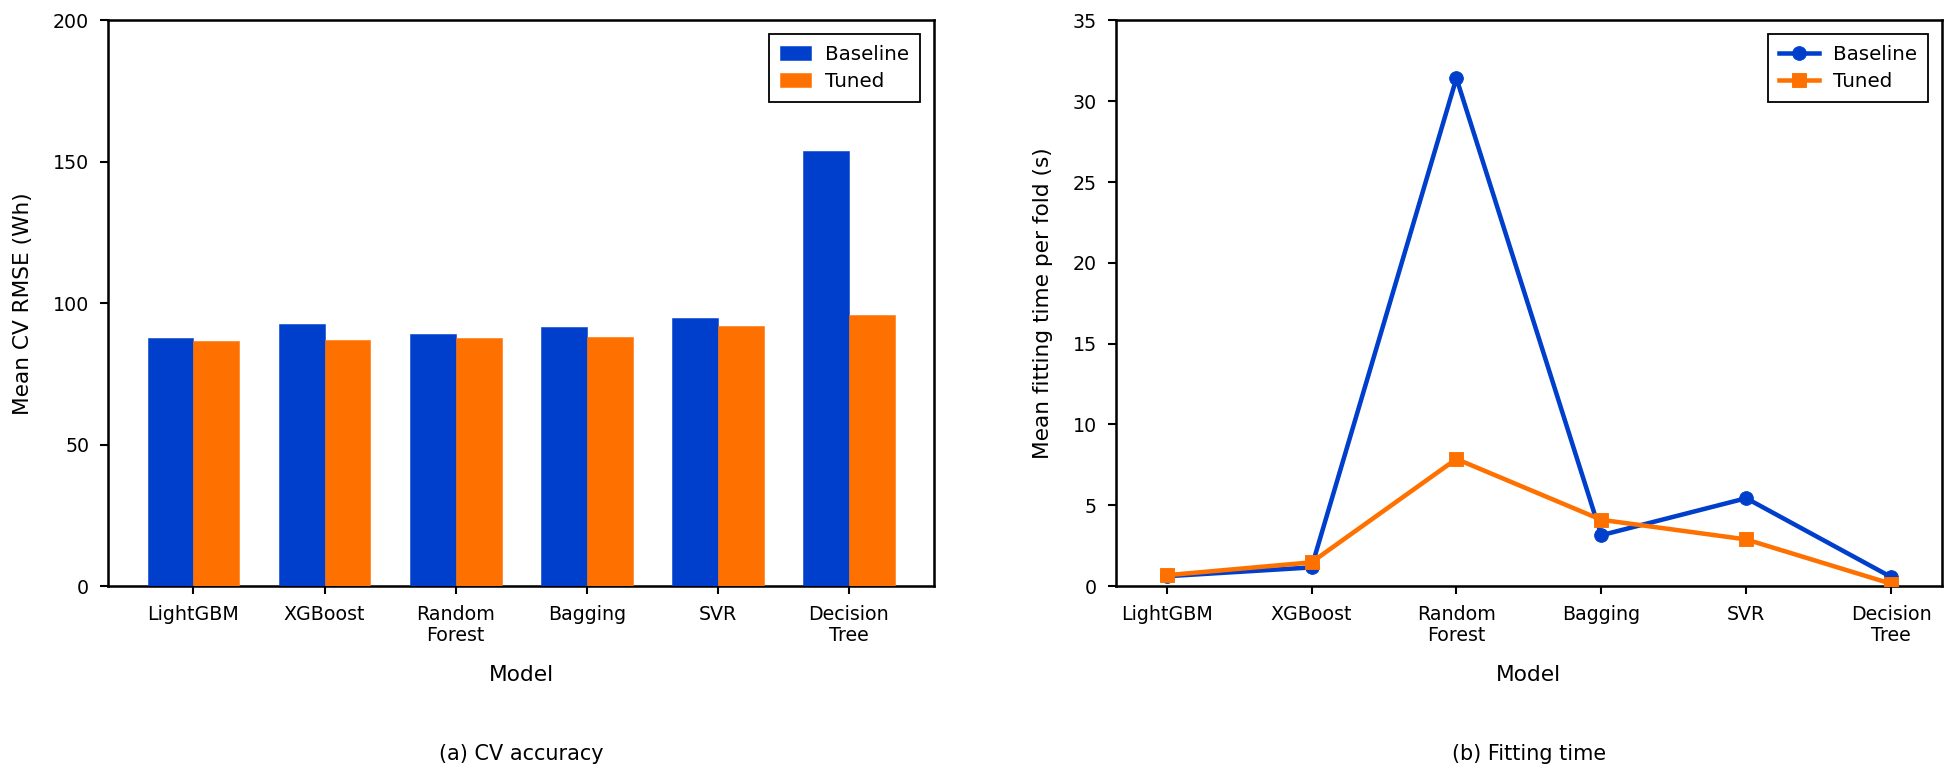

CELL 09A — VISUALIZATION AUDIT
Frozen plan ID: 3540b29b8201
Selected preprocessing: B_log

Data:
Baseline CV folds: 24 / 24
Selected tuned CV folds: 24 / 24
Algorithms: 6 / 6
RMSE and fitting time recalculation: PASS
Registered source checksums: PASS

Figure design:
Panel (a): Grouped bar chart
Panel (b): Line chart, linear Y-axis
Legend: Separate boxed legends
X-axis label: Model
Text: Black, normal weight
Panel captions: Below plots
Baseline color: #003FCB
Tuned color: #FE7101

Data-derived axis ranges:
RMSE: 0–200 Wh
Fitting time: 0–35 s

Actual plotted data:


,algorithm,candidate_id,stage,baseline_rmse_wh,tuned_rmse_wh,baseline_fit_seconds,tuned_fit_seconds
0,LightGBM,lightgbm_s2_002_5e6f3e8cfc,2,87.7685,86.6215,0.6064,0.6677
1,XGBoost,xgboost_s2_003_022e7d5df1,2,92.5687,86.9622,1.1524,1.4659
2,Random Forest,random_forest_s1_003_8dec891b,1,89.2320,87.6392,31.4182,7.8611
3,Bagging,bagging_s1_003_1c7ab48f,1,91.4061,87.8966,3.1435,4.0975
4,SVR,svr_s1_008_57265079,1,94.6953,91.7731,5.4335,2.8831
5,Decision Tree,decision_tree_s1_004_645f4153,1,153.7070,95.8688,0.5586,0.1411



Saved outputs:
/content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/figures/model_development/09a_default_vs_tuned_cv_performance.png
/content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/figures/model_development/09a_default_vs_tuned_cv_performance.svg
/content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/figures/model_development/09a_default_vs_tuned_cv_performance_data.csv

PNG: 300 dpi
SVG: Scalable vector format
NO MODEL FITTING PERFORMED
NO FIXED VALIDATION OR FINAL TEST ACCESSED


In [20]:

# ================================================================
# NOTEBOOK 02 — CELL 09A
# BASELINE VS TUNED: CV ACCURACY AND FITTING TIME
#
# (a) Grouped bar chart — Mean CV RMSE (Wh)
# (b) Line chart — Mean fitting time per fold (s)
#
# Figure design:
# - Two saturated, contrasting colors
# - Separate boxed legend inside EACH panel
# - All text pure black and normal weight
# - X-axis label: Model
# - Short panel captions below each chart
# - Data-driven model order and axis limits
#
# Outputs: PNG 300 dpi, SVG, source-data CSV
# NO MODEL FITTING
# ================================================================

import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import FuncFormatter
from IPython.display import display


# ================================================================
# 1. REGISTERED EXPERIMENT PATHS
# ================================================================

ROOT = Path(
    "/content/drive/MyDrive/Stability_Driven_Energy"
)

RUN_DIR = (
    ROOT
    / "03_model_development"
    / "grid_search"
    / "3540b29b8201"
)

BASE_DIR = (
    ROOT
    / "03_model_development"
    / "baseline_screening"
    / "639561d42efc"
)

FILES = {
    "baseline": (
        BASE_DIR
        / "baseline_fold_metrics_progress.csv"
    ),

    "stage1": (
        RUN_DIR
        / "stage1"
        / "stage1_fold_metrics_progress.csv"
    ),

    "stage2": (
        RUN_DIR
        / "stage2"
        / "reports"
        / "stage2_fold_metrics_progress.csv"
    ),

    "selection": (
        RUN_DIR
        / "reports"
        / "final_tuned_model_selection.csv"
    ),

    "registration": (
        RUN_DIR
        / "reports"
        / "final_tuned_model_selection.json"
    )
}

FIG_DIR = (
    RUN_DIR
    / "figures"
    / "model_development"
)

for name, path in FILES.items():

    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {name}: {path}"
        )


# ================================================================
# 2. VERIFY AUDITED SOURCE INTEGRITY
# ================================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as file:

        for block in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            digest.update(block)

    return digest.hexdigest()


with open(
    FILES["registration"],
    encoding="utf-8"
) as file:

    registration = json.load(file)


if registration["plan_id"] != "3540b29b8201":
    raise RuntimeError(
        "Frozen tuning plan ID mismatch."
    )

if registration["preprocessing"] != "B_log":
    raise RuntimeError(
        "Unexpected preprocessing configuration."
    )

SOURCE_HASH_KEYS = {
    "baseline": "baseline",
    "stage1": "s1_folds",
    "stage2": "s2_folds"
}

for name, registered_key in SOURCE_HASH_KEYS.items():

    actual_hash = sha256_file(FILES[name])

    expected_hash = (
        registration["input_sha256"][registered_key]
    )

    if actual_hash != expected_hash:

        raise RuntimeError(
            f"Audited source changed: {name}"
        )


if sha256_file(FILES["selection"]) != (
    registration["output_sha256"]["selection_csv"]
):
    raise RuntimeError(
        "Final tuned selection checksum mismatch."
    )


# ================================================================
# 3. LOAD ACTUAL CV RESULTS
# ================================================================

baseline = pd.read_csv(FILES["baseline"])
stage1 = pd.read_csv(FILES["stage1"])
stage2 = pd.read_csv(FILES["stage2"])
selection = pd.read_csv(FILES["selection"])

EXPECTED_ALGORITHMS = {
    "Decision Tree",
    "Random Forest",
    "Bagging",
    "SVR",
    "XGBoost",
    "LightGBM"
}

if len(stage1) != 476:
    raise RuntimeError(
        "Stage 1 must contain 476 fitting records."
    )

if len(stage2) != 80:
    raise RuntimeError(
        "Stage 2 must contain 80 fitting records."
    )

if len(selection) != 6:
    raise RuntimeError(
        "Expected six final tuned configurations."
    )

if selection["algorithm"].duplicated().any():
    raise RuntimeError(
        "Duplicate selected algorithm."
    )

if set(selection["algorithm"]) != EXPECTED_ALGORITHMS:
    raise RuntimeError(
        "Selected algorithm list is incomplete."
    )

if not (stage1["stage"] == 1).all():
    raise RuntimeError(
        "Stage 1 identity mismatch."
    )

if not (stage2["stage"] == 2).all():
    raise RuntimeError(
        "Stage 2 identity mismatch."
    )

for frame in [stage1, stage2]:

    if not (
        frame["plan_id"] == "3540b29b8201"
    ).all():
        raise RuntimeError(
            "Frozen plan ID mismatch in CV records."
        )


# ================================================================
# 4. RECALCULATE BASELINE FROM FOUR FOLDS
# ================================================================

baseline_b = baseline.loc[
    baseline["configuration"].eq("B_log")
].copy()

if len(baseline_b) != 24:
    raise RuntimeError(
        "Expected 24 B_log baseline CV fits."
    )

if baseline_b.duplicated(
    ["algorithm", "fold"]
).any():
    raise RuntimeError(
        "Duplicate baseline algorithm-fold record."
    )

for algorithm in EXPECTED_ALGORITHMS:

    subset = baseline_b.loc[
        baseline_b["algorithm"] == algorithm
    ]

    if set(subset["fold"]) != {1, 2, 3, 4}:
        raise RuntimeError(
            f"Incomplete baseline CV: {algorithm}"
        )


baseline_summary = (
    baseline_b
    .groupby("algorithm", as_index=False)
    .agg(
        baseline_rmse_wh=(
            "assessment_rmse_wh",
            "mean"
        ),

        baseline_fit_seconds=(
            "fit_seconds",
            "mean"
        )
    )
)


# ================================================================
# 5. RECALCULATE TUNED FROM SELECTED CV FOLDS
# ================================================================

all_tuning_folds = pd.concat(
    [stage1, stage2],
    ignore_index=True
)

if all_tuning_folds.duplicated(
    ["candidate_id", "fold"]
).any():
    raise RuntimeError(
        "Duplicate tuning candidate-fold record."
    )

selected_folds = all_tuning_folds.loc[
    all_tuning_folds["candidate_id"].isin(
        selection["candidate_id"]
    )
].copy()

if len(selected_folds) != 24:
    raise RuntimeError(
        "Expected 24 selected tuned CV fits."
    )

for selected in selection.itertuples(index=False):

    subset = selected_folds.loc[
        selected_folds["candidate_id"]
        == selected.candidate_id
    ]

    if set(subset["fold"]) != {1, 2, 3, 4}:
        raise RuntimeError(
            f"Incomplete tuned folds: {selected.algorithm}"
        )

    if not (
        subset["algorithm"] == selected.algorithm
    ).all():
        raise RuntimeError(
            f"Tuned algorithm mismatch: {selected.algorithm}"
        )

    if not (
        subset["stage"] == selected.stage
    ).all():
        raise RuntimeError(
            f"Tuned stage mismatch: {selected.algorithm}"
        )


tuned_summary = (
    selected_folds
    .groupby(
        ["algorithm", "candidate_id", "stage"],
        as_index=False
    )
    .agg(
        tuned_rmse_wh=(
            "assessment_rmse_wh",
            "mean"
        ),

        tuned_fit_seconds=(
            "fit_seconds",
            "mean"
        )
    )
)


verified_tuned = selection.merge(
    tuned_summary,
    on=["algorithm", "candidate_id", "stage"],
    validate="one_to_one"
)

if len(verified_tuned) != 6:
    raise RuntimeError(
        "Incomplete tuned CV verification."
    )

if not np.allclose(
    verified_tuned["tuned_rmse_wh"],
    verified_tuned["mean_cv_rmse_wh"],
    rtol=1e-10,
    atol=1e-8
):
    raise RuntimeError(
        "Recalculated tuned RMSE differs from Cell 08."
    )

if not np.allclose(
    verified_tuned["tuned_fit_seconds"],
    verified_tuned["mean_fit_seconds"],
    rtol=1e-10,
    atol=1e-8
):
    raise RuntimeError(
        "Recalculated tuned fitting time "
        "differs from Cell 08."
    )


# ================================================================
# 6. FINAL FIGURE DATA
# ================================================================

plot_df = baseline_summary.merge(
    verified_tuned[[
        "algorithm",
        "candidate_id",
        "stage",
        "baseline_cv_rmse_wh",
        "tuned_rmse_wh",
        "tuned_fit_seconds"
    ]],
    on="algorithm",
    validate="one_to_one"
)

if not np.allclose(
    plot_df["baseline_rmse_wh"],
    plot_df["baseline_cv_rmse_wh"],
    rtol=1e-10,
    atol=1e-8
):
    raise RuntimeError(
        "Baseline RMSE differs from frozen selection."
    )


NUMERIC_COLUMNS = [
    "baseline_rmse_wh",
    "tuned_rmse_wh",
    "baseline_fit_seconds",
    "tuned_fit_seconds"
]

values = plot_df[
    NUMERIC_COLUMNS
].to_numpy(dtype=float)

if not np.isfinite(values).all():
    raise RuntimeError(
        "Nonfinite visualization values."
    )

if (values <= 0).any():
    raise RuntimeError(
        "RMSE and fitting times must be positive."
    )


# Arrange models by actual tuned CV RMSE.
plot_df = (
    plot_df
    .sort_values(
        ["tuned_rmse_wh", "algorithm"],
        kind="mergesort"
    )
    .reset_index(drop=True)
)

ALGORITHMS = plot_df["algorithm"].tolist()

DISPLAY_LABELS = [
    name.replace(
        "Decision Tree", "Decision\nTree"
    ).replace(
        "Random Forest", "Random\nForest"
    )
    for name in ALGORITHMS
]

x = np.arange(len(ALGORITHMS))

baseline_rmse = plot_df[
    "baseline_rmse_wh"
].to_numpy(dtype=float)

tuned_rmse = plot_df[
    "tuned_rmse_wh"
].to_numpy(dtype=float)

baseline_time = plot_df[
    "baseline_fit_seconds"
].to_numpy(dtype=float)

tuned_time = plot_df[
    "tuned_fit_seconds"
].to_numpy(dtype=float)


# ================================================================
# 7. DATA-DRIVEN LINEAR AXES
# ================================================================

def nice_axis(maximum, padding=0.12, n_intervals=7):

    if not np.isfinite(maximum) or maximum <= 0:
        raise ValueError(
            "Axis maximum must be positive."
        )

    target = maximum * (1 + padding)
    approximate_step = target / n_intervals

    magnitude = 10 ** np.floor(
        np.log10(approximate_step)
    )

    multipliers = np.array([
        1.0, 1.25, 1.5, 2.0, 2.5,
        5.0, 10.0
    ])

    candidates = multipliers * magnitude

    step = float(
        candidates[
            candidates >= approximate_step
        ][0]
    )

    upper = float(
        np.ceil(target / step) * step
    )

    ticks = np.arange(
        0,
        upper + step * 0.5,
        step
    )

    return upper, ticks


# Slightly more upper space in panel (a)
# so the boxed legend does not overlap bars.
RMSE_UPPER, RMSE_TICKS = nice_axis(
    max(
        baseline_rmse.max(),
        tuned_rmse.max()
    ),
    padding=0.25,
    n_intervals=7
)

TIME_UPPER, TIME_TICKS = nice_axis(
    max(
        baseline_time.max(),
        tuned_time.max()
    ),
    padding=0.11,
    n_intervals=7
)


# ================================================================
# 8. FINAL COLORS AND TYPOGRAPHY
# ================================================================

BLUE = "#003FCB"
ORANGE = "#FE7101"

BLACK = "#000000"
WHITE = "#FFFFFF"

STYLE = {
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "font.weight": "normal",

    "text.color": BLACK,

    "axes.labelcolor": BLACK,
    "axes.edgecolor": BLACK,
    "axes.linewidth": 1.4,
    "axes.labelsize": 12,
    "axes.labelweight": "normal",
    "axes.titleweight": "normal",

    "xtick.color": BLACK,
    "ytick.color": BLACK,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,

    "legend.fontsize": 11,

    "figure.facecolor": WHITE,
    "axes.facecolor": WHITE,
    "savefig.facecolor": WHITE,

    "axes.spines.top": True,
    "axes.spines.right": True,

    "svg.fonttype": "none",
    "pdf.fonttype": 42
}


# ================================================================
# 9. FIGURE CONSTRUCTION
# ================================================================

with plt.rc_context(STYLE):

    fig, (ax_a, ax_b) = plt.subplots(
        1,
        2,
        figsize=(15.5, 6.8),
        dpi=130
    )

    # Layout adjusted for:
    # two-line model names, x-axis labels,
    # and panel captions with moderate spacing.

    fig.subplots_adjust(
        left=0.075,
        right=0.985,
        top=0.935,
        bottom=0.295,
        wspace=0.22
    )


    # ========================================================
    # PANEL (a) — CV ACCURACY
    # ========================================================

    bar_width = 0.35

    ax_a.bar(
        x - bar_width / 2,
        baseline_rmse,
        width=bar_width,
        color=BLUE,
        edgecolor=BLUE,
        linewidth=0.3,
        label="Baseline",
        zorder=3
    )

    ax_a.bar(
        x + bar_width / 2,
        tuned_rmse,
        width=bar_width,
        color=ORANGE,
        edgecolor=ORANGE,
        linewidth=0.3,
        label="Tuned",
        zorder=3
    )

    ax_a.set_xlim(
        -0.65,
        len(x) - 0.35
    )

    ax_a.set_ylim(
        0,
        RMSE_UPPER
    )

    ax_a.set_yticks(
        RMSE_TICKS
    )

    ax_a.set_xticks(x)

    ax_a.set_xticklabels(
        DISPLAY_LABELS
    )

    ax_a.set_xlabel(
        "Model",
        labelpad=11,
        fontweight="normal",
        color=BLACK
    )

    ax_a.set_ylabel(
        "Mean CV RMSE (Wh)",
        labelpad=11,
        fontweight="normal",
        color=BLACK
    )

    ax_a.yaxis.set_major_formatter(
        FuncFormatter(
            lambda value, pos: f"{value:g}"
        )
    )

    ax_a.grid(False)


    # Legend (a): boxed, inside upper-right.
    # Bar symbols are taken from the actual plot.

    legend_a = ax_a.legend(
        loc="upper right",
        ncol=1,
        frameon=True,
        fancybox=False,
        framealpha=1.0,
        facecolor=WHITE,
        edgecolor=BLACK,
        borderaxespad=0.7,
        borderpad=0.55,
        labelspacing=0.40,
        handlelength=1.6,
        handletextpad=0.7,
        prop={
            "size": 11,
            "weight": "normal"
        }
    )

    legend_a.get_frame().set_linewidth(1.0)


    # ========================================================
    # PANEL (b) — FITTING TIME
    # ========================================================

    ax_b.plot(
        x,
        baseline_time,
        color=BLUE,
        linewidth=2.5,
        linestyle="-",
        marker="o",
        markersize=7.6,
        markerfacecolor=BLUE,
        markeredgecolor=BLUE,
        markeredgewidth=0.5,
        label="Baseline",
        zorder=4
    )

    ax_b.plot(
        x,
        tuned_time,
        color=ORANGE,
        linewidth=2.5,
        linestyle="-",
        marker="s",
        markersize=7.3,
        markerfacecolor=ORANGE,
        markeredgecolor=ORANGE,
        markeredgewidth=0.5,
        label="Tuned",
        zorder=5
    )

    ax_b.set_yscale("linear")

    ax_b.set_xlim(
        -0.35,
        len(x) - 0.65
    )

    ax_b.set_ylim(
        0,
        TIME_UPPER
    )

    ax_b.set_yticks(
        TIME_TICKS
    )

    ax_b.set_xticks(x)

    ax_b.set_xticklabels(
        DISPLAY_LABELS
    )

    ax_b.set_xlabel(
        "Model",
        labelpad=11,
        fontweight="normal",
        color=BLACK
    )

    ax_b.set_ylabel(
        "Mean fitting time per fold (s)",
        labelpad=11,
        fontweight="normal",
        color=BLACK
    )

    ax_b.yaxis.set_major_formatter(
        FuncFormatter(
            lambda value, pos: f"{value:g}"
        )
    )

    ax_b.grid(False)


    # Legend (b): boxed, inside upper-right.
    # Uses line-and-marker symbols, not bar patches.

    legend_b = ax_b.legend(
        loc="upper right",
        ncol=1,
        frameon=True,
        fancybox=False,
        framealpha=1.0,
        facecolor=WHITE,
        edgecolor=BLACK,
        borderaxespad=0.7,
        borderpad=0.55,
        labelspacing=0.40,
        handlelength=2.0,
        handletextpad=0.7,
        numpoints=1,
        prop={
            "size": 11,
            "weight": "normal"
        }
    )

    legend_b.get_frame().set_linewidth(1.0)


    # ========================================================
    # 10. CONSISTENT BLACK, NON-BOLD LABELS
    # ========================================================

    for ax in (ax_a, ax_b):

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color(BLACK)
            spine.set_linewidth(1.4)

        ax.tick_params(
            axis="both",
            which="major",
            direction="out",
            length=4.5,
            width=1.15,
            colors=BLACK,
            pad=6
        )

        for label in ax.get_xticklabels():

            label.set_color(BLACK)
            label.set_fontweight("normal")
            label.set_fontsize(10.5)
            label.set_rotation(0)
            label.set_ha("center")
            label.set_linespacing(1.15)

        for label in ax.get_yticklabels():

            label.set_color(BLACK)
            label.set_fontweight("normal")
            label.set_fontsize(10.5)

        ax.xaxis.label.set_fontweight("normal")
        ax.yaxis.label.set_fontweight("normal")

        ax.set_axisbelow(True)


    for legend in [legend_a, legend_b]:

        for text in legend.get_texts():
            text.set_color(BLACK)
            text.set_fontweight("normal")


    # ========================================================
    # 11. SHORT PANEL CAPTIONS
    # ========================================================

    pos_a = ax_a.get_position()
    pos_b = ax_b.get_position()

    center_a = (
        pos_a.x0 + pos_a.x1
    ) / 2

    center_b = (
        pos_b.x0 + pos_b.x1
    ) / 2

    # Balanced distance from x-axis titles.
    CAPTION_Y = 0.105

    fig.text(
        center_a,
        CAPTION_Y,
        "(a) CV accuracy",
        ha="center",
        va="center",
        fontsize=11.5,
        fontweight="normal",
        color=BLACK
    )

    fig.text(
        center_b,
        CAPTION_Y,
        "(b) Fitting time",
        ha="center",
        va="center",
        fontsize=11.5,
        fontweight="normal",
        color=BLACK
    )


    # ========================================================
    # 12. SAVE DATA AND FIGURE
    # ========================================================

    FIG_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    PNG_PATH = (
        FIG_DIR
        / "09a_default_vs_tuned_cv_performance.png"
    )

    SVG_PATH = (
        FIG_DIR
        / "09a_default_vs_tuned_cv_performance.svg"
    )

    DATA_PATH = (
        FIG_DIR
        / "09a_default_vs_tuned_cv_performance_data.csv"
    )

    export_df = plot_df[[
        "algorithm",
        "candidate_id",
        "stage",
        "baseline_rmse_wh",
        "tuned_rmse_wh",
        "baseline_fit_seconds",
        "tuned_fit_seconds"
    ]].copy()

    export_df.to_csv(
        DATA_PATH,
        index=False,
        float_format="%.10f"
    )

    fig.savefig(
        PNG_PATH,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.12,
        facecolor=WHITE
    )

    fig.savefig(
        SVG_PATH,
        format="svg",
        bbox_inches="tight",
        pad_inches=0.12,
        facecolor=WHITE
    )

    plt.show()
    plt.close(fig)


# ================================================================
# 13. FINAL FIGURE AUDIT
# ================================================================

for path in [
    PNG_PATH,
    SVG_PATH,
    DATA_PATH
]:

    if not path.is_file():
        raise RuntimeError(
            f"Missing output: {path}"
        )


print("=" * 70)
print("CELL 09A — VISUALIZATION AUDIT")
print("=" * 70)

print("Frozen plan ID: 3540b29b8201")
print("Selected preprocessing: B_log")

print("\nData:")
print("Baseline CV folds: 24 / 24")
print("Selected tuned CV folds: 24 / 24")
print("Algorithms: 6 / 6")
print("RMSE and fitting time recalculation: PASS")
print("Registered source checksums: PASS")

print("\nFigure design:")
print("Panel (a): Grouped bar chart")
print("Panel (b): Line chart, linear Y-axis")
print("Legend: Separate boxed legends")
print("X-axis label: Model")
print("Text: Black, normal weight")
print("Panel captions: Below plots")
print("Baseline color:", BLUE)
print("Tuned color:", ORANGE)

print("\nData-derived axis ranges:")
print(f"RMSE: 0–{RMSE_UPPER:g} Wh")
print(f"Fitting time: 0–{TIME_UPPER:g} s")

print("\nActual plotted data:")
display(export_df.round(4))

print("\nSaved outputs:")
print(PNG_PATH)
print(SVG_PATH)
print(DATA_PATH)

print("\nPNG: 300 dpi")
print("SVG: Scalable vector format")
print("NO MODEL FITTING PERFORMED")
print("NO FIXED VALIDATION OR FINAL TEST ACCESSED")


## Temporal CV Performance

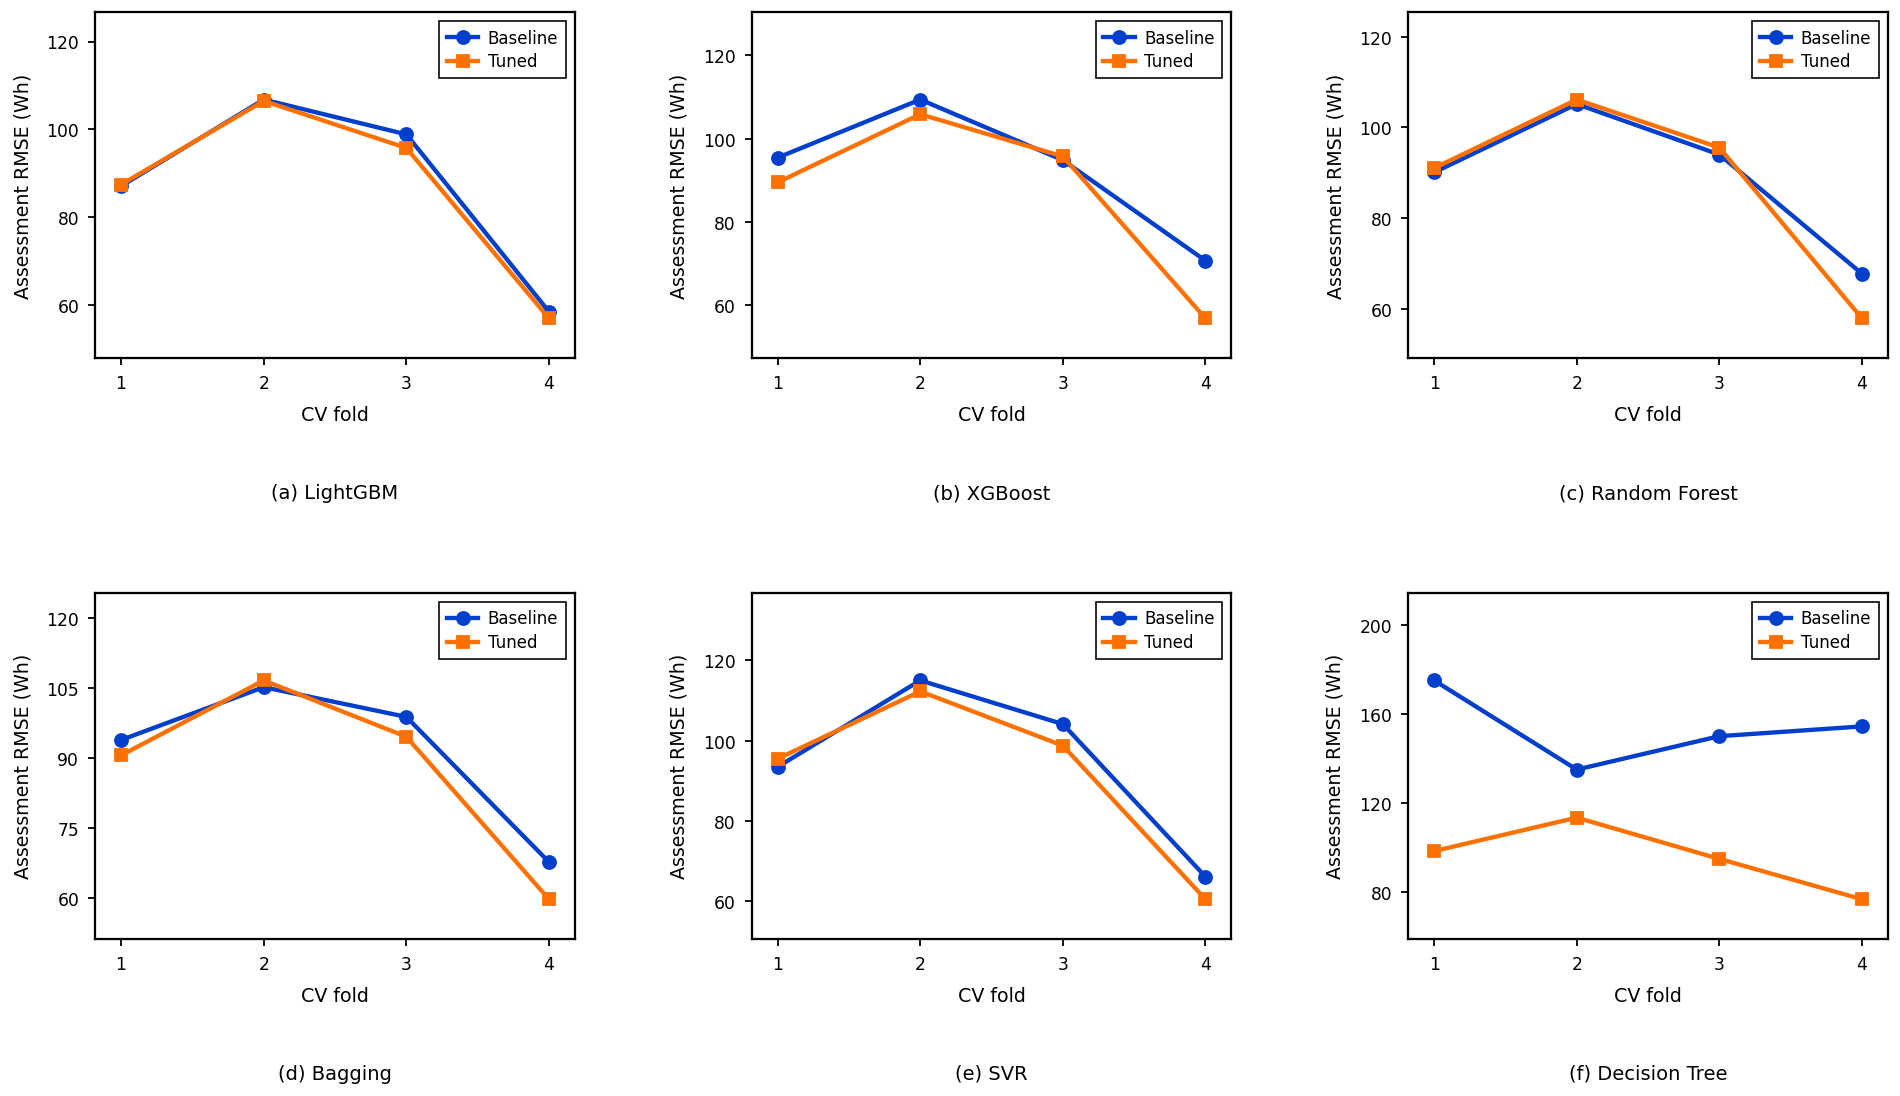

CELL 09B — TEMPORAL CV VISUALIZATION AUDIT
Frozen Plan ID: 3540b29b8201
Preprocessing: B_log

Data integrity:
Baseline CV fits: 24 / 24
Selected tuned CV fits: 24 / 24
Matching temporal folds: PASS
Tuned RMSE recalculation: PASS
Source checksums: PASS

Figure:
Layout: 2 rows x 3 columns
Panels: 6
Baseline: #003FCB
Tuned: #FE7101
Text: Black, normal weight
Legends: Separate boxed legends
Axes: Data-driven per model
No model fitting performed

Model order:
LightGBM | XGBoost | Random Forest | Bagging | SVR | Decision Tree

Actual fold-level RMSE:


,algorithm,fold,baseline_rmse_wh,tuned_rmse_wh
0,LightGBM,1,87.0465,87.3900
1,LightGBM,2,106.7723,106.4640
2,LightGBM,3,98.8312,95.7345
3,LightGBM,4,58.4240,56.8973
4,XGBoost,1,95.4133,89.4822
5,XGBoost,2,109.3785,105.8498
6,XGBoost,3,94.8224,95.7127
7,XGBoost,4,70.6607,56.8040
8,Random Forest,1,90.0744,91.0189
9,Random Forest,2,105.1389,106.1337



Saved outputs:
/content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/figures/model_development/09b_temporal_cv_performance.png
/content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/figures/model_development/09b_temporal_cv_performance.svg
/content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/figures/model_development/09b_temporal_cv_performance_data.csv

PNG: 300 dpi
SVG: vector format
NO FIXED VALIDATION OR TEST ACCESSED


In [21]:

# ============================================================
# NOTEBOOK 02 — CELL 09B
# TEMPORAL CROSS-VALIDATION PERFORMANCE
#
# Six panels (2 x 3)
# Baseline vs Tuned | Four expanding-window CV folds
#
# Data: Audited B_log baseline and selected tuned models
# Output: PNG 300 dpi + SVG + CSV
#
# NO MODEL FITTING
# NO FIXED VALIDATION / FINAL TEST
# ============================================================

import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import MaxNLocator
from IPython.display import display


# ============================================================
# 1. EXPERIMENT PATHS
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/Stability_Driven_Energy"
)

RUN_DIR = (
    ROOT / "03_model_development"
    / "grid_search" / "3540b29b8201"
)

BASE_DIR = (
    ROOT / "03_model_development"
    / "baseline_screening" / "639561d42efc"
)

FILES = {
    "baseline": (
        BASE_DIR / "baseline_fold_metrics_progress.csv"
    ),
    "stage1": (
        RUN_DIR / "stage1"
        / "stage1_fold_metrics_progress.csv"
    ),
    "stage2": (
        RUN_DIR / "stage2" / "reports"
        / "stage2_fold_metrics_progress.csv"
    ),
    "selection": (
        RUN_DIR / "reports"
        / "final_tuned_model_selection.csv"
    ),
    "registration": (
        RUN_DIR / "reports"
        / "final_tuned_model_selection.json"
    )
}

FIG_DIR = (
    RUN_DIR / "figures" / "model_development"
)

for name, path in FILES.items():
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {name}: {path}"
        )


# ============================================================
# 2. VERIFY FROZEN DATA SOURCES
# ============================================================

def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def require(condition, message):
    if not condition:
        raise RuntimeError(message)


with open(
    FILES["registration"], encoding="utf-8"
) as f:
    registration = json.load(f)

require(
    registration["plan_id"] == "3540b29b8201",
    "Frozen tuning plan mismatch."
)

require(
    registration["preprocessing"] == "B_log",
    "Unexpected preprocessing configuration."
)

SOURCE_KEYS = {
    "baseline": "baseline",
    "stage1": "s1_folds",
    "stage2": "s2_folds"
}

for name, key in SOURCE_KEYS.items():
    require(
        sha256_file(FILES[name])
        == registration["input_sha256"][key],
        f"Registered source changed: {name}"
    )

require(
    sha256_file(FILES["selection"])
    == registration["output_sha256"]["selection_csv"],
    "Final tuned selection checksum mismatch."
)


# ============================================================
# 3. LOAD ACTUAL EXPERIMENT RESULTS
# ============================================================

baseline = pd.read_csv(FILES["baseline"])
stage1 = pd.read_csv(FILES["stage1"])
stage2 = pd.read_csv(FILES["stage2"])
selection = pd.read_csv(FILES["selection"])

EXPECTED_MODELS = {
    "Decision Tree",
    "Random Forest",
    "Bagging",
    "SVR",
    "XGBoost",
    "LightGBM"
}

require(
    len(stage1) == 476 and len(stage2) == 80,
    "Stage 1 / Stage 2 fitting records incomplete."
)

require(
    len(selection) == 6,
    "Expected six final tuned configurations."
)

require(
    selection["algorithm"].is_unique,
    "Duplicate selected algorithms."
)

require(
    set(selection["algorithm"]) == EXPECTED_MODELS,
    "Incomplete selected model list."
)

for data, stage_number in [(stage1, 1), (stage2, 2)]:
    require(
        (data["stage"] == stage_number).all(),
        f"Incorrect Stage {stage_number} identifier."
    )
    require(
        (data["plan_id"] == "3540b29b8201").all(),
        f"Stage {stage_number} plan mismatch."
    )


# ============================================================
# 4. EXTRACT BASELINE B_LOG CV FOLDS
# ============================================================

baseline_b = baseline.loc[
    baseline["configuration"] == "B_log"
].copy()

require(
    len(baseline_b) == 24,
    "Expected 24 baseline B_log fold results."
)

require(
    not baseline_b.duplicated(
        ["algorithm", "fold"]
    ).any(),
    "Duplicate baseline algorithm-fold."
)

for algorithm in EXPECTED_MODELS:
    subset = baseline_b.loc[
        baseline_b["algorithm"] == algorithm
    ]

    require(
        set(subset["fold"]) == {1, 2, 3, 4},
        f"Incomplete baseline folds: {algorithm}"
    )


# ============================================================
# 5. EXTRACT SELECTED TUNED CV FOLDS
# ============================================================

all_tuning = pd.concat(
    [stage1, stage2],
    ignore_index=True
)

require(
    not all_tuning.duplicated(
        ["candidate_id", "fold"]
    ).any(),
    "Duplicate tuning candidate-fold."
)

tuned_folds = all_tuning.merge(
    selection[[
        "algorithm",
        "candidate_id",
        "stage",
        "mean_cv_rmse_wh"
    ]],
    on=["algorithm", "candidate_id", "stage"],
    how="inner",
    validate="many_to_one"
)

require(
    len(tuned_folds) == 24,
    "Expected 24 selected tuned fitting records."
)

for selected in selection.itertuples(index=False):

    subset = tuned_folds.loc[
        tuned_folds["candidate_id"]
        == selected.candidate_id
    ]

    require(
        len(subset) == 4
        and set(subset["fold"]) == {1, 2, 3, 4},
        f"Incomplete tuned CV: {selected.algorithm}"
    )

    recalculated_rmse = (
        subset["assessment_rmse_wh"].mean()
    )

    require(
        np.isclose(
            recalculated_rmse,
            selected.mean_cv_rmse_wh,
            rtol=1e-10,
            atol=1e-8
        ),
        f"Tuned CV RMSE mismatch: {selected.algorithm}"
    )


# ============================================================
# 6. MATCH BASELINE AND TUNED BY MODEL + FOLD
# ============================================================

baseline_values = baseline_b[[
    "algorithm",
    "fold",
    "assessment_rmse_wh",
    "n_train",
    "n_assessment"
]].rename(columns={
    "assessment_rmse_wh": "baseline_rmse_wh",
    "n_train": "baseline_n_train",
    "n_assessment": "baseline_n_assessment"
})

tuned_values = tuned_folds[[
    "algorithm",
    "candidate_id",
    "stage",
    "fold",
    "assessment_rmse_wh",
    "n_train",
    "n_assessment"
]].rename(columns={
    "assessment_rmse_wh": "tuned_rmse_wh",
    "n_train": "tuned_n_train",
    "n_assessment": "tuned_n_assessment"
})

plot_df = baseline_values.merge(
    tuned_values,
    on=["algorithm", "fold"],
    how="inner",
    validate="one_to_one"
)

require(
    len(plot_df) == 24,
    "Baseline/tuned fold matching incomplete."
)

require(
    (
        plot_df["baseline_n_train"]
        == plot_df["tuned_n_train"]
    ).all(),
    "Baseline/tuned training sizes differ."
)

require(
    (
        plot_df["baseline_n_assessment"]
        == plot_df["tuned_n_assessment"]
    ).all(),
    "Baseline/tuned assessment sizes differ."
)

EXPECTED_TRAIN_SIZES = {
    1: 7818,
    2: 8826,
    3: 9834,
    4: 10842
}

for fold, expected_n in EXPECTED_TRAIN_SIZES.items():

    subset = plot_df.loc[plot_df["fold"] == fold]

    require(
        len(subset) == 6,
        f"Fold {fold} is incomplete."
    )

    require(
        (subset["baseline_n_train"] == expected_n).all(),
        f"Incorrect training size at Fold {fold}."
    )

    require(
        (subset["baseline_n_assessment"] == 1008).all(),
        f"Incorrect assessment size at Fold {fold}."
    )

require(
    np.isfinite(
        plot_df[[
            "baseline_rmse_wh",
            "tuned_rmse_wh"
        ]].to_numpy(dtype=float)
    ).all(),
    "Nonfinite CV RMSE values."
)

require(
    (
        plot_df[[
            "baseline_rmse_wh",
            "tuned_rmse_wh"
        ]] > 0
    ).all().all(),
    "RMSE must be positive."
)


# ============================================================
# 7. DETERMINE MODEL ORDER FROM TUNED CV RESULTS
# ============================================================

model_order = (
    selection.sort_values(
        ["mean_cv_rmse_wh", "algorithm"],
        kind="mergesort"
    )["algorithm"]
    .tolist()
)

plot_df["model_order"] = pd.Categorical(
    plot_df["algorithm"],
    categories=model_order,
    ordered=True
)

plot_df = (
    plot_df.sort_values(
        ["model_order", "fold"]
    )
    .reset_index(drop=True)
)

assert len(model_order) == 6


# ============================================================
# 8. APPROVED COLOR PALETTE & TYPOGRAPHY
# ============================================================

BLUE = "#003FCB"
ORANGE = "#FE7101"

BLACK = "#000000"
WHITE = "#FFFFFF"

STYLE = {
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "font.weight": "normal",

    "text.color": BLACK,

    "axes.labelcolor": BLACK,
    "axes.edgecolor": BLACK,
    "axes.linewidth": 1.25,

    "axes.labelsize": 10.5,
    "axes.labelweight": "normal",

    "xtick.color": BLACK,
    "ytick.color": BLACK,

    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,

    "legend.fontsize": 9.5,

    "figure.facecolor": WHITE,
    "axes.facecolor": WHITE,
    "savefig.facecolor": WHITE,

    "axes.spines.top": True,
    "axes.spines.right": True,

    "svg.fonttype": "none",
    "pdf.fonttype": 42
}


# ============================================================
# 9. DATA-DRIVEN Y-AXIS PER PANEL
# ============================================================

def temporal_axis_limits(values):
    """
    Independent explicit RMSE axis for each model.

    A small margin is added below and above the
    observed range. Upper space accommodates the
    boxed legend without changing the data values.
    """

    values = np.asarray(values, dtype=float)

    lower_data = float(values.min())
    upper_data = float(values.max())

    span = max(
        upper_data - lower_data,
        upper_data * 0.06,
        2.0
    )

    lower = max(
        0.0,
        lower_data - 0.18 * span
    )

    upper = upper_data + 0.40 * span

    return lower, upper


# ============================================================
# 10. SIX-PANEL TEMPORAL CV FIGURE
# ============================================================

with plt.rc_context(STYLE):

    fig, axes = plt.subplots(
        nrows=2,
        ncols=3,
        figsize=(15.2, 8.8),
        dpi=130,
        sharex=False,
        sharey=False
    )

    fig.subplots_adjust(
        left=0.078,
        right=0.985,
        top=0.965,
        bottom=0.155,
        wspace=0.37,
        hspace=0.68
    )

    folds_x = np.array([1, 2, 3, 4])

    panel_letters = [
        "(a)", "(b)", "(c)",
        "(d)", "(e)", "(f)"
    ]

    for i, (ax, algorithm) in enumerate(
        zip(axes.flat, model_order)
    ):

        subset = (
            plot_df.loc[
                plot_df["algorithm"] == algorithm
            ]
            .sort_values("fold")
        )

        assert subset["fold"].tolist() == [
            1, 2, 3, 4
        ]

        baseline_y = subset[
            "baseline_rmse_wh"
        ].to_numpy(dtype=float)

        tuned_y = subset[
            "tuned_rmse_wh"
        ].to_numpy(dtype=float)

        # ----------------------------------------------------
        # Baseline
        # ----------------------------------------------------

        ax.plot(
            folds_x,
            baseline_y,
            color=BLUE,
            linewidth=2.4,
            linestyle="-",
            marker="o",
            markersize=7.2,
            markerfacecolor=BLUE,
            markeredgecolor=BLUE,
            label="Baseline",
            zorder=4
        )

        # ----------------------------------------------------
        # Tuned
        # ----------------------------------------------------

        ax.plot(
            folds_x,
            tuned_y,
            color=ORANGE,
            linewidth=2.4,
            linestyle="-",
            marker="s",
            markersize=6.8,
            markerfacecolor=ORANGE,
            markeredgecolor=ORANGE,
            label="Tuned",
            zorder=5
        )

        # ----------------------------------------------------
        # Data-driven axes
        # ----------------------------------------------------

        lower, upper = temporal_axis_limits(
            np.concatenate([
                baseline_y,
                tuned_y
            ])
        )

        ax.set_ylim(lower, upper)
        ax.set_xlim(0.82, 4.18)

        ax.set_xticks([1, 2, 3, 4])

        ax.set_xlabel(
            "CV fold",
            labelpad=7,
            fontweight="normal"
        )

        ax.set_ylabel(
            "Assessment RMSE (Wh)",
            labelpad=8,
            fontweight="normal"
        )

        ax.yaxis.set_major_locator(
            MaxNLocator(
                nbins=5,
                min_n_ticks=4
            )
        )

        ax.grid(False)

        # ----------------------------------------------------
        # Boxed legend inside EACH panel
        # ----------------------------------------------------

        legend = ax.legend(
            loc="upper right",
            ncol=1,
            frameon=True,
            fancybox=False,
            framealpha=1.0,
            facecolor=WHITE,
            edgecolor=BLACK,
            borderaxespad=0.55,
            borderpad=0.45,
            labelspacing=0.35,
            handlelength=1.9,
            handletextpad=0.55,
            prop={
                "size": 9.2,
                "weight": "normal"
            }
        )

        legend.get_frame().set_linewidth(0.9)

        for text in legend.get_texts():
            text.set_color(BLACK)
            text.set_fontweight("normal")

        # ----------------------------------------------------
        # Black axes, normal-weight text
        # ----------------------------------------------------

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color(BLACK)
            spine.set_linewidth(1.25)

        ax.tick_params(
            axis="both",
            which="major",
            direction="out",
            length=4,
            width=1.0,
            colors=BLACK,
            pad=5
        )

        for label in ax.get_xticklabels():
            label.set_color(BLACK)
            label.set_fontweight("normal")

        for label in ax.get_yticklabels():
            label.set_color(BLACK)
            label.set_fontweight("normal")

        ax.xaxis.label.set_color(BLACK)
        ax.yaxis.label.set_color(BLACK)

        # ----------------------------------------------------
        # Short caption below the panel
        # ----------------------------------------------------

        ax.text(
            0.5,
            -0.39,
            f"{panel_letters[i]} {algorithm}",
            transform=ax.transAxes,
            ha="center",
            va="center",
            fontsize=10.8,
            fontweight="normal",
            color=BLACK,
            clip_on=False
        )


    # ========================================================
    # 11. SAVE FIGURE AND SOURCE DATA
    # ========================================================

    FIG_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    PNG_PATH = (
        FIG_DIR
        / "09b_temporal_cv_performance.png"
    )

    SVG_PATH = (
        FIG_DIR
        / "09b_temporal_cv_performance.svg"
    )

    DATA_PATH = (
        FIG_DIR
        / "09b_temporal_cv_performance_data.csv"
    )

    export_df = plot_df[[
        "algorithm",
        "candidate_id",
        "stage",
        "fold",
        "baseline_n_train",
        "baseline_n_assessment",
        "baseline_rmse_wh",
        "tuned_rmse_wh"
    ]].copy()

    export_df.to_csv(
        DATA_PATH,
        index=False,
        float_format="%.10f"
    )

    fig.savefig(
        PNG_PATH,
        dpi=300,
        facecolor=WHITE,
        bbox_inches="tight",
        pad_inches=0.13
    )

    fig.savefig(
        SVG_PATH,
        format="svg",
        facecolor=WHITE,
        bbox_inches="tight",
        pad_inches=0.13
    )

    plt.show()
    plt.close(fig)


# ============================================================
# 12. FINAL FIGURE AUDIT
# ============================================================

for path in [
    PNG_PATH,
    SVG_PATH,
    DATA_PATH
]:
    require(
        path.is_file(),
        f"Missing output: {path}"
    )

print("=" * 70)
print("CELL 09B — TEMPORAL CV VISUALIZATION AUDIT")
print("=" * 70)

print("Frozen Plan ID: 3540b29b8201")
print("Preprocessing: B_log")

print("\nData integrity:")
print("Baseline CV fits: 24 / 24")
print("Selected tuned CV fits: 24 / 24")
print("Matching temporal folds: PASS")
print("Tuned RMSE recalculation: PASS")
print("Source checksums: PASS")

print("\nFigure:")
print("Layout: 2 rows x 3 columns")
print("Panels: 6")
print("Baseline:", BLUE)
print("Tuned:", ORANGE)
print("Text: Black, normal weight")
print("Legends: Separate boxed legends")
print("Axes: Data-driven per model")
print("No model fitting performed")

print("\nModel order:")
print(" | ".join(model_order))

print("\nActual fold-level RMSE:")
display(
    export_df[[
        "algorithm",
        "fold",
        "baseline_rmse_wh",
        "tuned_rmse_wh"
    ]].round(4)
)

print("\nSaved outputs:")
print(PNG_PATH)
print(SVG_PATH)
print(DATA_PATH)

print("\nPNG: 300 dpi")
print("SVG: vector format")
print("NO FIXED VALIDATION OR TEST ACCESSED")


## Generalization Gap (Training vs Assessment RMSE)

In [22]:

# ============================================================
# NOTEBOOK 02 — CELL 09C
# GENERALIZATION GAP SUMMARY TABLE
#
# Baseline vs Tuned — Six ML Algorithms
# Four expanding-window CV folds
#
# Gap = Assessment RMSE - Training RMSE
#
# OUTPUT: CSV + LaTeX table
# NO FIGURE / NO MODEL FITTING
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display


# ============================================================
# 1. VERIFY PREVIOUS CELL OBJECTS
# ============================================================

required_objects = [
    "baseline_b",
    "tuned_folds",
    "selection",
    "FIG_DIR"
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run Cell 09B before Cell 09C. "
        f"Missing objects: {missing}"
    )


# ============================================================
# 2. VERIFY TRAINING AND ASSESSMENT METRICS
# ============================================================

def check_metric_columns(df, name):

    required = {
        "algorithm",
        "fold",
        "train_rmse_wh",
        "assessment_rmse_wh"
    }

    missing_cols = required - set(df.columns)

    if missing_cols:
        raise RuntimeError(
            f"{name} lacks required metrics: "
            f"{sorted(missing_cols)}. "
            "Training RMSE must come from actual "
            "fitting records; it cannot be inferred "
            "from assessment RMSE."
        )


check_metric_columns(
    baseline_b, "Baseline"
)

check_metric_columns(
    tuned_folds, "Tuned"
)


# ============================================================
# 3. EXTRACT FOLD-LEVEL RESULTS
# ============================================================

baseline_metrics = baseline_b[[
    "algorithm",
    "fold",
    "train_rmse_wh",
    "assessment_rmse_wh"
]].copy()

baseline_metrics = baseline_metrics.rename(
    columns={
        "train_rmse_wh": "baseline_train",
        "assessment_rmse_wh": "baseline_assessment"
    }
)


tuned_metrics = tuned_folds[[
    "algorithm",
    "candidate_id",
    "stage",
    "fold",
    "train_rmse_wh",
    "assessment_rmse_wh"
]].copy()

tuned_metrics = tuned_metrics.rename(
    columns={
        "train_rmse_wh": "tuned_train",
        "assessment_rmse_wh": "tuned_assessment"
    }
)


# ============================================================
# 4. MATCH BASELINE AND TUNED FOLDS
# ============================================================

fold_df = baseline_metrics.merge(
    tuned_metrics,
    on=["algorithm", "fold"],
    how="inner",
    validate="one_to_one"
)

if len(fold_df) != 24:
    raise RuntimeError(
        "Expected 24 matched CV observations."
    )

EXPECTED_MODELS = {
    "Decision Tree",
    "Random Forest",
    "Bagging",
    "SVR",
    "XGBoost",
    "LightGBM"
}

if set(fold_df["algorithm"]) != EXPECTED_MODELS:
    raise RuntimeError(
        "Incomplete model coverage."
    )

for model in EXPECTED_MODELS:

    subset = fold_df.loc[
        fold_df["algorithm"] == model
    ]

    if set(subset["fold"]) != {1, 2, 3, 4}:
        raise RuntimeError(
            f"Incomplete CV folds: {model}"
        )


numeric_cols = [
    "baseline_train",
    "baseline_assessment",
    "tuned_train",
    "tuned_assessment"
]

values = fold_df[
    numeric_cols
].to_numpy(dtype=float)

if not np.isfinite(values).all():
    raise RuntimeError(
        "Nonfinite CV RMSE detected."
    )

# Training RMSE can legitimately be zero
# for a perfectly fitted training sample.

if (values < 0).any():
    raise RuntimeError(
        "Negative RMSE detected."
    )


# ============================================================
# 5. CALCULATE GENERALIZATION GAP PER FOLD
# ============================================================

fold_df["baseline_gap"] = (
    fold_df["baseline_assessment"]
    - fold_df["baseline_train"]
)

fold_df["tuned_gap"] = (
    fold_df["tuned_assessment"]
    - fold_df["tuned_train"]
)


# ============================================================
# 6. SUMMARIZE FOUR FOLDS PER ALGORITHM
# ============================================================

summary = (
    fold_df
    .groupby("algorithm", as_index=False)
    .agg(
        baseline_train=("baseline_train", "mean"),
        baseline_assessment=(
            "baseline_assessment", "mean"
        ),
        baseline_gap=("baseline_gap", "mean"),

        tuned_train=("tuned_train", "mean"),
        tuned_assessment=(
            "tuned_assessment", "mean"
        ),
        tuned_gap=("tuned_gap", "mean")
    )
)


# ============================================================
# 7. VERIFY GAP ARITHMETIC
# ============================================================

if not np.allclose(
    summary["baseline_gap"],
    summary["baseline_assessment"]
    - summary["baseline_train"],
    rtol=1e-10,
    atol=1e-8
):
    raise RuntimeError(
        "Baseline gap arithmetic mismatch."
    )

if not np.allclose(
    summary["tuned_gap"],
    summary["tuned_assessment"]
    - summary["tuned_train"],
    rtol=1e-10,
    atol=1e-8
):
    raise RuntimeError(
        "Tuned gap arithmetic mismatch."
    )


# Compare assessment RMSE to frozen Cell 08.

frozen = selection[[
    "algorithm",
    "baseline_cv_rmse_wh",
    "mean_cv_rmse_wh"
]]

summary = summary.merge(
    frozen,
    on="algorithm",
    how="inner",
    validate="one_to_one"
)

if len(summary) != 6:
    raise RuntimeError(
        "Final selection matching incomplete."
    )

if not np.allclose(
    summary["baseline_assessment"],
    summary["baseline_cv_rmse_wh"],
    rtol=1e-10,
    atol=1e-8
):
    raise RuntimeError(
        "Baseline assessment RMSE mismatch."
    )

if not np.allclose(
    summary["tuned_assessment"],
    summary["mean_cv_rmse_wh"],
    rtol=1e-10,
    atol=1e-8
):
    raise RuntimeError(
        "Tuned assessment RMSE mismatch."
    )


# ============================================================
# 8. ORDER BY ACTUAL TUNED ASSESSMENT RMSE
# ============================================================

summary = (
    summary
    .sort_values(
        ["tuned_assessment", "algorithm"],
        kind="mergesort"
    )
    .reset_index(drop=True)
)


# ============================================================
# 9. BUILD COMPACT MANUSCRIPT TABLE
# ============================================================

table = summary[[
    "algorithm",
    "baseline_train",
    "baseline_assessment",
    "baseline_gap",
    "tuned_train",
    "tuned_assessment",
    "tuned_gap"
]].copy()

table.columns = [
    "Model",
    "Train",
    "Assessment",
    "Gap",
    "Train ",
    "Assessment ",
    "Gap "
]

# Multi-level headers for baseline and tuned.
table.columns = pd.MultiIndex.from_tuples([
    ("", "Model"),
    ("Baseline", "Train"),
    ("Baseline", "Assessment"),
    ("Baseline", "Gap"),
    ("Tuned", "Train"),
    ("Tuned", "Assessment"),
    ("Tuned", "Gap")
])


# ============================================================
# 10. DISPLAY MANUSCRIPT-READY SUMMARY
# ============================================================

print("=" * 68)
print("TABLE 09C — GENERALIZATION GAP")
print("=" * 68)

print(
    "All RMSE values are expressed in Wh."
)

print(
    "Gap = Assessment RMSE - Training RMSE."
)

print(
    "Values are averaged over four temporal CV folds."
)

display(
    table.style.format(
        precision=2,
        na_rep="—"
    )
)


# ============================================================
# 11. EXPORT TABLE AND FOLD-LEVEL SOURCE
# ============================================================

TABLE_DIR = (
    Path(FIG_DIR).parent
    / "tables"
)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

SUMMARY_CSV = (
    TABLE_DIR
    / "09c_generalization_gap_summary.csv"
)

FOLD_CSV = (
    TABLE_DIR
    / "09c_generalization_gap_fold_data.csv"
)

LATEX_PATH = (
    TABLE_DIR
    / "09c_generalization_gap_table.tex"
)


# Flat columns for data preservation.
summary[[
    "algorithm",
    "baseline_train",
    "baseline_assessment",
    "baseline_gap",
    "tuned_train",
    "tuned_assessment",
    "tuned_gap"
]].to_csv(
    SUMMARY_CSV,
    index=False,
    float_format="%.10f"
)

fold_df.sort_values(
    ["algorithm", "fold"]
).to_csv(
    FOLD_CSV,
    index=False,
    float_format="%.10f"
)

# Grouped manuscript table in LaTeX.
latex_text = table.to_latex(
    index=False,
    float_format="%.2f",
    multicolumn=True,
    multicolumn_format="c",
    escape=True
)

LATEX_PATH.write_text(
    latex_text,
    encoding="utf-8"
)


# ============================================================
# 12. FINAL AUDIT
# ============================================================

for path in [
    SUMMARY_CSV,
    FOLD_CSV,
    LATEX_PATH
]:
    if not path.is_file():
        raise RuntimeError(
            f"Missing table output: {path}"
        )

print("\nAUDIT")
print("-" * 68)

print("Models: 6 / 6")
print("Matched temporal folds: 24 / 24")
print("Baseline RMSE verification: PASS")
print("Tuned RMSE verification: PASS")
print("Generalization gap arithmetic: PASS")

print("\nSaved outputs:")
print(SUMMARY_CSV)
print(FOLD_CSV)
print(LATEX_PATH)

print("\nNO FIGURE GENERATED")
print("NO MODEL FITTING PERFORMED")
print("NO VALIDATION OR FINAL TEST ACCESSED")


TABLE 09C — GENERALIZATION GAP
All RMSE values are expressed in Wh.
Gap = Assessment RMSE - Training RMSE.
Values are averaged over four temporal CV folds.



AUDIT
--------------------------------------------------------------------
Models: 6 / 6
Matched temporal folds: 24 / 24
Baseline RMSE verification: PASS
Tuned RMSE verification: PASS
Generalization gap arithmetic: PASS

Saved outputs:
/content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/figures/tables/09c_generalization_gap_summary.csv
/content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/figures/tables/09c_generalization_gap_fold_data.csv
/content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/figures/tables/09c_generalization_gap_table.tex

NO FIGURE GENERATED
NO MODEL FITTING PERFORMED
NO VALIDATION OR FINAL TEST ACCESSED


# Final Audit & Notebook 02 Closure

In [23]:

# ============================================================
# NOTEBOOK 02 — CELL 10
# FINAL EXPERIMENT AUDIT & CLOSURE
#
# Checks:
# 1. Registered source integrity
# 2. Baseline and tuning CV completeness
# 3. Final selected candidate consistency
# 4. Figure 09A and 09B data consistency
# 5. Table 09C consistency
# 6. Output artifact integrity
#
# Output: notebook02_final_audit.json
# NO FITTING / NO NEW VISUALIZATION
# ============================================================

import json
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path(
    "/content/drive/MyDrive/Stability_Driven_Energy"
)

RUN = (
    ROOT / "03_model_development"
    / "grid_search" / "3540b29b8201"
)

BASE = (
    ROOT / "03_model_development"
    / "baseline_screening" / "639561d42efc"
)

FIG = RUN / "figures" / "model_development"
TABLE = RUN / "figures" / "tables"
REPORT = RUN / "reports"

SOURCES = {
    "baseline": BASE / "baseline_fold_metrics_progress.csv",
    "stage1": RUN / "stage1" / "stage1_fold_metrics_progress.csv",
    "stage2": RUN / "stage2" / "reports"
              / "stage2_fold_metrics_progress.csv",
    "selection": REPORT / "final_tuned_model_selection.csv",
    "registration": REPORT / "final_tuned_model_selection.json",
}

ARTIFACTS = {
    "09a_png": FIG / "09a_default_vs_tuned_cv_performance.png",
    "09a_svg": FIG / "09a_default_vs_tuned_cv_performance.svg",
    "09a_data": FIG / "09a_default_vs_tuned_cv_performance_data.csv",

    "09b_png": FIG / "09b_temporal_cv_performance.png",
    "09b_svg": FIG / "09b_temporal_cv_performance.svg",
    "09b_data": FIG / "09b_temporal_cv_performance_data.csv",

    "09c_summary": TABLE / "09c_generalization_gap_summary.csv",
    "09c_folds": TABLE / "09c_generalization_gap_fold_data.csv",
    "09c_latex": TABLE / "09c_generalization_gap_table.tex",
}


def require(condition, message):
    if not condition:
        raise RuntimeError(message)


def sha256(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            digest.update(block)

    return digest.hexdigest()


def equal_numeric(left, right, label):
    require(
        np.allclose(
            np.asarray(left, dtype=float),
            np.asarray(right, dtype=float),
            rtol=1e-10,
            atol=1e-8
        ),
        f"Numerical mismatch: {label}"
    )


# ============================================================
# 1. VERIFY ALL FILES EXIST
# ============================================================

for name, path in {
    **SOURCES, **ARTIFACTS
}.items():
    require(
        path.is_file() and path.stat().st_size > 0,
        f"Missing or empty file: {name} — {path}"
    )

with open(SOURCES["registration"], encoding="utf-8") as f:
    reg = json.load(f)

require(
    reg["plan_id"] == "3540b29b8201"
    and reg["preprocessing"] == "B_log",
    "Experiment identity mismatch."
)

hash_mapping = {
    "baseline": "baseline",
    "stage1": "s1_folds",
    "stage2": "s2_folds"
}

for name, key in hash_mapping.items():
    require(
        sha256(SOURCES[name]) == reg["input_sha256"][key],
        f"Source checksum mismatch: {name}"
    )

require(
    sha256(SOURCES["selection"])
    == reg["output_sha256"]["selection_csv"],
    "Final selection checksum mismatch."
)


# ============================================================
# 2. LOAD AND AUDIT EXPERIMENT RECORDS
# ============================================================

baseline = pd.read_csv(SOURCES["baseline"])
s1 = pd.read_csv(SOURCES["stage1"])
s2 = pd.read_csv(SOURCES["stage2"])
selection = pd.read_csv(SOURCES["selection"])

models = {
    "Decision Tree",
    "Random Forest",
    "Bagging",
    "SVR",
    "XGBoost",
    "LightGBM"
}

require(len(baseline) == 96, "Baseline fit count mismatch.")
require(len(s1) == 476, "Stage 1 fit count mismatch.")
require(len(s2) == 80, "Stage 2 fit count mismatch.")

require(
    s1["candidate_id"].nunique() == 119,
    "Expected 119 Stage 1 candidates."
)

require(
    s2["candidate_id"].nunique() == 20,
    "Expected 20 Stage 2 candidates."
)

require(
    len(selection) == 6
    and selection["algorithm"].is_unique
    and set(selection["algorithm"]) == models,
    "Final model selection incomplete."
)

b = baseline.loc[
    baseline["configuration"].eq("B_log")
].copy()

require(
    len(b) == 24
    and not b.duplicated(["algorithm", "fold"]).any(),
    "Baseline B_log CV incomplete or duplicated."
)

tuning = pd.concat([s1, s2], ignore_index=True)

require(
    not tuning.duplicated(
        ["candidate_id", "fold"]
    ).any(),
    "Duplicate tuning candidate-fold."
)

selected_folds = tuning.merge(
    selection[["algorithm", "candidate_id", "stage"]],
    on=["algorithm", "candidate_id", "stage"],
    how="inner",
    validate="many_to_one"
)

require(
    len(selected_folds) == 24,
    "Selected tuned CV records incomplete."
)

for model in models:
    for df, label in [
        (b, "baseline"),
        (selected_folds, "tuned")
    ]:
        subset = df.loc[df["algorithm"].eq(model)]

        require(
            len(subset) == 4
            and set(subset["fold"]) == {1, 2, 3, 4},
            f"Incomplete {label} folds: {model}"
        )


# ============================================================
# 3. RECOMPUTE MAIN MODEL METRICS
# ============================================================

b_agg = (
    b.groupby("algorithm")
    .agg(
        baseline_rmse_wh=("assessment_rmse_wh", "mean"),
        baseline_fit_seconds=("fit_seconds", "mean"),
        baseline_train=("train_rmse_wh", "mean")
    )
)

t_agg = (
    selected_folds.groupby("algorithm")
    .agg(
        tuned_rmse_wh=("assessment_rmse_wh", "mean"),
        tuned_fit_seconds=("fit_seconds", "mean"),
        tuned_train=("train_rmse_wh", "mean")
    )
)

summary = b_agg.join(t_agg)

model_index = sorted(models)
summary = summary.loc[model_index]

frozen = selection.set_index("algorithm").loc[model_index]

equal_numeric(
    summary["baseline_rmse_wh"],
    frozen["baseline_cv_rmse_wh"],
    "Baseline frozen RMSE"
)

equal_numeric(
    summary["tuned_rmse_wh"],
    frozen["mean_cv_rmse_wh"],
    "Tuned frozen RMSE"
)

equal_numeric(
    summary["tuned_fit_seconds"],
    frozen["mean_fit_seconds"],
    "Tuned frozen fitting time"
)


# ============================================================
# 4. CROSS-CHECK FIGURE 09A DATA
# ============================================================

a = pd.read_csv(ARTIFACTS["09a_data"])

require(
    len(a) == 6
    and a["algorithm"].is_unique
    and set(a["algorithm"]) == models,
    "Figure 09A model coverage mismatch."
)

a = a.set_index("algorithm").loc[model_index]

for col in [
    "baseline_rmse_wh",
    "tuned_rmse_wh",
    "baseline_fit_seconds",
    "tuned_fit_seconds"
]:
    equal_numeric(
        a[col],
        summary[col],
        f"Figure 09A — {col}"
    )


# ============================================================
# 5. CROSS-CHECK FIGURE 09B FOLD RESULTS
# ============================================================

cv = pd.read_csv(ARTIFACTS["09b_data"])

require(
    len(cv) == 24
    and not cv.duplicated(["algorithm", "fold"]).any(),
    "Figure 09B fold coverage mismatch."
)

expected_folds = (
    b[["algorithm", "fold", "assessment_rmse_wh"]]
    .rename(columns={
        "assessment_rmse_wh": "baseline_rmse_wh"
    })
    .merge(
        selected_folds[[
            "algorithm", "fold", "assessment_rmse_wh"
        ]].rename(columns={
            "assessment_rmse_wh": "tuned_rmse_wh"
        }),
        on=["algorithm", "fold"],
        validate="one_to_one"
    )
)

idx = ["algorithm", "fold"]

cv = cv.set_index(idx).sort_index()
expected_folds = expected_folds.set_index(idx).sort_index()

require(
    cv.index.equals(expected_folds.index),
    "Figure 09B fold identifiers mismatch."
)

for col in ["baseline_rmse_wh", "tuned_rmse_wh"]:
    equal_numeric(
        cv[col],
        expected_folds[col],
        f"Figure 09B — {col}"
    )


# ============================================================
# 6. CROSS-CHECK TABLE 09C
# ============================================================

gap = pd.read_csv(ARTIFACTS["09c_summary"])
gap_folds = pd.read_csv(ARTIFACTS["09c_folds"])

require(
    len(gap) == 6
    and gap["algorithm"].is_unique
    and set(gap["algorithm"]) == models,
    "Table 09C model coverage mismatch."
)

require(
    len(gap_folds) == 24
    and not gap_folds.duplicated(idx).any(),
    "Table 09C fold coverage mismatch."
)

gap = gap.set_index("algorithm").loc[model_index]

checks = {
    "baseline_train": "baseline_train",
    "baseline_assessment": "baseline_rmse_wh",
    "tuned_train": "tuned_train",
    "tuned_assessment": "tuned_rmse_wh"
}

for table_col, source_col in checks.items():
    equal_numeric(
        gap[table_col],
        summary[source_col],
        f"Table 09C — {table_col}"
    )

equal_numeric(
    gap["baseline_gap"],
    gap["baseline_assessment"] - gap["baseline_train"],
    "Baseline generalization gap"
)

equal_numeric(
    gap["tuned_gap"],
    gap["tuned_assessment"] - gap["tuned_train"],
    "Tuned generalization gap"
)

gap_folds = gap_folds.set_index(idx).sort_index()

require(
    gap_folds.index.equals(expected_folds.index),
    "Table 09C fold identifiers mismatch."
)

for col in ["baseline_assessment", "tuned_assessment"]:
    reference_col = (
        "baseline_rmse_wh"
        if col.startswith("baseline")
        else "tuned_rmse_wh"
    )

    equal_numeric(
        gap_folds[col],
        expected_folds[reference_col],
        f"Table 09C folds — {col}"
    )


# ============================================================
# 7. SAVE REPRODUCIBILITY AUDIT MANIFEST
# ============================================================

REPORT.mkdir(parents=True, exist_ok=True)

AUDIT_PATH = (
    REPORT / "notebook02_final_audit.json"
)

manifest = {
    "notebook": "02_model_development",
    "status": "PASS",
    "audit_time_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "plan_id": reg["plan_id"],
    "preprocessing": reg["preprocessing"],

    "fit_records": {
        "baseline_all": 96,
        "baseline_B_log": 24,
        "stage1": 476,
        "stage2": 80,
        "selected_tuned_folds": 24
    },

    "candidates": {
        "stage1": 119,
        "stage2": 20,
        "selected": 6
    },

    "selected_models": [
        {
            "algorithm": str(row.algorithm),
            "candidate_id": str(row.candidate_id),
            "stage": int(row.stage),
            "mean_cv_rmse_wh": float(
                row.mean_cv_rmse_wh
            ),
            "mean_fit_seconds": float(
                row.mean_fit_seconds
            )
        }
        for row in selection.itertuples(index=False)
    ],

    "checks": {
        "registered_source_hashes": "PASS",
        "baseline_cv_completeness": "PASS",
        "tuning_cv_completeness": "PASS",
        "frozen_model_selection": "PASS",
        "figure_09a_data": "PASS",
        "figure_09b_data": "PASS",
        "table_09c_data": "PASS"
    },

    "artifact_sha256": {
        name: sha256(path)
        for name, path in {
            **SOURCES, **ARTIFACTS
        }.items()
    }
}

with open(AUDIT_PATH, "w", encoding="utf-8") as f:
    json.dump(
        manifest,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 8. FINAL REPORT
# ============================================================

print("=" * 70)
print("NOTEBOOK 02 — FINAL AUDIT")
print("=" * 70)

for name, status in manifest["checks"].items():
    print(f"{name:34s} {status}")

print("\nFitting records:")
print("Baseline screening : 96")
print("Stage 1 tuning     : 476")
print("Stage 2 tuning     : 80")
print("Final selections   : 6")

print("\nSelected models:")
display(
    selection[[
        "algorithm",
        "candidate_id",
        "stage",
        "mean_cv_rmse_wh",
        "mean_fit_seconds"
    ]].sort_values(
        "mean_cv_rmse_wh"
    ).reset_index(drop=True)
)

print("\nFINAL STATUS: PASS")
print("Audit manifest:", AUDIT_PATH)
print("No fitting or evaluation performed.")
print("No validation or test data accessed.")


NOTEBOOK 02 — FINAL AUDIT
registered_source_hashes           PASS
baseline_cv_completeness           PASS
tuning_cv_completeness             PASS
frozen_model_selection             PASS
figure_09a_data                    PASS
figure_09b_data                    PASS
table_09c_data                     PASS

Fitting records:
Baseline screening : 96
Stage 1 tuning     : 476
Stage 2 tuning     : 80
Final selections   : 6

Selected models:


,algorithm,candidate_id,stage,mean_cv_rmse_wh,mean_fit_seconds
0,LightGBM,lightgbm_s2_002_5e6f3e8cfc,2,86.621460,0.667680
1,XGBoost,xgboost_s2_003_022e7d5df1,2,86.962158,1.465872
2,Random Forest,random_forest_s1_003_8dec891b,1,87.639163,7.861111
3,Bagging,bagging_s1_003_1c7ab48f,1,87.896565,4.097542
4,SVR,svr_s1_008_57265079,1,91.773061,2.883069
5,Decision Tree,decision_tree_s1_004_645f4153,1,95.868786,0.141099



FINAL STATUS: PASS
Audit manifest: /content/drive/MyDrive/Stability_Driven_Energy/03_model_development/grid_search/3540b29b8201/reports/notebook02_final_audit.json
No fitting or evaluation performed.
No validation or test data accessed.
